# Rice Pixels as a Table: Better Features or Better Models?

**DIMER Philippines Rice Pixel Tables Workshop** · **Profile:** `E2E` · **Mode:** `WORKSHOP` · **Kind:** `WORKSHOP` · **Notebook standard:** DIMER Notebook Specification `2.4`, standalone · **Release status:** Candidate · **Data:** Kaggle `kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching`, version 1

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production, clinical, diagnostic or safety-critical use. Running this notebook downloads third-party model weights and datasets under their own licenses (see the model card) and uses compute on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are responsible for having the right to use it. Results here are tutorial evidence, not benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum extent permitted by law, the maintainers and the DIMER platform accept no liability for its use. The rice maps it produces are not official crop statistics and must not be used for agricultural insurance, subsidy or food-security decisions.

> **TabPFN-3 licence.** The TabPFN-3 weights (`Prior-Labs/tabpfn_3`) are released under the TabPFN-3 licence v1.0 (**non-commercial weights**), which does not permit commercial use. This notebook uses them for teaching and research only; do not deploy the TabPFN-3 conditions it fits, or their outputs, commercially. The other weights carry their own licences: TabICLv2 BSD-3-Clause, TabDPT v1.2 Apache-2.0, Mitra Apache-2.0 (table in **Data, models, attribution and licences** at the end).

## Problem statement

Rice-area maps guide planting advisories, irrigation planning and harvest forecasts in the Philippines. Mapping rice from satellites usually means turning each 20 m pixel into a row of numbers and classifying it. Two things can improve such a map: a better **description of each pixel** (the features) or a better **classifier**. Tabular foundation models — models pretrained on many tables that classify a new table *in context* — promise better classifiers without tuning. This notebook asks, on the same Philippine rice pixels: **how much does the feature set change rice-mapping quality compared with the model, and what can 8 validation chips actually establish?**

A useful outcome is a rice map with high pooled **rice F1** (the balance of precision and recall on the rice class) on chips the models never saw, measured under one frozen protocol. The notebook does not produce a national rice map, does not compare against official statistics, and makes no claim beyond the two validation regions (Central and Eastern Visayas) it scores.

**Who this notebook is for.** Learners who can open a hosted notebook, run cells in order and read short Python, and who have met rice mapping in course lessons L3 (Sentinel-2 + LightGBM) and L3B (AlphaEarth + LightGBM). No deep-learning experience is needed. Terms are explained at first use and collected in the glossary.

**Prerequisites and runtime.** A fresh Google Colab session with a **T4 GPU** (Runtime → Change runtime type → T4 GPU), Linux x86_64, about 30 GB free disk. No account, token, upload or DIMER service is needed. The notebook downloads the public teaching dataset (about 344 MB), three model checkpoints (about 0.6 GB together) and builds three isolated, hash-locked Python 3.12.12 environments of about 5–6 GB each (a fourth, about 7.5 GB, only if you switch Mitra on). **Expected runtime: about 30–40 minutes** for the default path on a fresh Colab T4 (an estimate from development runs on a Tesla T4, 12.7 GB RAM, on 2026-10-11; this run records its own times).

**Input → System → Output.** One labelled 20 m pixel from a 2.56 km chip-year → one of two **feature sets** (Sentinel-2 **M1**: 70 spectral-temporal summary values; or **AlphaEarth**: a 64-value learned embedding plus its validity flag) → one of five **systems**: A, call everything non-rice; B, LightGBM [6]; C1 TabPFN-3 [1], [2]; C2 TabICLv2 [3]; C4 TabDPT v1.2 [4] (C3 Mitra [5] is opt-in) → a rice probability per pixel, a threshold chosen on development pixels, and a 0/1 rice decision scored once against a published rice map [9].

### Learning objectives

By the end of this notebook you will be able to:

1. **Build** a pixel table from image chips without letting a chip leak between fit, development and validation roles.
2. **Explain** what the 70-value M1 summary and the 64-value AlphaEarth embedding each encode.
3. **Explain** in-context learning — fitting registers support rows, with no gradient step — and **predict** how context size affects it.
4. **Compare** five systems on two feature sets under one frozen protocol, and **set** the feature-set difference against matched classifier differences, stating what that comparison cannot separate.
5. **Interpret** pooled precision, recall, F1 and IoU for a minority class, and **diagnose** per-chip failures.
6. **Write** a conclusion that states its evidence and what 8 clustered validation chips cannot support.

### How to use this notebook

- **Run all** from a fresh T4 runtime (Runtime → Run all). Every cell runs in order without editing; nothing asks for input and no restart is needed. Mitra and bring-your-own-data are switched off by default.
- Cells titled **Infrastructure** are collapsed. They make the run reproducible; you may run them without reading their code.
- Sections are tagged **[Concept]**, **[Evaluation practice]** or **[Engineering]**.
- Before each comparison you are asked to **predict**. Write your prediction down first. After each result, **What to notice** describes normal output, and a collapsed **Check your reasoning** box holds a sample answer: open it after answering.
- Form fields (`# @param`) are the only values you change, and only in the marked activity and optional sections.

### Roadmap

| Section | What you do | Kind |
|---|---|---|
| 0 | Prepare the runtime and the notebook's own helper code | Engineering |
| 1 | Download, verify and featurise the chips; look at the tables | Concept |
| 2 | Predict, then run baselines A and B; choose thresholds on development | Evaluation practice |
| 3 | Run the tabular foundation models in isolated environments | Concept |
| 4 | Compare on development: the 2 × 5 grid | Evaluation practice |
| 5 | Activity: change the context size of one model | Evaluation practice |
| 6 | Freeze every choice | Evaluation practice |
| 7 | Score validation once and interpret | Evaluation practice |
| 8 | Reload check and export `results.zip` | Engineering |
| 9 | Conclude; what did not work | Evaluation practice |
| 10 | Optional: bring your own chips (re-adapts every system) | Engineering |

**Fast path.** If time is short, run everything and read sections 4, 5 and 7; the other sections explain how the evidence was produced.

**Evidence boundary.** 40 chip-years: 32 for training (24 fit, 8 development), 8 for validation, all validation chips from two regions. This is a teaching comparison, not a model ranking and not a national accuracy estimate. Course results for orientation (quoted from the lessons, not re-run here): [Lesson 3, Sentinel-2 LightGBM](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3-lightgbm-baseline) (version 4) reached validation rice F1 0.760 and [Lesson 3B, AlphaEarth LightGBM](https://www.kaggle.com/code/kurtvalcorza/rice-from-space-lesson-3b-alphaearth-baseline) (version 3) reached 0.928, under the lessons' own models and settings.

## Data context [Concept]

**What it is.** The Kaggle dataset `kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching` [10], version 1 (CC BY 4.0), holds 40 chip-years: 128 × 128 pixels at 20 m (2.56 km) across Philippine regions, years 2019–2021. Each HDF5 chip holds:

| Dataset | Shape | Meaning |
|---|---|---|
| `S2` | 24 × 6 × 128 × 128 | Sentinel-2 [8] surface reflectance, 24 calendar bins (about half-monthly medians) × 6 bands (B2 blue, B3 green, B4 red, B8A narrow NIR, B11 and B12 short-wave infrared) |
| `S2_valid` | 24 × 128 × 128 | 1 where a bin had a clear observation, 0 where clouds or gaps removed it |
| `AlphaEarth` | 64 × 128 × 128 | AlphaEarth Foundations annual satellite embedding [7]: 64 learned values per pixel summarising a year of observations from several sensors, including Sentinel-1 radar (SAR) |
| `AE_valid` | 128 × 128 | 1 where the embedding exists |
| `label` | 128 × 128 | 0 non-rice, 1 rice, 255 ignored (edges and unmapped) |

**Who produced it and how.** The rice labels come from a published 20 m map of paddy-rice cropping intensity in Monsoon Asia [9]. That product finds rice mainly from **Sentinel-1 radar (SAR)** signals of flooding and transplanting, checked against optical and other satellite data [9]. AlphaEarth's inputs include Sentinel-1 SAR as well as Sentinel-2 and Landsat optical imagery [7] (its paper's Table S1), while M1 is built from Sentinel-2 optical bands only. The precise asymmetry: AlphaEarth includes Sentinel-1, the sensor the label product mainly relies on, and M1 does not (the label product also uses optical data, which both feature sets draw on). Keep this in mind whenever you read the feature effect (Sections 4 and 7). The optical inputs are modified Copernicus Sentinel data; the embeddings come from Google's public AlphaEarth product; the compilation is by Kurt Valcorza. Full attribution is at the end.

**Label lineage** (how `label` was derived from [9]):

| Step | Rule |
|---|---|
| Source | Chen et al. [9], doi:10.5281/zenodo.15124936, CC BY 4.0: the annual `PADDYINTENSITY{year}` layer, about 20 m (1/5400 degree) in EPSG:4326 |
| Year rule | each chip-year uses the annual layer of the same year (2019, 2020 or 2021); the four-year composite and the planting-date layers are not used |
| Code mapping | cropping-intensity codes 1, 2 and 3 (single, double, triple paddy rice) become 1 (rice); code 0 becomes 0 (non-rice, which includes water); any other code stops the build. The number of seasons is discarded |
| Nodata | the source declares no nodata; a pixel with no source coverage after reprojection becomes 255 |
| Resampling | nearest-neighbour from the source grid onto each chip's 20 m EPSG:32651 grid, whose corners lie on multiples of 2,560 m |
| Edge band | every pixel whose 3 × 3 neighbourhood holds both rice and non-rice becomes 255: an ignored edge band of 1 pixel (20 m) on each side of every rice/non-rice edge, about 40 m across, computed with a one-pixel halo beyond the chip |
| Builder | label recipe SHA-256 `7adf68fe9d23622a1cf008f71cacd7c5006ed1377e34a5fc8c17c046953dc63e` (every chip's `recipe_sha256` attribute); the public rebuild kit `recipe-kit.zip` ships in the parent Kaggle dataset `kurtvalcorza/rice-philippines-s2-alphaearth-v1` (version 2) |

The target is therefore annual paddy-rice occurrence according to the source map: not field-verified rice, not rice area, not the number of seasons.

**Feature lineage** (from the same label-and-input recipe, SHA-256 `7adf68fe…`, and the dataset card):

| Arrays | How they were made |
|---|---|
| `S2`, `S2_valid` | Earth Engine `COPERNICUS/S2_SR_HARMONIZED`, bands B2, B3, B4, B8A, B11, B12, digital numbers × 0.0001. A pixel observation counts only where the scene classification (SCL) is 4, 5 or 6, every band's own mask is valid and every band is above 0. Masking happens before bilinear resampling to 20 m (masks are resampled by nearest neighbour). The chip's calendar year is cut into 24 equal-duration bins, and each bin holds the median of its valid observations; `S2_valid` is 0 where a bin has none |
| `AlphaEarth`, `AE_valid` | `GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`, dataset version 1.0, the annual embedding of the chip's own year. It is read on the aligned 10 m grid; each exact 2 × 2 block is averaged as a vector and re-normalised to unit length. The value is missing (NaN, `AE_valid` = 0) unless all four 10 m pixels are valid |
| Grid | every array uses the label's grid: the chip's 20 m EPSG:32651 affine, stored with the CRS and year as HDF5 attributes |
| What was verified | the dataset build re-derived every label from the chip affine and matched it (`QA.json`). This notebook checks the INDEX and chip hashes, array shapes, value ranges and masks. It does not re-verify that the feature arrays and the label cover the same ground: that rests on the recipe |

**How it relates to the problem.** The chips sample rice and non-rice landscapes, not the country evenly. All 8 validation chips are in two regions (PH-07, PH-08), two of them contain no rice, and neighbouring pixels are strongly alike, so pixel counts overstate how much independent evidence there is [11]. AlphaEarth was pretrained on global imagery that may include these places and years, so its advantage may partly reflect having seen them. The labels are themselves a model's output, not field surveys, and that model works mainly from Sentinel-1 SAR, which AlphaEarth includes and M1 does not.

**Roles.** The capstone's rule splits the 32 training chips by **whole region** into 24 fit and 8 development chips (salted SHA-256 order, about 25% development, at least two rice chips in development), so this notebook and the Prithvi rice capstone score identical chips. The notebook also checks that no region, no location (`group_id`, which stays the same across years) and no chip footprint is shared between fit, development and validation, and prints the smallest distance between footprints of different roles. Those checks rule out shared places; they do not make 8 chips from two regions an independent sample of the country. The `development-example` chip is a training sample and is never read. Validation pixels are scored once, after every choice is frozen.

**Rows of the table.** One row per labelled pixel. The **fit table** is a class-stratified sample of 10,000 pixels from the fit chips (3,500 or so rice) — the same rows for every foundation model — plus a 65,536-row table for LightGBM. Choices are made on a seeded 30,000-pixel **development subset** that keeps the development rice share. Validation uses **every** labelled validation pixel.

<details><summary><b>Glossary</b> (open when a term is unfamiliar)</summary>

| Term | Meaning here |
|---|---|
| Chip, chip-year | A 128 × 128-pixel square for one year |
| Feature set | The numbers that describe a pixel: M1 (70) or AlphaEarth (65) |
| M1 features | Per band: mean, standard deviation, minimum, maximum, 10th/50th/90th percentile of the clear observations; per quarter: each band's mean and the share of clear bins |
| Embedding | A learned vector that summarises an input; nearby vectors mean similar places |
| In-context learning | A pretrained model classifies new rows by attending to labelled support rows given at prediction time; "fit" stores those rows and trains nothing |
| Context size | How many labelled rows the in-context model sees |
| Fit / development / validation | Rows the model learns from / rows used to choose settings / rows scored once at the end |
| Threshold | The probability above which a pixel is called rice |
| Precision, recall | Of pixels called rice, the share that are rice; of rice pixels, the share found |
| F1, IoU | 2PR/(P+R); rice overlap ÷ rice union. Both ignore true negatives, so they suit a minority class [12] |
| Pooled | Counted over all pixels together, not averaged per chip |
| Freeze | Recording every choice, with hashes, before looking at validation |
| Artifact | The saved, reloadable fitted model and its context |
</details>

# 0. Set up the runtime [Engineering]

**Infrastructure — run the cell; reading its implementation is optional.** It checks that the runtime is Linux x86_64 with the packages Colab already ships (numpy, pandas, matplotlib, LightGBM, h5py, kagglehub), creates a fresh session folder, writes the notebook's own helper code to it after checking each file's SHA-256, and imports it. Nothing is installed into this notebook's Python.

In [ ]:
# @title 0.1 Infrastructure: runtime check, session folder and the notebook's helper code
from __future__ import annotations

import gc
import hashlib
import importlib.util
import json
import os
import platform
import shutil
import subprocess
import sys
import threading
import time
import urllib.request
import uuid
import zipfile
from pathlib import Path

if platform.system() != 'Linux' or platform.machine() != 'x86_64':
    raise RuntimeError('This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle or Linux Jupyter); '
                       f'this kernel reports {platform.system()} {platform.machine()}.')
missing = [n for n in ('numpy', 'pandas', 'matplotlib', 'lightgbm', 'h5py', 'kagglehub')
           if importlib.util.find_spec(n) is None]
if missing:
    raise RuntimeError('This kernel lacks ' + ', '.join(missing) + '. Colab includes them; on another Linux '
                       'Jupyter server add them to the kernel environment before starting it.')

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import FileLink, Markdown, display

WORKSHOP_REVISION = '1.0.0'
RANDOM_SEED = 42
SESSION_STARTED = time.perf_counter()
ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
WORKSPACE_ROOT = ROOT / 'dimer_rice_pixel_tables'
CACHE_ROOT = WORKSPACE_ROOT / 'cache'
ENVIRONMENT_ROOT = WORKSPACE_ROOT / 'environments'  # reused across sessions when its identity matches
SESSION_ROOT = WORKSPACE_ROOT / 'sessions' / uuid.uuid4().hex[:12]  # every run of this cell starts clean
RUN_ROOT = SESSION_ROOT / 'runs'
SUPPORT_ROOT = SESSION_ROOT / 'support'
REBUILD_MODEL_ENVIRONMENTS = False
for directory in (WORKSPACE_ROOT, CACHE_ROOT, ENVIRONMENT_ROOT, SESSION_ROOT, RUN_ROOT, SUPPORT_ROOT):
    directory.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()

def canonical_json(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'), ensure_ascii=False)

def fingerprint(value):
    return hashlib.sha256(canonical_json(value).encode('utf-8')).hexdigest()

CARRIED_FILES = {
    'rice_tables.py': (
        '"""Kernel-side core of the DIMER Philippines rice pixel-tables notebook (spec: docs/RICE_TABULAR_WORKSHOP_SPEC.md).\n'
        '\n'
        'The notebook writes this file next to its run directory (hash-checked) and imports it. Everything here is numpy-only\n'
        "at import time; h5py, lightgbm and kagglehub are imported inside the functions that need them, so the repository's CPU\n"
        'tests exercise the data, scoring and protocol contract on synthetic arrays.\n'
        '\n'
        'Carried from the rice capstone (kurtvalcorza/prithvi-eo-feature-extraction-pipeline origin/main f4680a5,\n'
        'tools/rice_capstone/capstone.py), unchanged in behaviour: split_fit_dev, check_roles, confusion, scores, pooled,\n'
        'select_threshold, m1_features, fit_fill, fill_features, pixel_sample, validate_chip (S2 part), collect_byod,\n'
        'build_zip, verify_zip, write_csv and the receipt / STAGE_OUTPUTS invalidation design. ae_features is the study L3/L3B\n'
        "bundle's preprocessing.ae_features. New here: the AlphaEarth checks for BYOD chips, the seeded development subset,\n"
        'nested context subsets for the activity, the score-once ledger, and the table staging shared by sample and BYOD.\n'
        '"""\n'
        '\n'
        '# ruff: noqa: E501\n'
        'from __future__ import annotations\n'
        '\n'
        'import csv\n'
        'import hashlib\n'
        'import json\n'
        'import re\n'
        'import shutil\n'
        'import time\n'
        'import zipfile\n'
        'from collections.abc import Iterable, Mapping, Sequence\n'
        'from pathlib import Path\n'
        'from typing import Any\n'
        '\n'
        'import numpy as np\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# identities and frozen protocol constants\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        'DATASET_SLUG = "kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching"\n'
        'DATASET_VERSION = 1  # pinned: later versions change only the card and rights wording\n'
        'INDEX_SHA256 = "e92bbb9f20d1f7efb225d568e2a44a6ae3d59faab9079590e2dfad780458344d"\n'
        'DATASET_LICENSE = "CC BY 4.0"\n'
        'DEVELOPMENT_EXAMPLE_GROUP = "ph_96_766"  # a parent training sample: never read, never a scoring chip\n'
        '\n'
        'N_BINS = 24\n'
        'N_BANDS = 6\n'
        'CHIP = 128\n'
        'QUARTERS = 4\n'
        'BINS_PER_QUARTER = N_BINS // QUARTERS\n'
        'BAND_NAMES = ("B2", "B3", "B4", "B8A", "B11", "B12")\n'
        'AE_DIM = 64\n'
        'IGNORE = 255\n'
        'REFLECTANCE_MIN = -0.5\n'
        'REFLECTANCE_MAX = 2.0  # larger values are reflectance x 10 000 and are refused, never rescaled\n'
        '\n'
        'SPLIT_SALT = "rice-capstone-split"  # the capstone\'s rule, so both notebooks score identical chips\n'
        'DEV_FRACTION = 0.25\n'
        'MIN_DEV_RICE_CHIPS = 2\n'
        'BYOD_SPLIT_RULE = (\n'
        '    "whole sites (HDF5 attribute group / group_id, else the file name without its _YYYY year), ordered by "\n'
        '    "SHA-256(\'rice-tables-byod:<k>:<site>\'): about 20% development, 20% test, the rest fit; the first k giving rice in "\n'
        '    "development and test and both classes in fit is used"\n'
        ')\n'
        'SPLIT_RULE = (\n'
        '    "whole regions, ordered by SHA-256(\'rice-capstone-split:<k>:<region>\'), go to development while it holds at most "\n'
        '    "round(0.25 x training chips); the first k with >= target - 2 development chips, >= 2 rice development chips and "\n'
        '    "both strata in fit is used"\n'
        ')\n'
        'THRESHOLDS = tuple(i / 100 for i in range(10, 91, 5))\n'
        '\n'
        'PIXEL_SEED = 20261003  # capstone pixel_sample seed\n'
        "LGBM_FIT_ROWS = 65_536  # capstone PIXEL_CAP: LightGBM's canonical fit table\n"
        'FM_FIT_ROWS = 10_000  # every foundation model gets the same 10,000 class-stratified fit rows\n'
        'DEV_SUBSET_ROWS = 30_000  # thresholds are chosen on a seeded 30,000-pixel development subset\n'
        'DEV_SUBSET_SEED = 20261012\n'
        'ACTIVITY_SEED = 20261013\n'
        'RELOAD_TOLERANCE = 1e-4\n'
        '\n'
        'LGBM_PARAMS = {\n'
        '    "objective": "binary", "metric": "None", "num_leaves": 31, "learning_rate": 0.05, "min_data_in_leaf": 100,\n'
        '    "feature_fraction": 0.8, "bagging_fraction": 1.0, "lambda_l2": 1.0, "deterministic": True,\n'
        '    "force_col_wise": True, "device_type": "cpu", "num_threads": 2, "seed": 0, "feature_fraction_seed": 0,\n'
        '    "data_random_seed": 0, "verbosity": -1,\n'
        '}\n'
        'LGBM_ROUND_CAP = 200\n'
        'LGBM_PATIENCE = 50\n'
        '\n'
        'M1_STATS = ("mean", "std", "min", "max", "p10", "p50", "p90")\n'
        'M1_NAMES = [f"{b}_{s}" for b in BAND_NAMES for s in M1_STATS]\n'
        'M1_NAMES += [f"q{q + 1}_{b}_mean" for q in range(QUARTERS) for b in BAND_NAMES]\n'
        'M1_NAMES += [f"q{q + 1}_observed_fraction" for q in range(QUARTERS)]\n'
        'AE_NAMES = [f"A{i:02d}" for i in range(AE_DIM)] + ["AE_valid"]\n'
        'FEATURE_SETS = {"alphaearth": AE_NAMES, "s2m1": M1_NAMES}\n'
        'FEATURE_SET_LABELS = {"alphaearth": "AlphaEarth (64 + AE_valid)", "s2m1": "Sentinel-2 M1 (70)"}\n'
        '\n'
        'BYOD_MAX_FILES = 200\n'
        'BYOD_MAX_BYTES = 4 * 2**30\n'
        'BYOD_MIN_ADAPT_CHIPS = 6\n'
        'BYOD_MIN_SITES = 3\n'
        '\n'
        'ATTRIBUTION = (\n'
        '    "Rice labels: Chen et al., 20 m paddy rice maps for Monsoon Asia 2018-2021 (Zenodo, https://doi.org/10.5281/zenodo.15124936), CC BY 4.0.\\n"\n'
        '    "Contains modified Copernicus Sentinel data 2019-2021.\\n"\n'
        '    "AlphaEarth Foundations Satellite Embedding (Google / Google DeepMind; Brown et al., 2025), CC BY 4.0.\\n"\n'
        '    "Administrative regions: geoBoundaries PHL ADM1, CC BY 3.0 IGO.\\n"\n'
        '    "Dataset compilation: Kurt Valcorza, rice-philippines-s2-alphaearth-v1-teaching (Kaggle, version 1), CC BY 4.0.\\n"\n'
        '    "TabPFN-3 weights (Prior-Labs/tabpfn_3): TabPFN-3 licence v1.0, non-commercial use only.\\n"\n'
        '    "TabICLv2 (jingang/TabICL): BSD-3-Clause. TabDPT v1.2 (Layer6/TabDPT): Apache-2.0. Mitra (autogluon/mitra-classifier): Apache-2.0.\\n"\n'
        ')\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# small utilities\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def sha256_bytes(data: bytes) -> str:\n'
        '    return hashlib.sha256(data).hexdigest()\n'
        '\n'
        '\n'
        'def sha256_file(path: Path) -> str:\n'
        '    digest = hashlib.sha256()\n'
        '    with open(path, "rb") as handle:\n'
        '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
        '            digest.update(chunk)\n'
        '    return digest.hexdigest()\n'
        '\n'
        '\n'
        'def _json_default(value: Any) -> Any:\n'
        '    if isinstance(value, np.generic):\n'
        '        return value.item()\n'
        '    if isinstance(value, np.ndarray):\n'
        '        return value.tolist()\n'
        '    if isinstance(value, Path):\n'
        '        return str(value)\n'
        '    raise TypeError(f"not JSON serialisable: {type(value).__name__}")\n'
        '\n'
        '\n'
        'def canonical_json(value: Any) -> str:\n'
        '    return json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False, default=_json_default)\n'
        '\n'
        '\n'
        'def fingerprint(value: Any) -> str:\n'
        '    return sha256_bytes(canonical_json(value).encode("utf-8"))\n'
        '\n'
        '\n'
        'def write_json(path: Path, value: Any) -> None:\n'
        '    path.parent.mkdir(parents=True, exist_ok=True)\n'
        '    path.write_text(json.dumps(value, indent=2, sort_keys=True, default=_json_default) + "\\n", encoding="utf-8")\n'
        '\n'
        '\n'
        'def read_json(path: Path) -> Any:\n'
        '    if not path.is_file():\n'
        '        raise FileNotFoundError(f"{path.name} is missing: run the earlier cells in order (Runtime > Run all).")\n'
        '    return json.loads(path.read_text(encoding="utf-8"))\n'
        '\n'
        '\n'
        'def chip_id(row: Mapping[str, Any]) -> str:\n'
        '    return f"{row[\'group_id\']}_{row[\'year\']}"\n'
        '\n'
        '\n'
        'def file_inventory(root: Path) -> dict[str, str]:\n'
        '    """SHA-256 of every file under `root` (symbolic links refused), keyed by POSIX relative path."""\n'
        '    if not root.exists():\n'
        '        raise FileNotFoundError(root)\n'
        '    inventory = {}\n'
        '    for path in sorted(root.rglob("*")):\n'
        '        if path.is_symlink():\n'
        '            raise ValueError(f"artifact inventory refuses symbolic links: {path}")\n'
        '        if path.is_file():\n'
        '            inventory[path.relative_to(root).as_posix()] = sha256_file(path)\n'
        '    return inventory\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# chip roles (capstone rule, verbatim)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def split_fit_dev(rows: Sequence[Mapping[str, Any]]) -> dict[str, Any]:\n'
        '    """Assign the training chips to fit and development by whole region. Regions are ordered by\n'
        '    SHA-256("rice-capstone-split:<k>:<region>") and added to development while it holds at most round(0.25 n) chips;\n'
        '    the first attempt k = 0, 1, ... whose development set has at least target - 2 chips, at least two rice chips,\n'
        '    and leaves both classes in fit is used. Deterministic across library versions."""\n'
        '    train = sorted((r for r in rows if r["split"] == "train"), key=chip_id)\n'
        '    if not train:\n'
        '        raise ValueError("no training chips to split")\n'
        '    target = round(DEV_FRACTION * len(train))\n'
        '    regions = sorted({r["region_iso"] for r in train})\n'
        '    for attempt in range(100):\n'
        '        order = sorted(regions, key=lambda g: sha256_bytes(f"{SPLIT_SALT}:{attempt}:{g}".encode()))\n'
        '        dev_regions: list[str] = []\n'
        '        count = 0\n'
        '        for region in order:\n'
        '            size = sum(r["region_iso"] == region for r in train)\n'
        '            if count + size <= target:\n'
        '                dev_regions.append(region)\n'
        '                count += size\n'
        '            if count == target:\n'
        '                break\n'
        '        dev = [r for r in train if r["region_iso"] in dev_regions]\n'
        '        fit = [r for r in train if r["region_iso"] not in dev_regions]\n'
        '        rice_dev = sum(r["stratum"] == "rice" for r in dev)\n'
        '        fit_strata = {r["stratum"] for r in fit}\n'
        '        if len(dev) >= target - 2 and rice_dev >= MIN_DEV_RICE_CHIPS and fit_strata == {"rice", "nonrice"}:\n'
        '            return {\n'
        '                "rule": SPLIT_RULE,\n'
        '                "attempt": attempt, "target_dev_chips": target,\n'
        '                "development_regions": sorted(dev_regions), "fit_regions": sorted({r["region_iso"] for r in fit}),\n'
        '                "fit": [chip_id(r) for r in fit], "development": [chip_id(r) for r in dev],\n'
        '                "development_rice_chips": rice_dev,\n'
        '            }\n'
        '    raise ValueError("no region assignment satisfies the declared development constraints")\n'
        '\n'
        '\n'
        'def check_roles(roles: Mapping[str, Sequence[str]]) -> None:\n'
        '    seen: dict[str, str] = {}\n'
        '    for role, ids in roles.items():\n'
        '        for cid in ids:\n'
        '            if cid in seen:\n'
        '                raise ValueError(f"{cid} is in both {seen[cid]} and {role}")\n'
        '            if cid.startswith(DEVELOPMENT_EXAMPLE_GROUP + "_"):\n'
        '                raise ValueError("the development example is a training sample and must never be a scoring chip")\n'
        '            seen[cid] = role\n'
        '\n'
        '\n'
        'CHIP_METRES = 2_560  # 128 pixels x 20 m\n'
        '\n'
        '\n'
        'def check_role_geography(rows: Sequence[Mapping[str, Any]], roles: Mapping[str, Sequence[str]]) -> dict[str, Any]:\n'
        '    """Teaching dataset only: no region, no stable location (`group_id`, the same across years) and no chip footprint\n'
        '    is shared between roles. Also reports the smallest distance between footprints of different roles. Unique chip-year\n'
        '    identifiers alone would not establish this."""\n'
        '    by_id = {chip_id(r): r for r in rows}\n'
        '    role_of = {cid: role for role, ids in roles.items() for cid in ids}\n'
        '    for key in ("region_iso", "group_id"):\n'
        '        owner: dict[str, str] = {}\n'
        '        for cid, role in sorted(role_of.items()):\n'
        '            value = by_id[cid][key]\n'
        '            if owner.setdefault(value, role) != role:\n'
        '                raise ValueError(f"{key} {value} appears in both {owner[value]} and {role}; roles must be geographically disjoint")\n'
        '    gaps: dict[str, float] = {}\n'
        '    names = list(roles)\n'
        '    for i, a in enumerate(names):\n'
        '        for b in names[i + 1:]:\n'
        '            best = float("inf")\n'
        '            for x in roles[a]:\n'
        '                for y in roles[b]:\n'
        '                    dx = abs(by_id[x]["x_min"] - by_id[y]["x_min"])\n'
        '                    dy = abs(by_id[x]["y_max"] - by_id[y]["y_max"])\n'
        '                    if dx < CHIP_METRES and dy < CHIP_METRES:\n'
        '                        raise ValueError(f"the footprints of {x} ({a}) and {y} ({b}) overlap")\n'
        '                    best = min(best, float(np.hypot(max(0, dx - CHIP_METRES), max(0, dy - CHIP_METRES))))\n'
        '            gaps[f"{a}-{b}"] = round(best / 1000, 1)\n'
        '    return {"regions_disjoint": True, "locations_disjoint": True, "footprints_disjoint": True,\n'
        '            "min_footprint_gap_km": gaps}\n'
        '\n'
        '\n'
        'def sample_roles(rows: Sequence[Mapping[str, Any]]) -> dict[str, Any]:\n'
        '    """fit / development from split_fit_dev, validation = the dataset\'s validation chips; roles are disjoint by chip,\n'
        '    region, stable location and footprint."""\n'
        '    split = split_fit_dev(rows)\n'
        '    roles = {"fit": split["fit"], "development": split["development"],\n'
        '             "validation": sorted(chip_id(r) for r in rows if r["split"] == "validation")}\n'
        '    check_roles(roles)\n'
        '    geography = check_role_geography(rows, roles)\n'
        '    return {"roles": roles, "split": split, "geography": geography}\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# metrics (pooled over label != 255; undefined ratios are null with a reason) — capstone, verbatim\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def confusion(probability: np.ndarray, label: np.ndarray, threshold: float) -> dict[str, int]:\n'
        '    probability = np.asarray(probability, dtype=np.float64)\n'
        '    label = np.asarray(label)\n'
        '    if probability.shape != label.shape:\n'
        '        raise ValueError(f"prediction shape {probability.shape} != label shape {label.shape}")\n'
        '    if not np.isin(label, (0, 1, IGNORE)).all():\n'
        '        raise ValueError("label values outside 0/1/255")\n'
        '    scored = label != IGNORE\n'
        '    if not np.isfinite(probability[scored]).all():\n'
        '        raise ValueError("non-finite score on a scored pixel; pixels are never hidden")\n'
        '    if ((probability[scored] < 0) | (probability[scored] > 1)).any():\n'
        '        raise ValueError("scores must lie in [0, 1]")\n'
        '    positive = probability >= threshold\n'
        '    return {\n'
        '        "tp": int((scored & positive & (label == 1)).sum()), "fp": int((scored & positive & (label == 0)).sum()),\n'
        '        "fn": int((scored & ~positive & (label == 1)).sum()), "tn": int((scored & ~positive & (label == 0)).sum()),\n'
        '    }\n'
        '\n'
        '\n'
        'def scores(counts: Mapping[str, int]) -> dict[str, Any]:\n'
        '    tp, fp, fn, tn = (int(counts[k]) for k in ("tp", "fp", "fn", "tn"))\n'
        '\n'
        '    def ratio(numerator: int, denominator: int) -> float | None:\n'
        '        return numerator / denominator if denominator else None\n'
        '\n'
        '    values = {\n'
        '        "f1": ratio(2 * tp, 2 * tp + fp + fn), "iou": ratio(tp, tp + fp + fn),\n'
        '        "precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn), "accuracy": ratio(tp + tn, tp + fp + fn + tn),\n'
        '    }\n'
        '    reasons = {\n'
        '        "f1": "no reference rice and no predicted rice", "iou": "no reference rice and no predicted rice",\n'
        '        "precision": "no pixel predicted rice", "recall": "no reference rice pixel", "accuracy": "no scored pixel",\n'
        '    }\n'
        '    return {\n'
        '        "tp": tp, "fp": fp, "fn": fn, "tn": tn, "scored_pixels": tp + fp + fn + tn, "reference_rice_pixels": tp + fn,\n'
        '        **values, "undefined": "; ".join(f"{k}: {reasons[k]}" for k, v in values.items() if v is None),\n'
        '    }\n'
        '\n'
        '\n'
        'def pooled(probabilities: Sequence[np.ndarray], labels: Sequence[np.ndarray], threshold: float) -> dict[str, Any]:\n'
        '    if len(probabilities) != len(labels) or not labels:\n'
        '        raise ValueError("probabilities and labels must be non-empty and aligned")\n'
        '    total = {"tp": 0, "fp": 0, "fn": 0, "tn": 0}\n'
        '    for probability, label in zip(probabilities, labels, strict=True):\n'
        '        for key, value in confusion(probability, label, threshold).items():\n'
        '            total[key] += value\n'
        '    return scores(total)\n'
        '\n'
        '\n'
        'def select_threshold(probabilities: Sequence[np.ndarray], labels: Sequence[np.ndarray]) -> dict[str, Any]:\n'
        '    """Highest pooled development rice F1 over THRESHOLDS; ties closest to 0.5, then the lower threshold."""\n'
        '    sweep = [{"threshold": t, **pooled(probabilities, labels, t)} for t in THRESHOLDS]\n'
        '    defined = [row for row in sweep if row["f1"] is not None]\n'
        '    if not defined:\n'
        '        raise ValueError("development F1 is undefined at every threshold (no reference rice on development chips)")\n'
        '    best = min(defined, key=lambda row: (-row["f1"], abs(row["threshold"] - 0.5), row["threshold"]))\n'
        '    return {"threshold": best["threshold"], "f1": best["f1"], "sweep": sweep}\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# feature recipes\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def m1_features(chip: Mapping[str, Any]) -> np.ndarray:\n'
        '    """(H*W, 70) float32: per band mean/std/min/max/p10/p50/p90 of observed values, quarterly band means, quarterly\n'
        '    observed fractions. Missing statistics stay NaN here and are filled by the fit-only fill (study recipe)."""\n'
        '    import warnings\n'
        '\n'
        '    valid = np.asarray(chip["S2_valid"]).astype(bool)\n'
        '    values = np.where(valid[:, None], chip["S2"], np.nan)\n'
        '    blocks: list[np.ndarray] = []\n'
        '    with warnings.catch_warnings():\n'
        '        warnings.simplefilter("ignore", RuntimeWarning)\n'
        '        for band in range(N_BANDS):\n'
        '            x = values[:, band]\n'
        '            blocks += [np.nanmean(x, axis=0), np.nanstd(x, axis=0), np.nanmin(x, axis=0), np.nanmax(x, axis=0)]\n'
        '            blocks += list(np.nanpercentile(x, [10, 50, 90], axis=0))\n'
        '        for quarter in range(QUARTERS):\n'
        '            blocks.extend(np.nanmean(values[quarter * BINS_PER_QUARTER:(quarter + 1) * BINS_PER_QUARTER], axis=0))\n'
        '    blocks += [valid[q * BINS_PER_QUARTER:(q + 1) * BINS_PER_QUARTER].mean(axis=0) for q in range(QUARTERS)]\n'
        '    return np.stack(blocks, axis=-1).reshape(-1, len(M1_NAMES)).astype(np.float32)\n'
        '\n'
        '\n'
        'def ae_features(chip: Mapping[str, Any]) -> np.ndarray:\n'
        '    """(H*W, 65) float32: the 64 AlphaEarth values (NaN where AE_valid = 0) and AE_valid itself (study L3B recipe)."""\n'
        '    valid = np.asarray(chip["AE_valid"]).astype(bool)\n'
        '    vectors = np.where(valid[None], np.asarray(chip["AlphaEarth"], dtype=np.float32), np.nan)\n'
        '    return np.concatenate([vectors.transpose(1, 2, 0), valid[..., None]], axis=-1).reshape(-1, len(AE_NAMES)).astype(np.float32)\n'
        '\n'
        '\n'
        'def fit_fill(features: np.ndarray) -> np.ndarray:\n'
        '    finite = np.isfinite(features)\n'
        '    count = finite.sum(axis=0)\n'
        '    if not count.all():\n'
        '        raise ValueError("a feature has no finite fit observation")\n'
        '    return np.where(finite, features, 0).sum(axis=0, dtype=np.float64) / count\n'
        '\n'
        '\n'
        'def fill_features(features: np.ndarray, fill: np.ndarray) -> np.ndarray:\n'
        '    if features.shape[-1] != len(fill) or not np.isfinite(fill).all():\n'
        '        raise ValueError("feature/fill mismatch")\n'
        '    return np.where(np.isfinite(features), features, fill).astype(np.float32)\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# pixel samples\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def pixel_sample(labels: Sequence[np.ndarray], cap: int, seed: int) -> list[np.ndarray]:\n'
        '    """Round-robin quotas over non-empty (chip, class) strata, then seeded selection without replacement (study)."""\n'
        '    if cap < 1:\n'
        '        raise ValueError("cap must be positive")\n'
        '    strata = [(i, c, np.flatnonzero(np.asarray(y).reshape(-1) == c)) for i, y in enumerate(labels) for c in (0, 1)]\n'
        '    strata = [s for s in strata if len(s[2])]\n'
        '    quotas = np.zeros(len(strata), dtype=int)\n'
        '    budget = min(cap, sum(len(s[2]) for s in strata))\n'
        '    while budget:\n'
        '        active = [j for j, s in enumerate(strata) if quotas[j] < len(s[2])]\n'
        '        step = max(1, budget // len(active))\n'
        '        for j in active:\n'
        '            take = min(step, len(strata[j][2]) - quotas[j], budget)\n'
        '            quotas[j] += take\n'
        '            budget -= take\n'
        '            if not budget:\n'
        '                break\n'
        '    selected: list[list[int]] = [[] for _ in labels]\n'
        '    rng = np.random.default_rng(seed)\n'
        '    for (i, _c, pixels), n in zip(strata, quotas, strict=True):\n'
        '        selected[i].extend(rng.choice(pixels, n, replace=False).tolist())\n'
        '    return [np.asarray(sorted(p), dtype=np.int64) for p in selected]\n'
        '\n'
        '\n'
        'def proportional_sample(labels: Sequence[np.ndarray], cap: int, seed: int) -> list[np.ndarray]:\n'
        '    """Seeded sample of labelled pixels stratified by (chip, class) in proportion to each stratum\'s size (largest\n'
        "    remainder), so the subset keeps the source's rice share and each chip's share. Used for the development subset\n"
        '    and for Mitra\'s declared validation sample: a threshold chosen for F1 must see the true class mix."""\n'
        '    if cap < 1:\n'
        '        raise ValueError("cap must be positive")\n'
        '    strata = [(i, c, np.flatnonzero(np.asarray(y).reshape(-1) == c)) for i, y in enumerate(labels) for c in (0, 1)]\n'
        '    strata = [s for s in strata if len(s[2])]\n'
        '    total = sum(len(s[2]) for s in strata)\n'
        '    if total <= cap:\n'
        '        return [np.flatnonzero(np.isin(np.asarray(y).reshape(-1), (0, 1))).astype(np.int64) for y in labels]\n'
        '    exact = np.array([cap * len(s[2]) / total for s in strata])\n'
        '    quotas = np.floor(exact).astype(int)\n'
        '    for j in np.argsort(-(exact - quotas), kind="stable")[: cap - int(quotas.sum())]:\n'
        '        quotas[j] += 1\n'
        '    for c in (0, 1):  # a class present in the source keeps at least one row, so F1 stays defined on sparse rice\n'
        '        own = [j for j, s in enumerate(strata) if s[1] == c]\n'
        '        if own and not quotas[own].sum():\n'
        '            donor = max((j for j, s in enumerate(strata) if s[1] != c), key=lambda j: quotas[j])\n'
        '            quotas[donor] -= 1\n'
        '            quotas[max(own, key=lambda j: len(strata[j][2]))] += 1\n'
        '    selected: list[list[int]] = [[] for _ in labels]\n'
        '    rng = np.random.default_rng(seed)\n'
        '    for (i, _c, pixels), n in zip(strata, quotas, strict=True):\n'
        '        selected[i].extend(rng.choice(pixels, int(n), replace=False).tolist())\n'
        '    return [np.asarray(sorted(p), dtype=np.int64) for p in selected]\n'
        '\n'
        '\n'
        'def nested_context(y: np.ndarray, sizes: Sequence[int], seed: int) -> dict[int, np.ndarray]:\n'
        '    """Row indices of `y` for each requested context size, class-proportional and nested (the 1,000 rows are inside\n'
        '    the 3,000, which are inside the 10,000), so the activity changes only how many rows the model sees."""\n'
        '    y = np.asarray(y)\n'
        '    rng = np.random.default_rng(seed)\n'
        '    order = {c: rng.permutation(np.flatnonzero(y == c)) for c in (0, 1)}\n'
        '    share = float((y == 1).mean())\n'
        '    out = {}\n'
        '    for size in sorted(set(int(s) for s in sizes)):\n'
        '        if size < 2 or size > len(y):\n'
        '            raise ValueError(f"context size {size} must be between 2 and the {len(y)} fit rows")\n'
        '        n_rice = min(len(order[1]), max(1, round(size * share)))\n'
        '        n_non = size - n_rice\n'
        '        if n_non > len(order[0]) or n_non < 1:\n'
        '            raise ValueError(f"context size {size} cannot keep both classes")\n'
        '        out[size] = np.sort(np.concatenate([order[1][:n_rice], order[0][:n_non]]))\n'
        '    return out\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        "# chip schema (the BYOD contract is the dataset's own schema)\n"
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'class ChipError(ValueError):\n'
        '    """A chip does not satisfy the BYOD schema; the message names the failed rule."""\n'
        '\n'
        '\n'
        'def validate_chip(arrays: Mapping[str, Any], *, name: str = "chip", require_label: bool = True) -> dict[str, Any]:\n'
        '    """Check one chip and return a normalised copy: S2 float32 (NaN where S2_valid is 0), S2_valid uint8, label uint8\n'
        '    (or None), and AlphaEarth float32 / AE_valid uint8 when both are present (else None). Raises ChipError."""\n'
        '    for key in ("S2", "S2_valid"):\n'
        '        if key not in arrays:\n'
        '            raise ChipError(f"{name}: missing key {key!r}; expected keys S2, S2_valid, label and optionally AlphaEarth, AE_valid")\n'
        '    s2 = np.asarray(arrays["S2"])\n'
        '    valid = np.asarray(arrays["S2_valid"])\n'
        '    if s2.shape != (N_BINS, N_BANDS, CHIP, CHIP):\n'
        '        raise ChipError(f"{name}: S2 has shape {s2.shape}; expected {(N_BINS, N_BANDS, CHIP, CHIP)} (bins, bands, rows, cols)")\n'
        '    if not np.issubdtype(s2.dtype, np.floating):\n'
        '        raise ChipError(f"{name}: S2 has dtype {s2.dtype}; expected float32 reflectance")\n'
        '    if valid.shape != (N_BINS, CHIP, CHIP):\n'
        '        raise ChipError(f"{name}: S2_valid has shape {valid.shape}; expected {(N_BINS, CHIP, CHIP)}")\n'
        '    if not np.isin(valid, (0, 1)).all():\n'
        '        raise ChipError(f"{name}: S2_valid must contain only 0 and 1")\n'
        '    valid = valid.astype(np.uint8)\n'
        '    observed = np.broadcast_to(valid[:, None].astype(bool), s2.shape)\n'
        '    values = s2[observed]\n'
        '    if values.size and not np.isfinite(values).all():\n'
        '        raise ChipError(f"{name}: S2 has non-finite values where S2_valid = 1; mark those observations invalid")\n'
        '    if values.size and float(values.max()) > REFLECTANCE_MAX:\n'
        '        raise ChipError(\n'
        '            f"{name}: S2 maximum {float(values.max()):.1f} exceeds {REFLECTANCE_MAX}; the file looks like reflectance "\n'
        '            "x 10 000 - multiply by 0.0001 before uploading"\n'
        '        )\n'
        '    if values.size and float(values.min()) < REFLECTANCE_MIN:\n'
        '        raise ChipError(f"{name}: S2 minimum {float(values.min()):.3f} is below {REFLECTANCE_MIN}; not surface reflectance")\n'
        '    clean = np.where(observed, s2, np.nan).astype(np.float32)\n'
        '    label = None\n'
        '    if "label" in arrays:\n'
        '        label = np.asarray(arrays["label"])\n'
        '        if label.shape != (CHIP, CHIP):\n'
        '            raise ChipError(f"{name}: label has shape {label.shape}; expected {(CHIP, CHIP)}")\n'
        '        if not np.isin(label, (0, 1, IGNORE)).all():\n'
        '            bad = sorted(set(np.unique(label).tolist()) - {0, 1, IGNORE})[:5]\n'
        '            raise ChipError(f"{name}: label values {bad} are outside 0 (non-rice), 1 (rice), 255 (ignore)")\n'
        '        label = label.astype(np.uint8)\n'
        '    elif require_label:\n'
        '        raise ChipError(f"{name}: missing key \'label\'; scoring and adaptation need the 0/1/255 rice label")\n'
        '    ae = ae_valid = None\n'
        '    if ("AlphaEarth" in arrays) != ("AE_valid" in arrays):\n'
        '        raise ChipError(f"{name}: AlphaEarth and AE_valid must be supplied together (or both left out for an S2-only chip)")\n'
        '    if "AlphaEarth" in arrays:\n'
        '        ae = np.asarray(arrays["AlphaEarth"])\n'
        '        ae_valid = np.asarray(arrays["AE_valid"])\n'
        '        if ae.shape != (AE_DIM, CHIP, CHIP):\n'
        '            raise ChipError(f"{name}: AlphaEarth has shape {ae.shape}; expected {(AE_DIM, CHIP, CHIP)} (embedding, rows, cols)")\n'
        '        if not np.issubdtype(ae.dtype, np.floating):\n'
        '            raise ChipError(f"{name}: AlphaEarth has dtype {ae.dtype}; expected float32 embedding values")\n'
        '        if ae_valid.shape != (CHIP, CHIP):\n'
        '            raise ChipError(f"{name}: AE_valid has shape {ae_valid.shape}; expected {(CHIP, CHIP)}")\n'
        '        if not np.isin(ae_valid, (0, 1)).all():\n'
        '            raise ChipError(f"{name}: AE_valid must contain only 0 and 1")\n'
        '        ae_valid = ae_valid.astype(np.uint8)\n'
        '        if not np.isfinite(ae[:, ae_valid.astype(bool)]).all():\n'
        '            raise ChipError(f"{name}: AlphaEarth has non-finite values where AE_valid = 1; mark those pixels invalid")\n'
        '        ae = ae.astype(np.float32)\n'
        '    return {"S2": clean, "S2_valid": valid, "label": label, "AlphaEarth": ae, "AE_valid": ae_valid}\n'
        '\n'
        '\n'
        'CHIP_DATASETS = {\n'
        '    "S2": (N_BINS, N_BANDS, CHIP, CHIP), "S2_valid": (N_BINS, CHIP, CHIP), "label": (CHIP, CHIP),\n'
        '    "AlphaEarth": (AE_DIM, CHIP, CHIP), "AE_valid": (CHIP, CHIP),\n'
        '}\n'
        '\n'
        '\n'
        'def read_chip_h5(path: Path, *, require_label: bool = True) -> dict[str, Any]:\n'
        '    """Read only the five schema datasets (shape and dtype checked before reading) and the site attribute, then\n'
        '    validate. `label_raw` and any other dataset are never read."""\n'
        '    import h5py\n'
        '\n'
        '    try:\n'
        '        with h5py.File(path, "r") as handle:\n'
        '            arrays = {}\n'
        '            for key, shape in CHIP_DATASETS.items():\n'
        '                if key not in handle:\n'
        '                    continue\n'
        '                dataset = handle[key]\n'
        '                if not isinstance(dataset, h5py.Dataset) or dataset.shape != shape or dataset.dtype.kind not in "fiub":\n'
        '                    declared = getattr(dataset, "shape", "a group")\n'
        '                    raise ChipError(f"{path.name}: {key} is {declared} ({getattr(dataset, \'dtype\', \'no dtype\')}); "\n'
        '                                    f"expected a numeric dataset of shape {shape} (checked before reading)")\n'
        '                arrays[key] = dataset[...]\n'
        '            group = None\n'
        '            for key in ("group", "group_id"):\n'
        '                if key in handle.attrs:\n'
        '                    value = handle.attrs[key]\n'
        '                    try:\n'
        '                        group = value.decode("utf-8") if isinstance(value, bytes) else str(value)\n'
        '                    except UnicodeDecodeError:\n'
        '                        group = None\n'
        '                    if group:\n'
        '                        break\n'
        '    except OSError as exc:\n'
        '        raise ChipError(f"{path.name}: not a readable HDF5 file ({exc})") from exc\n'
        '    chip = validate_chip(arrays, name=path.name, require_label=require_label)\n'
        '    chip["group"] = group\n'
        '    return chip\n'
        '\n'
        '\n'
        'def chip_tables(chip: Mapping[str, Any]) -> dict[str, np.ndarray]:\n'
        '    """Per-pixel feature rows for one validated chip: both feature sets when AlphaEarth is present, else S2-M1 only."""\n'
        '    out = {"s2m1": m1_features(chip)}\n'
        '    if chip.get("AlphaEarth") is not None:\n'
        '        out["alphaearth"] = ae_features(chip)\n'
        '    return out\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# dataset acquisition (public, anonymous; INDEX and member SHA-256 verified; expanded or zipped layouts)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def locate_member(root: Path, row: Mapping[str, Any], cache: Path) -> Path:\n'
        '    """Find one INDEX member in an expanded (`data-train/<path>`) or zipped (`data-train.zip`) layout, verify its\n'
        '    SHA-256 against INDEX and return a local path. Zip members are read in memory and written only after verifying."""\n'
        '    stem = row["archive"].removesuffix(".zip")\n'
        '    for candidate in (root / stem / row["path"], root / row["path"]):\n'
        '        if candidate.is_file():\n'
        '            if sha256_file(candidate) != row["sha256"]:\n'
        '                raise ValueError(f"{row[\'path\']}: SHA-256 differs from INDEX.jsonl")\n'
        '            return candidate\n'
        '    archive_path = root / row["archive"]\n'
        '    if archive_path.is_file():\n'
        '        name = row["path"]\n'
        '        if name.startswith("/") or ".." in Path(name).parts:\n'
        '            raise ValueError(f"unsafe member name {name!r} in INDEX.jsonl")\n'
        '        with zipfile.ZipFile(archive_path) as archive:\n'
        '            data = archive.read(name)\n'
        '        if sha256_bytes(data) != row["sha256"]:\n'
        '            raise ValueError(f"{name} in {row[\'archive\']}: SHA-256 differs from INDEX.jsonl")\n'
        '        target = cache / name\n'
        '        target.parent.mkdir(parents=True, exist_ok=True)\n'
        '        target.write_bytes(data)\n'
        '        return target\n'
        '    raise FileNotFoundError(f"{row[\'path\']} not found in {root} (neither expanded nor zipped)")\n'
        '\n'
        '\n'
        'def read_index(root: Path) -> list[dict[str, Any]]:\n'
        '    data = (root / "INDEX.jsonl").read_bytes()\n'
        '    if sha256_bytes(data) != INDEX_SHA256:\n'
        '        raise ValueError(f"INDEX.jsonl SHA-256 {sha256_bytes(data)} != pinned {INDEX_SHA256}; the dataset changed")\n'
        '    rows = [json.loads(line) for line in data.decode("utf-8").splitlines() if line.strip()]\n'
        '    if any(r["group_id"] == DEVELOPMENT_EXAMPLE_GROUP for r in rows):\n'
        '        raise ValueError("the development example must not appear in the scoring index")\n'
        '    return rows\n'
        '\n'
        '\n'
        'def download_dataset(cache: Path) -> Path:\n'
        '    """Anonymous kagglehub download of the pinned version; on Kaggle the attached copy under /kaggle/input is used."""\n'
        '    import os\n'
        '\n'
        '    os.environ.setdefault("KAGGLEHUB_CACHE", str(cache / "kagglehub"))\n'
        '    for name in ("KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"):\n'
        '        os.environ.pop(name, None)  # anonymous: no credential is needed or used\n'
        '    import kagglehub\n'
        '\n'
        '    started = time.perf_counter()\n'
        '    path = Path(kagglehub.dataset_download(f"{DATASET_SLUG}/versions/{DATASET_VERSION}"))\n'
        '    print(f"dataset resolved anonymously by kagglehub in {time.perf_counter() - started:.1f} s: {path}", flush=True)\n'
        '    return path\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# table staging (shared by the sample path and BYOD)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def stage_tables(chips: Mapping[str, Mapping[str, Any]], roles: Mapping[str, Sequence[str]], out: Path, *,\n'
        '                 evaluation_role: str, feature_sets: Sequence[str]) -> dict[str, Any]:\n'
        '    """Write the pixel tables one run needs, per feature set:\n'
        '\n'
        '    - `<fs>_fit_X/y.npy`: the FM_FIT_ROWS class-stratified fit sample (capstone pixel_sample), filled with its own\n'
        '      column means (`<fs>_fill_fm.npy`); every foundation model gets these rows;\n'
        "    - `<fs>_fitlgbm_X/y.npy`: LightGBM's LGBM_FIT_ROWS sample, filled with its own means (`<fs>_fill_lgbm.npy`);\n"
        '    - `<fs>_dev_X/y/ids.npy`: the seeded DEV_SUBSET_ROWS development subset (raw, NaN where missing);\n'
        '    - `<fs>_eval_X/y/ids.npy`: every labelled pixel of the evaluation chips (raw).\n'
        '\n'
        '    `chips[cid]` holds `y` (flat labels) and one feature array per feature set. Fills are fitted on fit rows only.\n'
        '    ids are (chip ordinal in `chip_order`, pixel index) pairs, so every row maps back to its chip and pixel."""\n'
        '    out.mkdir(parents=True, exist_ok=True)\n'
        '    order = [cid for role in ("fit", "development", evaluation_role) for cid in roles[role]]\n'
        '    ordinal = {cid: i for i, cid in enumerate(order)}\n'
        '    fit_labels = [chips[c]["y"] for c in roles["fit"]]\n'
        '    dev_labels = [chips[c]["y"] for c in roles["development"]]\n'
        '    picks = {\n'
        '        "fit": pixel_sample(fit_labels, FM_FIT_ROWS, PIXEL_SEED),\n'
        '        "fitlgbm": pixel_sample(fit_labels, LGBM_FIT_ROWS, PIXEL_SEED),\n'
        '        "dev": proportional_sample(dev_labels, DEV_SUBSET_ROWS, DEV_SUBSET_SEED),\n'
        '        "eval": [np.flatnonzero(chips[c]["y"] != IGNORE) for c in roles[evaluation_role]],\n'
        '    }\n'
        '    role_of = {"fit": "fit", "fitlgbm": "fit", "dev": "development", "eval": evaluation_role}\n'
        '    manifest: dict[str, Any] = {"chip_order": order, "evaluation_role": evaluation_role, "feature_sets": {}}\n'
        '    for fs in feature_sets:\n'
        '        names = FEATURE_SETS[fs]\n'
        '        record: dict[str, Any] = {"features": len(names)}\n'
        '        for key, pick in picks.items():\n'
        '            ids = roles[role_of[key]]\n'
        '            x = np.concatenate([chips[c][fs][k] for c, k in zip(ids, pick, strict=True)]).astype(np.float32)\n'
        '            y = np.concatenate([chips[c]["y"][k] for c, k in zip(ids, pick, strict=True)]).astype(np.int64)\n'
        '            if x.shape[1] != len(names):\n'
        '                raise ValueError(f"{fs}: {x.shape[1]} columns, expected {len(names)}")\n'
        '            if key in ("fit", "fitlgbm"):\n'
        '                fill = fit_fill(x)\n'
        '                np.save(out / f"{fs}_fill_{\'fm\' if key == \'fit\' else \'lgbm\'}.npy", fill)\n'
        '                x = fill_features(x, fill)\n'
        '            else:\n'
        '                ident = np.concatenate([np.stack([np.full(len(k), ordinal[c]), k], axis=1) for c, k in zip(ids, pick, strict=True)])\n'
        '                np.save(out / f"{fs}_{key}_ids.npy", ident.astype(np.int32))\n'
        '            np.save(out / f"{fs}_{key}_X.npy", x)\n'
        '            np.save(out / f"{fs}_{key}_y.npy", y)\n'
        '            record[key] = {"rows": int(len(y)), "rice": int(y.sum()), "chips": len(ids)}\n'
        '        manifest["feature_sets"][fs] = record\n'
        '    write_json(out / "tables.json", manifest)\n'
        '    return manifest\n'
        '\n'
        '\n'
        'def load_split(data: Path, fs: str, key: str, fill: str | None = None) -> tuple[np.ndarray, np.ndarray]:\n'
        '    """One staged table; `fill` (\'fm\' or \'lgbm\') applies that fit-only fill to a raw development/evaluation table."""\n'
        '    x = np.load(data / f"{fs}_{key}_X.npy")\n'
        '    y = np.load(data / f"{fs}_{key}_y.npy")\n'
        '    if fill is not None:\n'
        '        x = fill_features(x, np.load(data / f"{fs}_fill_{fill}.npy"))\n'
        '    return x, y\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# baseline B (LightGBM, capstone baseline-B settings) — lightgbm is imported only here\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def fit_lightgbm(x: np.ndarray, y: np.ndarray, dev_x: np.ndarray, dev_y: np.ndarray, names: Sequence[str]):\n'
        '    """Capstone baseline B: at most LGBM_ROUND_CAP rounds, early stopping (patience LGBM_PATIENCE) on pooled\n'
        '    development rice F1 at 0.5. Returns the booster; its best_iteration is the development choice."""\n'
        '    import lightgbm as lgb\n'
        '\n'
        '    def dev_f1(prob, data):\n'
        '        value = scores(confusion(prob, data.get_label().astype(np.int64), 0.5))["f1"]\n'
        '        return "dev_f1", (value if value is not None else 0.0), True\n'
        '\n'
        '    return lgb.train(LGBM_PARAMS, lgb.Dataset(x, label=y.astype(np.float32), feature_name=list(names)),\n'
        '                     num_boost_round=LGBM_ROUND_CAP,\n'
        '                     valid_sets=[lgb.Dataset(dev_x, label=dev_y.astype(np.float32), feature_name=list(names))],\n'
        '                     feval=dev_f1, callbacks=[lgb.early_stopping(LGBM_PATIENCE, verbose=False)])\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# rows for the result tables\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'METRIC_COLUMNS = ["condition", "system", "feature_set", "split", "pixels", "threshold_rule", "threshold", "f1",\n'
        '                  "iou", "precision", "recall", "accuracy", "tp", "fp", "fn", "tn", "undefined"]\n'
        '\n'
        '\n'
        'def grid_name(name: str, pixels: str) -> str:\n'
        '    """Row label for a results grid: a system scored on a declared sample says so, so that its F1 is not read as a\n'
        '    score on the same pixels as the systems scored on all of them."""\n'
        '    match = re.match(r"declared seeded sample of (\\d+) ", pixels or "")\n'
        '    return f"{name} ({int(match.group(1)):,}-pixel sample)" if match else name\n'
        '\n'
        '\n'
        'def metric_rows(condition: str, system: str, fs: str, split: str, probability: np.ndarray, label: np.ndarray,\n'
        '                selected: float, pixels: str) -> list[dict[str, Any]]:\n'
        '    """Pooled scores at 0.5 and at the development-selected threshold (both always reported)."""\n'
        '    rows = []\n'
        '    for rule, threshold in (("0.5", 0.5), ("development-selected", selected)):\n'
        '        rows.append({"condition": condition, "system": system, "feature_set": fs, "split": split, "pixels": pixels,\n'
        '                     "threshold_rule": rule, "threshold": threshold,\n'
        '                     **scores(confusion(probability, label, threshold))})\n'
        '    return rows\n'
        '\n'
        '\n'
        'def per_chip_rows(condition: str, probability: np.ndarray, label: np.ndarray, ids: np.ndarray,\n'
        '                  chip_order: Sequence[str], threshold: float) -> list[dict[str, Any]]:\n'
        '    rows = []\n'
        '    for ordinal in sorted(set(ids[:, 0].tolist())):\n'
        '        keep = ids[:, 0] == ordinal\n'
        '        rows.append({"condition": condition, "chip": chip_order[ordinal], "threshold": threshold,\n'
        '                     **scores(confusion(probability[keep], label[keep], threshold))})\n'
        '    return rows\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# the run ledger: receipts, stale-output removal, freeze and score-once\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '# Stages whose receipt must exist before a stage may start. Starting a stage deletes its own receipt and outputs and\n'
        '# those of every stage that depends on it, so a failed or repeated upstream stage never leaves downstream work looking\n'
        '# current (capstone design). After the evaluation chips are scored, nothing upstream may run again in that run folder.\n'
        'PREREQUISITES: dict[str, tuple[str, ...]] = {\n'
        '    "baseline": ("prepare",), "foundation": ("prepare",), "activity": ("prepare",),\n'
        '    "freeze": ("baseline", "foundation", "activity"), "score": ("freeze",), "export": ("score",),\n'
        '}\n'
        'STAGE_OUTPUTS: dict[str, tuple[str, ...]] = {\n'
        '    "prepare": ("tables", "data_manifest.json", "features.json", "chips.csv"), "baseline": ("baseline",), "foundation": ("foundation",), "activity": ("activity",),\n'
        '    "freeze": ("selection.json", "frozen.json", "frozen_indices"), "score": ("scores", "scored.json"),\n'
        '    "export": ("export", "results.zip"),\n'
        '}\n'
        'SCORE_ONCE = {"prepare", "baseline", "foundation", "activity", "freeze", "score"}\n'
        '\n'
        '\n'
        'def _closure(stage: str, edges: Mapping[str, Sequence[str]]) -> set[str]:\n'
        '    found: set[str] = set()\n'
        '    frontier = [stage]\n'
        '    while frontier:\n'
        '        current = frontier.pop()\n'
        '        for name, needs in edges.items():\n'
        '            if current in needs and name not in found:\n'
        '                found.add(name)\n'
        '                frontier.append(name)\n'
        '    return found\n'
        '\n'
        '\n'
        'def dependents(stage: str) -> set[str]:\n'
        '    return _closure(stage, PREREQUISITES)\n'
        '\n'
        '\n'
        'class Ledger:\n'
        '    """Receipts under `<root>/receipts`. `start` refuses a stage whose prerequisites have not completed, refuses any\n'
        '    development stage once the evaluation chips were scored, and clears the stage\'s and its dependents\' outputs."""\n'
        '\n'
        '    def __init__(self, root: Path):\n'
        '        self.root = Path(root)\n'
        '        self.receipts = self.root / "receipts"\n'
        '        self.receipts.mkdir(parents=True, exist_ok=True)\n'
        '\n'
        '    def done(self, stage: str) -> bool:\n'
        '        return (self.receipts / f"{stage}.json").is_file()\n'
        '\n'
        '    def start(self, stage: str) -> None:\n'
        '        if stage in SCORE_ONCE and (self.root / "scored.json").exists():\n'
        '            raise RuntimeError(f"{stage}: the evaluation chips were already scored in this run folder, and scoring "\n'
        '                               "happens exactly once. Start a fresh runtime (Runtime > Disconnect and delete runtime) to "\n'
        '                               "change a development choice.")\n'
        '        missing = [name for name in PREREQUISITES.get(stage, ()) if not self.done(name)]\n'
        '        if missing:\n'
        '            raise RuntimeError(f"{stage} needs the {\', \'.join(missing)} stage(s) to finish first; run the cells in order")\n'
        '        for name in {stage} | dependents(stage):\n'
        '            (self.receipts / f"{name}.json").unlink(missing_ok=True)\n'
        '            for relative in STAGE_OUTPUTS.get(name, ()):\n'
        '                path = self.root / relative\n'
        '                if path.is_dir():\n'
        '                    shutil.rmtree(path)\n'
        '                else:\n'
        '                    path.unlink(missing_ok=True)\n'
        '\n'
        '    def finish(self, stage: str, **record: Any) -> dict[str, Any]:\n'
        '        receipt = {"stage": stage, "finished_unix": round(time.time(), 1), **record}\n'
        '        write_json(self.receipts / f"{stage}.json", receipt)\n'
        '        return receipt\n'
        '\n'
        '    def receipt(self, stage: str) -> dict[str, Any]:\n'
        '        return read_json(self.receipts / f"{stage}.json")\n'
        '\n'
        '\n'
        'def freeze(ledger: Ledger, selection: Mapping[str, Any]) -> dict[str, Any]:\n'
        '    """Write selection.json and frozen.json (its SHA-256 and one identity hash per condition)."""\n'
        '    write_json(ledger.root / "selection.json", selection)\n'
        '    record = {\n'
        '        "selection_sha256": sha256_file(ledger.root / "selection.json"),\n'
        '        "conditions": {key: fingerprint(value) for key, value in selection["conditions"].items()},\n'
        '        "frozen_unix": round(time.time(), 1),\n'
        '    }\n'
        '    write_json(ledger.root / "frozen.json", record)\n'
        '    return record\n'
        '\n'
        '\n'
        'def table_inventory(data: Path) -> dict[str, str]:\n'
        '    """SHA-256 of every staged table file (features, labels, ids, fills and tables.json), frozen with the selection."""\n'
        '    return {p.name: sha256_file(p) for p in sorted(data.iterdir()) if p.is_file()}\n'
        '\n'
        '\n'
        'def verify_frozen(ledger: Ledger) -> dict[str, Any]:\n'
        '    """Re-read the frozen selection and confirm it is byte-identical, every condition identity is unchanged, and the\n'
        '    staged tables and manifests it names still have their frozen hashes (the data scored is the data frozen)."""\n'
        '    frozen = read_json(ledger.root / "frozen.json")\n'
        '    if sha256_file(ledger.root / "selection.json") != frozen["selection_sha256"]:\n'
        '        raise RuntimeError("selection.json changed after the freeze; start a fresh runtime")\n'
        '    selection = read_json(ledger.root / "selection.json")\n'
        '    for key, value in selection["conditions"].items():\n'
        '        if fingerprint(value) != frozen["conditions"].get(key):\n'
        '            raise RuntimeError(f"condition {key} changed after the freeze; start a fresh runtime")\n'
        '    for name, field in (("data_manifest.json", "data_manifest_sha256"), ("features.json", "features_sha256"),\n'
        '                        ("tables/tables.json", "tables_sha256")):\n'
        '        if field in selection and sha256_file(ledger.root / name) != selection[field]:\n'
        '            raise RuntimeError(f"{name} changed after the freeze; start a fresh runtime")\n'
        '    for key, item in selection.get("frozen_eval_indices", {}).items():\n'
        '        if sha256_file(ledger.root / item["path"]) != item["sha256"]:\n'
        '            raise RuntimeError(f"the frozen evaluation sample of {key} changed after the freeze; start a fresh runtime")\n'
        '    if "tables_inventory" in selection and table_inventory(ledger.root / "tables") != selection["tables_inventory"]:\n'
        '        raise RuntimeError("a staged table file changed, appeared or disappeared after the freeze; start a fresh runtime")\n'
        '    return selection\n'
        '\n'
        '\n'
        'def mark_scored(ledger: Ledger, **record: Any) -> None:\n'
        '    write_json(ledger.root / "scored.json", {"scored_unix": round(time.time(), 1), **record})\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# CSV and ZIP helpers (capstone)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def _csv_value(value: Any) -> Any:\n'
        '    if value is None:\n'
        '        return ""\n'
        '    if isinstance(value, float):\n'
        '        return repr(round(value, 6))\n'
        '    return value\n'
        '\n'
        '\n'
        'def table_columns(rows: Sequence[Mapping[str, Any]]) -> list[str]:\n'
        '    return list(dict.fromkeys(key for row in rows for key in row))\n'
        '\n'
        '\n'
        'def write_csv(path: Path, rows: Sequence[Mapping[str, Any]], columns: Sequence[str] | None = None) -> None:\n'
        '    if not rows:\n'
        '        raise ValueError(f"refusing to write an empty table: {path.name}")\n'
        '    columns = list(columns or table_columns(rows))\n'
        '    path.parent.mkdir(parents=True, exist_ok=True)\n'
        '    with path.open("w", newline="", encoding="utf-8") as handle:\n'
        '        writer = csv.DictWriter(handle, fieldnames=columns, extrasaction="ignore", lineterminator="\\n")\n'
        '        writer.writeheader()\n'
        '        for row in rows:\n'
        '            writer.writerow({k: _csv_value(row.get(k)) for k in columns})\n'
        '\n'
        '\n'
        'def build_zip(zip_path: Path, base: Path, members: Iterable[Path]) -> dict[str, str]:\n'
        '    """Deterministic ZIP (sorted names, fixed timestamps) with a checksums.json entry; returns the member digests."""\n'
        '    entries = sorted({p.resolve() for p in members if p.is_file()})\n'
        '    checksums = {p.relative_to(base.resolve()).as_posix(): sha256_file(p) for p in entries}\n'
        '    payload = json.dumps(checksums, indent=2, sort_keys=True).encode("utf-8")\n'
        '    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:\n'
        '        for name in sorted(checksums):\n'
        '            info = zipfile.ZipInfo(name, date_time=(2026, 1, 1, 0, 0, 0))\n'
        '            info.compress_type = zipfile.ZIP_DEFLATED\n'
        '            archive.writestr(info, (base / name).read_bytes())\n'
        '        info = zipfile.ZipInfo("checksums.json", date_time=(2026, 1, 1, 0, 0, 0))\n'
        '        archive.writestr(info, payload)\n'
        '    return checksums\n'
        '\n'
        '\n'
        'def verify_zip(zip_path: Path) -> dict[str, Any]:\n'
        '    with zipfile.ZipFile(zip_path) as archive:\n'
        '        names = archive.namelist()\n'
        '        for name in names:\n'
        '            if name.startswith("/") or ".." in Path(name).parts:\n'
        '                raise ValueError(f"unsafe member name {name!r}")\n'
        '        checksums = json.loads(archive.read("checksums.json"))\n'
        '        missing = sorted(set(checksums) - set(names))\n'
        '        mismatched = [n for n, d in checksums.items() if n in names and sha256_bytes(archive.read(n)) != d]\n'
        '        extra = sorted(set(names) - set(checksums) - {"checksums.json"})\n'
        '    if mismatched or extra or missing:\n'
        '        raise ValueError(f"zip integrity failure: mismatched {mismatched}, missing {missing}, unlisted {extra}")\n'
        '    return {"members": len(checksums), "verified": True}\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# BYOD: collection (capstone, verbatim), site grouping and split\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        '\n'
        'def byod_group(stem: str, group: str | None) -> str:\n'
        '    """A chip\'s site: the HDF5 attribute `group` / `group_id` when present, else the file name without a trailing\n'
        '    _YYYY year, so the years of one place never straddle fit and test."""\n'
        '    return str(group) if group else re.sub(r"_(19|20)\\d\\d$", "", stem)\n'
        '\n'
        '\n'
        'def byod_split(ids: Sequence[str], groups: Mapping[str, str], rice: Mapping[str, bool],\n'
        '               nonrice: Mapping[str, bool]) -> dict[str, list[str]]:\n'
        '    """Fit / development / test by whole site (SHA-256 order of \'rice-tables-byod:<k>:<site>\', about 60/20/20); the\n'
        '    first k giving rice in development and test and both classes in fit is used."""\n'
        '    names = sorted({groups[i] for i in ids})\n'
        '    if len(names) < BYOD_MIN_SITES:\n'
        '        raise ChipError(f"adaptation needs at least {BYOD_MIN_SITES} sites so that fit, development and test differ; "\n'
        '                        f"found {len(names)}: {names}")\n'
        '    for attempt in range(200):\n'
        '        order = sorted(names, key=lambda g: sha256_bytes(f"rice-tables-byod:{attempt}:{g}".encode()))\n'
        '        n_dev = max(1, round(0.2 * len(order)))\n'
        '        role_sites = {"development": order[:n_dev], "test": order[n_dev:2 * n_dev], "fit": order[2 * n_dev:]}\n'
        '        split = {role: sorted(i for i in ids if groups[i] in members) for role, members in role_sites.items()}\n'
        '        if (split["fit"] and any(rice[i] for i in split["development"]) and any(rice[i] for i in split["test"])\n'
        '                and any(rice[i] for i in split["fit"]) and any(nonrice[i] for i in split["fit"])):\n'
        '            return split\n'
        '    raise ChipError("no site assignment gives rice in fit, development and test and non-rice in fit; "\n'
        '                    "add more labelled sites")\n'
        '\n'
        '\n'
        'def collect_byod(sources: Sequence[Path], target: Path) -> list[Path]:\n'
        '    """Copy the .h5 chips named by `sources` (folders, .zip archives or .h5 files; a folder\'s .zip archives are opened\n'
        '    too, as the upload dialog hands over a folder) into an emptied `target`. The folder is emptied first, so even a\n'
        '    rejected retry keeps nothing from an earlier upload; unsafe or oversized archives and two chips with the same file\n'
        '    name are refused before anything is copied."""\n'
        '    if target.exists():\n'
        '        shutil.rmtree(target)\n'
        '    target.mkdir(parents=True)\n'
        '    plan: dict[str, tuple[Path, str | None]] = {}\n'
        '    total = 0\n'
        '\n'
        '    def add(name: str, origin: Path, member: str | None, size: int) -> None:\n'
        '        nonlocal total\n'
        '        if name in plan:\n'
        '            first = plan[name][0] if plan[name][1] is None else f"{plan[name][0]}:{plan[name][1]}"\n'
        '            second = origin if member is None else f"{origin}:{member}"\n'
        '            raise ChipError(f"two chips share the file name {name}: {first} and {second}; "\n'
        '                            "rename one so each chip-year has a unique name")\n'
        '        plan[name] = (origin, member)\n'
        '        total += size\n'
        '\n'
        '    def add_zip(source: Path) -> None:\n'
        '        unreadable = ChipError(f"{source.name}: not a readable .zip archive (truncated, corrupted or misnamed); "\n'
        '                               "re-create it or send the .h5 files directly")\n'
        '        if not zipfile.is_zipfile(source):\n'
        '            raise unreadable\n'
        '        try:\n'
        '            with zipfile.ZipFile(source) as archive:\n'
        '                members = archive.infolist()\n'
        '        except (zipfile.BadZipFile, EOFError, OSError, ValueError) as exc:\n'
        '            raise unreadable from exc\n'
        '        for info in members:\n'
        '            if info.filename.startswith("/") or "\\\\" in info.filename or ".." in Path(info.filename).parts:\n'
        '                raise ChipError(f"{source.name}: unsafe member name {info.filename!r} (absolute, backslash or \'..\'); refused")\n'
        '            if (info.external_attr >> 16) & 0o170000 == 0o120000:\n'
        '                raise ChipError(f"{source.name}: member {info.filename!r} is a symbolic link; refused")\n'
        '            if info.filename.endswith(".h5"):\n'
        '                add(Path(info.filename).name, source, info.filename, info.file_size)\n'
        '\n'
        '    for source in sources:\n'
        '        if source.is_dir():\n'
        '            for path in sorted(p for p in source.rglob("*") if p.suffix in (".h5", ".zip")):\n'
        '                if path.is_symlink():\n'
        '                    raise ChipError(f"{path}: symbolic links are refused; copy the file instead")\n'
        '                if path.suffix == ".zip":\n'
        '                    add_zip(path)\n'
        '                else:\n'
        '                    add(path.name, path, None, path.stat().st_size)\n'
        '        elif source.suffix == ".zip":\n'
        '            add_zip(source)\n'
        '        elif source.suffix == ".h5":\n'
        '            add(source.name, source, None, source.stat().st_size)\n'
        '        else:\n'
        '            raise ChipError(f"{source}: expected a folder, a .zip or .h5 files")\n'
        '        if len(plan) > BYOD_MAX_FILES or total > BYOD_MAX_BYTES:\n'
        '            raise ChipError(f"the input exceeds {BYOD_MAX_FILES} chips or {BYOD_MAX_BYTES // 2**30} GiB; send fewer files")\n'
        '    for name, (origin, member) in plan.items():\n'
        '        if member is None:\n'
        '            shutil.copy2(origin, target / name)\n'
        '        else:\n'
        '            try:\n'
        '                with zipfile.ZipFile(origin) as archive, archive.open(member) as source, \\\n'
        '                        (target / name).open("wb") as sink:\n'
        '                    copied = 0\n'
        '                    while chunk := source.read(1 << 20):  # bounded memory; the declared size is not trusted\n'
        '                        copied += len(chunk)\n'
        '                        if copied > BYOD_MAX_BYTES:\n'
        '                            raise ChipError(f"{origin.name}:{member} expands beyond {BYOD_MAX_BYTES // 2**30} GiB; "\n'
        '                                            "refused")\n'
        '                        sink.write(chunk)\n'
        '            except (zipfile.BadZipFile, EOFError, OSError, ValueError) as exc:\n'
        '                if isinstance(exc, ChipError):\n'
        '                    raise\n'
        '                raise ChipError(f"{origin.name}:{member} could not be extracted ({type(exc).__name__}); "\n'
        '                                "re-create the archive or send the .h5 files directly") from exc\n'
        '    return sorted(target.glob("*.h5"))\n'
        '\n'
        '\n'
        'def byod_plan(chips: Mapping[str, Mapping[str, Any]]) -> dict[str, Any]:\n'
        '    """Which chips can adapt, which feature sets every adapting chip supports, and the site split. Raises ChipError\n'
        '    with the failed rule before any model runs."""\n'
        '    labelled = sorted(c for c, chip in chips.items()\n'
        '                      if chip["label"] is not None and bool((np.asarray(chip["label"]) != IGNORE).any()))\n'
        '    if len(labelled) < BYOD_MIN_ADAPT_CHIPS:\n'
        '        raise ChipError(f"re-adaptation needs at least {BYOD_MIN_ADAPT_CHIPS} labelled chips (label values 0/1, not all "\n'
        '                        f"255) from at least {BYOD_MIN_SITES} sites; found {len(labelled)} labelled chips")\n'
        '    groups = {c: byod_group(c, chips[c].get("group")) for c in labelled}\n'
        '    rice = {c: bool((chips[c]["label"] == 1).any()) for c in labelled}\n'
        '    nonrice = {c: bool((chips[c]["label"] == 0).any()) for c in labelled}\n'
        '    split = byod_split(labelled, groups, rice, nonrice)\n'
        '    with_ae = all(chips[c].get("AlphaEarth") is not None for c in labelled)\n'
        '    return {"labelled": labelled, "groups": groups, "split": split,\n'
        '            "feature_sets": ["alphaearth", "s2m1"] if with_ae else ["s2m1"],\n'
        '            "prediction_only": sorted(set(chips) - set(labelled))}\n'
        '\n'
        '\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '# systems and the stages the notebook runs (sample path and BYOD share them)\n'
        '# --------------------------------------------------------------------------------------------------\n'
        '\n'
        'BASELINE_SYSTEMS = {\n'
        '    "A": "All non-rice",\n'
        '    "B": "LightGBM (65,536 fit rows)",\n'
        '    "B10k": "LightGBM (10,000 fit rows, same-data control)",\n'
        '}\n'
        'FOUNDATION_SYSTEMS: dict[str, dict[str, Any]] = {\n'
        '    "C1": {"name": "TabPFN-3", "family": "tabpfn", "settings": {"n_estimators": 4}, "chunk_rows": 8192,\n'
        '           "process_per_feature_set": False, "declared_sample": False},\n'
        '    "C2": {"name": "TabICLv2", "family": "tabicl", "settings": {"n_estimators": 8}, "chunk_rows": 8192,\n'
        '           "process_per_feature_set": False, "declared_sample": False},\n'
        '    "C3": {"name": "Mitra", "family": "mitra",\n'
        '           "settings": {"time_limit_seconds": 900, "max_memory_usage_ratio": 8.0}, "chunk_rows": 1024,\n'
        '           "process_per_feature_set": True, "declared_sample": True},\n'
        '    "C4": {"name": "TabDPT v1.2", "family": "tabdpt",\n'
        '           "settings": {"n_ensembles": 4, "context_size": 4096, "batch_size": 4096}, "chunk_rows": 8192,\n'
        '           "process_per_feature_set": False, "declared_sample": False},\n'
        '}\n'
        'MITRA_SAMPLE_SEED = 20261014\n'
        'MITRA_TUNING_ROWS = 2_000\n'
        'PROTOCOL = {\n'
        '    "roles": SPLIT_RULE,\n'
        '    "fit_rows_foundation_models": FM_FIT_ROWS, "fit_rows_lightgbm": LGBM_FIT_ROWS, "fit_sample_seed": PIXEL_SEED,\n'
        '    "fit_sample_rule": "capstone pixel_sample: round-robin quotas over (chip, class) strata, seeded",\n'
        '    "development_subset_rows": DEV_SUBSET_ROWS, "development_subset_seed": DEV_SUBSET_SEED,\n'
        '    "development_subset_rule": "seeded, stratified by (chip, class) in proportion to stratum size",\n'
        '    "thresholds": list(THRESHOLDS), "threshold_rule": "highest pooled development rice F1; ties nearest 0.5, then lower",\n'
        '    "lightgbm": {"params": LGBM_PARAMS, "round_cap": LGBM_ROUND_CAP, "patience": LGBM_PATIENCE,\n'
        '                 "early_stopping": "pooled development rice F1 at 0.5"},\n'
        '    "fills": "missing feature values filled with the column mean of the model\'s own fit sample",\n'
        '    "evaluation": "all labelled evaluation pixels, pooled over label != 255, scored once after the freeze",\n'
        '    "reload_tolerance": RELOAD_TOLERANCE,\n'
        '}\n'
        '\n'
        '\n'
        'def _chip_record(cid: str, role: str, chip: Mapping[str, Any], *, show_rice: bool, **extra: Any) -> dict[str, Any]:\n'
        '    label = np.asarray(chip["label"]).reshape(-1)\n'
        '    labelled = int((label != IGNORE).sum())\n'
        '    ae_valid = chip.get("AE_valid")\n'
        '    return {"chip": cid, "role": role, **extra, "labelled_pixels": labelled,\n'
        '            "rice_share": round(float((label == 1).sum()) / labelled, 4) if show_rice and labelled else None,\n'
        '            "s2_observed_share": round(float(np.asarray(chip["S2_valid"]).mean()), 4),\n'
        '            "ae_valid_share": None if ae_valid is None else round(float(np.asarray(ae_valid).mean()), 4)}\n'
        '\n'
        '\n'
        'def prepare_sample(ledger: Ledger, source: Path, cache: Path) -> dict[str, Any]:\n'
        '    """Verify INDEX and every chip, assign roles, featurise both feature sets and stage the tables. Validation rice\n'
        '    shares are not shown before the freeze."""\n'
        '    ledger.start("prepare")\n'
        '    started = time.perf_counter()\n'
        '    rows = read_index(source)\n'
        '    role_info = sample_roles(rows)\n'
        '    roles = role_info["roles"]\n'
        '    role_of = {c: r for r, ids in roles.items() for c in ids}\n'
        '    chips: dict[str, dict[str, Any]] = {}\n'
        '    table: list[dict[str, Any]] = []\n'
        '    digests = {}\n'
        '    for row in sorted(rows, key=chip_id):\n'
        '        cid = chip_id(row)\n'
        '        path = locate_member(source, row, cache / "chips")\n'
        '        digests[cid] = row["sha256"]\n'
        '        chip = read_chip_h5(path)\n'
        '        if chip["AlphaEarth"] is None:\n'
        '            raise ChipError(f"{cid}: the teaching dataset\'s chips carry AlphaEarth; this file does not")\n'
        '        chips[cid] = {"y": chip["label"].reshape(-1), **chip_tables(chip)}\n'
        '        table.append(_chip_record(cid, role_of[cid], chip, show_rice=role_of[cid] != "validation",\n'
        '                                  region=row["region_iso"], year=row["year"]))\n'
        '    manifest = stage_tables(chips, roles, ledger.root / "tables", evaluation_role="validation",\n'
        '                            feature_sets=list(FEATURE_SETS))\n'
        '    expanded = any((source / r["archive"].removesuffix(".zip")).is_dir() for r in rows)\n'
        '    data_manifest = {\n'
        '        "dataset": f"{DATASET_SLUG}/versions/{DATASET_VERSION}", "license": DATASET_LICENSE,\n'
        '        "index_sha256": INDEX_SHA256, "chips_sha256": digests, "layout": "expanded" if expanded else "zipped",\n'
        '        "development_example": f"{DEVELOPMENT_EXAMPLE_GROUP} (a training sample; never read)",\n'
        '        "roles": roles, "split": {k: v for k, v in role_info["split"].items() if k not in ("fit", "development")},\n'
        '        "label_dataset": "label (0 non-rice, 1 rice, 255 ignored); label_raw is never read",\n'
        '    }\n'
        '    prepared = _finish_prepare(ledger, data_manifest, manifest, table, started)\n'
        '    prepared["geography"] = role_info["geography"]  # displayed only; not part of the hashed manifests\n'
        '    return prepared\n'
        '\n'
        '\n'
        'def prepare_byod(ledger: Ledger, chips: Mapping[str, Mapping[str, Any]], plan: Mapping[str, Any],\n'
        '                 digests: Mapping[str, str]) -> dict[str, Any]:\n'
        '    """The same staging for validated BYOD chips: fit / development / test by site (plan from byod_plan)."""\n'
        '    ledger.start("prepare")\n'
        '    started = time.perf_counter()\n'
        '    roles = {"fit": plan["split"]["fit"], "development": plan["split"]["development"], "test": plan["split"]["test"]}\n'
        '    check_roles(roles)\n'
        '    staged = {c: {"y": np.asarray(chips[c]["label"]).reshape(-1), **chip_tables(chips[c])}\n'
        '              for ids in roles.values() for c in ids}\n'
        '    table = [_chip_record(c, r, chips[c], show_rice=r != "test", site=plan["groups"][c])\n'
        '             for r, ids in roles.items() for c in ids]\n'
        '    manifest = stage_tables(staged, roles, ledger.root / "tables", evaluation_role="test",\n'
        '                            feature_sets=plan["feature_sets"])\n'
        '    data_manifest = {"dataset": "user-supplied chips (BYOD); processed inside this runtime only",\n'
        '                     "chips_sha256": dict(digests), "roles": roles, "sites": dict(plan["groups"]),\n'
        '                     "prediction_only_chips": plan["prediction_only"], "feature_sets": plan["feature_sets"],\n'
        '                     "split_rule": BYOD_SPLIT_RULE}\n'
        '    return _finish_prepare(ledger, data_manifest, manifest, table, started)\n'
        '\n'
        '\n'
        'def _finish_prepare(ledger: Ledger, data_manifest: Mapping[str, Any], manifest: Mapping[str, Any],\n'
        '                    table: Sequence[Mapping[str, Any]], started: float) -> dict[str, Any]:\n'
        '    write_json(ledger.root / "data_manifest.json", data_manifest)\n'
        '    data = ledger.root / "tables"\n'
        '    features = {\n'
        '        "recipes": {\n'
        '            "s2m1": "per band mean/std/min/max/p10/p50/p90 of observed values, quarterly band means, quarterly "\n'
        '                    "observed fractions (capstone m1_features)",\n'
        '            "alphaearth": "64 AlphaEarth values (NaN where AE_valid = 0) + AE_valid (study ae_features)",\n'
        '        },\n'
        '        "names": {fs: FEATURE_SETS[fs] for fs in manifest["feature_sets"]},\n'
        '        "fills": {fs: {kind: np.load(data / f"{fs}_fill_{kind}.npy").tolist() for kind in ("fm", "lgbm")}\n'
        '                  for fs in manifest["feature_sets"]},\n'
        '    }\n'
        '    write_json(ledger.root / "features.json", features)\n'
        '    write_csv(ledger.root / "chips.csv", table)\n'
        '    ids = [np.load(data / f"{fs}_eval_ids.npy") for fs in manifest["feature_sets"]]\n'
        '    if any(not np.array_equal(ids[0], other) for other in ids[1:]):\n'
        '        raise RuntimeError("the feature sets disagree on which evaluation pixels are scored")\n'
        '    ledger.finish("prepare", seconds=round(time.perf_counter() - started, 1), chips=len(table))\n'
        '    return {"tables": dict(manifest), "chips": list(table), "data_manifest": dict(data_manifest)}\n'
        '\n'
        '\n'
        'def baseline_stage(ledger: Ledger, systems: Sequence[str] = ("A", "B", "B10k")) -> dict[str, Any]:\n'
        '    """A (all non-rice) and LightGBM on every staged feature set; development choices only."""\n'
        '    ledger.start("baseline")\n'
        '    data = ledger.root / "tables"\n'
        '    out = ledger.root / "baseline"\n'
        '    out.mkdir(parents=True, exist_ok=True)\n'
        '    feature_sets = list(read_json(data / "tables.json")["feature_sets"])\n'
        '    records: dict[str, Any] = {}\n'
        '    rows: list[dict[str, Any]] = []\n'
        '    for fs in feature_sets:\n'
        '        names = FEATURE_SETS[fs]\n'
        '        for system in systems:\n'
        '            key = f"{system}/{fs}"\n'
        '            started = time.perf_counter()\n'
        '            if system == "A":\n'
        '                _x, dev_y = load_split(data, fs, "dev")\n'
        '                prob = np.zeros(len(dev_y))\n'
        '                record: dict[str, Any] = {"kind": "trivial"}\n'
        '            else:\n'
        '                fit_key, fill = ("fitlgbm", "lgbm") if system == "B" else ("fit", "fm")\n'
        '                x, y = load_split(data, fs, fit_key)\n'
        '                dev_x, dev_y = load_split(data, fs, "dev", fill)\n'
        '                booster = fit_lightgbm(x, y, dev_x, dev_y, names)\n'
        '                model = out / f"{system}_{fs}.txt"\n'
        '                booster.save_model(str(model), num_iteration=booster.best_iteration)\n'
        '                prob = booster.predict(dev_x, num_iteration=booster.best_iteration)\n'
        '                record = {"kind": "lightgbm", "fit_table": fit_key, "fill": fill, "fit_rows": int(len(y)),\n'
        '                          "best_iteration": int(booster.best_iteration), "model_file": model.name,\n'
        '                          "model_sha256": sha256_file(model)}\n'
        '            np.save(out / f"{system}_{fs}_dev_proba.npy", np.asarray(prob, dtype=np.float32))\n'
        '            chosen = select_threshold([prob], [dev_y])\n'
        '            record.update(system=system, name=BASELINE_SYSTEMS[system], feature_set=fs,\n'
        '                          threshold=chosen["threshold"], dev_f1_selected=chosen["f1"],\n'
        '                          dev_f1_at_0p5=scores(confusion(prob, dev_y, 0.5))["f1"], dev_pixels=int(len(dev_y)),\n'
        '                          seconds=round(time.perf_counter() - started, 2))\n'
        '            records[key] = record\n'
        '            rows += metric_rows(key, record["name"], fs, "development subset", prob, dev_y, chosen["threshold"],\n'
        '                                f"{len(dev_y)} seeded development pixels")\n'
        '    write_json(out / "records.json", records)\n'
        '    write_csv(out / "dev_metrics.csv", rows, METRIC_COLUMNS)\n'
        '    ledger.finish("baseline", conditions=sorted(records))\n'
        '    return records\n'
        '\n'
        '\n'
        'def _declared_indices(path: Path, labels: np.ndarray, size: int, seed: int,\n'
        '                      exclude: np.ndarray | None = None) -> Path:\n'
        '    y = np.asarray(labels).copy()\n'
        '    if exclude is not None:\n'
        '        y[exclude] = IGNORE\n'
        '    index = proportional_sample([y], size, seed)[0]\n'
        '    path.parent.mkdir(parents=True, exist_ok=True)\n'
        '    np.save(path, index)\n'
        '    return path\n'
        '\n'
        '\n'
        'def foundation_stage(ledger: Ledger, systems: Sequence[str], runner, identities: Mapping[str, Any], *,\n'
        '                     mitra_dev_pixels: int = 10_000, require_all: bool = True) -> dict[str, Any]:\n'
        '    """Develop each selected foundation-model condition through `runner(system, mode, feature_sets, extra, out_dir)`\n'
        '    (a child process of the model\'s isolated environment in the notebook), then choose its threshold on development."""\n'
        '    ledger.start("foundation")\n'
        '    data = ledger.root / "tables"\n'
        '    root = ledger.root / "foundation"\n'
        '    root.mkdir(parents=True, exist_ok=True)\n'
        '    feature_sets = list(read_json(data / "tables.json")["feature_sets"])\n'
        '    records: dict[str, Any] = {}\n'
        '    rows: list[dict[str, Any]] = []\n'
        '    errors: dict[str, str] = {}\n'
        '    for system in systems:\n'
        '        spec = FOUNDATION_SYSTEMS[system]\n'
        '        sdir = root / system\n'
        '        extra: dict[str, Any] = {"data_dir": str(data)}\n'
        '        if spec["declared_sample"]:\n'
        '            extra["indices"] = {}\n'
        '            for fs in feature_sets:\n'
        '                _x, dev_y = load_split(data, fs, "dev")\n'
        '                labelled = int((dev_y != IGNORE).sum())\n'
        '                tune_rows = min(MITRA_TUNING_ROWS, labelled // 5)  # small BYOD sets keep a fifth for tuning\n'
        '                dev_path = _declared_indices(sdir / "indices" / f"{fs}_dev.npy", dev_y,\n'
        '                                             min(mitra_dev_pixels, labelled - tune_rows), MITRA_SAMPLE_SEED)\n'
        '                tune_path = _declared_indices(sdir / "indices" / f"{fs}_tune.npy", dev_y, max(tune_rows, 1),\n'
        '                                              MITRA_SAMPLE_SEED + 1, exclude=np.load(dev_path))\n'
        '                tune_classes = set(np.unique(dev_y[np.load(tune_path)]).tolist())\n'
        '                if tune_rows < 1 or tune_classes != {0, 1}:\n'
        '                    errors[system] = (f"{fs}: {labelled} labelled development pixels leave no Mitra tuning set with "\n'
        '                                      "both classes; add development chips or run without Mitra")\n'
        '                    break\n'
        '                extra["indices"][fs] = {"dev": str(dev_path), "tune": str(tune_path)}\n'
        '            if system in errors:\n'
        '                continue\n'
        '        groups = [[fs] for fs in feature_sets] if spec["process_per_feature_set"] else [feature_sets]\n'
        '        results: dict[str, Any] = {}\n'
        '        try:\n'
        '            for group in groups:\n'
        '                result = runner(system, "develop", group, extra, sdir)\n'
        '                for fs, r in result["feature_sets"].items():\n'
        '                    results[fs] = {**r, "device": result.get("device"), "torch": result.get("torch"),\n'
        '                                   "gpu": result.get("gpu")}\n'
        '        except Exception as exc:  # recorded; raised below when every selected model is required\n'
        '            errors[system] = f"{type(exc).__name__}: {exc}"[:2000]\n'
        '            continue\n'
        '        for fs in feature_sets:\n'
        '            r = results[fs]\n'
        '            prob = np.load(sdir / fs / "dev_proba.npy").astype(np.float64)\n'
        '            _x, dev_y = load_split(data, fs, "dev")\n'
        '            pixels = f"{len(dev_y)} seeded development pixels"\n'
        '            if spec["declared_sample"]:\n'
        '                dev_y = dev_y[np.load(extra["indices"][fs]["dev"])]\n'
        '                pixels = f"declared seeded sample of {len(dev_y)} development pixels (seed {MITRA_SAMPLE_SEED})"\n'
        '            chosen = select_threshold([prob], [dev_y])\n'
        '            key = f"{system}/{fs}"\n'
        '            records[key] = {\n'
        '                "kind": "foundation", "system": system, "name": spec["name"], "family": spec["family"],\n'
        '                "feature_set": fs, "settings": spec["settings"], "chunk_rows": spec["chunk_rows"],\n'
        '                "identity": identities.get(spec["family"], {}), "fit_rows": r["fit_rows"], "fit_rice": r["fit_rice"],\n'
        '                "artifact_inventory": r["artifact_inventory"], "threshold": chosen["threshold"],\n'
        '                "dev_f1_selected": chosen["f1"], "dev_f1_at_0p5": scores(confusion(prob, dev_y, 0.5))["f1"],\n'
        '                "dev_pixels": int(len(dev_y)), "dev_pixels_rule": pixels,\n'
        '                "indices": extra.get("indices", {}).get(fs, {}),\n'
        '                "timings_s": {k: r.get(k) for k in ("load_s", "fit_s", "predict_dev_s")},\n'
        '                "peak_gpu_gib": r.get("peak_gpu_gib"), "device": r.get("device"), "torch": r.get("torch"),\n'
        '                "gpu": r.get("gpu"),\n'
        '            }\n'
        '            rows += metric_rows(key, spec["name"], fs, "development subset", prob, dev_y, chosen["threshold"], pixels)\n'
        '    write_json(root / "records.json", records)\n'
        '    write_json(root / "errors.json", errors)\n'
        '    if rows:\n'
        '        write_csv(root / "dev_metrics.csv", rows, METRIC_COLUMNS)\n'
        '    if errors and require_all:\n'
        '        named = ", ".join(f"{FOUNDATION_SYSTEMS[s][\'name\']} ({m[:300]})" for s, m in errors.items())\n'
        '        raise RuntimeError(f"foundation-model development failed for {named}. The log above names the cause; see "\n'
        '                           "Troubleshooting. Set REQUIRE_ALL_SELECTED_MODELS = False only for an explicitly partial run.")\n'
        '    ledger.finish("foundation", conditions=sorted(records), errors=errors)\n'
        '    return {"records": records, "errors": errors}\n'
        '\n'
        '\n'
        'def activity_stage(ledger: Ledger, runner, *, enabled: bool, system: str, feature_set: str,\n'
        '                   sizes: Sequence[int], available: Sequence[str]) -> dict[str, Any]:\n'
        '    """The context-size activity on development only. It changes nothing canonical: every model keeps the\n'
        '    10,000-row context for the frozen comparison."""\n'
        '    ledger.start("activity")\n'
        '    out = ledger.root / "activity"\n'
        '    out.mkdir(parents=True, exist_ok=True)\n'
        '    data = ledger.root / "tables"\n'
        '    if not enabled or system not in available:\n'
        '        reason = "RUN_ACTIVITY is False" if not enabled else f"{FOUNDATION_SYSTEMS[system][\'name\']} was not run"\n'
        '        summary: dict[str, Any] = {"ran": False, "reason": reason}\n'
        '        write_json(out / "activity.json", summary)\n'
        '        ledger.finish("activity", ran=False, reason=reason)\n'
        '        return summary\n'
        '    if feature_set not in read_json(data / "tables.json")["feature_sets"]:\n'
        '        raise ValueError(f"ACTIVITY_FEATURE_SET {feature_set!r} is not staged in this run")\n'
        '    _x, fit_y = load_split(data, feature_set, "fit")\n'
        '    sizes = sorted({int(s) for s in sizes})\n'
        '    if not sizes or max(sizes) > len(fit_y):\n'
        '        raise ValueError(f"context sizes must be between 2 and the {len(fit_y)} fit rows staged for the foundation models")\n'
        '    paths = {}\n'
        '    for size, index in nested_context(fit_y, sizes, ACTIVITY_SEED).items():\n'
        '        path = out / "indices" / f"{size}.npy"\n'
        '        path.parent.mkdir(parents=True, exist_ok=True)\n'
        '        np.save(path, index)\n'
        '        paths[str(size)] = str(path)\n'
        '    result = runner(system, "sweep", [feature_set], {"sweep_indices": paths, "data_dir": str(data)}, out / system)\n'
        '    _x, dev_y = load_split(data, feature_set, "dev")\n'
        '    rows = []\n'
        '    for item in result["feature_sets"][feature_set]["sizes"]:\n'
        '        prob = np.load(out / system / feature_set / f"dev_proba_{item[\'context_rows\']}.npy").astype(np.float64)\n'
        '        chosen = select_threshold([prob], [dev_y])\n'
        '        rows.append({"system": FOUNDATION_SYSTEMS[system]["name"], "feature_set": feature_set, **item,\n'
        '                     "dev_f1_at_0p5": scores(confusion(prob, dev_y, 0.5))["f1"],\n'
        '                     "dev_selected_threshold": chosen["threshold"], "dev_f1_selected": chosen["f1"]})\n'
        '    write_csv(out / "activity.csv", rows)\n'
        '    summary = {"ran": True, "system": system, "feature_set": feature_set, "sizes": sizes, "seed": ACTIVITY_SEED,\n'
        '               "rows": rows, "canonical_context_rows": FM_FIT_ROWS}\n'
        '    write_json(out / "activity.json", summary)\n'
        '    ledger.finish("activity", ran=True, sizes=sizes)\n'
        '    return summary\n'
        '\n'
        '\n'
        'def freeze_stage(ledger: Ledger, **declared: Any) -> dict[str, Any]:\n'
        '    """Collect every development choice into selection.json and freeze it (hash + per-condition identity)."""\n'
        '    ledger.start("freeze")\n'
        '    baseline = read_json(ledger.root / "baseline" / "records.json")\n'
        '    foundation = read_json(ledger.root / "foundation" / "records.json")\n'
        '    split_rule = read_json(ledger.root / "data_manifest.json").get("split_rule")  # BYOD records its own\n'
        '    frozen_eval: dict[str, Any] = {}\n'
        '    if "mitra_validation_pixels" in declared:  # the declared evaluation sample is drawn and hashed now, not at scoring\n'
        '        for key, record in foundation.items():\n'
        '            if FOUNDATION_SYSTEMS[record["system"]]["declared_sample"]:\n'
        '                fs = record["feature_set"]\n'
        '                _x, eval_y = load_split(ledger.root / "tables", fs, "eval")\n'
        '                path = _declared_indices(ledger.root / "frozen_indices" / f"{record[\'system\']}_{fs}_eval.npy", eval_y,\n'
        '                                         int(declared["mitra_validation_pixels"]), MITRA_SAMPLE_SEED + 2)\n'
        '                frozen_eval[key] = {"path": path.relative_to(ledger.root).as_posix(), "sha256": sha256_file(path)}\n'
        '    selection = {\n'
        '        "protocol": {**PROTOCOL, "roles": split_rule} if split_rule else PROTOCOL,\n'
        '        "data_manifest_sha256": sha256_file(ledger.root / "data_manifest.json"),\n'
        '        "features_sha256": sha256_file(ledger.root / "features.json"),\n'
        '        "tables_sha256": sha256_file(ledger.root / "tables" / "tables.json"),\n'
        '        "tables_inventory": table_inventory(ledger.root / "tables"),\n'
        '        "conditions": {**baseline, **foundation},\n'
        '        "activity": read_json(ledger.root / "activity" / "activity.json"),\n'
        '        "frozen_eval_indices": frozen_eval,\n'
        '        **declared,\n'
        '    }\n'
        '    frozen = freeze(ledger, selection)\n'
        '    ledger.finish("freeze", selection_sha256=frozen["selection_sha256"], conditions=sorted(selection["conditions"]))\n'
        '    return selection\n'
        '\n'
        '\n'
        'def runner_config(system: str, mode: str, feature_sets: Sequence[str], extra: Mapping[str, Any], out_dir: Path, *,\n'
        '                  weights_dir: Path, seed: int) -> dict[str, Any]:\n'
        '    """The JSON configuration fm_runner.py reads; `extra` comes from the stage (data_dir, indices, inventories...)."""\n'
        '    spec = FOUNDATION_SYSTEMS[system]\n'
        '    return {\n'
        '        "family": spec["family"], "mode": mode, "settings": spec["settings"], "seed": int(seed),\n'
        '        "weights_dir": str(weights_dir), "feature_sets": list(feature_sets),\n'
        '        "feature_names": {fs: FEATURE_SETS[fs] for fs in feature_sets}, "output_dir": str(out_dir),\n'
        '        "chunk_rows": spec["chunk_rows"], "reload_tolerance": RELOAD_TOLERANCE,\n'
        '        "result_path": str(Path(out_dir) / f"{mode}-{\'-\'.join(feature_sets)}.json"), **extra,\n'
        '    }\n'
        '\n'
        '\n'
        'def _lightgbm_scores(ledger: Ledger, condition: Mapping[str, Any], x: np.ndarray) -> np.ndarray:\n'
        '    import lightgbm as lgb\n'
        '\n'
        '    model = ledger.root / "baseline" / condition["model_file"]\n'
        '    if sha256_file(model) != condition["model_sha256"]:\n'
        '        raise RuntimeError(f"{model.name} changed after the freeze")\n'
        '    return lgb.Booster(model_file=str(model)).predict(x)  # reloaded from its file: the saved model is what is scored\n'
        '\n'
        '\n'
        'def score_stage(ledger: Ledger, runner, *, split_label: str = "validation") -> dict[str, Any]:\n'
        '    """Score every frozen condition on the evaluation chips, once."""\n'
        '    ledger.start("score")\n'
        '    selection = verify_frozen(ledger)\n'
        '    mark_scored(ledger, status="started")  # from here on no development stage may run again in this run folder\n'
        '    data = ledger.root / "tables"\n'
        '    order = read_json(data / "tables.json")["chip_order"]\n'
        '    out = ledger.root / "scores"\n'
        '    out.mkdir(parents=True, exist_ok=True)\n'
        '    conditions = selection["conditions"]\n'
        '    probabilities: dict[str, np.ndarray] = {}\n'
        '    samples: dict[str, np.ndarray] = {}\n'
        '    parity: dict[str, Any] = {}\n'
        '    by_system: dict[str, list[str]] = {}\n'
        '    for key, condition in conditions.items():\n'
        '        if condition["kind"] == "foundation":\n'
        '            by_system.setdefault(condition["system"], []).append(key)\n'
        '    for system, keys in by_system.items():\n'
        '        spec = FOUNDATION_SYSTEMS[system]\n'
        '        fss = [conditions[k]["feature_set"] for k in keys]\n'
        '        extra: dict[str, Any] = {"artifact_inventory": {}, "thresholds": {}, "indices": {}, "data_dir": str(data)}\n'
        '        for key, fs in zip(keys, fss, strict=True):\n'
        '            extra["artifact_inventory"][fs] = conditions[key]["artifact_inventory"]\n'
        '            extra["thresholds"][fs] = conditions[key]["threshold"]\n'
        '            extra["indices"][fs] = dict(conditions[key]["indices"])\n'
        '            if spec["declared_sample"]:\n'
        '                frozen_sample = selection.get("frozen_eval_indices", {}).get(key)\n'
        '                if frozen_sample is None:\n'
        '                    raise RuntimeError(f"{key} has no frozen evaluation sample; re-run the freeze in a fresh runtime")\n'
        '                samples[key] = np.load(ledger.root / frozen_sample["path"])\n'
        '                path = out / "indices" / f"{system}_{fs}_eval.npy"  # the probe and the export read this copy\n'
        '                path.parent.mkdir(parents=True, exist_ok=True)\n'
        '                np.save(path, samples[key])\n'
        '                extra["indices"][fs]["eval"] = str(path)\n'
        '        groups = [[fs] for fs in fss] if spec["process_per_feature_set"] else [fss]\n'
        '        for group in groups:\n'
        '            result = runner(system, "score", group, extra, ledger.root / "foundation" / system)\n'
        '            for fs, r in result["feature_sets"].items():\n'
        '                parity[f"{system}/{fs}"] = {**r["reload_parity"], "reload_s": r.get("reload_s"),\n'
        '                                            "predict_eval_s": r.get("predict_eval_s")}\n'
        '        for key, fs in zip(keys, fss, strict=True):\n'
        '            probabilities[key] = np.load(ledger.root / "foundation" / system / fs / "eval_proba.npy").astype(np.float64)\n'
        '    for key, condition in conditions.items():\n'
        '        if condition["kind"] == "trivial":\n'
        '            _x, eval_y = load_split(data, condition["feature_set"], "eval")\n'
        '            probabilities[key] = np.zeros(len(eval_y))\n'
        '        elif condition["kind"] == "lightgbm":\n'
        '            x, _y = load_split(data, condition["feature_set"], "eval", condition["fill"])\n'
        '            probabilities[key] = np.asarray(_lightgbm_scores(ledger, condition, x), dtype=np.float64)\n'
        '    rows: list[dict[str, Any]] = []\n'
        '    chip_rows: list[dict[str, Any]] = []\n'
        '    for key, condition in conditions.items():\n'
        '        fs = condition["feature_set"]\n'
        '        _x, eval_y = load_split(data, fs, "eval")\n'
        '        ids = np.load(data / f"{fs}_eval_ids.npy")\n'
        '        prob = probabilities[key]\n'
        '        pixels = f"all {len(eval_y)} labelled {split_label} pixels"\n'
        '        if key in samples:\n'
        '            eval_y, ids = eval_y[samples[key]], ids[samples[key]]\n'
        '            pixels = f"declared seeded sample of {len(eval_y)} {split_label} pixels (seed {MITRA_SAMPLE_SEED + 2})"\n'
        '        if len(prob) != len(eval_y):\n'
        '            raise RuntimeError(f"{key}: {len(prob)} probabilities for {len(eval_y)} pixels")\n'
        '        rows += metric_rows(key, condition["name"], fs, split_label, prob, eval_y, condition["threshold"], pixels)\n'
        '        chip_rows += per_chip_rows(key, prob, eval_y, ids, order, condition["threshold"])\n'
        "    for key, index in samples.items():  # every other condition on Mitra's sample, so that comparison is like-for-like\n"
        '        fs = conditions[key]["feature_set"]\n'
        '        _x, eval_y = load_split(data, fs, "eval")\n'
        '        for other, condition in conditions.items():\n'
        '            if other != key and condition["feature_set"] == fs and other not in samples:\n'
        '                rows += metric_rows(other, condition["name"], fs, f"{split_label} (Mitra sample)",\n'
        '                                    probabilities[other][index], eval_y[index], condition["threshold"],\n'
        '                                    f"the same {len(index)} pixels as Mitra")\n'
        '    write_csv(out / "metrics.csv", rows, METRIC_COLUMNS)\n'
        '    write_csv(out / "per_chip_metrics.csv", chip_rows)\n'
        '    write_json(out / "verification.json", {"reload_parity": parity, "tolerance": RELOAD_TOLERANCE})\n'
        '    _write_predictions(out / f"{split_label}_predictions.csv.gz", data, order, conditions, probabilities, samples)\n'
        '    failures = [k for k, v in parity.items()\n'
        '                if not v["within_tolerance"] or v.get("decisions_identical_at_frozen_threshold") is False]\n'
        '    if failures:\n'
        '        # The scored-once lock stays (scored.json), but no score receipt is written: the reload probe and the export\n'
        '        # need that receipt, so a run whose parity failed cannot be reported as complete (RPT2-m1).\n'
        '        mark_scored(ledger, status="parity_failed", conditions=sorted(conditions), parity_failures=failures)\n'
        '        raise RuntimeError(f"reload parity failed for {failures}: the reloaded artifact did not reproduce its "\n'
        '                           f"development probabilities within {RELOAD_TOLERANCE} or its decisions at the frozen "\n'
        '                           "threshold. The scores are recorded but the stage is not finished, so the reload check "\n'
        '                           "and the export will not run; preserve verification.json and the logs and report it.")\n'
        '    mark_scored(ledger, status="complete", conditions=sorted(conditions), parity_failures=failures)\n'
        '    ledger.finish("score", conditions=sorted(conditions), parity_failures=failures)\n'
        '    return {"rows": rows, "per_chip": chip_rows, "parity": parity}\n'
        '\n'
        '\n'
        'def probe_reload(ledger: Ledger, runner, preferred: Sequence[str] = ("C1/alphaearth",)) -> dict[str, Any]:\n'
        '    """Fresh-process reload of one frozen foundation-model condition after scoring: re-predict the first evaluation\n'
        '    chunk from the saved artifact and compare with the scored probabilities (scores/probe.json)."""\n'
        '    if not ledger.done("score"):\n'
        '        raise RuntimeError("probe_reload needs the score stage to finish first; run the cells in order")\n'
        '    selection = verify_frozen(ledger)\n'
        '    conditions = {k: v for k, v in selection["conditions"].items() if v["kind"] == "foundation"}\n'
        '    if not conditions:\n'
        '        record: dict[str, Any] = {"ran": False, "reason": "no foundation model was selected; LightGBM was scored from "\n'
        '                                                          "its saved model file"}\n'
        '    else:\n'
        '        key = next((k for k in preferred if k in conditions), sorted(conditions)[0])\n'
        '        condition = conditions[key]\n'
        '        fs = condition["feature_set"]\n'
        '        indices = dict(condition["indices"])\n'
        '        sample = ledger.root / "scores" / "indices" / f"{condition[\'system\']}_{fs}_eval.npy"\n'
        '        if sample.is_file():\n'
        '            indices["eval"] = str(sample)\n'
        '        extra = {"artifact_inventory": {fs: condition["artifact_inventory"]}, "thresholds": {fs: condition["threshold"]},\n'
        '                 "indices": {fs: indices}, "data_dir": str(ledger.root / "tables")}\n'
        '        result = runner(condition["system"], "probe", [fs], extra, ledger.root / "foundation" / condition["system"])\n'
        '        record = {"ran": True, "condition": key, **result["feature_sets"][fs]}\n'
        '    write_json(ledger.root / "scores" / "probe.json", record)\n'
        '    if record.get("ran") and (not record["within_tolerance"]\n'
        '                              or record.get("decisions_identical_at_frozen_threshold") is False):\n'
        '        raise RuntimeError(f"validation reload parity failed for {record[\'condition\']}: max difference "\n'
        '                           f"{record[\'max_abs_difference\']:.2e} (tolerance {record[\'tolerance\']}), decisions identical "\n'
        '                           f"at the frozen threshold: {record.get(\'decisions_identical_at_frozen_threshold\')}; "\n'
        '                           "preserve scores/probe.json")\n'
        '    return record\n'
        '\n'
        '\n'
        'def _write_predictions(path: Path, data: Path, order: Sequence[str], conditions: Mapping[str, Any],\n'
        '                       probabilities: Mapping[str, np.ndarray], samples: Mapping[str, np.ndarray]) -> None:\n'
        '    """One row per scored pixel: chip, pixel index (row-major in the 128 x 128 chip), label, and each condition\'s rice\n'
        '    probability (blank where a declared-sample condition did not score that pixel)."""\n'
        '    import gzip\n'
        '\n'
        '    fs0 = next(iter(read_json(data / "tables.json")["feature_sets"]))\n'
        '    ids = np.load(data / f"{fs0}_eval_ids.npy")\n'
        '    _x, label = load_split(data, fs0, "eval")\n'
        '    columns = {}\n'
        '    for key in sorted(conditions):\n'
        '        full = np.full(len(label), np.nan)\n'
        '        if key in samples:\n'
        '            full[samples[key]] = probabilities[key]\n'
        '        else:\n'
        '            full[:] = probabilities[key]\n'
        '        columns[key] = full\n'
        '    with gzip.open(path, "wt", newline="", encoding="utf-8") as handle:\n'
        '        writer = csv.writer(handle, lineterminator="\\n")\n'
        '        writer.writerow(["chip", "pixel", "label", *columns])\n'
        '        for i in range(len(label)):\n'
        '            writer.writerow([order[ids[i, 0]], int(ids[i, 1]), int(label[i]),\n'
        '                             *("" if np.isnan(v[i]) else repr(float(v[i])) for v in columns.values())])\n'
        '\n'
        '\n'
        'EXPORT_MEMBERS = ("data_manifest.json", "features.json", "chips.csv", "selection.json", "frozen.json", "scored.json",\n'
        '                  "baseline/records.json", "baseline/dev_metrics.csv", "foundation/records.json",\n'
        '                  "foundation/errors.json", "foundation/dev_metrics.csv", "activity/activity.json",\n'
        '                  "activity/activity.csv", "scores/metrics.csv", "scores/per_chip_metrics.csv",\n'
        '                  "scores/verification.json", "scores/probe.json")\n'
        '\n'
        '\n'
        'def export_stage(ledger: Ledger, summary: Mapping[str, Any], conclusion_template: str) -> dict[str, Any]:\n'
        '    """results.zip: records, metrics, predictions, LightGBM models, receipts and attribution. Foundation-model\n'
        '    artifacts stay in the runtime (their file inventories are in selection.json): the bundle carries no model weights\n'
        '    and no source imagery."""\n'
        '    ledger.start("export")\n'
        '    failures = ledger.receipt("score").get("parity_failures")\n'
        '    if failures:\n'
        '        raise RuntimeError(f"export refused: the score stage recorded reload parity failures for {failures}")\n'
        '    export = ledger.root / "export"\n'
        '    export.mkdir(parents=True)\n'
        '    members = [*EXPORT_MEMBERS]\n'
        '    members += [p.relative_to(ledger.root).as_posix() for p in (ledger.root / "baseline").glob("*.txt")]\n'
        '    members += [p.relative_to(ledger.root).as_posix() for p in (ledger.root / "scores").glob("*_predictions.csv.gz")]\n'
        '    members += [p.relative_to(ledger.root).as_posix() for p in ledger.receipts.glob("*.json")]\n'
        '    for relative in members:\n'
        '        source = ledger.root / relative\n'
        '        if source.is_file():\n'
        '            (export / relative).parent.mkdir(parents=True, exist_ok=True)\n'
        '            shutil.copy2(source, export / relative)\n'
        '    write_json(export / "run_summary.json", summary)\n'
        '    (export / "ATTRIBUTION.txt").write_text(ATTRIBUTION, encoding="utf-8")\n'
        '    (export / "CONCLUSION_TEMPLATE.md").write_text(conclusion_template, encoding="utf-8")\n'
        '    bundle = ledger.root / "results.zip"\n'
        '    checksums = build_zip(bundle, export, export.rglob("*"))\n'
        '    check = verify_zip(bundle)\n'
        '    digest = sha256_file(bundle)\n'
        '    ledger.finish("export", members=len(checksums), results_zip_sha256=digest)\n'
        '    return {"path": bundle, "members": len(checksums), "verified": check["verified"], "sha256": digest}\n'
    ),
    'fm_runner.py': (
        '"""Isolated-environment runner for the rice pixel-tables notebook\'s foundation-model conditions.\n'
        '\n'
        'The notebook writes this file to its run folder (hash-checked) and starts it with the Python of one hash-locked model\n'
        'environment (TabPFN-3, TabICLv2, TabDPT v1.2 or Mitra), one process per stage, so GPU memory is released between models.\n'
        '\n'
        'Modes (all read `--config`, a JSON file the notebook writes):\n'
        '\n'
        '- `develop`: load the pinned checkpoint, register the fit rows as context (in-context learning: no gradient step),\n'
        '  predict the development rows, save their rice probabilities and the fitted artifact;\n'
        '- `score`:   in a fresh process, reload the artifact from its files (inventory checked first), re-predict the first\n'
        '  development chunk and compare it with the saved probabilities (reload parity), then predict the evaluation rows;\n'
        '- `probe`:   after scoring, reload once more and re-predict the first evaluation chunk (validation reload parity);\n'
        '- `sweep`:   the activity: refit on nested subsets of the fit rows and predict the development rows for each size.\n'
        '\n'
        "Adapted from the workshop smoke runner (verified on a Colab T4, 2026-10-11) and the v2 workshop runner's per-family\n"
        'save/reload (tutorials/DIMER_FreshRetailNet_MultiModel_Classification_Workshop_v2.ipynb, cell 28). The adapters are\n'
        'the notebook-carried v2 adapters; nothing is downloaded except the pinned checkpoints.\n'
        '"""\n'
        '\n'
        '# ruff: noqa: E501\n'
        'from __future__ import annotations\n'
        '\n'
        'import argparse\n'
        'import gc\n'
        'import hashlib\n'
        'import json\n'
        'import pickle\n'
        'import sys\n'
        'import time\n'
        'from pathlib import Path\n'
        '\n'
        'import numpy as np\n'
        '\n'
        'TARGET = "target"\n'
        '\n'
        '\n'
        'def sha256_file(path):\n'
        '    digest = hashlib.sha256()\n'
        '    with open(path, "rb") as handle:\n'
        '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
        '            digest.update(chunk)\n'
        '    return digest.hexdigest()\n'
        '\n'
        '\n'
        'def file_inventory(root):\n'
        '    root = Path(root)\n'
        '    inventory = {}\n'
        '    for path in sorted(root.rglob("*")):\n'
        '        if path.is_symlink():\n'
        '            raise ValueError(f"artifact inventory refuses symbolic links: {path}")\n'
        '        if path.is_file():\n'
        '            inventory[path.relative_to(root).as_posix()] = sha256_file(path)\n'
        '    return inventory\n'
        '\n'
        '\n'
        'PROBABILITY_EPSILON = 1e-6\n'
        '\n'
        '\n'
        'def positive_column(raw, classes):\n'
        '    """Rice (class 1) probability column, whatever order the model reports its classes in."""\n'
        '    labels = [str(c) for c in classes]\n'
        '    p = np.asarray(raw, dtype=float)\n'
        '    if p.ndim != 2 or p.shape[1] != len(labels) or "1" not in labels:\n'
        '        raise ValueError(f"unexpected probability shape {p.shape} for classes {labels}")\n'
        '    if not np.isfinite(p).all():\n'
        '        raise ValueError("non-finite probabilities")\n'
        '    column = p[:, labels.index("1")]\n'
        '    if (column < -PROBABILITY_EPSILON).any() or (column > 1 + PROBABILITY_EPSILON).any():\n'
        '        raise ValueError(f"rice probabilities outside [0, 1] (min {column.min():.6g}, max {column.max():.6g}); the "\n'
        '                         "model or adapter did not return probabilities")\n'
        '    return np.clip(column, 0.0, 1.0)  # floating-point noise within PROBABILITY_EPSILON only\n'
        '\n'
        '\n'
        'def predict_chunks(predict, x, names, chunk):\n'
        '    """Predict every row in fixed chunks (no row is skipped); returns probabilities and seconds."""\n'
        '    import pandas as pd\n'
        '\n'
        '    out, started = [], time.perf_counter()\n'
        '    for start in range(0, len(x), chunk):\n'
        '        out.append(np.asarray(predict(pd.DataFrame(x[start:start + chunk], columns=names)), dtype=np.float64))\n'
        '        done = start + len(out[-1])\n'
        '        print(f"    predicted {done}/{len(x)} rows in {time.perf_counter() - started:.1f} s", flush=True)\n'
        '    p = np.concatenate(out) if out else np.zeros(0)\n'
        '    if len(p) != len(x):\n'
        '        raise RuntimeError(f"predicted {len(p)} of {len(x)} rows")\n'
        '    return p, time.perf_counter() - started\n'
        '\n'
        '\n'
        'def load_rows(cfg, fs, key, index_key=None):\n'
        '    data = Path(cfg["data_dir"])\n'
        '    x = np.load(data / f"{fs}_{key}_X.npy")\n'
        '    y = np.load(data / f"{fs}_{key}_y.npy")\n'
        '    if key in ("dev", "eval"):  # raw tables: apply the fit-only fill of the foundation-model fit sample\n'
        '        fill = np.load(data / f"{fs}_fill_fm.npy")\n'
        '        x = np.where(np.isfinite(x), x, fill).astype(np.float32)\n'
        '    index = cfg.get("indices", {}).get(fs, {}).get(index_key or key)\n'
        '    if index is not None:  # a declared, seeded sample (Mitra); the notebook states its size beside the results\n'
        '        keep = np.load(index)\n'
        '        x, y = x[keep], y[keep]\n'
        '    return x, y\n'
        '\n'
        '\n'
        'def load_family(family, cfg, device):\n'
        '    wd = Path(cfg["weights_dir"])\n'
        '    seed = int(cfg["seed"])\n'
        '    s = cfg["settings"]\n'
        '    if family == "tabpfn":\n'
        '        from tabpfn_classifier_pipeline.pipeline import TabPFNClassifierPipeline\n'
        '        return TabPFNClassifierPipeline.from_pretrained(device=device, weights_dir=wd, allow_download=True,\n'
        '                                                        n_estimators=int(s["n_estimators"]), random_state=seed)\n'
        '    if family == "tabicl":\n'
        '        from tabicl_classifier_pipeline.api import TabICLClassificationPipeline\n'
        '        return TabICLClassificationPipeline.from_pretrained(weights_dir=wd, allow_download=True,\n'
        '                                                            n_estimators=int(s["n_estimators"]), random_state=seed,\n'
        '                                                            device=device)\n'
        '    if family == "mitra":\n'
        '        from mitra_pipeline.tutorial_api import MitraClassificationPipeline\n'
        '        return MitraClassificationPipeline.from_pretrained(weights_dir=wd, allow_download=True, device=device)\n'
        '    if family == "tabdpt":\n'
        '        from tabdpt_classifier_pipeline.pipeline import TabDPTClassificationPipeline\n'
        '        return TabDPTClassificationPipeline.from_pretrained(weights_dir=wd, allow_download=True, device=device,\n'
        '                                                            use_flash=False, compile_model=False, seed=seed)\n'
        '    raise ValueError(f"unknown model family {family!r}")\n'
        '\n'
        '\n'
        'def fit_family(family, pipe, fit_x, fit_y, tune_x, tune_y, names, cfg, artifact):\n'
        '    """Register the fit rows as context; return a rice-probability function and a function that saves the artifact."""\n'
        '    import pandas as pd\n'
        '\n'
        '    s = cfg["settings"]\n'
        '    seed = int(cfg["seed"])\n'
        '    train = pd.DataFrame(fit_x, columns=names)\n'
        '    train[TARGET] = fit_y\n'
        '    if family == "tabpfn":\n'
        '        pipe.fit(train[names], train[TARGET], target_column=TARGET)\n'
        '        return (lambda df: positive_column(pipe.predict_proba(df), pipe.classes)), (lambda: pipe.save_artifact(artifact / "tabpfn"))\n'
        '    if family == "tabicl":\n'
        '        from tabicl_classifier_pipeline.api import (\n'
        '            apply_categorical_encoder,\n'
        '            fit_categorical_encoder,\n'
        '            prepare_classification_table,\n'
        '        )\n'
        '        clean, _ = prepare_classification_table(train, TARGET)\n'
        '        encoders = fit_categorical_encoder(clean, names)\n'
        '        x, _ = apply_categorical_encoder(clean[names], encoders)\n'
        '        pipe.fit(x, clean[TARGET])\n'
        '\n'
        '        def save():\n'
        '            (artifact / "tabicl").mkdir(parents=True, exist_ok=True)\n'
        '            with open(artifact / "tabicl" / "tabicl.pkl", "wb") as handle:\n'
        '                pickle.dump({"pipe": pipe, "encoders": encoders}, handle)\n'
        '        return (lambda df: positive_column(pipe.predict_proba(apply_categorical_encoder(df, encoders)[0]), pipe.classes_)), save\n'
        '    if family == "mitra":\n'
        '        from autogluon.tabular import TabularPredictor\n'
        '        from mitra_pipeline.tutorial_api import seed_everything\n'
        '        seed_everything(seed)\n'
        '        tune = pd.DataFrame(tune_x, columns=names)\n'
        '        tune[TARGET] = tune_y\n'
        '        # AutoGluon needs tuning rows; in-context Mitra runs zero training epochs, so they are only scored. AutoGluon\n'
        '        # also tunes its own predict() threshold on them: the notebook never uses it (predict_proba + its own threshold).\n'
        '        predictor = TabularPredictor(label=TARGET, problem_type="binary", eval_metric="balanced_accuracy",\n'
        '                                     path=str(artifact / "mitra_predictor"), verbosity=2)\n'
        '        predictor.fit(train_data=train, tuning_data=tune, hyperparameters={"MITRA": {"fine_tune": False, "seed": seed}},\n'
        '                      num_bag_folds=0, num_stack_levels=0, fit_weighted_ensemble=False, dynamic_stacking=False,\n'
        '                      time_limit=int(s["time_limit_seconds"]),\n'
        '                      ag_args_fit={"max_memory_usage_ratio": float(s["max_memory_usage_ratio"])})\n'
        '        if not any("mitra" in m.lower() for m in predictor.model_names()):\n'
        '            raise RuntimeError(f"Mitra did not fit (AutoGluon returned {predictor.model_names()}); see the log above "\n'
        '                               "for AutoGluon\'s memory pre-check message")\n'
        '        return (lambda df: positive_column(predictor.predict_proba(df).to_numpy(dtype=float), predictor.class_labels)), (lambda: None)\n'
        '    if family == "tabdpt":\n'
        '        from tabdpt_classifier_pipeline.artifact import export_artifact_bundle\n'
        '        pipe.fit(train, target_column=TARGET, seed=seed)\n'
        '        kw = {"n_ensembles": int(s["n_ensembles"]), "context_size": int(s["context_size"]),\n'
        '              "batch_size": int(s["batch_size"]), "seed": seed}\n'
        '        return ((lambda df: positive_column(pipe.predict_proba(df, **kw).to_numpy(dtype=float), pipe.class_labels_)),\n'
        '                (lambda: export_artifact_bundle(pipe, train, artifact / "tabdpt")))\n'
        '    raise ValueError(f"unknown model family {family!r}")\n'
        '\n'
        '\n'
        'def reload_family(family, cfg, device, artifact):\n'
        '    """Rebuild the predictor from the saved files only (VER2), as a downstream consumer would."""\n'
        '    s = cfg["settings"]\n'
        '    seed = int(cfg["seed"])\n'
        '    if family == "tabpfn":\n'
        '        from tabpfn_classifier_pipeline.pipeline import TabPFNClassifierPipeline\n'
        '        pipe = TabPFNClassifierPipeline.from_artifact(artifact / "tabpfn", device=device)\n'
        '        return lambda df: positive_column(pipe.predict_proba(df), pipe.classes)\n'
        '    if family == "tabicl":\n'
        '        from tabicl_classifier_pipeline.api import apply_categorical_encoder\n'
        "        # Pickle runs code on load: this file was written by this notebook's own develop stage in this runtime, and its\n"
        '        # SHA-256 matched the inventory recorded then (checked above). Never load a pickle you did not create.\n'
        '        with open(artifact / "tabicl" / "tabicl.pkl", "rb") as handle:\n'
        '            restored = pickle.load(handle)\n'
        '        pipe, encoders = restored["pipe"], restored["encoders"]\n'
        '        return lambda df: positive_column(pipe.predict_proba(apply_categorical_encoder(df, encoders)[0]), pipe.classes_)\n'
        '    if family == "mitra":\n'
        '        from autogluon.tabular import TabularPredictor\n'
        '        predictor = TabularPredictor.load(str(artifact / "mitra_predictor"))\n'
        '        return lambda df: positive_column(predictor.predict_proba(df).to_numpy(dtype=float), predictor.class_labels)\n'
        '    if family == "tabdpt":\n'
        '        from tabdpt_classifier_pipeline.artifact import load_verified_artifact\n'
        '        pipe = load_verified_artifact(artifact / "tabdpt" / "artifact.json",\n'
        '                                      model_weight_path=Path(cfg["weights_dir"]) / "tabdpt1_2.safetensors",\n'
        '                                      device=device, use_flash=False, compile_model=False, seed=seed)\n'
        '        kw = {"n_ensembles": int(s["n_ensembles"]), "context_size": int(s["context_size"]),\n'
        '              "batch_size": int(s["batch_size"]), "seed": seed}\n'
        '        return lambda df: positive_column(pipe.predict_proba(df, **kw).to_numpy(dtype=float), pipe.class_labels_)\n'
        '    raise ValueError(f"unknown model family {family!r}")\n'
        '\n'
        '\n'
        'def peak_gpu_gib(torch):\n'
        '    if torch.cuda.is_available():\n'
        '        return round(torch.cuda.max_memory_allocated() / 2**30, 3)\n'
        '    return None\n'
        '\n'
        '\n'
        'def develop(cfg, fs, out, device, torch):\n'
        '    names = cfg["feature_names"][fs]\n'
        '    fit_x, fit_y = load_rows(cfg, fs, "fit")\n'
        '    dev_x, dev_y = load_rows(cfg, fs, "dev")\n'
        '    tune_x, tune_y = load_rows(cfg, fs, "dev", "tune") if cfg["family"] == "mitra" else (None, None)\n'
        '    artifact = out / "artifact"\n'
        '    if artifact.exists():\n'
        '        raise RuntimeError(f"{artifact} already exists; the notebook clears it before a development run")\n'
        '    record = {"feature_set": fs, "fit_rows": int(len(fit_y)), "fit_rice": int(fit_y.sum()), "dev_rows": int(len(dev_y))}\n'
        '    started = time.perf_counter()\n'
        '    pipe = load_family(cfg["family"], cfg, device)\n'
        '    record["load_s"] = round(time.perf_counter() - started, 2)\n'
        '    started = time.perf_counter()\n'
        '    predict, save = fit_family(cfg["family"], pipe, fit_x, fit_y, tune_x, tune_y, names, cfg, artifact)\n'
        '    record["fit_s"] = round(time.perf_counter() - started, 2)\n'
        '    print(f"[{cfg[\'family\']}/{fs}] context registered: {len(fit_y)} rows in {record[\'fit_s\']} s", flush=True)\n'
        '    prob, seconds = predict_chunks(predict, dev_x, names, int(cfg["chunk_rows"]))\n'
        '    record["predict_dev_s"] = round(seconds, 2)\n'
        '    np.save(out / "dev_proba.npy", prob.astype(np.float32))\n'
        '    save()\n'
        '    record["artifact_inventory"] = file_inventory(artifact)\n'
        '    record["peak_gpu_gib"] = peak_gpu_gib(torch)\n'
        '    return record\n'
        '\n'
        '\n'
        'def score(cfg, fs, out, device, torch):\n'
        '    names = cfg["feature_names"][fs]\n'
        '    artifact = out / "artifact"\n'
        '    expected = cfg["artifact_inventory"][fs]\n'
        '    observed = file_inventory(artifact)\n'
        '    if observed != expected:  # checked before anything is deserialised\n'
        '        raise RuntimeError(f"the saved artifact for {fs} differs from the inventory recorded at development; "\n'
        '                           f"missing={sorted(set(expected) - set(observed))} extra={sorted(set(observed) - set(expected))}")\n'
        '    record = {"feature_set": fs}\n'
        '    started = time.perf_counter()\n'
        '    predict = reload_family(cfg["family"], cfg, device, artifact)\n'
        '    record["reload_s"] = round(time.perf_counter() - started, 2)\n'
        '    chunk = int(cfg["chunk_rows"])\n'
        '    dev_x, _dev_y = load_rows(cfg, fs, "dev")\n'
        '    saved = np.load(out / "dev_proba.npy").astype(np.float64)[:chunk]\n'
        '    again, _ = predict_chunks(predict, dev_x[:chunk], names, chunk)  # the same first chunk, so batch content matches\n'
        '    difference = float(np.abs(again - saved).max()) if len(saved) else 0.0\n'
        '    record["reload_parity"] = {\n'
        '        "rows": int(len(saved)), "max_abs_difference": difference, "tolerance": float(cfg["reload_tolerance"]),\n'
        '        "within_tolerance": difference <= float(cfg["reload_tolerance"]),\n'
        '        "decisions_identical_at_frozen_threshold": bool(np.array_equal(again >= cfg["thresholds"][fs], saved >= cfg["thresholds"][fs])),\n'
        '    }\n'
        '    eval_x, eval_y = load_rows(cfg, fs, "eval")\n'
        '    prob, seconds = predict_chunks(predict, eval_x, names, chunk)\n'
        '    record["eval_rows"] = int(len(eval_y))\n'
        '    record["predict_eval_s"] = round(seconds, 2)\n'
        '    np.save(out / "eval_proba.npy", prob.astype(np.float32))\n'
        '    record["peak_gpu_gib"] = peak_gpu_gib(torch)\n'
        '    return record\n'
        '\n'
        '\n'
        'def probe(cfg, fs, out, device, torch):\n'
        '    """After scoring: reload the artifact once more in a fresh process and re-predict the first evaluation chunk."""\n'
        '    names = cfg["feature_names"][fs]\n'
        '    artifact = out / "artifact"\n'
        '    if file_inventory(artifact) != cfg["artifact_inventory"][fs]:\n'
        '        raise RuntimeError(f"the saved artifact for {fs} changed after scoring")\n'
        '    predict = reload_family(cfg["family"], cfg, device, artifact)\n'
        '    chunk = int(cfg["chunk_rows"])\n'
        '    eval_x, _eval_y = load_rows(cfg, fs, "eval")\n'
        '    saved = np.load(out / "eval_proba.npy").astype(np.float64)[:chunk]\n'
        '    again, seconds = predict_chunks(predict, eval_x[:chunk], names, chunk)\n'
        '    difference = float(np.abs(again - saved).max()) if len(saved) else 0.0\n'
        '    return {"feature_set": fs, "rows": int(len(saved)), "max_abs_difference": difference,\n'
        '            "tolerance": float(cfg["reload_tolerance"]), "within_tolerance": difference <= float(cfg["reload_tolerance"]),\n'
        '            "decisions_identical_at_frozen_threshold": bool(np.array_equal(again >= cfg["thresholds"][fs], saved >= cfg["thresholds"][fs])),\n'
        '            "seconds": round(seconds, 2)}\n'
        '\n'
        '\n'
        'def sweep(cfg, fs, out, device, torch):\n'
        '    names = cfg["feature_names"][fs]\n'
        '    fit_x, fit_y = load_rows(cfg, fs, "fit")\n'
        '    dev_x, _dev_y = load_rows(cfg, fs, "dev")\n'
        '    rows = []\n'
        '    for size, index in sorted(cfg["sweep_indices"].items(), key=lambda kv: int(kv[0])):\n'
        '        keep = np.load(index)\n'
        '        started = time.perf_counter()\n'
        '        pipe = load_family(cfg["family"], cfg, device)\n'
        '        load_s = time.perf_counter() - started\n'
        '        started = time.perf_counter()\n'
        '        predict, _save = fit_family(cfg["family"], pipe, fit_x[keep], fit_y[keep], None, None, names, cfg, out / "unused")\n'
        '        fit_s = time.perf_counter() - started\n'
        '        prob, seconds = predict_chunks(predict, dev_x, names, int(cfg["chunk_rows"]))\n'
        '        np.save(out / f"dev_proba_{int(size)}.npy", prob.astype(np.float32))\n'
        '        rows.append({"context_rows": int(size), "context_rice": int(fit_y[keep].sum()), "load_s": round(load_s, 2),\n'
        '                     "fit_s": round(fit_s, 2), "predict_dev_s": round(seconds, 2), "peak_gpu_gib": peak_gpu_gib(torch)})\n'
        '        del pipe, predict\n'
        '        gc.collect()\n'
        '        if device == "cuda":\n'
        '            torch.cuda.empty_cache()\n'
        '    return {"feature_set": fs, "sizes": rows}\n'
        '\n'
        '\n'
        'MODES = {"develop": develop, "score": score, "probe": probe, "sweep": sweep}\n'
        '\n'
        '\n'
        'def main(argv=None):\n'
        '    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])\n'
        '    parser.add_argument("--config", required=True, type=Path)\n'
        '    args = parser.parse_args(argv)\n'
        '    cfg = json.loads(args.config.read_text(encoding="utf-8"))\n'
        '    import torch\n'
        '\n'
        '    device = "cuda" if torch.cuda.is_available() else "cpu"\n'
        '    result = {"family": cfg["family"], "mode": cfg["mode"], "device": device, "torch": torch.__version__,\n'
        '              "python": sys.version.split()[0], "settings": cfg["settings"], "feature_sets": {}}\n'
        '    if device == "cuda":\n'
        '        result["gpu"] = torch.cuda.get_device_name(0)\n'
        '    for fs in cfg["feature_sets"]:\n'
        '        out = Path(cfg["output_dir"]) / fs\n'
        '        out.mkdir(parents=True, exist_ok=True)\n'
        '        if device == "cuda":\n'
        '            torch.cuda.empty_cache()\n'
        '            torch.cuda.reset_peak_memory_stats()\n'
        '        result["feature_sets"][fs] = MODES[cfg["mode"]](cfg, fs, out, device, torch)\n'
        '        gc.collect()\n'
        '        if device == "cuda":\n'
        '            torch.cuda.empty_cache()\n'
        '    Path(cfg["result_path"]).write_text(json.dumps(result, indent=2, sort_keys=True, default=str) + "\\n", encoding="utf-8")\n'
        '    print("RESULT " + json.dumps(result, default=str)[:4000], flush=True)\n'
        '    return 0\n'
        '\n'
        '\n'
        'if __name__ == "__main__":\n'
        '    sys.exit(main())\n'
    ),
}
CARRIED_HASHES = {
    'rice_tables.py': 'ed63f4f2e12e39dde6988bfe755b587698aaadf52968a01c4623cb6de887f668',
    'fm_runner.py': '69dabe7dbf6f732307ebfb08872f0fb4b371e7f8a3441b2e4b8efa1c5c094c8c',
}
for name, text in CARRIED_FILES.items():
    data = text.encode('utf-8')
    if hashlib.sha256(data).hexdigest() != CARRIED_HASHES[name]:
        raise RuntimeError(f'{name}: embedded text does not match its pinned SHA-256; regenerate the notebook')
    (SUPPORT_ROOT / name).write_bytes(data)
module_spec = importlib.util.spec_from_file_location('rice_tables', SUPPORT_ROOT / 'rice_tables.py')
rt = importlib.util.module_from_spec(module_spec)
sys.modules['rice_tables'] = rt
module_spec.loader.exec_module(rt)
FM_RUNNER = SUPPORT_ROOT / 'fm_runner.py'

def gpu_description():
    try:
        return subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              capture_output=True, text=True, timeout=30).stdout.strip() or 'none detected'
    except (OSError, subprocess.SubprocessError) as exc:
        return f'none detected ({type(exc).__name__})'

HOST = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
        'lightgbm': lightgbm.__version__, 'gpu': gpu_description(),
        'disk_free_gb': round(shutil.disk_usage(WORKSPACE_ROOT).free / 1e9, 1)}
display(pd.Series(HOST, name='this runtime').to_frame())
if 'none detected' in HOST['gpu']:
    print('No GPU detected: the foundation models will run on CPU and take hours. Select Runtime > Change runtime '
          'type > T4 GPU, then Runtime > Run all.')
print(f'Session folder: {SESSION_ROOT}')

,this runtime
python,3.13.15
numpy,2.1.3
pandas,2.2.3
lightgbm,4.6.0
gpu,"Tesla T4, 15360 MiB"
disk_free_gb,207.6


Session folder: /content/dimer_rice_pixel_tables/sessions/8fc3c4168799


# 1. Download, verify and featurise the chips [Concept]

The next cell downloads version 1 of the dataset anonymously with `kagglehub` (on Kaggle it uses the attached copy), checks `INDEX.jsonl` against its pinned SHA-256 and every chip against the SHA-256 in the index, assigns fit, development and validation roles by whole region, and turns every labelled pixel into two rows: one of 70 M1 values, one of 65 AlphaEarth values. Each chip's datasets are checked for shape, type, value range and label values before use; `label_raw` is never read.

It then writes the tables the models use: the 10,000-row fit sample, LightGBM's 65,536-row sample, the 30,000-pixel development subset and all labelled validation pixels. **Missing values** — an M1 statistic with no clear observation, or an AlphaEarth pixel without an embedding — are filled with the column mean of the model's own fit sample, never with development or validation values.

This cell takes about 6–7 minutes on a T4 runtime: the M1 percentiles are computed for 655,360 pixels.

In [ ]:
# @title 1.1 Download, verify, assign roles and stage the pixel tables
LEDGER = rt.Ledger(RUN_ROOT / 'sample')
DATA_SOURCE = rt.download_dataset(CACHE_ROOT)
PREPARED = rt.prepare_sample(LEDGER, DATA_SOURCE, CACHE_ROOT)
CHIPS = pd.DataFrame(PREPARED['chips'])
display(CHIPS.groupby('role').agg(chips=('chip', 'count'), regions=('region', lambda r: ', '.join(sorted(set(r)))),
                                  labelled_pixels=('labelled_pixels', 'sum')))
TABLE_SIZES = pd.DataFrame([
    {'feature_set': fs, 'table': key, 'rows': v['rows'], 'rice': v['rice'] if key != 'eval' else 'hidden until scored'}
    for fs, rec in PREPARED['tables']['feature_sets'].items() for key, v in rec.items() if isinstance(v, dict)])
display(TABLE_SIZES)
GEOGRAPHY = PREPARED['geography']
print('Roles share no region, no location and no chip footprint; smallest gap between footprints of different roles (km):',
      GEOGRAPHY['min_footprint_gap_km'])
print(f"INDEX and {len(CHIPS)} chips verified against their SHA-256 values; layout: {PREPARED['data_manifest']['layout']}; "
      f"{LEDGER.receipt('prepare')['seconds']} s")

Using Colab cache for faster access to the 'rice-philippines-s2-alphaearth-v1-teaching' dataset.


dataset resolved anonymously by kagglehub in 21.8 s: /kaggle/input/rice-philippines-s2-alphaearth-v1-teaching


,chips,regions,labelled_pixels
role,,,
development,8,"PH-01, PH-02, PH-15, PH-40",119885
fit,24,"PH-05, PH-09, PH-12, PH-13, PH-14, PH-41",361054
validation,8,"PH-07, PH-08",113821


,feature_set,table,rows,rice
0,alphaearth,fit,10000,3513
1,alphaearth,fitlgbm,65536,21742
2,alphaearth,dev,30000,2389
3,alphaearth,eval,113821,hidden until scored
4,s2m1,fit,10000,3513
5,s2m1,fitlgbm,65536,21742
6,s2m1,dev,30000,2389
7,s2m1,eval,113821,hidden until scored


Roles share no region, no location and no chip footprint; smallest gap between footprints of different roles (km): {'fit-development': 28.6, 'fit-validation': 190.3, 'development-validation': 384.0}
INDEX and 40 chips verified against their SHA-256 values; layout: expanded; 319.5 s


**What to notice:** 24 fit, 8 development and 8 validation chips, with no region in two roles. The fit table has 10,000 rows for both feature sets, roughly a third of them rice because the sample takes the same number of pixels from each chip and class where it can; the development subset keeps the development chips' own rice share. Validation rice counts are hidden until the scores are in, so they cannot steer a choice.

## 1.2 Look at the two feature sets [Concept]

Rice is a temporal signal: paddies are flooded (low near-infrared, low NDVI), green up, then are harvested. M1 keeps a little of that timing through its quarterly band means. AlphaEarth packs a year of several sensors into 64 numbers that are not individually interpretable. The next cell plots the quarterly NDVI, computed from M1's quarterly red and near-infrared means, for rice and non-rice fit pixels, and lists how many AlphaEarth values are missing.

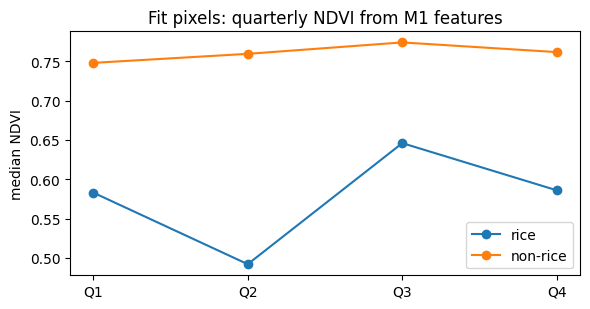

Development subset: 0.0% of pixels have no AlphaEarth embedding (AE_valid = 0); they are filled with fit means and flagged by the AE_valid column.


,B2_mean,B2_std,B2_min,B2_max,B2_p10,B2_p50,B2_p90,B3_mean
0,0.039,0.022,0.002,0.091,0.020,0.029,0.059,0.058
1,0.042,0.028,0.002,0.123,0.021,0.030,0.060,0.061
2,0.049,0.035,0.011,0.127,0.022,0.041,0.110,0.063


117

In [ ]:
# @title 1.2 Quarterly NDVI by class, and missing embeddings (fit rows only)
fit_x, fit_y = rt.load_split(LEDGER.root / 'tables', 's2m1', 'fit')
names = rt.FEATURE_SETS['s2m1']
quarters = range(1, rt.QUARTERS + 1)
ndvi = {q: (fit_x[:, names.index(f'q{q}_B8A_mean')] - fit_x[:, names.index(f'q{q}_B4_mean')])
           / (fit_x[:, names.index(f'q{q}_B8A_mean')] + fit_x[:, names.index(f'q{q}_B4_mean')] + 1e-6) for q in quarters}
fig, ax = plt.subplots(figsize=(6, 3.2))
for label, name in ((1, 'rice'), (0, 'non-rice')):
    ax.plot(list(quarters), [np.median(ndvi[q][fit_y == label]) for q in quarters], marker='o', label=name)
ax.set_xticks(list(quarters), [f'Q{q}' for q in quarters])
ax.set_ylabel('median NDVI'); ax.set_title('Fit pixels: quarterly NDVI from M1 features'); ax.legend()
plt.tight_layout(); plt.show()
ae_x, _ = rt.load_split(LEDGER.root / 'tables', 'alphaearth', 'dev')
print(f"Development subset: {np.isnan(ae_x[:, 0]).mean():.1%} of pixels have no AlphaEarth embedding (AE_valid = 0); "
      'they are filled with fit means and flagged by the AE_valid column.')
display(pd.DataFrame(fit_x[:3, :8], columns=names[:8]).round(3))
del fit_x, ae_x; gc.collect()

**What to notice:** the rice curve usually differs from non-rice in at least one quarter (a dip at flooding or a peak at full canopy); where the two median curves overlap, the classes have similar central values in that quarter. That alone does not mean the quarter carries no signal: the spread of values, and their combination with other quarters, can still differ. M1 values are readable reflectance statistics, AlphaEarth's are not: a model has to discover what each embedding axis means from the fit rows.

**Checkpoint.** Which feature set do you expect to separate rice better, and why might the answer differ between a gradient-boosted tree model and an in-context model?

<details><summary>Check your reasoning</summary>AlphaEarth summarises many observations and sensors (radar as well as optical) with a model trained on far more imagery, so it may separate classes better with any classifier. M1 is limited to six bands and four quarters but is grounded in physics. A tree model splits on individual columns; an in-context model compares whole rows with its support rows, so it may use correlated embedding axes differently. Section 4 tests this.</details>

# 2. Predict, then run the baselines [Evaluation practice]

**The question.** On the same pixels, which matters more for rice F1: switching from M1 to AlphaEarth, or switching from LightGBM to a tabular foundation model? **Write down your prediction now**, as two rough numbers: the F1 gain from changing the feature set, and the F1 difference between a foundation model and LightGBM given the same 10,000 fit rows (B10k) on one feature set.

**The protocol** (fixed before any model runs):

1. Roles come from whole regions; every fit sample and fill uses fit chips only.
2. Every choice is made on the development subset: each condition's **threshold** (0.10 to 0.90 in steps of 0.05, highest pooled development rice F1, ties nearest 0.5) and LightGBM's number of trees (early stopping on development F1).
3. Every choice and every condition's identity is written to `selection.json` and hashed (the **freeze**). Only then is validation scored, once, and the result is kept whichever system wins.
4. Every system runs a **fixed recipe**: the foundation-model settings in Section 3 are fixed and not tuned, and only LightGBM's number of trees and each condition's threshold are chosen on development. Mitra (opt-in) also receives a separate tuning set from the development subset (Section 3). Differences between systems are measured under these recipes, not after equal tuning of every model.

**Baselines.** A calls every pixel non-rice: its accuracy equals the non-rice share, and its recall and F1 are 0. B is LightGBM [6] with the capstone's settings (31 leaves, learning rate 0.05, at most 200 trees, patience 50) on 65,536 fit rows. B10k is the same model on the 10,000 rows the foundation models get, so it compares LightGBM with them on the same fit rows (Mitra additionally receives tuning rows; see Section 3). The two LightGBM tables are drawn separately, so B versus B10k differs in which rows as well as how many: read it as a rough sense of how much more data helps, not as a pure sample-size effect.

In [ ]:
# @title 2.1 Baselines A, B and B10k on both feature sets (development only)
BASELINE = rt.baseline_stage(LEDGER)
display(pd.DataFrame([{'condition': k, 'fit rows': v.get('fit_rows', '-'), 'trees': v.get('best_iteration', '-'),
                       'dev F1 at 0.5': v['dev_f1_at_0p5'], 'chosen threshold': v['threshold'],
                       'dev F1 at chosen': v['dev_f1_selected'], 'seconds': v['seconds']}
                      for k, v in BASELINE.items()]).round(4))

,condition,fit rows,trees,dev F1 at 0.5,chosen threshold,dev F1 at chosen,seconds
0,A/alphaearth,-,-,0.0000,0.50,0.0000,0.01
1,B/alphaearth,65536,200,0.8940,0.35,0.8948,4.92
2,B10k/alphaearth,10000,199,0.8749,0.75,0.8859,1.92
3,A/s2m1,-,-,0.0000,0.50,0.0000,0.01
4,B/s2m1,65536,195,0.8082,0.40,0.8083,5.59
5,B10k/s2m1,10000,195,0.8148,0.55,0.8164,2.26


**What to notice:** A's F1 is 0 on both feature sets. B on AlphaEarth is usually well above B on M1; the chosen threshold is often near 0.5 but need not be. Compare B10k with B: fewer rows can give the trees less to learn from, but the rows also differ, so B10k may trail, match or beat B (in the [recorded Colab runs of revision 373aaf5](https://github.com/kurtvalcorza/mitra-classifier-pipeline/tree/main/docs/execution-evidence/2026-10-12/rice_pixel_tables_workshop), B10k scored 0.8164 and B 0.8083 on M1 development: recorded evidence, not this run). These are development numbers, used for choosing, not for claiming.

# 3. Tabular foundation models [Concept]

A **tabular foundation model** is a neural network pretrained on millions of synthetic or real tables to predict a row's label from other labelled rows. Given a new table, it does not train: `fit` stores the 10,000 labelled fit rows as **context**, and `predict` passes each new row through the network together with that context. This is **in-context learning**. The trade-offs: there is no training loop to tune, but every prediction pays for attending to the context, the context has a size limit, and the model's pretraining decides what patterns it can recognise.

| ID | System | Checkpoint (pinned revision) | Licence | Settings here |
|---|---|---|---|---|
| C1 | TabPFN-3 [1], [2] | `Prior-Labs/tabpfn_3` @ `24a16a89d245` | TabPFN-3 licence v1.0, **non-commercial** | 4 estimators |
| C2 | TabICLv2 [3] | `jingang/TabICL` @ `4dcd344ece2c` | BSD-3-Clause | 8 estimators |
| C3 | Mitra [5] (opt-in, off) | `autogluon/mitra-classifier` @ `c425e9fa0910` | Apache-2.0 | AutoGluon 1.5.0, in-context |
| C4 | TabDPT v1.2 [4] | `Layer6/TabDPT` @ `4462ffbd1d8d` | Apache-2.0 | 4 ensembles, 4,096-row retrieved context |

Every model gets the same 10,000 fit rows as its context (Mitra also gets a tuning set; see below). TabDPT retrieves the 4,096 most similar of them for each prediction. Each model runs in its own process of its own environment, one at a time, so GPU memory is released between models.

**Mitra is off by default.** On a T4 it predicts about 50 rows per second, so one full validation pass would take about 36 minutes, and AutoGluon's memory pre-check refuses it unless its limit is raised. If you switch it on, it runs in its own process per feature set with `max_memory_usage_ratio = 8`, uses `predict_proba` with the development-chosen threshold (never AutoGluon's own tuned threshold), and scores a **declared, seeded sample** of development and validation pixels, stated beside its results. Expect about 20 extra minutes. AutoGluon also requires a **tuning set**: Mitra receives up to 2,000 further pixels of the development subset (a fifth of the labelled development pixels for small BYOD sets), drawn apart from its declared development sample, which is the one used to choose its threshold. Mitra runs with fine-tuning off, so no training epoch uses these rows; AutoGluon scores them and tunes its own `predict()` threshold on them, which this notebook never uses. Whether they affect Mitra's probabilities in any other way has not been checked here, so Mitra's comparison is not on strictly identical labelled data.

In [ ]:
# @title 3.1 Choose the foundation-model conditions
RUN_TABPFN3 = True  # @param {type:"boolean"}
RUN_TABICLV2 = True  # @param {type:"boolean"}
RUN_TABDPT = True  # @param {type:"boolean"}
RUN_MITRA = False  # @param {type:"boolean"}
MITRA_DEV_PIXELS = 10000  # @param {type:"integer"}
MITRA_VALIDATION_PIXELS = 10000  # @param {type:"integer"}
REQUIRE_ALL_SELECTED_MODELS = True
SELECTED_SYSTEMS = [s for s, on in (('C1', RUN_TABPFN3), ('C2', RUN_TABICLV2), ('C4', RUN_TABDPT), ('C3', RUN_MITRA)) if on]
if RUN_MITRA and not (1000 <= MITRA_DEV_PIXELS <= rt.DEV_SUBSET_ROWS and 1000 <= MITRA_VALIDATION_PIXELS):
    raise ValueError(f'MITRA_DEV_PIXELS must be 1,000-{rt.DEV_SUBSET_ROWS:,} and MITRA_VALIDATION_PIXELS at least 1,000')
tables = PREPARED['tables']['feature_sets']
display(pd.DataFrame([{
    'system': rt.FOUNDATION_SYSTEMS[s]['name'], 'context rows': rt.FM_FIT_ROWS,
    'features': ' / '.join(f"{fs} {tables[fs]['features']}" for fs in tables),
    'development pixels': MITRA_DEV_PIXELS if s == 'C3' else tables['s2m1']['dev']['rows'],
    'validation pixels': f'{MITRA_VALIDATION_PIXELS} (declared sample)' if s == 'C3' else 'all labelled',
    'prediction chunk rows': rt.FOUNDATION_SYSTEMS[s]['chunk_rows'], 'settings': rt.FOUNDATION_SYSTEMS[s]['settings'],
} for s in SELECTED_SYSTEMS]))

,system,context rows,features,development pixels,validation pixels,prediction chunk rows,settings
0,TabPFN-3,10000,alphaearth 65 / s2m1 70,30000,all labelled,8192,{'n_estimators': 4}
1,TabICLv2,10000,alphaearth 65 / s2m1 70,30000,all labelled,8192,{'n_estimators': 8}
2,TabDPT v1.2,10000,alphaearth 65 / s2m1 70,30000,all labelled,8192,"{'n_ensembles': 4, 'context_size': 4096, 'batc..."


## 3.2 Isolated model environments

**Infrastructure — run the cell; reading its implementation is optional.** This cell is carried byte for byte from the FreshRetailNet v2 notebook in this repository (only its title line is renumbered): the model adapters at their pinned commits, the checkpoint manifests (revision and SHA-256 of every file), and one hash lock per model stack. A pinned `uv` (checked by size and SHA-256) creates one CPython 3.12.12 environment per selected model and installs only the locked wheels (`--require-hashes --only-binary :all: --no-deps`), then checks them with `uv pip check`. Environments are reused when their identity matches. Checkpoints are downloaded at their pinned revisions and verified against the manifest before use.

In [ ]:
# @title 3.2 Stage carried adapters and prepare isolated model environments
CARRIED_ADAPTER_SOURCES = {
    'mitra_pipeline/tutorial_api.py': (
    '"""Release-grade public API for the Mitra Classifier notebook surface.\n'
    '\n'
    'This module owns the repository-facing behavior the notebooks must exercise directly:\n'
    'classification data validation, Mitra fit/predict calls, model snapshot locking, and predictor\n'
    'artifact validation. Imports that pull in heavy ML dependencies are intentionally delayed so\n'
    'archive and manifest checks remain unit-testable in a lightweight CI environment.\n'
    '"""\n'
    '\n'
    '# ruff: noqa: E501  -- long messages and docstrings are kept on one line\n'
    'from __future__ import annotations\n'
    '\n'
    'import csv\n'
    'import hashlib\n'
    'import io\n'
    'import json\n'
    'import os\n'
    'import random\n'
    'import shutil\n'
    'import stat\n'
    'import tempfile\n'
    'import urllib.request\n'
    'import zipfile\n'
    'from collections.abc import Callable, Iterable, Mapping, Sequence\n'
    'from pathlib import Path, PurePosixPath\n'
    'from typing import Any\n'
    '\n'
    'import numpy as np\n'
    'import pandas as pd\n'
    '\n'
    '# Fleet snapshot identity (DIMER Notebook Specification 1.1, ST3/MOD13). The pinned upstream model is unchanged;\n'
    '# these are the fleet-standard names for the same repository, revision, license and snapshot key. The published\n'
    '# PINNED_REVISION spelling stays as an alias of MODEL_REVISION.\n'
    'MODEL_ID = "autogluon/mitra-classifier"\n'
    'MODEL_REVISION = "c425e9fa0910a6be1c494321792e7ba2a1367b1a"\n'
    'MODEL_LICENSE = "apache-2.0"\n'
    'MODEL_KEY = "mitra-classifier"\n'
    'MANIFEST_NAME = "dimer-base-manifest.json"\n'
    '# Root-level package: the repository root is one level up from this file.\n'
    'DEFAULT_WEIGHTS_DIR = Path(__file__).resolve().parents[1] / "weights" / MODEL_KEY\n'
    'WEIGHTS_FILE = "model.safetensors"\n'
    'CONFIG_FILE = "config.json"\n'
    '\n'
    'PINNED_REVISION = MODEL_REVISION\n'
    'WEIGHTS_SHA256 = "e06a055e91a3baeffc37f9cf634d9e69a27d904b6686131dc3b702f9c0126b19"\n'
    'CONFIG_SHA256 = "2c96c24dd25f64e92753f6f2ba00cc7833b9923459403dcd8504e8700c0995df"\n'
    '# The ids `classification_metrics` reports (sklearn, computed from labels + class probabilities) and the ids\n'
    "# `normalize_autogluon_classification_metrics` may carry through from AutoGluon's own evaluate().\n"
    'METRIC_IDS = ("accuracy", "balanced_accuracy", "log_loss", "roc_auc", "f1_macro", "mcc", "f1", "precision", "recall")\n'
    'DECISION_RULE = "argmax"  # `predict` is the argmax over `predict_proba`; no threshold is shipped\n'
    'MIN_CLASSES = 2\n'
    "MAX_CLASSES = 10  # Mitra's class ceiling (dim_output)\n"
    'MIN_CLASS_COUNT = 2  # rows per class in the support split (stratified holdout needs 2)\n'
    '\n'
    'MAX_TRAIN_ROWS = 10_000\n'
    'MAX_FEATURES = 500\n'
    'MIN_TRAIN_ROWS = 50\n'
    '\n'
    'ARTIFACT_FORMAT = "dimer-autogluon-predictor"\n'
    'ARTIFACT_FORMAT_VERSION = 1\n'
    'ARTIFACT_MANIFEST = "artifact_manifest.json"\n'
    'RUN_METADATA = "tutorial_run_metadata.json"\n'
    'DIMER_MODEL_MANIFEST = "dimer-model-manifest.json"\n'
    '\n'
    'MAX_ARCHIVE_MEMBER_BYTES = 1 * 1024**3\n'
    'MAX_ARCHIVE_EXPANDED_BYTES = 4 * 1024**3\n'
    'MAX_COMPRESSION_RATIO = 200.0\n'
    '\n'
    'CLASSIFICATION_LOWER_IS_BETTER = {"log_loss"}\n'
    '# AutoGluon eval_metric names the tutorial accepts; the Mitra model hyper-parameter `metric` knows two of them.\n'
    'EVAL_METRICS = ("accuracy", "balanced_accuracy", "log_loss", "f1_macro", "mcc")\n'
    'MITRA_METRIC_MAP = {"accuracy": "accuracy", "log_loss": "log_loss"}\n'
    '\n'
    'REQUIRED_RUN_METADATA_FIELDS = {\n'
    '    "artifact_format",\n'
    '    "artifact_format_version",\n'
    '    "base_model",\n'
    '    "base_model_revision",\n'
    '    "weights_sha256",\n'
    '    "config_sha256",\n'
    '    "autogluon_version",\n'
    '    "python_version",\n'
    '    "problem_type",\n'
    '    "target_column",\n'
    '    "features",\n'
    '    "mode",\n'
    '    "selection_basis",\n'
    '}\n'
    '\n'
    '\n'
    'def sha256_file(path: str | Path) -> str:\n'
    '    h = hashlib.sha256()\n'
    '    with open(path, "rb") as handle:\n'
    '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
    '            h.update(chunk)\n'
    '    return h.hexdigest()\n'
    '\n'
    '\n'
    'def _assert_hex_digest(value: str, label: str) -> str:\n'
    '    digest = str(value).strip().lower()\n'
    '    if len(digest) != 64 or any(ch not in "0123456789abcdef" for ch in digest):\n'
    '        raise ValueError(f"{label} must be a 64-character hexadecimal SHA-256 digest.")\n'
    '    return digest\n'
    '\n'
    '\n'
    'def read_csv_bytes(payload: bytes, label: str) -> pd.DataFrame:\n'
    '    """Parse UTF-8/BOM CSV bytes while rejecting duplicate raw headers before pandas renames them."""\n'
    '    try:\n'
    '        text = payload.decode("utf-8-sig")\n'
    '    except UnicodeDecodeError as exc:\n'
    '        raise ValueError(f"{label}: expected UTF-8 CSV input.") from exc\n'
    '\n'
    '    rows = csv.reader(io.StringIO(text, newline=""))\n'
    '    header = next((row for row in rows if row and not (len(row) == 1 and not row[0].strip())), [])\n'
    '    if not header:\n'
    '        raise ValueError(f"{label}: CSV has no header row.")\n'
    '\n'
    '    seen: set[str] = set()\n'
    '    duplicates: list[str] = []\n'
    '    for name in header:\n'
    '        if name in seen and name not in duplicates:\n'
    '            duplicates.append(name)\n'
    '        seen.add(name)\n'
    '    if duplicates:\n'
    '        raise ValueError(f"{label}: duplicate column names are not supported: {duplicates}")\n'
    '\n'
    '    return pd.read_csv(io.BytesIO(payload))\n'
    '\n'
    '\n'
    'def validate_labeled_frame(\n'
    '    frame: pd.DataFrame,\n'
    '    target_column: str,\n'
    '    *,\n'
    '    name: str,\n'
    '    drop_columns: Iterable[str] = (),\n'
    '    min_rows: int = 2,\n'
    '    min_classes: int = 1,\n'
    '    max_classes: int = MAX_CLASSES,\n'
    '    min_class_count: int = 1,\n'
    ') -> tuple[pd.DataFrame, list[str], dict[str, Any]]:\n'
    '    """Validate one labelled classification table using the repository\'s user-facing contract.\n'
    '\n'
    '    The target keeps its own dtype (any label type); rows with a missing target are dropped and counted; the\n'
    "    class count must lie in ``min_classes..max_classes`` (Mitra's ceiling is ``MAX_CLASSES``) and every class\n"
    '    needs at least ``min_class_count`` rows (2 for a support split that will be stratified)."""\n'
    '    if frame.columns.duplicated().any():\n'
    '        duplicates = list(frame.columns[frame.columns.duplicated()])\n'
    '        raise ValueError(f"{name}: duplicate column names are not supported: {duplicates}")\n'
    '    if target_column not in frame.columns:\n'
    '        raise ValueError(f"{name}: target {target_column!r} not found.")\n'
    '\n'
    '    drops = [c for c in drop_columns if c != target_column and c in frame.columns]\n'
    '    out = frame.drop(columns=drops, errors="ignore").copy()\n'
    '    rows_before = len(out)\n'
    '    out = out.dropna(subset=[target_column]).copy()\n'
    '    dropped_target_rows = rows_before - len(out)\n'
    '\n'
    '    features = [c for c in out.columns if c != target_column]\n'
    '    counts = out[target_column].value_counts()\n'
    '    errors: list[str] = []\n'
    '    if len(out) < min_rows:\n'
    '        errors.append(f"use at least {min_rows} labelled rows after missing-target drops")\n'
    '    if not features:\n'
    '        errors.append("no feature columns remain")\n'
    '    if len(features) > MAX_FEATURES:\n'
    '        errors.append(f"{len(features)} features exceed the {MAX_FEATURES}-feature Mitra ceiling")\n'
    '    if not min_classes <= len(counts) <= max_classes:\n'
    '        errors.append(f"target has {len(counts)} classes; Mitra requires {min_classes}-{max_classes}")\n'
    '    if counts.empty or int(counts.min()) < min_class_count:\n'
    '        errors.append(f"every class needs at least {min_class_count} row(s)")\n'
    '    if errors:\n'
    '        raise ValueError(f"{name} is not ready: " + "; ".join(errors))\n'
    '\n'
    '    report = {\n'
    '        "rows_before_target_drop": int(rows_before),\n'
    '        "rows_after_target_drop": int(len(out)),\n'
    '        "dropped_missing_target_rows": int(dropped_target_rows),\n'
    '        "exact_duplicate_rows": int(out.duplicated().sum()),\n'
    '        "feature_count": int(len(features)),\n'
    '        "class_count": int(len(counts)),\n'
    '        "class_counts": {str(label): int(n) for label, n in counts.sort_index().items()},\n'
    '    }\n'
    '    return out, features, report\n'
    '\n'
    '\n'
    'def require_class_coverage(\n'
    '    train_frame: pd.DataFrame, eval_frame: pd.DataFrame, target_column: str, eval_name: str\n'
    ') -> None:\n'
    '    """An in-context classifier can only predict classes present in its support rows, and a holdout that\n'
    '    misses a trained class cannot score it: both directions are refused."""\n'
    '    train_classes = set(train_frame[target_column].dropna().unique())\n'
    '    eval_classes = set(eval_frame[target_column].dropna().unique())\n'
    '    missing = sorted(train_classes - eval_classes, key=str)\n'
    '    unseen = sorted(eval_classes - train_classes, key=str)\n'
    '    problems: list[str] = []\n'
    '    if missing:\n'
    '        problems.append(f"missing trained target classes: {missing}")\n'
    '    if unseen:\n'
    '        problems.append(f"contains unseen target classes not present in training: {unseen}")\n'
    '    if problems:\n'
    '        raise ValueError(\n'
    '            f"{eval_name} " + "; ".join(problems) + ". Adjust the split or provide a compatible evaluation partition."\n'
    '        )\n'
    '\n'
    '\n'
    'def stratified_holdout(\n'
    '    frame: pd.DataFrame, target_column: str, validation_split: float, seed: int\n'
    ') -> tuple[pd.DataFrame, pd.DataFrame]:\n'
    '    """Seeded stratified holdout that keeps every class in both partitions."""\n'
    '    from sklearn.model_selection import train_test_split\n'
    '\n'
    '    if not 0 < validation_split < 1:\n'
    '        raise ValueError("validation_split must be between 0 and 1")\n'
    '    counts = frame[target_column].value_counts()\n'
    '    n_classes = int(counts.size)\n'
    '    if (counts < 2).any():\n'
    '        raise ValueError(f"class(es) with fewer than 2 rows cannot be split: {counts[counts < 2].to_dict()}")\n'
    '    n = len(frame)\n'
    '    n_val = int(round(n * validation_split))\n'
    '    n_val = min(max(n_val, n_classes), n - n_classes)\n'
    '    if n_val < n_classes or n - n_val < n_classes:\n'
    '        raise ValueError(\n'
    '            f"cannot build a stratified holdout: {n} usable rows, {n_classes} classes, "\n'
    '            f"validation_split={validation_split}. Provide more rows, fewer classes, or a larger split."\n'
    '        )\n'
    '    train, holdout = train_test_split(frame, test_size=n_val, random_state=seed, stratify=frame[target_column])\n'
    '    if set(train[target_column].unique()) != set(frame[target_column].unique()):\n'
    '        raise RuntimeError("stratified split left a class out of train; refusing to train.")\n'
    '    return train, holdout\n'
    '\n'
    '\n'
    'def cap_training_rows(\n'
    '    frame: pd.DataFrame,\n'
    '    target_column: str,\n'
    '    *,\n'
    '    seed: int,\n'
    '    max_rows: int = MAX_TRAIN_ROWS,\n'
    ') -> tuple[pd.DataFrame, dict[str, Any]]:\n'
    '    """Seeded, class-preserving cap: one row of every class is kept first, the rest is sampled."""\n'
    '    if max_rows > MAX_TRAIN_ROWS:\n'
    '        raise ValueError(f"max_rows cannot exceed Mitra\'s {MAX_TRAIN_ROWS:,}-row ceiling.")\n'
    '    before = len(frame)\n'
    '    if before <= max_rows:\n'
    '        return frame.copy(), {"applied": False, "before": before, "after": before}\n'
    '    classes_before = set(frame[target_column].unique())\n'
    '    if max_rows < len(classes_before):\n'
    '        raise ValueError(f"row ceiling ({max_rows}) is below the class count ({len(classes_before)}); cannot keep every class.")\n'
    '    rng = np.random.RandomState(seed)\n'
    '    keep: list[Any] = []\n'
    '    for cls in sorted(classes_before, key=str):\n'
    '        idx = frame.index[frame[target_column] == cls].to_numpy()\n'
    '        keep.append(rng.choice(idx, size=1)[0])\n'
    '    keep_set = set(keep)\n'
    '    remaining = np.array([i for i in frame.index.to_numpy() if i not in keep_set])\n'
    '    need = max_rows - len(keep)\n'
    '    if need > 0 and len(remaining) > 0:\n'
    '        keep.extend(rng.choice(remaining, size=min(need, len(remaining)), replace=False).tolist())\n'
    '    capped = frame.loc[keep].copy()\n'
    '    if set(capped[target_column].unique()) != classes_before:\n'
    '        raise RuntimeError("class-preserving cap dropped a class; refusing to train.")\n'
    '    if capped[target_column].value_counts().min() < MIN_CLASS_COUNT:\n'
    '        raise ValueError("Capped training split leaves fewer than 2 rows for a class; provide a representative pre-split set.")\n'
    '    return capped, {"applied": True, "before": before, "after": len(capped)}\n'
    '\n'
    '\n'
    'def split_overlap_report(named_frames: dict[str, pd.DataFrame]) -> dict[str, int]:\n'
    '    """Detect exact record overlap across labelled partitions without mutating them."""\n'
    '    names = list(named_frames)\n'
    '    hashes = {\n'
    '        name: set(pd.util.hash_pandas_object(frame, index=False).astype("uint64").tolist())\n'
    '        for name, frame in named_frames.items()\n'
    '    }\n'
    '    report: dict[str, int] = {}\n'
    '    for i, left in enumerate(names):\n'
    '        for right in names[i + 1 :]:\n'
    '            report[f"{left}_vs_{right}"] = len(hashes[left].intersection(hashes[right]))\n'
    '    return report\n'
    '\n'
    '\n'
    'def seed_everything(seed: int) -> None:\n'
    '    random.seed(seed)\n'
    '    np.random.seed(seed)\n'
    '    try:\n'
    '        import torch\n'
    '\n'
    '        torch.manual_seed(seed)\n'
    '        if torch.cuda.is_available():\n'
    '            torch.cuda.manual_seed_all(seed)\n'
    '    except Exception:\n'
    '        pass\n'
    '\n'
    '\n'
    'def fit_mitra_predictor(\n'
    '    train_data: pd.DataFrame,\n'
    '    *,\n'
    '    target_column: str,\n'
    '    eval_metric: str,\n'
    '    path: str | Path,\n'
    '    fine_tune: bool,\n'
    '    time_limit: int,\n'
    '    seed: int,\n'
    '    problem_type: str | None = None,\n'
    '    fine_tune_steps: int | None = None,\n'
    '    max_memory_usage_ratio: float = 1.10,\n'
    '):\n'
    '    """Fit/register Mitra through the repository\'s supported notebook API.\n'
    '\n'
    "    With ``fine_tune=False`` AutoGluon's ``fit`` registers support/context rows and model\n"
    '    configuration; Mitra weights are not gradient-updated. With ``fine_tune=True`` the Mitra\n'
    '    weights are adapted for the requested number of steps, subject to the time limit.\n'
    '    ``problem_type`` defaults to ``binary`` for two classes and ``multiclass`` otherwise.\n'
    '    """\n'
    '    if eval_metric not in EVAL_METRICS:\n'
    '        raise ValueError(f"Unsupported eval_metric {eval_metric!r}; choose {list(EVAL_METRICS)}")\n'
    '    if fine_tune and (fine_tune_steps is None or fine_tune_steps <= 0):\n'
    '        raise ValueError("fine_tune_steps must be a positive integer when fine_tune=True.")\n'
    '    n_classes = int(train_data[target_column].nunique())\n'
    '    if problem_type is None:\n'
    '        problem_type = "binary" if n_classes == 2 else "multiclass"\n'
    '    if problem_type not in ("binary", "multiclass"):\n'
    '        raise ValueError("problem_type must be \'binary\' or \'multiclass\'")\n'
    '\n'
    '    seed_everything(seed)\n'
    '    hp: dict[str, Any] = {"fine_tune": bool(fine_tune), "seed": int(seed)}\n'
    '    if eval_metric in MITRA_METRIC_MAP:\n'
    '        hp["metric"] = MITRA_METRIC_MAP[eval_metric]\n'
    '    if fine_tune:\n'
    '        hp["fine_tune_steps"] = int(fine_tune_steps)\n'
    '\n'
    '    from autogluon.tabular import TabularPredictor\n'
    '\n'
    '    predictor = TabularPredictor(\n'
    '        label=target_column,\n'
    '        problem_type=problem_type,\n'
    '        eval_metric=eval_metric,\n'
    '        path=str(path),\n'
    '        verbosity=2,\n'
    '    )\n'
    '    predictor.fit(\n'
    '        train_data,\n'
    '        hyperparameters={"MITRA": hp},\n'
    '        fit_weighted_ensemble=False,\n'
    '        time_limit=int(time_limit),\n'
    '        ag_args_fit={"max_memory_usage_ratio": float(max_memory_usage_ratio)},\n'
    '    )\n'
    '    trained = list(predictor.model_names())\n'
    '    if not trained or not any("mitra" in model.lower() for model in trained):\n'
    '        raise RuntimeError(f"Expected Mitra to fit/register; AutoGluon returned models={trained}.")\n'
    '    return predictor\n'
    '\n'
    '\n'
    'def normalize_autogluon_classification_metrics(raw: dict[str, Any]) -> dict[str, float]:\n'
    '    """AutoGluon reports lower-is-better metrics negated (log_loss); restore positive values."""\n'
    '    return {\n'
    '        str(key): float(-value if key in CLASSIFICATION_LOWER_IS_BETTER else value)\n'
    '        for key, value in raw.items()\n'
    '    }\n'
    '\n'
    '\n'
    'def classification_metrics(\n'
    '    y_true: Iterable[Any], y_pred: Iterable[Any], y_proba: Any, classes: Sequence[Any]\n'
    ') -> dict[str, float]:\n'
    '    """The repository\'s metric set: accuracy, balanced_accuracy, f1_macro, mcc (discrete correctness under\n'
    '    the argmax rule), log_loss (probability quality; lower is better) and roc_auc (ranking; binary or one-vs-rest;\n'
    '    NaN when undefined). ``y_proba`` has one column per entry of ``classes`` in that order."""\n'
    '    from sklearn.metrics import (\n'
    '        accuracy_score,\n'
    '        balanced_accuracy_score,\n'
    '        f1_score,\n'
    '        log_loss,\n'
    '        matthews_corrcoef,\n'
    '        roc_auc_score,\n'
    '    )\n'
    '\n'
    '    truth = np.asarray(list(y_true))\n'
    '    pred = np.asarray(list(y_pred))\n'
    '    proba = np.asarray(y_proba, dtype=float)\n'
    '    labels = list(classes)\n'
    '    if truth.shape != pred.shape or truth.size == 0:\n'
    '        raise ValueError(f"y_true shape {truth.shape} != y_pred shape {pred.shape} (or empty)")\n'
    '    if proba.ndim != 2 or proba.shape != (truth.size, len(labels)):\n'
    '        raise ValueError("y_proba must have one row per example and one column per class")\n'
    '    out = {\n'
    '        "accuracy": float(accuracy_score(truth, pred)),\n'
    '        "balanced_accuracy": float(balanced_accuracy_score(truth, pred)),\n'
    '        "log_loss": float(log_loss(truth, proba, labels=labels)),\n'
    '        "f1_macro": float(f1_score(truth, pred, average="macro")),\n'
    '        "mcc": float(matthews_corrcoef(truth, pred)),\n'
    '    }\n'
    '    try:\n'
    '        if len(labels) == 2:\n'
    '            out["roc_auc"] = float(roc_auc_score(truth, proba[:, 1]))\n'
    '        else:\n'
    '            out["roc_auc"] = float(roc_auc_score(truth, proba, multi_class="ovr", labels=labels))\n'
    '    except ValueError:\n'
    '        out["roc_auc"] = float("nan")\n'
    '    return out\n'
    '\n'
    '\n'
    'def validate_inference_frame(\n'
    '    frame: pd.DataFrame,\n'
    '    required_features: Iterable[str],\n'
    '    *,\n'
    '    output_column: str = "prediction",\n'
    ') -> tuple[pd.DataFrame, list[str]]:\n'
    '    if frame.columns.duplicated().any():\n'
    '        duplicates = list(frame.columns[frame.columns.duplicated()])\n'
    '        raise ValueError(f"Inference CSV contains duplicate column names: {duplicates}")\n'
    '    required = list(required_features)\n'
    '    missing = [column for column in required if column not in frame.columns]\n'
    '    if missing:\n'
    '        raise ValueError(f"Inference CSV is missing required feature columns: {missing}")\n'
    '    reserved = [c for c in frame.columns if c == output_column or str(c).startswith("probability_")]\n'
    '    if reserved:\n'
    '        raise ValueError(f"Inference CSV already contains output column(s) reserved by this notebook: {reserved}; rename or remove them first.")\n'
    '    extra = [column for column in frame.columns if column not in required]\n'
    '    return frame.reindex(columns=required).copy(), extra\n'
    '\n'
    '\n'
    'def predict_classification(predictor, frame: pd.DataFrame, required_features: Iterable[str]) -> np.ndarray:\n'
    '    """Class labels (the argmax of the class probabilities), one per row."""\n'
    '    features = list(required_features)\n'
    '    missing = [column for column in features if column not in frame.columns]\n'
    '    if missing:\n'
    '        raise ValueError(f"Prediction frame is missing required features: {missing}")\n'
    '    return np.asarray(predictor.predict(frame.reindex(columns=features)))\n'
    '\n'
    '\n'
    'def predict_proba_classification(\n'
    '    predictor, frame: pd.DataFrame, required_features: Iterable[str], classes: Sequence[Any] | None = None\n'
    ') -> pd.DataFrame:\n'
    '    """Class probabilities as a DataFrame with one column per class, in ``classes`` order (default: the\n'
    '    predictor\'s ``class_labels``); values are finite and rows sum to ~1."""\n'
    '    features = list(required_features)\n'
    '    missing = [column for column in features if column not in frame.columns]\n'
    '    if missing:\n'
    '        raise ValueError(f"Prediction frame is missing required features: {missing}")\n'
    '    proba = predictor.predict_proba(frame.reindex(columns=features), as_multiclass=True)\n'
    '    order = list(classes) if classes is not None else list(predictor.class_labels)\n'
    '    absent = [label for label in order if label not in proba.columns]\n'
    '    if absent:\n'
    '        raise RuntimeError(f"predictor never saw classes: {absent}")\n'
    '    proba = proba[order]\n'
    '    values = proba.to_numpy(dtype=float)\n'
    '    if not np.isfinite(values).all():\n'
    '        raise RuntimeError("Mitra produced non-finite class probabilities")\n'
    '    return proba\n'
    '\n'
    '\n'
    'def align_probabilities(proba: Any, model_classes: Sequence[Any], classes: Sequence[Any]) -> np.ndarray:\n'
    '    """Reorder probability columns from ``model_classes`` order into ``classes`` order (strict: every class\n'
    '    must be a column, so blending two models can never permute labels silently)."""\n'
    '    proba = np.asarray(proba, dtype=float)\n'
    '    lookup = {label: index for index, label in enumerate(model_classes)}\n'
    '    missing = [label for label in classes if label not in lookup]\n'
    '    if missing:\n'
    '        raise RuntimeError(f"model never saw classes: {missing}")\n'
    '    return proba[:, [lookup[label] for label in classes]]\n'
    '\n'
    '\n'
    'def _download(url: str, destination: Path, *, timeout: int = 30) -> None:\n'
    '    with urllib.request.urlopen(url, timeout=timeout) as response, open(destination, "wb") as handle:\n'
    '        shutil.copyfileobj(response, handle)\n'
    '\n'
    '\n'
    'def stage_verified_hf_snapshot(\n'
    '    weights_path: str | Path,\n'
    '    config_path: str | Path,\n'
    '    *,\n'
    '    hf_home: str | Path,\n'
    ') -> Path:\n'
    '    """Verify exact Mitra bytes and stage them as the immutable pinned Hugging Face snapshot."""\n'
    '    weights = Path(weights_path)\n'
    '    config = Path(config_path)\n'
    '    if sha256_file(weights) != WEIGHTS_SHA256:\n'
    '        raise RuntimeError("model.safetensors checksum mismatch for the pinned Mitra Classifier release.")\n'
    '    if sha256_file(config) != CONFIG_SHA256:\n'
    '        raise RuntimeError("config.json checksum mismatch for the pinned Mitra Classifier release.")\n'
    '\n'
    '    home = Path(hf_home)\n'
    '    repo = home / "hub" / ("models--" + MODEL_ID.replace("/", "--"))\n'
    '    snapshot = repo / "snapshots" / PINNED_REVISION\n'
    '    refs = repo / "refs"\n'
    '    snapshot.mkdir(parents=True, exist_ok=True)\n'
    '    refs.mkdir(parents=True, exist_ok=True)\n'
    '    shutil.copy2(weights, snapshot / "model.safetensors")\n'
    '    shutil.copy2(config, snapshot / "config.json")\n'
    '    (refs / "main").write_text(PINNED_REVISION, encoding="utf-8")\n'
    '\n'
    '    import huggingface_hub.constants\n'
    '\n'
    '    real_cache = Path(huggingface_hub.constants.HF_HUB_CACHE)\n'
    '    try:\n'
    '        if real_cache.resolve() != (home / "hub").resolve():\n'
    '            real_repo = real_cache / ("models--" + MODEL_ID.replace("/", "--"))\n'
    '            real_snap = real_repo / "snapshots" / PINNED_REVISION\n'
    '            real_refs = real_repo / "refs"\n'
    '            real_snap.mkdir(parents=True, exist_ok=True)\n'
    '            real_refs.mkdir(parents=True, exist_ok=True)\n'
    '            shutil.copy2(weights, real_snap / "model.safetensors")\n'
    '            shutil.copy2(config, real_snap / "config.json")\n'
    '            (real_refs / "main").write_text(PINNED_REVISION, encoding="utf-8")\n'
    '    except Exception:\n'
    '        pass\n'
    '\n'
    '    os.environ["HF_HOME"] = str(home)\n'
    '    os.environ["HF_HUB_OFFLINE"] = "1"\n'
    '    os.environ["TRANSFORMERS_OFFLINE"] = "1"\n'
    '\n'
    '    from huggingface_hub import hf_hub_download\n'
    '\n'
    '    for filename, expected_digest in (\n'
    '        ("model.safetensors", WEIGHTS_SHA256),\n'
    '        ("config.json", CONFIG_SHA256),\n'
    '    ):\n'
    '        try:\n'
    '            resolved = Path(\n'
    '                hf_hub_download(\n'
    '                    repo_id=MODEL_ID,\n'
    '                    filename=filename,\n'
    '                    revision=PINNED_REVISION,\n'
    '                    cache_dir=str(home / "hub"),\n'
    '                    local_files_only=True,\n'
    '                )\n'
    '            ).resolve()\n'
    '        except Exception:\n'
    '            resolved = Path(\n'
    '                hf_hub_download(\n'
    '                    repo_id=MODEL_ID,\n'
    '                    filename=filename,\n'
    '                    revision=PINNED_REVISION,\n'
    '                    local_files_only=True,\n'
    '                )\n'
    '            ).resolve()\n'
    '        expected = (snapshot / filename).resolve()\n'
    '        if resolved != expected and not resolved.is_file():\n'
    '            raise RuntimeError(f"Offline resolver mismatch for {filename}: {resolved} != {expected}")\n'
    '        if sha256_file(resolved) != expected_digest:\n'
    '            raise RuntimeError(f"Resolved {filename} digest changed after staging.")\n'
    '    return snapshot\n'
    '\n'
    '\n'
    'def _validate_zip_members(zf: zipfile.ZipFile, destination: Path) -> list[zipfile.ZipInfo]:\n'
    '    destination = destination.resolve()\n'
    '    total = 0\n'
    '    files: list[zipfile.ZipInfo] = []\n'
    '    seen_paths: set[str] = set()\n'
    '    seen_parent_paths: set[str] = set()\n'
    '    for info in zf.infolist():\n'
    '        name = info.filename\n'
    '        if not name or info.is_dir():\n'
    '            continue\n'
    '        if "\\\\" in name:\n'
    '            raise RuntimeError(f"Backslash archive paths are not allowed: {name!r}")\n'
    '        member = PurePosixPath(name)\n'
    '        if member.is_absolute() or ".." in member.parts:\n'
    '            raise RuntimeError(f"Unsafe archive member path: {name!r}")\n'
    '        normalized_name = member.as_posix()\n'
    '        if normalized_name in seen_paths:\n'
    '            raise RuntimeError(f"Duplicate archive member path is not allowed: {name!r}")\n'
    '        parent_paths = {PurePosixPath(*member.parts[:i]).as_posix() for i in range(1, len(member.parts))}\n'
    '        if normalized_name in seen_parent_paths or parent_paths.intersection(seen_paths):\n'
    '            raise RuntimeError(f"Archive member path conflicts with a file/directory boundary: {name!r}")\n'
    '        seen_paths.add(normalized_name)\n'
    '        seen_parent_paths.update(parent_paths)\n'
    '        mode = (info.external_attr >> 16) & 0o170000\n'
    '        if mode == stat.S_IFLNK:\n'
    '            raise RuntimeError(f"Symlink entries are not allowed: {name!r}")\n'
    '        if info.file_size > MAX_ARCHIVE_MEMBER_BYTES:\n'
    '            raise RuntimeError(f"Archive member is too large: {name!r} ({info.file_size:,} bytes).")\n'
    '        if info.compress_size > 0 and info.file_size / info.compress_size > MAX_COMPRESSION_RATIO:\n'
    '            raise RuntimeError(f"Archive member has suspicious compression ratio: {name!r}.")\n'
    '        total += info.file_size\n'
    '        if total > MAX_ARCHIVE_EXPANDED_BYTES:\n'
    '            raise RuntimeError("Archive expanded size exceeds the configured safety ceiling.")\n'
    '        target = (destination / Path(*member.parts)).resolve()\n'
    '        if target != destination and destination not in target.parents:\n'
    '            raise RuntimeError(f"Archive member escapes extraction root: {name!r}")\n'
    '        files.append(info)\n'
    '    return files\n'
    '\n'
    '\n'
    'def safe_extract_archive(zip_path: str | Path, destination: str | Path) -> Path:\n'
    '    destination_path = Path(destination)\n'
    '    with zipfile.ZipFile(zip_path) as zf:\n'
    '        # Validate the complete archive before touching any prior extraction destination.\n'
    '        infos = _validate_zip_members(zf, destination_path)\n'
    '        if destination_path.is_symlink():\n'
    '            raise RuntimeError("Archive extraction destination must not be a symlink.")\n'
    '        destination_path.parent.mkdir(parents=True, exist_ok=True)\n'
    '        staging = Path(tempfile.mkdtemp(prefix=f".{destination_path.name}.extract-", dir=destination_path.parent))\n'
    '        try:\n'
    '            for info in infos:\n'
    '                member = PurePosixPath(info.filename)\n'
    '                target = staging.joinpath(*member.parts)\n'
    '                target.parent.mkdir(parents=True, exist_ok=True)\n'
    '                with zf.open(info) as source, open(target, "wb") as sink:\n'
    '                    shutil.copyfileobj(source, sink)\n'
    '            if destination_path.exists():\n'
    '                shutil.rmtree(destination_path)\n'
    '            staging.replace(destination_path)\n'
    '        except Exception:\n'
    '            shutil.rmtree(staging, ignore_errors=True)\n'
    '            raise\n'
    '    return destination_path\n'
    '\n'
    '\n'
    'def validate_dimer_model_package(\n'
    '    zip_path: str | Path,\n'
    '    destination: str | Path,\n'
    '    *,\n'
    '    expected_archive_sha256: str | None = None,\n'
    ') -> tuple[Path, Path, dict[str, Any]]:\n'
    '    """Validate the normative DIMER offline Mitra package before any model load."""\n'
    '    zip_path = Path(zip_path)\n'
    '    if expected_archive_sha256:\n'
    '        expected = _assert_hex_digest(expected_archive_sha256, "expected_archive_sha256")\n'
    '        actual = sha256_file(zip_path)\n'
    '        if actual != expected:\n'
    '            raise RuntimeError(f"DIMER model ZIP checksum mismatch: expected {expected}; got {actual}.")\n'
    '\n'
    '    root = safe_extract_archive(zip_path, destination)\n'
    '    manifest_path = root / DIMER_MODEL_MANIFEST\n'
    '    if not manifest_path.is_file():\n'
    '        raise RuntimeError(\n'
    '            f"DIMER model ZIP must contain root-level {DIMER_MODEL_MANIFEST}; legacy weight-only ZIPs do not satisfy Notebook Spec 1.0."\n'
    '        )\n'
    '    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))\n'
    '    if manifest.get("schema_version") != 1:\n'
    '        raise RuntimeError("Unsupported DIMER model manifest schema_version.")\n'
    '    if manifest.get("model_id") != MODEL_ID:\n'
    '        raise RuntimeError(f"DIMER package model_id must be {MODEL_ID!r}.")\n'
    '    if manifest.get("revision") != PINNED_REVISION:\n'
    '        raise RuntimeError(f"DIMER package revision must be {PINNED_REVISION!r}.")\n'
    '\n'
    '    declared = manifest.get("files")\n'
    '    if not isinstance(declared, list) or not declared:\n'
    '        raise RuntimeError("DIMER model manifest must contain a non-empty files list.")\n'
    '    entries: dict[str, dict[str, Any]] = {}\n'
    '    for entry in declared:\n'
    '        if not isinstance(entry, dict):\n'
    '            raise RuntimeError("DIMER model manifest file entries must be objects.")\n'
    '        path = str(entry.get("path", ""))\n'
    '        if not path or "\\\\" in path:\n'
    '            raise RuntimeError(f"Invalid DIMER manifest path: {path!r}")\n'
    '        member = PurePosixPath(path)\n'
    '        if member.is_absolute() or ".." in member.parts or path in entries:\n'
    '            raise RuntimeError(f"Unsafe or duplicate DIMER manifest path: {path!r}")\n'
    '        entries[path] = entry\n'
    '\n'
    '    for required in ("model.safetensors", "config.json"):\n'
    '        if required not in entries:\n'
    '            raise RuntimeError(f"DIMER model manifest is missing required file {required!r}.")\n'
    '\n'
    '    actual_files = {\n'
    '        path.relative_to(root).as_posix()\n'
    '        for path in root.rglob("*")\n'
    '        if path.is_file() and path != root / DIMER_MODEL_MANIFEST\n'
    '    }\n'
    '    if actual_files != set(entries):\n'
    '        missing = sorted(set(entries) - actual_files)\n'
    '        unexpected = sorted(actual_files - set(entries))\n'
    '        raise RuntimeError(f"DIMER model package file inventory mismatch; missing={missing}, unexpected={unexpected}")\n'
    '\n'
    '    for rel, entry in entries.items():\n'
    '        path = root / rel\n'
    '        expected_size = int(entry.get("size", -1))\n'
    '        expected_digest = _assert_hex_digest(str(entry.get("sha256", "")), f"sha256 for {rel}")\n'
    '        if path.stat().st_size != expected_size:\n'
    '            raise RuntimeError(f"DIMER model package size mismatch for {rel}.")\n'
    '        if sha256_file(path) != expected_digest:\n'
    '            raise RuntimeError(f"DIMER model package digest mismatch for {rel}.")\n'
    '\n'
    '    weights = root / "model.safetensors"\n'
    '    config = root / "config.json"\n'
    '    if sha256_file(weights) != WEIGHTS_SHA256 or sha256_file(config) != CONFIG_SHA256:\n'
    '        raise RuntimeError("DIMER package bytes do not match the pinned Mitra Classifier release.")\n'
    '    return weights, config, manifest\n'
    '\n'
    '\n'
    'def _artifact_inventory(root: Path) -> list[dict[str, Any]]:\n'
    '    inventory = []\n'
    '    for path in sorted(p for p in root.rglob("*") if p.is_file() and p != root / ARTIFACT_MANIFEST):\n'
    '        rel = path.relative_to(root).as_posix()\n'
    '        if "\\\\" in rel or PurePosixPath(rel).is_absolute() or ".." in PurePosixPath(rel).parts:\n'
    '            raise RuntimeError(f"Unsafe artifact path: {rel!r}")\n'
    '        inventory.append({"path": rel, "size": path.stat().st_size, "sha256": sha256_file(path)})\n'
    '    return inventory\n'
    '\n'
    '\n'
    'def write_artifact_manifest(root: str | Path) -> Path:\n'
    '    root = Path(root)\n'
    '    metadata_path = root / RUN_METADATA\n'
    '    if not metadata_path.is_file():\n'
    '        raise RuntimeError(f"Cannot manifest artifact without {RUN_METADATA}.")\n'
    '    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))\n'
    '    missing = sorted(REQUIRED_RUN_METADATA_FIELDS - set(metadata))\n'
    '    if missing:\n'
    '        raise RuntimeError(f"Run metadata missing required fields: {missing}")\n'
    '    if metadata.get("artifact_format") != ARTIFACT_FORMAT:\n'
    '        raise RuntimeError("Run metadata artifact_format mismatch.")\n'
    '    if metadata.get("artifact_format_version") != ARTIFACT_FORMAT_VERSION:\n'
    '        raise RuntimeError("Run metadata artifact_format_version mismatch.")\n'
    '\n'
    '    manifest = {\n'
    '        "schema_version": 1,\n'
    '        "artifact_format": ARTIFACT_FORMAT,\n'
    '        "artifact_format_version": ARTIFACT_FORMAT_VERSION,\n'
    '        "base_model": metadata["base_model"],\n'
    '        "base_model_revision": metadata["base_model_revision"],\n'
    '        "problem_type": metadata["problem_type"],\n'
    '        "metadata_file": RUN_METADATA,\n'
    '        "files": _artifact_inventory(root),\n'
    '    }\n'
    '    path = root / ARTIFACT_MANIFEST\n'
    '    path.write_text(json.dumps(manifest, indent=2, sort_keys=True), encoding="utf-8")\n'
    '    return path\n'
    '\n'
    '\n'
    'def validate_artifact_directory(\n'
    '    root: str | Path,\n'
    '    *,\n'
    '    expected_model_id: str = MODEL_ID,\n'
    '    expected_revision: str = PINNED_REVISION,\n'
    ') -> tuple[dict[str, Any], dict[str, Any]]:\n'
    '    """Verify format, provenance, inventory, sizes and digests before deserializing predictor state."""\n'
    '    root = Path(root)\n'
    '    manifest_path = root / ARTIFACT_MANIFEST\n'
    '    metadata_path = root / RUN_METADATA\n'
    '    if not manifest_path.is_file():\n'
    '        raise RuntimeError(f"Predictor artifact is missing required {ARTIFACT_MANIFEST}.")\n'
    '    if not metadata_path.is_file():\n'
    '        raise RuntimeError(f"Predictor artifact is missing required {RUN_METADATA}.")\n'
    '\n'
    '    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))\n'
    '    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))\n'
    '    if manifest.get("schema_version") != 1:\n'
    '        raise RuntimeError("Unsupported artifact manifest schema_version.")\n'
    '    if manifest.get("metadata_file") != RUN_METADATA:\n'
    '        raise RuntimeError(f"Artifact manifest metadata_file must be {RUN_METADATA!r}.")\n'
    '    if manifest.get("artifact_format") != ARTIFACT_FORMAT or metadata.get("artifact_format") != ARTIFACT_FORMAT:\n'
    '        raise RuntimeError("Predictor artifact_format is not the DIMER AutoGluon predictor format.")\n'
    '    if (\n'
    '        manifest.get("artifact_format_version") != ARTIFACT_FORMAT_VERSION\n'
    '        or metadata.get("artifact_format_version") != ARTIFACT_FORMAT_VERSION\n'
    '    ):\n'
    '        raise RuntimeError("Predictor artifact format version is incompatible with this notebook.")\n'
    '\n'
    '    missing = sorted(REQUIRED_RUN_METADATA_FIELDS - set(metadata))\n'
    '    if missing:\n'
    '        raise RuntimeError(f"Predictor provenance is missing required fields: {missing}")\n'
    '    if metadata.get("base_model") != expected_model_id or manifest.get("base_model") != expected_model_id:\n'
    '        raise RuntimeError(f"Predictor base model must be {expected_model_id!r}.")\n'
    '    if metadata.get("base_model_revision") != expected_revision or manifest.get("base_model_revision") != expected_revision:\n'
    '        raise RuntimeError(f"Predictor base model revision must be {expected_revision!r}.")\n'
    '    if metadata.get("problem_type") not in ("binary", "multiclass") or manifest.get("problem_type") not in ("binary", "multiclass"):\n'
    '        raise RuntimeError("Predictor artifact is not a classification (binary/multiclass) artifact.")\n'
    '    if metadata.get("weights_sha256") != WEIGHTS_SHA256 or metadata.get("config_sha256") != CONFIG_SHA256:\n'
    '        raise RuntimeError("Predictor provenance does not identify the pinned Mitra Classifier bytes.")\n'
    '\n'
    '    declared = manifest.get("files")\n'
    '    if not isinstance(declared, list) or not declared:\n'
    '        raise RuntimeError("Artifact manifest contains no file inventory.")\n'
    '    entries: dict[str, dict[str, Any]] = {}\n'
    '    for entry in declared:\n'
    '        if not isinstance(entry, dict):\n'
    '            raise RuntimeError("Artifact manifest file entries must be objects.")\n'
    '        rel = str(entry.get("path", ""))\n'
    '        member = PurePosixPath(rel)\n'
    '        if not rel or "\\\\" in rel or member.is_absolute() or ".." in member.parts or rel in entries:\n'
    '            raise RuntimeError(f"Unsafe or duplicate artifact manifest path: {rel!r}")\n'
    '        entries[rel] = entry\n'
    '\n'
    '    actual = {\n'
    '        path.relative_to(root).as_posix()\n'
    '        for path in root.rglob("*")\n'
    '        if path.is_file() and path != root / ARTIFACT_MANIFEST\n'
    '    }\n'
    '    if actual != set(entries):\n'
    '        missing_files = sorted(set(entries) - actual)\n'
    '        unexpected_files = sorted(actual - set(entries))\n'
    '        raise RuntimeError(\n'
    '            f"Artifact inventory mismatch; missing={missing_files}, unexpected={unexpected_files}"\n'
    '        )\n'
    '\n'
    '    for rel, entry in entries.items():\n'
    '        path = root / rel\n'
    '        expected_size = int(entry.get("size", -1))\n'
    '        expected_digest = _assert_hex_digest(str(entry.get("sha256", "")), f"sha256 for {rel}")\n'
    '        if path.stat().st_size != expected_size:\n'
    '            raise RuntimeError(f"Artifact file size mismatch: {rel}")\n'
    '        if sha256_file(path) != expected_digest:\n'
    '            raise RuntimeError(f"Artifact file digest mismatch: {rel}")\n'
    '\n'
    '    if not (root / "predictor.pkl").is_file():\n'
    '        raise RuntimeError("Artifact does not contain the required root-level AutoGluon predictor.pkl.")\n'
    '    return manifest, metadata\n'
    '\n'
    '\n'
    '# ---------------------------------------------------------------------------\n'
    '# Fleet snapshot scheme (NOTEBOOK_SPEC 1.1 ST3/ST4, MOD13): manifest-driven verification and staging. The existing\n'
    '# `stage_verified_hf_snapshot` (digest check + offline HF cache staging) stays the loader path and is called by\n'
    '# `MitraClassificationPipeline.from_pretrained` after the manifest has been verified.\n'
    '# ---------------------------------------------------------------------------\n'
    '\n'
    '\n'
    'def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:\n'
    '    """Check a local pinned snapshot against its manifest; raise naming the first mismatch.\n'
    '\n'
    "    The manifest entries for ``model.safetensors`` and ``config.json`` must equal the package's own\n"
    '    ``WEIGHTS_SHA256`` / ``CONFIG_SHA256`` constants, so the two can never diverge silently.\n'
    '    """\n'
    '    root = Path(path or DEFAULT_WEIGHTS_DIR)\n'
    '    manifest_path = root / MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"snapshot manifest not found: {manifest_path}")\n'
    '    with open(manifest_path, encoding="utf-8") as handle:\n'
    '        manifest = json.load(handle)\n'
    '    if manifest.get("modelId") != MODEL_ID:\n'
    '        raise ValueError(f"manifest modelId {manifest.get(\'modelId\')!r} != {MODEL_ID!r}")\n'
    '    if manifest.get("revision") != MODEL_REVISION:\n'
    '        raise ValueError(f"manifest revision {manifest.get(\'revision\')!r} != {MODEL_REVISION!r}")\n'
    '    entries = manifest.get("files", [])\n'
    '    declared = {entry["path"]: entry["sha256"] for entry in entries}\n'
    '    for filename, expected in ((WEIGHTS_FILE, WEIGHTS_SHA256), (CONFIG_FILE, CONFIG_SHA256)):\n'
    '        if declared.get(filename) != expected:\n'
    '            raise ValueError(\n'
    '                f"manifest {filename} sha256 {declared.get(filename)!r} != package constant {expected!r}"\n'
    '            )\n'
    '    for entry in entries:\n'
    '        file_path = root / entry["path"]\n'
    '        if not file_path.is_file():\n'
    '            raise FileNotFoundError(f"snapshot file missing: {file_path}")\n'
    '        size = file_path.stat().st_size\n'
    '        if size != entry["bytes"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: size {size} != manifest {entry[\'bytes\']}")\n'
    '        digest = sha256_file(file_path)\n'
    '        if digest != entry["sha256"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: sha256 {digest} != manifest {entry[\'sha256\']}")\n'
    '    return {"path": str(root), **manifest}\n'
    '\n'
    '\n'
    'def _hub_download(relative_path: str, root: Path) -> None:\n'
    '    """Fetch one manifest-listed file at MODEL_REVISION straight into the snapshot directory."""\n'
    '    from huggingface_hub import hf_hub_download\n'
    '\n'
    '    hf_hub_download(repo_id=MODEL_ID, filename=relative_path, revision=MODEL_REVISION, local_dir=str(root))\n'
    '\n'
    '\n'
    'def stage_missing_files(\n'
    '    path: str | Path | None = None,\n'
    '    *,\n'
    '    allow_download: bool = False,\n'
    '    downloader: Callable[[str, Path], None] | None = None,\n'
    ') -> list[str]:\n'
    '    """Fetch manifest-listed files that are absent locally (a clone commits the manifest but git-ignores the\n'
    '    weights). Returns the relative paths fetched; ``verify_snapshot`` still runs after."""\n'
    '    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR\n'
    '    manifest_path = root / MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"manifest not found: {manifest_path}")\n'
    '    with open(manifest_path, encoding="utf-8") as handle:\n'
    '        manifest = json.load(handle)\n'
    '    if manifest.get("modelId") != MODEL_ID or manifest.get("revision") != MODEL_REVISION:\n'
    '        raise ValueError(\n'
    '            f"manifest names {manifest.get(\'modelId\')}@{manifest.get(\'revision\')}, "\n'
    '            f"package pins {MODEL_ID}@{MODEL_REVISION}; refusing to stage"\n'
    '        )\n'
    '    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]\n'
    '    if not missing:\n'
    '        return []\n'
    '    if not allow_download:\n'
    '        raise FileNotFoundError(\n'
    '            f"snapshot at {root} is missing {missing}; "\n'
    '            f"pass allow_download=True to fetch them at {MODEL_REVISION}"\n'
    '        )\n'
    '    fetch = downloader or _hub_download\n'
    '    for relative_path in missing:\n'
    '        fetch(relative_path, root)\n'
    '    return missing\n'
    '\n'
    '\n'
    'class MitraClassificationPipeline:\n'
    '    """Serving wrapper: the digest-verified pinned snapshot behind AutoGluon\'s Mitra classifier.\n'
    '\n'
    '    ``from_pretrained`` stages and verifies the snapshot, then stages the verified bytes as the immutable offline\n'
    '    Hugging Face snapshot AutoGluon resolves (``stage_verified_hf_snapshot``: HF_HUB_OFFLINE, no network path).\n'
    '    ``fit`` registers the support rows through ``fit_mitra_predictor`` (in-context; gradient fine-tuning only with\n'
    '    ``fine_tune=True``); ``evaluate``, ``predict`` (``argmax`` label) and ``predict_proba`` (one column per class\n'
    "    in ``class_labels`` order) go through the repository's AutoGluon helpers.\n"
    '    """\n'
    '\n'
    '    def __init__(\n'
    '        self,\n'
    '        *,\n'
    '        weights_path: Path,\n'
    '        config_path: Path,\n'
    '        snapshot_path: Path,\n'
    '        device: str,\n'
    '        source: str = "local-snapshot",\n'
    '        predictor: Any = None,\n'
    '        features: Sequence[str] | None = None,\n'
    '    ) -> None:\n'
    '        self.model_weight_path = Path(weights_path)\n'
    '        self.config_path = Path(config_path)\n'
    '        self.snapshot_path = Path(snapshot_path)\n'
    '        self.device = device\n'
    '        self.source = source\n'
    '        self.predictor = predictor\n'
    '        self.features: list[str] = list(features or [])\n'
    '        self.target_column: str | None = None\n'
    '        self.problem_type: str | None = None\n'
    '\n'
    '    @classmethod\n'
    '    def from_pretrained(\n'
    '        cls,\n'
    '        weights_dir: str | Path | None = None,\n'
    '        *,\n'
    '        allow_download: bool = False,\n'
    '        hf_home: str | Path | None = None,\n'
    '        device: str | None = None,\n'
    '    ) -> MitraClassificationPipeline:\n'
    '        root = Path(weights_dir or DEFAULT_WEIGHTS_DIR)\n'
    '        stage_missing_files(root, allow_download=allow_download)\n'
    '        verify_snapshot(root)\n'
    '        home = Path(hf_home) if hf_home is not None else root / ".cache" / "hf"\n'
    '        snapshot = stage_verified_hf_snapshot(root / WEIGHTS_FILE, root / CONFIG_FILE, hf_home=home)\n'
    '        if device is None:\n'
    '            try:\n'
    '                import torch\n'
    '\n'
    '                device = "cuda" if torch.cuda.is_available() else "cpu"\n'
    '            except ImportError:\n'
    '                device = "cpu"\n'
    '        return cls(\n'
    '            weights_path=root / WEIGHTS_FILE, config_path=root / CONFIG_FILE, snapshot_path=snapshot, device=device\n'
    '        )\n'
    '\n'
    '    def fit(\n'
    '        self,\n'
    '        train_data: pd.DataFrame,\n'
    '        *,\n'
    '        target_column: str,\n'
    '        eval_metric: str,\n'
    '        path: str | Path,\n'
    '        fine_tune: bool = False,\n'
    '        time_limit: int = 300,\n'
    '        seed: int = 42,\n'
    '        problem_type: str | None = None,\n'
    '        fine_tune_steps: int | None = None,\n'
    '        max_memory_usage_ratio: float = 1.10,\n'
    '    ) -> MitraClassificationPipeline:\n'
    '        self.predictor = fit_mitra_predictor(\n'
    '            train_data,\n'
    '            target_column=target_column,\n'
    '            eval_metric=eval_metric,\n'
    '            path=path,\n'
    '            fine_tune=fine_tune,\n'
    '            time_limit=time_limit,\n'
    '            seed=seed,\n'
    '            problem_type=problem_type,\n'
    '            fine_tune_steps=fine_tune_steps,\n'
    '            max_memory_usage_ratio=max_memory_usage_ratio,\n'
    '        )\n'
    '        self.target_column = target_column\n'
    '        self.problem_type = str(self.predictor.problem_type)\n'
    '        self.features = [column for column in train_data.columns if column != target_column]\n'
    '        self.source = "fine-tuned" if fine_tune else self.source\n'
    '        return self\n'
    '\n'
    '    @property\n'
    '    def class_labels(self) -> list[Any]:\n'
    '        if self.predictor is None:\n'
    '            raise RuntimeError("Pipeline is not fitted; call fit(...) first")\n'
    '        return list(self.predictor.class_labels)\n'
    '\n'
    '    def evaluate(self, frame: pd.DataFrame) -> dict[str, float]:\n'
    '        """AutoGluon\'s own evaluation of a labelled frame, normalised so log_loss is positive."""\n'
    '        if self.predictor is None:\n'
    '            raise RuntimeError("Pipeline is not fitted; call fit(...) first")\n'
    '        raw = self.predictor.evaluate(frame, auxiliary_metrics=True, silent=True)\n'
    '        return normalize_autogluon_classification_metrics(raw)\n'
    '\n'
    '    def predict(self, frame: pd.DataFrame) -> np.ndarray:\n'
    '        if self.predictor is None:\n'
    '            raise RuntimeError("Pipeline is not fitted; call fit(...) first")\n'
    '        return predict_classification(self.predictor, frame, self.features)\n'
    '\n'
    '    def predict_proba(self, frame: pd.DataFrame) -> pd.DataFrame:\n'
    '        if self.predictor is None:\n'
    '            raise RuntimeError("Pipeline is not fitted; call fit(...) first")\n'
    '        return predict_proba_classification(self.predictor, frame, self.features, self.class_labels)\n'
    '\n'
    '\n'
    '# ---------------------------------------------------------------------------\n'
    '# Role stages (DAT24 / EVAL21) on top of the existing validation and metric helpers.\n'
    '# ---------------------------------------------------------------------------\n'
    '\n'
    'INPUT_SCHEMA: dict[str, Any] = {\n'
    '    "input": "pandas.DataFrame, one row per example; feature columns of any dtype plus a categorical target",\n'
    '    "columns": "unique names; `drop_columns` are removed before validation",\n'
    '    "target": (\n'
    '        "any label type; rows with a missing target are dropped and counted; MIN_CLASSES..MAX_CLASSES classes; "\n'
    '        "every class needs MIN_CLASS_COUNT rows in the support split; holdout/test classes must match the support classes"\n'
    '    ),\n'
    '    "train_rows": [MIN_TRAIN_ROWS, MAX_TRAIN_ROWS],\n'
    '    "eval_rows": [2, None],\n'
    '    "features": [1, MAX_FEATURES],\n'
    '    "classes": [MIN_CLASSES, MAX_CLASSES],\n'
    '    "inference_input": "every fitted feature column present; no `prediction`/`probability_*` column; extras pass through",\n'
    '    "decision_rule": DECISION_RULE,\n'
    '    "preprocessing": (\n'
    '        "none by the package (AutoGluon\'s Mitra handles raw columns); training rows above MAX_TRAIN_ROWS are "\n'
    '        "capped by seeded class-preserving sampling and the cap is reported"\n'
    '    ),\n'
    '}\n'
    '\n'
    '\n'
    'def majority_class_baseline(train_targets: Iterable[Any], holdout_targets: Iterable[Any]) -> dict[str, float]:\n'
    '    """The trivial baseline: always predict the most frequent support class with the support class shares as\n'
    '    probabilities (log_loss defined; roc_auc NaN because constant scores rank nothing)."""\n'
    '    train = pd.Series(list(train_targets))\n'
    '    holdout = np.asarray(list(holdout_targets))\n'
    '    if train.size == 0 or holdout.size == 0:\n'
    '        raise ValueError("targets must be non-empty")\n'
    '    shares = train.value_counts(normalize=True).sort_index()\n'
    '    classes = list(shares.index)\n'
    '    unseen = sorted(set(holdout) - set(classes), key=str)\n'
    '    if unseen:\n'
    '        raise ValueError(f"holdout has target classes unseen in training: {unseen}")\n'
    '    majority = shares.idxmax()\n'
    '    proba = np.tile(shares.to_numpy(dtype=float), (holdout.size, 1))\n'
    '    metrics = classification_metrics(holdout, np.full(holdout.shape, majority, dtype=object), proba, classes)\n'
    '    metrics["roc_auc"] = float("nan")\n'
    '    return metrics\n'
    '\n'
    '\n'
    'def validate_inputs(\n'
    '    frame: pd.DataFrame,\n'
    '    target_column: str | None = "target",\n'
    '    *,\n'
    '    drop_columns: Iterable[str] = (),\n'
    '    min_rows: int = MIN_TRAIN_ROWS,\n'
    '    min_classes: int = MIN_CLASSES,\n'
    '    min_class_count: int = MIN_CLASS_COUNT,\n'
    '    feature_columns: Iterable[str] | None = None,\n'
    '    names: Sequence[str] | None = None,\n'
    ') -> dict[str, Any]:\n'
    '    """Validation stage: return the input manifest (schema, observed table properties, verdict).\n'
    '\n'
    '    With a ``target_column`` the table is checked exactly as ``validate_labeled_frame`` checks it (its report:\n'
    '    dropped missing-target rows, exact duplicates, feature count, class counts — is carried, not hidden); with\n'
    '    ``target_column=None`` it is an inference table checked exactly as ``validate_inference_frame`` checks it.\n'
    '    Rejection is reported by raising the same error the core helper raises.\n'
    '    """\n'
    '    if names is not None and len(names) != 1:\n'
    '        raise ValueError("names must have exactly one entry (the table\'s id)")\n'
    '    table_id = names[0] if names else "table-0"\n'
    '    if target_column is None:\n'
    '        if feature_columns is None:\n'
    '            raise ValueError("feature_columns is required to validate an inference table")\n'
    '        checked, extra = validate_inference_frame(frame, feature_columns)\n'
    '        entry: dict[str, Any] = {\n'
    '            "id": table_id,\n'
    '            "mode": "inference",\n'
    '            "rows": len(checked),\n'
    '            "feature_columns": list(checked.columns),\n'
    '            "extra_columns": extra,\n'
    '            "missing_value_columns": {str(c): int(n) for c, n in checked.isna().sum().items() if n > 0},\n'
    '        }\n'
    '    else:\n'
    '        clean, features, report = validate_labeled_frame(\n'
    '            frame,\n'
    '            target_column,\n'
    '            name=table_id,\n'
    '            drop_columns=drop_columns,\n'
    '            min_rows=min_rows,\n'
    '            min_classes=min_classes,\n'
    '            min_class_count=min_class_count,\n'
    '        )\n'
    '        counts = clean[target_column].value_counts()\n'
    '        entry = {\n'
    '            "id": table_id,\n'
    '            "mode": "fit",\n'
    '            "rows": len(clean),\n'
    '            "feature_columns": features,\n'
    '            "categorical_columns": [c for c in features if not pd.api.types.is_numeric_dtype(clean[c])],\n'
    '            "missing_value_columns": {\n'
    '                str(c): int(n) for c, n in clean[features].isna().sum().items() if n > 0\n'
    '            },\n'
    '            "report": report,\n'
    '            "classes": [str(label) for label in counts.sort_index().index],\n'
    '            "class_counts": report["class_counts"],\n'
    '            "majority_class_share": float(counts.max() / counts.sum()),\n'
    '        }\n'
    '    return {\n'
    '        "schema": dict(INPUT_SCHEMA),\n'
    '        "inputs": [entry],\n'
    '        "target_column": target_column,\n'
    '        "drop_columns": list(drop_columns),\n'
    '        "min_rows": min_rows if target_column is not None else None,\n'
    '        "verdict": "accepted",\n'
    '        "findings": [],\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '    }\n'
    '\n'
    '\n'
    'def evaluation_report(\n'
    '    metrics: Mapping[str, float] | None,\n'
    '    *,\n'
    '    baseline: Mapping[str, float] | None = None,\n'
    '    independent_test: Mapping[str, float] | None = None,\n'
    '    n_holdout: int | None = None,\n'
    '    n_test: int | None = None,\n'
    '    class_labels: Sequence[Any] | None = None,\n'
    '    target_column: str | None = None,\n'
    '    selection: str | None = None,\n'
    '    sample_kind: str = "sample",\n'
    '    estimation: str = "single seeded stratified split; no dispersion estimate",\n'
    ') -> dict[str, Any]:\n'
    '    """Evaluation stage: a machine-readable report even when nothing is measurable.\n'
    '\n'
    "    ``metrics`` / ``independent_test`` are dicts from ``classification_metrics`` (or AutoGluon's evaluate through\n"
    '    ``normalize_autogluon_classification_metrics``) and ``baseline`` from ``majority_class_baseline``; the verdict\n'
    '    is ``sample-sanity``. Without metrics (no labelled rows) the verdict is ``not-measurable`` and the report says\n'
    '    what labelled data would make the task measurable.\n'
    '    """\n'
    '\n'
    '    def _entries(source: Mapping[str, float]) -> list[dict[str, Any]]:\n'
    '        unknown = sorted(set(source) - set(METRIC_IDS))\n'
    '        if unknown:\n'
    '            raise ValueError(f"unknown metric ids {unknown}; the repository reports {list(METRIC_IDS)}")\n'
    '        return [\n'
    '            {\n'
    '                "id": metric_id,\n'
    '                "value": None if not np.isfinite(float(source[metric_id])) else float(source[metric_id]),\n'
    '                "units": "nats" if metric_id == "log_loss" else "unitless",\n'
    '                "higher_is_better": metric_id not in CLASSIFICATION_LOWER_IS_BETTER,\n'
    '            }\n'
    '            for metric_id in METRIC_IDS\n'
    '            if metric_id in source\n'
    '        ]\n'
    '\n'
    '    base: dict[str, Any] = {\n'
    '        "task": "tabular classification by in-context conditioning on labelled support rows (AutoGluon Mitra)",\n'
    '        "decision_rule": DECISION_RULE,\n'
    '        "score_semantics": "class probabilities in class_labels order, uncalibrated; no threshold shipped",\n'
    '        "sample_kind": sample_kind,\n'
    '        "n_holdout": n_holdout,\n'
    '        "n_test": n_test,\n'
    '        "class_labels": None if class_labels is None else [str(label) for label in class_labels],\n'
    '        "target_column": target_column,\n'
    '        "selection": selection,\n'
    '        "baselines": [],\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '    }\n'
    '    if metrics is None:\n'
    '        return {\n'
    '            **base,\n'
    '            "metrics": [],\n'
    '            "independent_test": [],\n'
    '            "verdict": "not-measurable",\n'
    '            "reason": "no labelled holdout rows were supplied for the scored table",\n'
    '            "needs": (\n'
    '                "a labelled holdout table whose classes all appear in the support rows, scored with "\n'
    '                "`classification_metrics` (accuracy, balanced_accuracy, log_loss, roc_auc, f1_macro, mcc) against "\n'
    '                "`majority_class_baseline`; an independent test partition from the deployment domain for any "\n'
    '                "generalisable claim"\n'
    '            ),\n'
    '        }\n'
    '    reported = [{**entry, "estimation": estimation} for entry in _entries(metrics)]\n'
    '    test_entries: list[dict[str, Any]] = []\n'
    '    if independent_test is not None:\n'
    '        test_estimation = "independent test partition, single run"\n'
    '        test_entries = [{**e, "estimation": test_estimation} for e in _entries(independent_test)]\n'
    '    baselines = [] if baseline is None else [{"id": "majority_class", "metrics": _entries(baseline)}]\n'
    '    rows = "an unstated number of" if n_holdout is None else str(n_holdout)\n'
    '    return {\n'
    '        **base,\n'
    '        "metrics": reported,\n'
    '        "independent_test": test_entries,\n'
    '        "baselines": baselines,\n'
    '        "verdict": "sample-sanity",\n'
    '        "reason": f"{rows} labelled holdout row(s) from one seeded stratified split; tutorial evidence, not a benchmark",\n'
    '        "needs": (\n'
    '            "an independent, domain-representative labelled test set for any generalisable quality claim; the "\n'
    '            "class probabilities are uncalibrated and any decision threshold must be chosen on the caller\'s data"\n'
    '        ),\n'
    '    }\n'
),
    'tabdpt_classifier_pipeline/pipeline.py': (
    'from __future__ import annotations\n'
    '\n'
    'import hashlib\n'
    'import json\n'
    'from collections.abc import Callable, Mapping, Sequence\n'
    'from pathlib import Path\n'
    'from typing import Any\n'
    '\n'
    'import numpy as np\n'
    'import pandas as pd\n'
    'from huggingface_hub import hf_hub_download\n'
    'from sklearn.metrics import accuracy_score, log_loss, roc_auc_score\n'
    '\n'
    'TABDPT_PACKAGE_VERSION = "1.2.0"\n'
    'TABDPT_UPSTREAM_CODE_COMMIT = "9cfb05e0a6bc380ae6c99c08adc8d50dacd4f246"\n'
    '\n'
    '# Fleet snapshot identity (DIMER Notebook Specification 1.1, ST3/MOD13). The pinned upstream model is\n'
    '# unchanged; these are the fleet-standard names for the same repository, revision, license and snapshot\n'
    "# key. The TABDPT_* spellings below stay as the package's published names and alias these constants.\n"
    'MODEL_ID = "Layer6/TabDPT"\n'
    'MODEL_REVISION = "4462ffbd1d8dea25d4862d30beed4b70cd596ae5"\n'
    'MODEL_LICENSE = "apache-2.0"\n'
    'MODEL_KEY = "tabdpt-1.2"\n'
    'MANIFEST_NAME = "dimer-base-manifest.json"\n'
    'DEFAULT_WEIGHTS_DIR = Path(__file__).resolve().parents[2] / "weights" / MODEL_KEY\n'
    '\n'
    'TABDPT_HF_REPO = MODEL_ID\n'
    'TABDPT_HF_REVISION = MODEL_REVISION\n'
    'TABDPT_WEIGHT_FILENAME = "tabdpt1_2.safetensors"\n'
    'TABDPT_WEIGHT_SHA256 = "06680220fd66c4524051706b98c1c659a674d19d3a766cd0bb276505e99faccd"\n'
    '\n'
    'MIN_CLASSES = 2  # `fit` refuses a target with fewer distinct classes\n'
    'DECISION_RULE = "argmax"  # `predict` reports the class with the highest probability; no threshold is shipped\n'
    'METRIC_IDS = ("accuracy", "log_loss", "roc_auc")  # the ids `evaluate` reports (roc_auc: binary targets only)\n'
    '\n'
    '\n'
    'def sha256_file(path: str | Path) -> str:\n'
    '    digest = hashlib.sha256()\n'
    '    with open(path, "rb") as handle:\n'
    '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
    '            digest.update(chunk)\n'
    '    return digest.hexdigest()\n'
    '\n'
    '\n'
    'def resolve_tabdpt_weights(model_weight_path: str | Path | None = None, cache_dir: str | Path | None = None) -> Path:\n'
    '    if model_weight_path is None:\n'
    '        model_weight_path = hf_hub_download(\n'
    '            repo_id=TABDPT_HF_REPO,\n'
    '            filename=TABDPT_WEIGHT_FILENAME,\n'
    '            revision=TABDPT_HF_REVISION,\n'
    '            cache_dir=str(cache_dir) if cache_dir is not None else None,\n'
    '        )\n'
    '    path = Path(model_weight_path)\n'
    '    if not path.is_file():\n'
    '        raise FileNotFoundError(f"TabDPT model weight not found: {path}")\n'
    '    actual = sha256_file(path)\n'
    '    if actual != TABDPT_WEIGHT_SHA256:\n'
    '        raise RuntimeError(\n'
    '            f"TabDPT weight SHA-256 mismatch: expected {TABDPT_WEIGHT_SHA256}, got {actual}"\n'
    '        )\n'
    '    return path\n'
    '\n'
    '\n'
    'def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:\n'
    '    """Check a local pinned snapshot against its manifest; raise naming the first mismatch.\n'
    '\n'
    '    The manifest is the parity anchor the standalone tutorial carries inline (NOTEBOOK_SPEC 1.1 ST3).\n'
    "    The package's own ``TABDPT_WEIGHT_SHA256`` is not replaced by it: the manifest entry for\n"
    '    ``TABDPT_WEIGHT_FILENAME`` must equal that constant, so the two can never diverge silently.\n'
    '    """\n'
    '    root = Path(path or DEFAULT_WEIGHTS_DIR)\n'
    '    manifest_path = root / MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"snapshot manifest not found: {manifest_path}")\n'
    '    with open(manifest_path, encoding="utf-8") as handle:\n'
    '        manifest = json.load(handle)\n'
    '    if manifest.get("modelId") != MODEL_ID:\n'
    '        raise ValueError(f"manifest modelId {manifest.get(\'modelId\')!r} != {MODEL_ID!r}")\n'
    '    if manifest.get("revision") != MODEL_REVISION:\n'
    '        raise ValueError(f"manifest revision {manifest.get(\'revision\')!r} != {MODEL_REVISION!r}")\n'
    '    entries = manifest.get("files", [])\n'
    '    declared = {entry["path"]: entry["sha256"] for entry in entries}\n'
    '    if declared.get(TABDPT_WEIGHT_FILENAME) != TABDPT_WEIGHT_SHA256:\n'
    '        raise ValueError(\n'
    '            f"manifest {TABDPT_WEIGHT_FILENAME} sha256 {declared.get(TABDPT_WEIGHT_FILENAME)!r} "\n'
    '            f"!= TABDPT_WEIGHT_SHA256 {TABDPT_WEIGHT_SHA256!r}"\n'
    '        )\n'
    '    for entry in entries:\n'
    '        file_path = root / entry["path"]\n'
    '        if not file_path.is_file():\n'
    '            raise FileNotFoundError(f"snapshot file missing: {file_path}")\n'
    '        size = file_path.stat().st_size\n'
    '        if size != entry["bytes"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: size {size} != manifest {entry[\'bytes\']}")\n'
    '        digest = sha256_file(file_path)\n'
    '        if digest != entry["sha256"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: sha256 {digest} != manifest {entry[\'sha256\']}")\n'
    '    return {"path": str(root), **manifest}\n'
    '\n'
    '\n'
    'def _hub_download(relative_path: str, root: Path) -> None:\n'
    '    """Fetch one manifest-listed file at MODEL_REVISION straight into the snapshot directory."""\n'
    '    hf_hub_download(\n'
    '        repo_id=MODEL_ID,\n'
    '        filename=relative_path,\n'
    '        revision=MODEL_REVISION,\n'
    '        local_dir=str(root),\n'
    '    )\n'
    '\n'
    '\n'
    'def stage_missing_files(\n'
    '    path: str | Path | None = None,\n'
    '    *,\n'
    '    allow_download: bool = False,\n'
    '    downloader: Callable[[str, Path], None] | None = None,\n'
    ') -> list[str]:\n'
    '    """Fetch manifest-listed files that are absent locally (a clone commits the manifest but\n'
    '    git-ignores the checkpoint). Returns the relative paths fetched; ``verify_snapshot`` still runs after."""\n'
    '    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR\n'
    '    manifest_path = root / MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"manifest not found: {manifest_path}")\n'
    '    with open(manifest_path, encoding="utf-8") as handle:\n'
    '        manifest = json.load(handle)\n'
    '    if manifest.get("modelId") != MODEL_ID or manifest.get("revision") != MODEL_REVISION:\n'
    '        raise ValueError(\n'
    '            f"manifest names {manifest.get(\'modelId\')}@{manifest.get(\'revision\')}, "\n'
    '            f"package pins {MODEL_ID}@{MODEL_REVISION}; refusing to stage"\n'
    '        )\n'
    '    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]\n'
    '    if not missing:\n'
    '        return []\n'
    '    if not allow_download:\n'
    '        raise FileNotFoundError(\n'
    '            f"snapshot at {root} is missing {missing}; "\n'
    '            f"pass allow_download=True to fetch them at {MODEL_REVISION}"\n'
    '        )\n'
    '    fetch = downloader or _hub_download\n'
    '    for relative_path in missing:\n'
    '        fetch(relative_path, root)\n'
    '    return missing\n'
    '\n'
    '\n'
    'def _resolve_use_flash(requested: bool | None, device: str | None) -> bool:\n'
    '    """Enable FlashAttention by default only on CUDA devices with compute capability >= 8.0."""\n'
    '    if requested is not None:\n'
    '        return requested\n'
    '    if device is not None and not str(device).startswith("cuda"):\n'
    '        return False\n'
    '    try:\n'
    '        import torch\n'
    '\n'
    '        if not torch.cuda.is_available():\n'
    '            return False\n'
    '        target = None if device in (None, "cuda") else device\n'
    '        major, _ = torch.cuda.get_device_capability(target)\n'
    '        return major >= 8\n'
    '    except Exception:\n'
    '        return False\n'
    '\n'
    '\n'
    'class TabularFeatureEncoder:\n'
    '    """Train-fitted mixed-table encoder with explicit missing/unknown categorical codes."""\n'
    '\n'
    '    STATE_SCHEMA_VERSION = 1\n'
    '\n'
    '    def __init__(self) -> None:\n'
    '        self.feature_columns: list[str] = []\n'
    '        self.numeric_columns: set[str] = set()\n'
    '        self.category_maps: dict[str, dict[str, int]] = {}\n'
    '        self.is_fitted = False\n'
    '\n'
    '    def fit(self, frame: pd.DataFrame) -> TabularFeatureEncoder:\n'
    '        if frame.columns.duplicated().any():\n'
    '            raise ValueError("Duplicate feature column names are not supported")\n'
    '        if frame.shape[1] == 0:\n'
    '            raise ValueError("At least one feature column is required")\n'
    '        self.feature_columns = list(frame.columns)\n'
    '        self.numeric_columns = {\n'
    '            col for col in self.feature_columns if pd.api.types.is_numeric_dtype(frame[col])\n'
    '        }\n'
    '        self.category_maps = {}\n'
    '        for col in self.feature_columns:\n'
    '            if col in self.numeric_columns:\n'
    '                continue\n'
    '            values = sorted({str(v) for v in frame[col].dropna().tolist()})\n'
    '            self.category_maps[col] = {value: idx for idx, value in enumerate(values)}\n'
    '        self.is_fitted = True\n'
    '        return self\n'
    '\n'
    '    def to_state(self) -> dict[str, Any]:\n'
    '        if not self.is_fitted:\n'
    '            raise RuntimeError("Feature encoder is not fitted")\n'
    '        return {\n'
    '            "schemaVersion": self.STATE_SCHEMA_VERSION,\n'
    '            "featureColumns": list(self.feature_columns),\n'
    '            "numericColumns": [col for col in self.feature_columns if col in self.numeric_columns],\n'
    '            "categoryMaps": {\n'
    '                col: dict(self.category_maps[col])\n'
    '                for col in self.feature_columns\n'
    '                if col in self.category_maps\n'
    '            },\n'
    '            "categoricalEncoding": {\n'
    '                "valueNormalization": "str",\n'
    '                "unknownCode": "len(categoryMap)",\n'
    '                "missingCode": "len(categoryMap)+1",\n'
    '            },\n'
    '        }\n'
    '\n'
    '    @classmethod\n'
    '    def from_state(cls, state: dict[str, Any]) -> TabularFeatureEncoder:\n'
    '        if not isinstance(state, dict) or state.get("schemaVersion") != cls.STATE_SCHEMA_VERSION:\n'
    '            raise ValueError("Unsupported feature-encoder state schema")\n'
    '        feature_columns = state.get("featureColumns")\n'
    '        numeric_columns = state.get("numericColumns")\n'
    '        category_maps = state.get("categoryMaps")\n'
    '        if not isinstance(feature_columns, list) or not feature_columns or not all(isinstance(v, str) for v in feature_columns):\n'
    '            raise ValueError("featureColumns must be a non-empty list of strings")\n'
    '        if len(feature_columns) != len(set(feature_columns)):\n'
    '            raise ValueError("featureColumns contains duplicates")\n'
    '        if not isinstance(numeric_columns, list) or not all(isinstance(v, str) for v in numeric_columns):\n'
    '            raise ValueError("numericColumns must be a list of strings")\n'
    '        if not set(numeric_columns).issubset(feature_columns):\n'
    '            raise ValueError("numericColumns must be a subset of featureColumns")\n'
    '        if not isinstance(category_maps, dict):\n'
    '            raise ValueError("categoryMaps must be an object")\n'
    '        expected_categorical = set(feature_columns) - set(numeric_columns)\n'
    '        if set(category_maps) != expected_categorical:\n'
    '            raise ValueError("categoryMaps must exactly cover non-numeric feature columns")\n'
    '        normalized_maps: dict[str, dict[str, int]] = {}\n'
    '        for col in feature_columns:\n'
    '            if col in numeric_columns:\n'
    '                continue\n'
    '            mapping = category_maps[col]\n'
    '            if not isinstance(mapping, dict) or not all(isinstance(k, str) and isinstance(v, int) for k, v in mapping.items()):\n'
    '                raise ValueError(f"Invalid category map for {col!r}")\n'
    '            codes = sorted(mapping.values())\n'
    '            if codes != list(range(len(codes))):\n'
    '                raise ValueError(f"Category codes for {col!r} must be contiguous from zero")\n'
    '            normalized_maps[col] = dict(mapping)\n'
    '        encoder = cls()\n'
    '        encoder.feature_columns = list(feature_columns)\n'
    '        encoder.numeric_columns = set(numeric_columns)\n'
    '        encoder.category_maps = normalized_maps\n'
    '        encoder.is_fitted = True\n'
    '        return encoder\n'
    '\n'
    '    def transform(self, frame: pd.DataFrame) -> np.ndarray:\n'
    '        if not self.is_fitted:\n'
    '            raise RuntimeError("Feature encoder is not fitted")\n'
    '        missing = [col for col in self.feature_columns if col not in frame.columns]\n'
    '        extra = [col for col in frame.columns if col not in self.feature_columns]\n'
    '        if missing or extra:\n'
    '            raise ValueError(f"Feature schema mismatch; missing={missing}, extra={extra}")\n'
    '        out = np.empty((len(frame), len(self.feature_columns)), dtype=np.float64)\n'
    '        for idx, col in enumerate(self.feature_columns):\n'
    '            series = frame[col]\n'
    '            if col in self.numeric_columns:\n'
    '                out[:, idx] = pd.to_numeric(series, errors="coerce").to_numpy(dtype=np.float64)\n'
    '                continue\n'
    '            mapping = self.category_maps[col]\n'
    '            unknown_code = float(len(mapping))\n'
    '            missing_code = float(len(mapping) + 1)\n'
    '            encoded = []\n'
    '            for value in series.tolist():\n'
    '                if pd.isna(value):\n'
    '                    encoded.append(missing_code)\n'
    '                else:\n'
    '                    encoded.append(float(mapping.get(str(value), unknown_code)))\n'
    '            out[:, idx] = encoded\n'
    '        return out\n'
    '\n'
    '    def fit_transform(self, frame: pd.DataFrame) -> np.ndarray:\n'
    '        return self.fit(frame).transform(frame)\n'
    '\n'
    '\n'
    'def _set_deterministic_seed(seed: int | None) -> None:\n'
    '    if seed is None:\n'
    '        return\n'
    '    import random\n'
    '\n'
    '    random.seed(seed)\n'
    '    np.random.seed(seed)\n'
    '    try:\n'
    '        import torch\n'
    '\n'
    '        torch.manual_seed(seed)\n'
    '        if torch.cuda.is_available():\n'
    '            torch.cuda.manual_seed_all(seed)\n'
    '    except (ImportError, AttributeError):\n'
    '        pass\n'
    '\n'
    '\n'
    'INPUT_SCHEMA: dict[str, Any] = {\n'
    '    "input": (\n'
    '        "pandas.DataFrame, one row per example; feature columns of any dtype plus, for fit/evaluate, "\n'
    '        "a target column"\n'
    '    ),\n'
    '    "columns": "unique column names; `drop_columns` are removed before encoding",\n'
    '    "target": "no missing values; labels are compared as strings and sorted to define the class order",\n'
    '    "classes": [MIN_CLASSES, None],\n'
    '    "features": [1, None],\n'
    '    "inference_input": (\n'
    '        "exactly the fitted feature columns (after `drop_columns`), no target or output columns"\n'
    '    ),\n'
    '    "preprocessing": (\n'
    '        "numeric columns are kept (NaN passes to TabDPT\'s support-fitted mean imputer); other columns "\n'
    '        "are mapped to fitted integer codes with dedicated missing and unknown codes; upstream "\n'
    '        "standardisation and any PCA basis are fitted on the support rows and reused at inference"\n'
    '    ),\n'
    '}\n'
    '\n'
    '\n'
    'def _check_fit_inputs(\n'
    '    frame: pd.DataFrame, target_column: str, drop_columns: Sequence[str] | None\n'
    ') -> tuple[list[str], pd.DataFrame, pd.Series, list[str]]:\n'
    '    """The checks `fit` applies, in `fit`\'s order, raising `fit`\'s errors; returns what `fit` derives."""\n'
    '    if frame.columns.duplicated().any():\n'
    '        raise ValueError("Duplicate column names are not supported")\n'
    '    if target_column not in frame.columns:\n'
    '        raise ValueError(f"Target column {target_column!r} not found")\n'
    '    if frame[target_column].isna().any():\n'
    '        raise ValueError("Classification target contains missing values")\n'
    '    drops = list(dict.fromkeys(c for c in (drop_columns or []) if c != target_column))\n'
    '    features = frame.drop(columns=[target_column, *drops], errors="ignore")\n'
    '    labels = frame[target_column].map(str)\n'
    '    class_labels = sorted(labels.unique().tolist())\n'
    '    if len(class_labels) < MIN_CLASSES:\n'
    '        raise ValueError("Classification requires at least two classes")\n'
    '    if features.shape[1] == 0:\n'
    '        raise ValueError("At least one feature column is required")\n'
    '    return drops, features, labels, class_labels\n'
    '\n'
    '\n'
    'def _check_inference_inputs(\n'
    '    frame: pd.DataFrame, required: Sequence[str], drop_columns: Sequence[str]\n'
    ') -> pd.DataFrame:\n'
    '    """The schema check `predict_proba` applies to an inference table; returns the ordered feature frame."""\n'
    '    effective = frame.drop(columns=list(drop_columns), errors="ignore")\n'
    '    missing = [col for col in required if col not in effective.columns]\n'
    '    extra = [col for col in effective.columns if col not in required]\n'
    '    if missing or extra:\n'
    '        raise ValueError(f"Feature schema mismatch; missing={missing}, extra={extra}")\n'
    '    return effective.loc[:, list(required)]\n'
    '\n'
    '\n'
    'def validate_inputs(\n'
    '    frame: pd.DataFrame,\n'
    '    target_column: str | None = "target",\n'
    '    drop_columns: Sequence[str] | None = None,\n'
    '    *,\n'
    '    feature_columns: Sequence[str] | None = None,\n'
    '    names: Sequence[str] | None = None,\n'
    ') -> dict[str, Any]:\n'
    '    """Validation stage: return the input manifest (schema, observed table properties, verdict).\n'
    '\n'
    '    With a ``target_column`` the table is checked exactly as ``fit`` checks it; with\n'
    '    ``target_column=None`` it is an inference table checked against ``feature_columns`` (the fitted\n'
    '    schema) exactly as ``predict_proba`` checks it. Rejection is reported by raising the same error the\n'
    '    core method raises; a caller that wants the finding recorded catches it and stores ``str(exc)``.\n'
    '    """\n'
    '    if names is not None and len(names) != 1:\n'
    '        raise ValueError("names must have exactly one entry (the table\'s id)")\n'
    '    table_id = names[0] if names else "table-0"\n'
    '    if target_column is None:\n'
    '        if feature_columns is None:\n'
    '            raise ValueError("feature_columns is required to validate an inference table")\n'
    '        drops = list(drop_columns or [])\n'
    '        checked = _check_inference_inputs(frame, list(feature_columns), drops)\n'
    '        missing_counts = checked.isna().sum()\n'
    '        entry: dict[str, Any] = {\n'
    '            "id": table_id,\n'
    '            "mode": "inference",\n'
    '            "rows": len(checked),\n'
    '            "feature_columns": list(checked.columns),\n'
    '            "missing_value_columns": {str(col): int(n) for col, n in missing_counts.items() if n > 0},\n'
    '        }\n'
    '    else:\n'
    '        drops, features, labels, class_labels = _check_fit_inputs(frame, target_column, drop_columns)\n'
    '        numeric = [col for col in features.columns if pd.api.types.is_numeric_dtype(features[col])]\n'
    '        missing_counts = features.isna().sum()\n'
    '        counts = labels.value_counts().sort_index()\n'
    '        entry = {\n'
    '            "id": table_id,\n'
    '            "mode": "fit",\n'
    '            "rows": len(frame),\n'
    '            "feature_columns": list(features.columns),\n'
    '            "numeric_columns": numeric,\n'
    '            "categorical_columns": [col for col in features.columns if col not in numeric],\n'
    '            "missing_value_columns": {str(col): int(n) for col, n in missing_counts.items() if n > 0},\n'
    '            "classes": class_labels,\n'
    '            "class_counts": {str(label): int(n) for label, n in counts.items()},\n'
    '        }\n'
    '    return {\n'
    '        "schema": dict(INPUT_SCHEMA),\n'
    '        "inputs": [entry],\n'
    '        "target_column": target_column,\n'
    '        "drop_columns": drops,\n'
    '        "verdict": "accepted",\n'
    '        "findings": [],\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '    }\n'
    '\n'
    '\n'
    'def majority_class_baseline(support_labels: Sequence[Any], holdout_labels: Sequence[Any]) -> dict[str, float]:\n'
    '    """The trivial baseline `evaluate` is compared against: always predict the most frequent support class.\n'
    '\n'
    "    Its probability for that class is the class's support frequency, the remainder spread evenly over\n"
    '    the other classes; the metric ids and their definitions are the ones ``evaluate`` reports.\n'
    '    """\n'
    '    support = pd.Series(list(support_labels)).map(str)\n'
    '    holdout = pd.Series(list(holdout_labels)).map(str)\n'
    '    class_labels = sorted(support.unique().tolist())\n'
    '    if len(class_labels) < MIN_CLASSES:\n'
    '        raise ValueError("Classification requires at least two classes")\n'
    '    if holdout.empty:\n'
    '        raise ValueError("holdout_labels must not be empty")\n'
    '    unknown = sorted(set(holdout.unique()) - set(class_labels))\n'
    '    if unknown:\n'
    '        raise ValueError(f"Evaluation contains unseen target classes: {unknown}")\n'
    '    majority = str(support.value_counts().sort_index().idxmax())\n'
    '    frequency = float((support == majority).mean())\n'
    '    proba = np.full((len(holdout), len(class_labels)), (1.0 - frequency) / max(len(class_labels) - 1, 1))\n'
    '    proba[:, class_labels.index(majority)] = frequency\n'
    '    metrics = {\n'
    '        "accuracy": float(accuracy_score(holdout, np.full(len(holdout), majority))),\n'
    '        "log_loss": float(log_loss(holdout, proba, labels=class_labels)),\n'
    '    }\n'
    '    if len(class_labels) == 2 and holdout.nunique() == 2:\n'
    '        metrics["roc_auc"] = 0.5\n'
    '    return metrics\n'
    '\n'
    '\n'
    'def evaluation_report(\n'
    '    metrics: Mapping[str, float] | None,\n'
    '    *,\n'
    '    baseline: Mapping[str, float] | None = None,\n'
    '    n_holdout: int | None = None,\n'
    '    class_labels: Sequence[str] | None = None,\n'
    '    sample_kind: str = "sample",\n'
    '    estimation: str = "single seeded stratified holdout; no dispersion estimate",\n'
    ') -> dict[str, Any]:\n'
    '    """Evaluation stage: a machine-readable report even when nothing is measurable.\n'
    '\n'
    '    ``metrics`` is the dict ``evaluate`` returns (ids ``accuracy``, ``log_loss``, ``roc_auc``) and\n'
    '    ``baseline`` the dict ``majority_class_baseline`` returns; the report is ``sample-sanity`` evidence.\n'
    '    Without metrics (no labelled holdout) the verdict is ``not-measurable`` and the report says what\n'
    '    labelled data would make the task measurable.\n'
    '    """\n'
    '    base: dict[str, Any] = {\n'
    '        "task": "tabular classification by in-context conditioning on labelled support rows",\n'
    '        "decision_rule": DECISION_RULE,\n'
    '        "score_semantics": (\n'
    '            "uncalibrated class probabilities, one column per fitted class in sorted class order"\n'
    '        ),\n'
    '        "sample_kind": sample_kind,\n'
    '        "n_holdout": n_holdout,\n'
    '        "class_labels": None if class_labels is None else [str(label) for label in class_labels],\n'
    '        "baselines": [],\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '    }\n'
    '    if metrics is None:\n'
    '        return {\n'
    '            **base,\n'
    '            "metrics": [],\n'
    '            "verdict": "not-measurable",\n'
    '            "reason": "no labelled holdout rows were supplied for the scored table",\n'
    '            "needs": (\n'
    '                "a labelled holdout table whose target column contains only classes present in the support "\n'
    '                "rows, scored with `evaluate` (accuracy, log_loss, roc_auc) against "\n'
    '                "`majority_class_baseline`; "\n'
    '                "an independent test set from the deployment domain plus calibration data before any "\n'
    '                "probability threshold is chosen"\n'
    '            ),\n'
    '        }\n'
    '    unknown = sorted(set(metrics) - set(METRIC_IDS))\n'
    '    if unknown:\n'
    '        raise ValueError(f"unknown metric ids {unknown}; `evaluate` reports {list(METRIC_IDS)}")\n'
    '    reported = [\n'
    '        {\n'
    '            "id": metric_id,\n'
    '            "value": float(metrics[metric_id]),\n'
    '            "higher_is_better": metric_id != "log_loss",\n'
    '            "estimation": estimation,\n'
    '        }\n'
    '        for metric_id in METRIC_IDS\n'
    '        if metric_id in metrics\n'
    '    ]\n'
    '    baselines = []\n'
    '    if baseline is not None:\n'
    '        baselines.append(\n'
    '            {\n'
    '                "id": "majority_class",\n'
    '                "metrics": [\n'
    '                    {"id": metric_id, "value": float(baseline[metric_id])}\n'
    '                    for metric_id in METRIC_IDS\n'
    '                    if metric_id in baseline\n'
    '                ],\n'
    '            }\n'
    '        )\n'
    '    rows = "an unstated number of" if n_holdout is None else str(n_holdout)\n'
    '    return {\n'
    '        **base,\n'
    '        "metrics": reported,\n'
    '        "baselines": baselines,\n'
    '        "verdict": "sample-sanity",\n'
    '        "reason": f"{rows} labelled holdout row(s) from one seeded split; tutorial evidence, not a benchmark",\n'
    '        "needs": (\n'
    '            "an independent, domain-representative labelled test set for any generalisable quality "\n'
    '            "claim, and calibration data before the uncalibrated probabilities are thresholded"\n'
    '        ),\n'
    '    }\n'
    '\n'
    '\n'
    'class TabDPTClassificationPipeline:\n'
    '    def __init__(\n'
    '        self,\n'
    '        model_weight_path: str | Path | None = None,\n'
    '        cache_dir: str | Path | None = None,\n'
    '        device: str | None = None,\n'
    '        use_flash: bool | None = None,\n'
    '        compile_model: bool = False,\n'
    '        verbose: bool = False,\n'
    '        seed: int | None = 42,\n'
    '    ) -> None:\n'
    '        self.model_weight_path = model_weight_path\n'
    '        self.cache_dir = cache_dir\n'
    '        self.device = device\n'
    '        self.use_flash = _resolve_use_flash(use_flash, device)\n'
    '        self.compile_model = compile_model\n'
    '        self.verbose = verbose\n'
    '        self.seed = seed\n'
    '        self.feature_encoder = TabularFeatureEncoder()\n'
    '        self.target_column: str | None = None\n'
    '        self.drop_columns_: list[str] = []\n'
    '        self.class_labels_: list[str] = []\n'
    '        self.estimator: Any | None = None\n'
    '        self.source: str = "local-snapshot" if model_weight_path is not None else "hf-cache"\n'
    '\n'
    '    @classmethod\n'
    '    def from_pretrained(\n'
    '        cls,\n'
    '        weights_dir: str | Path | None = None,\n'
    '        allow_download: bool = False,\n'
    '        **kwargs: Any,\n'
    '    ) -> TabDPTClassificationPipeline:\n'
    '        """Build a pipeline whose base checkpoint is the digest-verified snapshot in ``weights_dir``.\n'
    '\n'
    '        Stages only the manifest entries that are absent (at ``MODEL_REVISION``), re-hashes every entry\n'
    '        against the manifest, and then pins ``model_weight_path`` to the verified file, so the in-context\n'
    '        ``fit`` that follows can load nothing else. No model is loaded here.\n'
    '        """\n'
    '        root = Path(weights_dir or DEFAULT_WEIGHTS_DIR)\n'
    '        stage_missing_files(root, allow_download=allow_download)\n'
    '        verify_snapshot(root)\n'
    '        weight_path = root / TABDPT_WEIGHT_FILENAME\n'
    '        pipeline = cls(model_weight_path=weight_path, **kwargs)\n'
    '        pipeline.source = "local-snapshot"\n'
    '        return pipeline\n'
    '\n'
    '    def fit(\n'
    '        self,\n'
    '        frame: pd.DataFrame,\n'
    '        target_column: str = "target",\n'
    '        drop_columns: list[str] | None = None,\n'
    '        seed: int | None = None,\n'
    '    ):\n'
    '        # The same checks `validate_inputs` applies (one shared function, so they cannot diverge).\n'
    '        drops, features, labels, class_labels = _check_fit_inputs(frame, target_column, drop_columns)\n'
    '        if seed is not None:\n'
    '            self.seed = seed\n'
    '        _set_deterministic_seed(self.seed)\n'
    '        self.drop_columns_ = drops\n'
    '        self.class_labels_ = class_labels\n'
    '        label_to_id = {label: idx for idx, label in enumerate(self.class_labels_)}\n'
    '        y = labels.map(label_to_id).to_numpy(dtype=np.int64)\n'
    '        X = self.feature_encoder.fit_transform(features)\n'
    '        weights = resolve_tabdpt_weights(self.model_weight_path, self.cache_dir)\n'
    '        from tabdpt import TabDPTClassifier\n'
    '\n'
    '        self.estimator = TabDPTClassifier(\n'
    '            model_weight_path=str(weights),\n'
    '            device=self.device,\n'
    '            use_flash=self.use_flash,\n'
    '            compile=self.compile_model,\n'
    '            context_reduction="subsample-balanced",\n'
    '            verbose=self.verbose,\n'
    '        )\n'
    '        self.estimator.fit(X, y)\n'
    '        self.target_column = target_column\n'
    '        return self\n'
    '\n'
    '    def export_preprocessing_state(self) -> dict[str, Any]:\n'
    '        if not self.feature_encoder.is_fitted or self.target_column is None:\n'
    '            raise RuntimeError("Pipeline preprocessing state is not fitted")\n'
    '        state: dict[str, Any] = {\n'
    '            "schemaVersion": 1,\n'
    '            "targetColumn": self.target_column,\n'
    '            "dropColumns": list(self.drop_columns_),\n'
    '            "classLabels": list(self.class_labels_),\n'
    '            "seed": self.seed,\n'
    '            "encoder": self.feature_encoder.to_state(),\n'
    '        }\n'
    '        if self.estimator is not None:\n'
    '            upstream: dict[str, Any] = {"seed": self.seed}\n'
    '            V = getattr(self.estimator, "V", None)\n'
    '            if V is not None:\n'
    '                if hasattr(V, "detach"):\n'
    '                    upstream["pca_basis"] = V.detach().cpu().numpy().tolist()\n'
    '                elif isinstance(V, np.ndarray):\n'
    '                    upstream["pca_basis"] = V.tolist()\n'
    '                elif isinstance(V, list):\n'
    '                    upstream["pca_basis"] = V\n'
    '                elif hasattr(V, "data"):\n'
    '                    v_data = V.data\n'
    '                    if hasattr(v_data, "detach"):\n'
    '                        upstream["pca_basis"] = v_data.detach().cpu().numpy().tolist()\n'
    '                    elif isinstance(v_data, np.ndarray):\n'
    '                        upstream["pca_basis"] = v_data.tolist()\n'
    '                    elif isinstance(v_data, list):\n'
    '                        upstream["pca_basis"] = v_data\n'
    '                    else:\n'
    '                        upstream["pca_basis"] = np.asarray(v_data).tolist()\n'
    '            imputer = getattr(self.estimator, "imputer", None)\n'
    '            if imputer is not None and hasattr(imputer, "statistics_") and imputer.statistics_ is not None:\n'
    '                upstream["imputer_statistics"] = np.asarray(imputer.statistics_).tolist()\n'
    '            scaler = getattr(self.estimator, "scaler", None)\n'
    '            if scaler is not None and hasattr(scaler, "mean_") and scaler.mean_ is not None:\n'
    '                upstream["scaler_mean"] = np.asarray(scaler.mean_).tolist()\n'
    '                upstream["scaler_scale"] = np.asarray(scaler.scale_).tolist()\n'
    '            state["upstream"] = upstream\n'
    '        return state\n'
    '\n'
    '    def condition_on_context(\n'
    '        self,\n'
    '        context_frame: pd.DataFrame,\n'
    '        preprocessing_state: dict[str, Any],\n'
    '        seed: int | None = None,\n'
    '    ) -> TabDPTClassificationPipeline:\n'
    '        """Condition the pipeline on an in-context support table using restored preprocessing state without refitting."""\n'
    '        if not isinstance(preprocessing_state, dict) or preprocessing_state.get("schemaVersion") != 1:\n'
    '            raise ValueError("Unsupported preprocessing state schemaVersion")\n'
    '        encoder_state = preprocessing_state.get("encoder")\n'
    '        if not isinstance(encoder_state, dict):\n'
    '            raise ValueError("Invalid preprocessing state: missing \'encoder\'")\n'
    '        target_column = preprocessing_state.get("targetColumn")\n'
    '        if not target_column or target_column not in context_frame.columns:\n'
    '            raise ValueError(f"Target column {target_column!r} not found in context frame")\n'
    '        class_labels = preprocessing_state.get("classLabels")\n'
    '        if not isinstance(class_labels, list) or len(class_labels) < 2:\n'
    '            raise ValueError("Invalid preprocessing state: classLabels must contain at least 2 classes")\n'
    '\n'
    '        effective_seed = seed if seed is not None else preprocessing_state.get("seed", self.seed)\n'
    '        _set_deterministic_seed(effective_seed)\n'
    '        self.seed = effective_seed\n'
    '\n'
    '        self.feature_encoder = TabularFeatureEncoder.from_state(encoder_state)\n'
    '        self.target_column = target_column\n'
    '        self.drop_columns_ = list(preprocessing_state.get("dropColumns", []))\n'
    '        self.class_labels_ = list(class_labels)\n'
    '\n'
    '        features = context_frame.drop(columns=[target_column, *self.drop_columns_], errors="ignore")\n'
    '        X = self.feature_encoder.transform(features)\n'
    '\n'
    '        labels = context_frame[target_column].map(str)\n'
    '        label_to_id = {label: idx for idx, label in enumerate(self.class_labels_)}\n'
    '        unmapped = [label for label in labels.unique() if label not in label_to_id]\n'
    '        if unmapped:\n'
    '            raise ValueError(f"Context frame contains labels not in classLabels: {unmapped}")\n'
    '        y = labels.map(label_to_id).to_numpy(dtype=np.int64)\n'
    '\n'
    '        weights = resolve_tabdpt_weights(self.model_weight_path, self.cache_dir)\n'
    '        from tabdpt import TabDPTClassifier\n'
    '\n'
    '        self.estimator = TabDPTClassifier(\n'
    '            model_weight_path=str(weights),\n'
    '            device=self.device,\n'
    '            use_flash=self.use_flash,\n'
    '            compile=self.compile_model,\n'
    '            context_reduction="subsample-balanced",\n'
    '            verbose=self.verbose,\n'
    '        )\n'
    '        self.estimator.fit(X, y)\n'
    '\n'
    '        upstream = preprocessing_state.get("upstream")\n'
    '        if isinstance(upstream, dict):\n'
    '            pca_basis = upstream.get("pca_basis")\n'
    '            if pca_basis is not None and hasattr(self.estimator, "V"):\n'
    '                existing_v = getattr(self.estimator, "V", None)\n'
    '                target_device = (\n'
    '                    getattr(existing_v, "device", None)\n'
    '                    or getattr(self.estimator, "device", None)\n'
    '                    or self.device\n'
    '                    or "cpu"\n'
    '                )\n'
    '                try:\n'
    '                    import torch\n'
    '\n'
    '                    target_dtype = getattr(existing_v, "dtype", torch.float32)\n'
    '                    self.estimator.V = torch.as_tensor(\n'
    '                        pca_basis,\n'
    '                        dtype=target_dtype,\n'
    '                        device=target_device,\n'
    '                    )\n'
    '                except Exception:\n'
    '                    if hasattr(existing_v, "device") or (target_device and str(target_device) != "cpu"):\n'
    '                        from types import SimpleNamespace\n'
    '\n'
    '                        self.estimator.V = SimpleNamespace(\n'
    '                            data=np.array(pca_basis, dtype=np.float32),\n'
    '                            device=target_device,\n'
    '                            dtype=getattr(existing_v, "dtype", "float32"),\n'
    '                        )\n'
    '                    else:\n'
    '                        self.estimator.V = np.array(pca_basis, dtype=np.float32)\n'
    '        return self\n'
    '\n'
    '    @classmethod\n'
    '    def load_artifact(\n'
    '        cls,\n'
    '        artifact_path: str | Path,\n'
    '        context_path: str | Path | None = None,\n'
    '        model_weight_path: str | Path | None = None,\n'
    '        cache_dir: str | Path | None = None,\n'
    '        device: str | None = None,\n'
    '        use_flash: bool | None = None,\n'
    '        compile_model: bool = False,\n'
    '        verbose: bool = False,\n'
    '        seed: int | None = None,\n'
    '    ) -> TabDPTClassificationPipeline:\n'
    '        """Load a DIMER serving artifact bundle, restoring preprocessing from manifest without refitting."""\n'
    '        artifact_file = Path(artifact_path)\n'
    '        if not artifact_file.is_file():\n'
    '            raise FileNotFoundError(f"Artifact manifest not found: {artifact_file}")\n'
    '        manifest = json.loads(artifact_file.read_text(encoding="utf-8"))\n'
    '        fmt = manifest.get("format")\n'
    '        if fmt not in ("tabdpt-dimer-context-v3", "tabdpt-dimer-context-v2"):\n'
    '            raise ValueError(f"Unsupported artifact format: {fmt!r}")\n'
    '        if manifest.get("taskType") != "tabular_classification":\n'
    '            raise ValueError(\n'
    '                f"Artifact taskType mismatch: expected \'tabular_classification\', got {manifest.get(\'taskType\')!r}"\n'
    '            )\n'
    '        preprocessing = manifest.get("preprocessing")\n'
    '        if not isinstance(preprocessing, dict):\n'
    '            raise ValueError("Artifact manifest missing \'preprocessing\' state")\n'
    '\n'
    '        if context_path is None:\n'
    '            default_name = "training_context.parquet" if fmt == "tabdpt-dimer-context-v3" else "training_context.csv"\n'
    '            context_rel = manifest.get("trainingContext", {}).get("path", default_name)\n'
    '            context_file = artifact_file.parent / context_rel\n'
    '        else:\n'
    '            context_file = Path(context_path)\n'
    '\n'
    '        if not context_file.is_file():\n'
    '            raise FileNotFoundError(f"Training context table not found: {context_file}")\n'
    '\n'
    '        expected_sha = manifest.get("trainingContext", {}).get("sha256")\n'
    '        if expected_sha:\n'
    '            actual_sha = sha256_file(context_file)\n'
    '            if actual_sha != expected_sha:\n'
    '                raise RuntimeError(\n'
    '                    f"Training context digest mismatch: expected {expected_sha}, got {actual_sha}"\n'
    '                )\n'
    '\n'
    '        encoder_state = preprocessing.get("encoder", {})\n'
    '        category_cols = list(encoder_state.get("categoryMaps", {}).keys())\n'
    '        target_col = preprocessing.get("targetColumn", "target")\n'
    '\n'
    '        suffix = context_file.suffix.lower()\n'
    '        if suffix in (".parquet", ".pq"):\n'
    '            try:\n'
    '                context_df = pd.read_parquet(context_file, engine="pyarrow")\n'
    '            except ImportError as err:\n'
    '                raise ImportError(\n'
    '                    "pyarrow is required to load parquet serving context in \'tabdpt-dimer-context-v3\'. "\n'
    '                    "Install it with \'pip install pyarrow\'."\n'
    '                ) from err\n'
    '            for col in category_cols:\n'
    '                if col in context_df.columns:\n'
    '                    context_df[col] = context_df[col].astype("string")\n'
    '            if target_col in context_df.columns:\n'
    '                context_df[target_col] = context_df[target_col].astype("string")\n'
    '        else:\n'
    '            dtype_spec = {col: "string" for col in category_cols}\n'
    '            dtype_spec[target_col] = "string"\n'
    '            context_df = pd.read_csv(context_file, dtype=dtype_spec)\n'
    '        effective_seed = seed if seed is not None else preprocessing.get("seed", 42)\n'
    '        pipeline = cls(\n'
    '            model_weight_path=model_weight_path,\n'
    '            cache_dir=cache_dir,\n'
    '            device=device,\n'
    '            use_flash=use_flash,\n'
    '            compile_model=compile_model,\n'
    '            verbose=verbose,\n'
    '            seed=effective_seed,\n'
    '        )\n'
    '        pipeline.condition_on_context(context_df, preprocessing, seed=effective_seed)\n'
    '        return pipeline\n'
    '\n'
    '    def _require_fitted(self):\n'
    '        if self.estimator is None or self.target_column is None:\n'
    '            raise RuntimeError("Pipeline is not fitted")\n'
    '\n'
    '    def _feature_frame(self, frame: pd.DataFrame) -> pd.DataFrame:\n'
    '        return _check_inference_inputs(frame, self.feature_encoder.feature_columns, self.drop_columns_)\n'
    '\n'
    '    def predict_proba(\n'
    '        self,\n'
    '        frame: pd.DataFrame,\n'
    '        n_ensembles: int = 4,\n'
    '        context_size: int | None = 2048,\n'
    '        batch_size: int | None = 4096,\n'
    '        temperature: float = 1.0,\n'
    '        seed: int = 42,\n'
    '    ) -> pd.DataFrame:\n'
    '        self._require_fitted()\n'
    '        X = self.feature_encoder.transform(self._feature_frame(frame))\n'
    '        proba = self.estimator.ensemble_predict_proba(\n'
    '            X,\n'
    '            n_ensembles=n_ensembles,\n'
    '            temperature=temperature,\n'
    '            context_size=context_size,\n'
    '            batch_size=batch_size,\n'
    '            permute_classes=True,\n'
    '            seed=seed,\n'
    '        ) if n_ensembles > 1 else self.estimator.predict_proba(\n'
    '            X,\n'
    '            temperature=temperature,\n'
    '            context_size=context_size,\n'
    '            batch_size=batch_size,\n'
    '            seed=seed,\n'
    '        )\n'
    '        return pd.DataFrame(proba, columns=self.class_labels_, index=frame.index)\n'
    '\n'
    '    def predict(self, frame: pd.DataFrame, **kwargs) -> pd.Series:\n'
    '        proba = self.predict_proba(frame, **kwargs)\n'
    '        labels = proba.columns.to_numpy()[np.argmax(proba.to_numpy(), axis=1)]\n'
    '        return pd.Series(labels, index=frame.index, name="prediction")\n'
    '\n'
    '    def evaluate(self, frame: pd.DataFrame, **kwargs) -> dict[str, float]:\n'
    '        self._require_fitted()\n'
    '        if self.target_column not in frame.columns:\n'
    '            raise ValueError(f"Evaluation target {self.target_column!r} not found")\n'
    '        y_true = frame[self.target_column].map(str)\n'
    '        unknown = sorted(set(y_true.unique()) - set(self.class_labels_))\n'
    '        if unknown:\n'
    '            raise ValueError(f"Evaluation contains unseen target classes: {unknown}")\n'
    '        features = frame.drop(columns=[self.target_column])\n'
    '        proba = self.predict_proba(features, **kwargs)\n'
    '        pred = proba.idxmax(axis=1)\n'
    '        metrics = {\n'
    '            "accuracy": float(accuracy_score(y_true, pred)),\n'
    '            "log_loss": float(log_loss(y_true, proba.to_numpy(), labels=self.class_labels_)),\n'
    '        }\n'
    '        if len(self.class_labels_) == 2 and y_true.nunique() == 2:\n'
    '            positive = self.class_labels_[1]\n'
    '            binary = (y_true == positive).astype(int)\n'
    '            metrics["roc_auc"] = float(roc_auc_score(binary, proba[positive]))\n'
    '        return metrics\n'
),
    'tabdpt_classifier_pipeline/artifact.py': (
    'from __future__ import annotations\n'
    '\n'
    'import hashlib\n'
    'import json\n'
    'from pathlib import Path, PurePosixPath\n'
    'from types import SimpleNamespace\n'
    'from typing import Any\n'
    '\n'
    'import numpy as np\n'
    'import pandas as pd\n'
    '\n'
    'from .pipeline import (\n'
    '    TABDPT_HF_REPO,\n'
    '    TABDPT_HF_REVISION,\n'
    '    TABDPT_UPSTREAM_CODE_COMMIT,\n'
    '    TABDPT_WEIGHT_FILENAME,\n'
    '    TABDPT_WEIGHT_SHA256,\n'
    '    TabDPTClassificationPipeline,\n'
    '    TabularFeatureEncoder,\n'
    '    _set_deterministic_seed,\n'
    '    resolve_tabdpt_weights,\n'
    ')\n'
    '\n'
    'ARTIFACT_FORMAT = "tabdpt-dimer-context-v3"\n'
    'ARTIFACT_FORMAT_VERSION = 3\n'
    'ARTIFACT_SEMANTICS = "support-context-plus-pinned-base-model"\n'
    'TASK_TYPE = "tabular_classification"\n'
    '\n'
    'EXPECTED_BASE_MODEL = {\n'
    '    "repo": TABDPT_HF_REPO,\n'
    '    "revision": TABDPT_HF_REVISION,\n'
    '    "filename": TABDPT_WEIGHT_FILENAME,\n'
    '    "sha256": TABDPT_WEIGHT_SHA256,\n'
    '    "upstreamCodeCommit": TABDPT_UPSTREAM_CODE_COMMIT,\n'
    '}\n'
    '\n'
    '\n'
    'class _RestoredMeanImputer:\n'
    '    """Minimal inference-only mean imputer reconstructed from fitted statistics."""\n'
    '\n'
    '    def __init__(self, statistics: np.ndarray) -> None:\n'
    '        self.statistics_ = np.asarray(statistics, dtype=np.float64)\n'
    '\n'
    '    def transform(self, values: np.ndarray) -> np.ndarray:\n'
    '        array = np.asarray(values, dtype=np.float64)\n'
    '        if array.ndim != 2 or array.shape[1] != len(self.statistics_):\n'
    '            raise ValueError("Restored imputer input width does not match fitted statistics")\n'
    '        if np.isinf(array).any():\n'
    '            raise ValueError("Inference features must not contain infinite values")\n'
    '        return np.where(np.isnan(array), self.statistics_[None, :], array)\n'
    '\n'
    '\n'
    'class _RestoredStandardScaler:\n'
    '    """Minimal inference-only StandardScaler equivalent reconstructed from fitted state."""\n'
    '\n'
    '    def __init__(self, mean: np.ndarray, scale: np.ndarray) -> None:\n'
    '        self.mean_ = np.asarray(mean, dtype=np.float64)\n'
    '        self.scale_ = np.asarray(scale, dtype=np.float64)\n'
    '\n'
    '    def transform(self, values: np.ndarray) -> np.ndarray:\n'
    '        array = np.asarray(values, dtype=np.float64)\n'
    '        if array.ndim != 2 or array.shape[1] != len(self.mean_):\n'
    '            raise ValueError("Restored scaler input width does not match fitted statistics")\n'
    '        return (array - self.mean_[None, :]) / self.scale_[None, :]\n'
    '\n'
    '\n'
    'def _sha256(path: Path) -> str:\n'
    '    digest = hashlib.sha256()\n'
    '    with path.open("rb") as handle:\n'
    '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
    '            digest.update(chunk)\n'
    '    return digest.hexdigest()\n'
    '\n'
    '\n'
    'def _safe_bundle_member(manifest_path: Path, relative_path: str) -> Path:\n'
    '    if not relative_path or "\\\\" in relative_path:\n'
    '        raise ValueError("Artifact member path must be a non-empty POSIX relative path")\n'
    '    posix_path = PurePosixPath(relative_path)\n'
    '    if posix_path.is_absolute() or ".." in posix_path.parts:\n'
    '        raise ValueError(f"Unsafe artifact member path: {relative_path!r}")\n'
    '    root = manifest_path.parent.resolve()\n'
    '    resolved = (root / Path(*posix_path.parts)).resolve()\n'
    '    if resolved != root and root not in resolved.parents:\n'
    '        raise ValueError(f"Artifact member escapes bundle root: {relative_path!r}")\n'
    '    return resolved\n'
    '\n'
    '\n'
    'def _finite_vector(value: Any, name: str, width: int, *, positive: bool = False) -> np.ndarray:\n'
    '    try:\n'
    '        array = np.asarray(value, dtype=np.float64)\n'
    '    except (TypeError, ValueError) as exc:\n'
    '        raise ValueError(f"Artifact {name} must be a numeric vector") from exc\n'
    '    if array.shape != (width,):\n'
    '        raise ValueError(f"Artifact {name} must contain exactly {width} values")\n'
    '    if not np.isfinite(array).all():\n'
    '        raise ValueError(f"Artifact {name} must contain only finite values")\n'
    '    if positive and not np.all(array > 0):\n'
    '        raise ValueError(f"Artifact {name} must contain only positive values")\n'
    '    return array\n'
    '\n'
    '\n'
    'def _class_labels(preprocessing: dict[str, Any]) -> list[str]:\n'
    '    labels = preprocessing.get("classLabels")\n'
    '    if not isinstance(labels, list) or len(labels) < 2:\n'
    '        raise ValueError("Artifact preprocessing.classLabels must list at least two classes")\n'
    '    if any(not isinstance(label, str) for label in labels):\n'
    '        raise ValueError("Artifact preprocessing.classLabels must contain string labels")\n'
    '    if len(set(labels)) != len(labels):\n'
    '        raise ValueError("Artifact preprocessing.classLabels must not contain duplicates")\n'
    '    if labels != sorted(labels):\n'
    '        raise ValueError("Artifact preprocessing.classLabels must be in sorted (fitted) order")\n'
    '    return list(labels)\n'
    '\n'
    '\n'
    'def _restore_state(\n'
    '    preprocessing: dict[str, Any],\n'
    '    width: int,\n'
    '    *,\n'
    '    require_complete: bool,\n'
    ') -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray | None] | None:\n'
    '    upstream = preprocessing.get("upstream")\n'
    '    required = ("imputer_statistics", "scaler_mean", "scaler_scale")\n'
    '    if not isinstance(upstream, dict) or any(key not in upstream for key in required):\n'
    '        if require_complete:\n'
    '            raise ValueError(\n'
    '                "Artifact is missing fitted upstream preprocessing state required for no-refit reconstruction"\n'
    '            )\n'
    '        return None\n'
    '\n'
    '    imputer_statistics = _finite_vector(\n'
    '        upstream["imputer_statistics"], "preprocessing.upstream.imputer_statistics", width\n'
    '    )\n'
    '    scaler_mean = _finite_vector(\n'
    '        upstream["scaler_mean"], "preprocessing.upstream.scaler_mean", width\n'
    '    )\n'
    '    scaler_scale = _finite_vector(\n'
    '        upstream["scaler_scale"], "preprocessing.upstream.scaler_scale", width, positive=True\n'
    '    )\n'
    '\n'
    '    pca_basis = upstream.get("pca_basis")\n'
    '    if pca_basis is not None:\n'
    '        try:\n'
    '            pca_basis = np.asarray(pca_basis, dtype=np.float32)\n'
    '        except (TypeError, ValueError) as exc:\n'
    '            raise ValueError("Artifact preprocessing.upstream.pca_basis must be numeric") from exc\n'
    '        if pca_basis.ndim != 2 or pca_basis.shape[0] != width or not np.isfinite(pca_basis).all():\n'
    '            raise ValueError(\n'
    '                "Artifact preprocessing.upstream.pca_basis must be a finite 2D matrix with one row per encoded feature"\n'
    '            )\n'
    '    return imputer_statistics, scaler_mean, scaler_scale, pca_basis\n'
    '\n'
    '\n'
    'def export_artifact_bundle(\n'
    '    pipeline: TabDPTClassificationPipeline,\n'
    '    training_context: pd.DataFrame,\n'
    '    output_dir: str | Path,\n'
    ') -> Path:\n'
    '    """Export the reusable DIMER serving state for an in-context TabDPT classifier."""\n'
    '    if pipeline.target_column is None or not pipeline.feature_encoder.is_fitted:\n'
    '        raise RuntimeError("Pipeline must be conditioned before artifact export")\n'
    '    if training_context.columns.duplicated().any():\n'
    '        raise ValueError("Training context contains duplicate column names")\n'
    '    if pipeline.target_column not in training_context.columns:\n'
    '        raise ValueError(f"Training context is missing target column {pipeline.target_column!r}")\n'
    '\n'
    '    expected_features = list(pipeline.feature_encoder.feature_columns)\n'
    '    feature_frame = training_context.drop(\n'
    '        columns=[pipeline.target_column, *pipeline.drop_columns_], errors="ignore"\n'
    '    )\n'
    '    if list(feature_frame.columns) != expected_features:\n'
    '        raise ValueError(\n'
    '            "Training context schema does not match the fitted serving schema; "\n'
    '            f"expected={expected_features}, got={list(feature_frame.columns)}"\n'
    '        )\n'
    '    pipeline.feature_encoder.transform(feature_frame)\n'
    '\n'
    '    preprocessing = pipeline.export_preprocessing_state()\n'
    '    class_labels = _class_labels(preprocessing)\n'
    '    context_labels = training_context[pipeline.target_column]\n'
    '    if context_labels.isna().any():\n'
    '        raise ValueError("Training context target must not contain missing values")\n'
    '    context_label_set = set(context_labels.map(str).unique().tolist())\n'
    '    if context_label_set != set(class_labels):\n'
    '        raise ValueError(\n'
    '            "Training context classes must match the fitted class labels exactly; "\n'
    '            f"fitted={class_labels}, context={sorted(context_label_set)}"\n'
    '        )\n'
    '    _restore_state(preprocessing, len(expected_features), require_complete=True)\n'
    '\n'
    '    output = Path(output_dir)\n'
    '    output.mkdir(parents=True, exist_ok=True)\n'
    '    context = training_context.copy()\n'
    '    context[pipeline.target_column] = context_labels.map(str)\n'
    '    context_path = output / "training_context.parquet"\n'
    '    context.to_parquet(context_path, index=False)\n'
    '\n'
    '    manifest = {\n'
    '        "format": ARTIFACT_FORMAT,\n'
    '        "formatVersion": ARTIFACT_FORMAT_VERSION,\n'
    '        "taskType": TASK_TYPE,\n'
    '        "artifactSemantics": ARTIFACT_SEMANTICS,\n'
    '        "targetColumn": pipeline.target_column,\n'
    '        "dropColumns": list(pipeline.drop_columns_),\n'
    '        "classLabels": class_labels,\n'
    '        "preprocessing": preprocessing,\n'
    '        "baseModel": dict(EXPECTED_BASE_MODEL),\n'
    '        "trainingContext": {\n'
    '            "path": context_path.name,\n'
    '            "size": context_path.stat().st_size,\n'
    '            "sha256": _sha256(context_path),\n'
    '        },\n'
    '    }\n'
    '    manifest_path = output / "artifact.json"\n'
    '    manifest_path.write_text(json.dumps(manifest, indent=2, sort_keys=True) + "\\n", encoding="utf-8")\n'
    '    return manifest_path\n'
    '\n'
    '\n'
    'def validate_artifact_bundle(artifact_path: str | Path) -> tuple[dict[str, Any], Path]:\n'
    '    """Validate artifact identity, class-label mapping, and context integrity before reconstruction.\n'
    '\n'
    '    Existing DIMER v3 manifests encode their version in ``format`` and may omit the newer\n'
    '    explicit ``formatVersion``, ``artifactSemantics``, top-level ``classLabels``, and context\n'
    '    ``size`` fields. When those additive fields are present they are validated. New\n'
    '    explicit-version artifacts must also carry complete fitted upstream preprocessing state so\n'
    '    verified serving can reconstruct it without fitting preprocessing again.\n'
    '    """\n'
    '    manifest_path = Path(artifact_path)\n'
    '    if not manifest_path.is_file() or manifest_path.is_symlink():\n'
    '        raise ValueError(f"Artifact manifest must be a regular file: {manifest_path}")\n'
    '    try:\n'
    '        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))\n'
    '    except json.JSONDecodeError as exc:\n'
    '        raise ValueError("Artifact manifest is not valid JSON") from exc\n'
    '    if not isinstance(manifest, dict):\n'
    '        raise ValueError("Artifact manifest must contain a JSON object")\n'
    '    if manifest.get("format") != ARTIFACT_FORMAT:\n'
    '        raise ValueError(f"Unsupported artifact format: {manifest.get(\'format\')!r}")\n'
    '\n'
    '    explicit_version = manifest.get("formatVersion")\n'
    '    if explicit_version is not None and explicit_version != ARTIFACT_FORMAT_VERSION:\n'
    '        raise ValueError(\n'
    '            f"Unsupported artifact formatVersion: {explicit_version!r}; expected {ARTIFACT_FORMAT_VERSION}"\n'
    '        )\n'
    '    explicit_semantics = manifest.get("artifactSemantics")\n'
    '    if explicit_semantics is not None and explicit_semantics != ARTIFACT_SEMANTICS:\n'
    '        raise ValueError(f"Unsupported artifact semantics: {explicit_semantics!r}")\n'
    '    if manifest.get("taskType") != TASK_TYPE:\n'
    '        raise ValueError(f"Artifact taskType mismatch: {manifest.get(\'taskType\')!r}")\n'
    '\n'
    '    base_model = manifest.get("baseModel")\n'
    '    if not isinstance(base_model, dict):\n'
    '        raise ValueError("Artifact manifest is missing baseModel provenance")\n'
    '    for key, expected in EXPECTED_BASE_MODEL.items():\n'
    '        actual = base_model.get(key)\n'
    '        if actual != expected:\n'
    '            raise ValueError(\n'
    '                f"Artifact baseModel.{key} mismatch: expected {expected!r}, got {actual!r}"\n'
    '            )\n'
    '\n'
    '    preprocessing = manifest.get("preprocessing")\n'
    '    if not isinstance(preprocessing, dict):\n'
    '        raise ValueError("Artifact manifest is missing preprocessing state")\n'
    '    if preprocessing.get("targetColumn") != manifest.get("targetColumn"):\n'
    '        raise ValueError("Artifact targetColumn disagrees with preprocessing state")\n'
    '    if list(preprocessing.get("dropColumns", [])) != list(manifest.get("dropColumns", [])):\n'
    '        raise ValueError("Artifact dropColumns disagree with preprocessing state")\n'
    '    class_labels = _class_labels(preprocessing)\n'
    '    top_level_labels = manifest.get("classLabels")\n'
    '    if top_level_labels is not None and list(top_level_labels) != class_labels:\n'
    '        raise ValueError("Artifact classLabels disagree with preprocessing state")\n'
    '    encoder_state = preprocessing.get("encoder")\n'
    '    if not isinstance(encoder_state, dict):\n'
    '        raise ValueError("Artifact preprocessing state is missing encoder state")\n'
    '    feature_columns = encoder_state.get("featureColumns")\n'
    '    if not isinstance(feature_columns, list) or not feature_columns:\n'
    '        raise ValueError("Artifact encoder featureColumns must be a non-empty list")\n'
    '    _restore_state(\n'
    '        preprocessing,\n'
    '        len(feature_columns),\n'
    '        require_complete=explicit_version is not None or explicit_semantics is not None,\n'
    '    )\n'
    '\n'
    '    context = manifest.get("trainingContext")\n'
    '    if not isinstance(context, dict):\n'
    '        raise ValueError("Artifact manifest is missing trainingContext")\n'
    '    context_path = _safe_bundle_member(manifest_path, context.get("path", ""))\n'
    '    if not context_path.is_file() or context_path.is_symlink():\n'
    '        raise ValueError(f"Training context must be a regular file: {context_path}")\n'
    '\n'
    '    expected_size = context.get("size")\n'
    '    if expected_size is not None:\n'
    '        if not isinstance(expected_size, int) or expected_size < 0:\n'
    '            raise ValueError("Training context size is invalid")\n'
    '        if expected_size != context_path.stat().st_size:\n'
    '            raise ValueError(\n'
    '                f"Training context size mismatch: expected {expected_size}, got {context_path.stat().st_size}"\n'
    '            )\n'
    '    expected_sha = context.get("sha256")\n'
    '    if not isinstance(expected_sha, str) or len(expected_sha) != 64:\n'
    '        raise ValueError("Training context SHA-256 is missing or malformed")\n'
    '    actual_sha = _sha256(context_path)\n'
    '    if actual_sha != expected_sha:\n'
    '        raise ValueError(\n'
    '            f"Training context SHA-256 mismatch: expected {expected_sha}, got {actual_sha}"\n'
    '        )\n'
    '    return manifest, context_path\n'
    '\n'
    '\n'
    'def _read_context(context_path: Path, preprocessing: dict[str, Any]) -> pd.DataFrame:\n'
    '    encoder_state = preprocessing["encoder"]\n'
    '    category_columns = list(encoder_state.get("categoryMaps", {}).keys())\n'
    '    target_column = preprocessing.get("targetColumn")\n'
    '    suffix = context_path.suffix.lower()\n'
    '    if suffix not in (".parquet", ".pq"):\n'
    '        raise ValueError("Verified v3 artifacts require a Parquet training context")\n'
    '    try:\n'
    '        context = pd.read_parquet(context_path, engine="pyarrow")\n'
    '    except ImportError as exc:\n'
    '        raise ImportError("pyarrow is required to load verified v3 artifact context") from exc\n'
    '    for column in category_columns:\n'
    '        if column in context.columns:\n'
    '            context[column] = context[column].astype("string")\n'
    '    if target_column in context.columns:\n'
    '        context[target_column] = context[target_column].astype("string")\n'
    '    return context\n'
    '\n'
    '\n'
    'def _pca_on_estimator_device(estimator: Any, pca_basis: np.ndarray) -> Any:\n'
    '    target_device = getattr(estimator, "device", None) or "cpu"\n'
    '    try:\n'
    '        import torch\n'
    '\n'
    '        return torch.as_tensor(pca_basis, dtype=torch.float32, device=target_device)\n'
    '    except Exception:\n'
    '        return SimpleNamespace(data=np.asarray(pca_basis, dtype=np.float32), device=target_device, dtype="float32")\n'
    '\n'
    '\n'
    'def _reconstruct_without_preprocessing_refit(\n'
    '    manifest: dict[str, Any],\n'
    '    context: pd.DataFrame,\n'
    '    *,\n'
    '    model_weight_path: str | Path | None,\n'
    '    cache_dir: str | Path | None,\n'
    '    device: str | None,\n'
    '    use_flash: bool,\n'
    '    compile_model: bool,\n'
    '    verbose: bool,\n'
    '    seed: int | None,\n'
    ') -> TabDPTClassificationPipeline | None:\n'
    '    preprocessing = manifest["preprocessing"]\n'
    '    encoder_state = preprocessing["encoder"]\n'
    '    effective_seed = seed if seed is not None else preprocessing.get("seed", 42)\n'
    '    _set_deterministic_seed(effective_seed)\n'
    '\n'
    '    pipeline = TabDPTClassificationPipeline(\n'
    '        model_weight_path=model_weight_path,\n'
    '        cache_dir=cache_dir,\n'
    '        device=device,\n'
    '        use_flash=use_flash,\n'
    '        compile_model=compile_model,\n'
    '        verbose=verbose,\n'
    '        seed=effective_seed,\n'
    '    )\n'
    '    pipeline.feature_encoder = TabularFeatureEncoder.from_state(encoder_state)\n'
    '    pipeline.target_column = preprocessing.get("targetColumn")\n'
    '    pipeline.drop_columns_ = list(preprocessing.get("dropColumns", []))\n'
    '    pipeline.class_labels_ = _class_labels(preprocessing)\n'
    '\n'
    '    if not pipeline.target_column or pipeline.target_column not in context.columns:\n'
    '        raise ValueError(f"Target column {pipeline.target_column!r} not found in artifact context")\n'
    '    features = context.drop(columns=[pipeline.target_column, *pipeline.drop_columns_], errors="ignore")\n'
    '    X = pipeline.feature_encoder.transform(features)\n'
    '    labels = context[pipeline.target_column]\n'
    '    if labels.isna().any():\n'
    '        raise ValueError("Classification target in artifact context must not contain missing values")\n'
    '    labels = labels.map(str)\n'
    '    label_to_id = {label: idx for idx, label in enumerate(pipeline.class_labels_)}\n'
    '    unmapped = sorted(label for label in labels.unique() if label not in label_to_id)\n'
    '    if unmapped:\n'
    '        raise ValueError(f"Artifact context contains labels not in classLabels: {unmapped}")\n'
    '    absent = sorted(set(pipeline.class_labels_) - set(labels.unique().tolist()))\n'
    '    if absent:\n'
    '        raise ValueError(f"Artifact context is missing fitted classes: {absent}")\n'
    '    y = labels.map(label_to_id).to_numpy(dtype=np.int64)\n'
    '\n'
    '    restore = _restore_state(\n'
    '        preprocessing,\n'
    '        X.shape[1],\n'
    '        require_complete=manifest.get("formatVersion") is not None or manifest.get("artifactSemantics") is not None,\n'
    '    )\n'
    '    if restore is None:\n'
    '        return None\n'
    '    imputer_statistics, scaler_mean, scaler_scale, pca_basis = restore\n'
    '\n'
    '    weights = resolve_tabdpt_weights(model_weight_path, cache_dir)\n'
    '    from tabdpt import TabDPTClassifier\n'
    '\n'
    '    estimator = TabDPTClassifier(\n'
    '        model_weight_path=str(weights),\n'
    '        device=device,\n'
    '        use_flash=use_flash,\n'
    '        compile=compile_model,\n'
    '        context_reduction="subsample-balanced",\n'
    '        verbose=verbose,\n'
    '    )\n'
    '    if getattr(estimator, "missing_indicators", False):\n'
    '        raise ValueError("Artifact reconstruction supports TabDPT missing_indicators=False only")\n'
    '    normalizer = getattr(estimator, "normalizer", "standard")\n'
    '    if normalizer != "standard":\n'
    '        raise ValueError(f"Artifact reconstruction expected TabDPT standard normalizer, got {normalizer!r}")\n'
    '\n'
    '    imputer = _RestoredMeanImputer(imputer_statistics)\n'
    '    scaler = _RestoredStandardScaler(scaler_mean, scaler_scale)\n'
    '    X_train = scaler.transform(imputer.transform(X))\n'
    '\n'
    '    # Mirror the state upstream TabDPTEstimator.fit()/TabDPTClassifier.fit() set at the pinned\n'
    '    # commit, without calling fit(), so preprocessing is restored rather than refit.\n'
    '    estimator.imputer = imputer\n'
    '    estimator.scaler = scaler\n'
    '    estimator.X_train = X_train\n'
    '    estimator.y_train = y\n'
    '    estimator.n_instances, estimator.n_features = X_train.shape\n'
    '    estimator.num_classes = len(pipeline.class_labels_)\n'
    '    estimator.faiss_knn = None\n'
    '    estimator.is_fitted_ = True\n'
    '\n'
    '    # Test doubles and diagnostics may expose raw conditioning arrays under X/y.\n'
    '    if hasattr(estimator, "X"):\n'
    '        estimator.X = X\n'
    '    if hasattr(estimator, "y"):\n'
    '        estimator.y = y\n'
    '\n'
    '    feature_reduction = getattr(estimator, "feature_reduction", "pca")\n'
    '    max_features = int(getattr(estimator, "max_features", X_train.shape[1]))\n'
    '    reduction_required = X_train.shape[1] > max_features\n'
    '    if feature_reduction == "pca" and reduction_required:\n'
    '        if pca_basis is None:\n'
    '            raise ValueError("Wide artifact requires the fitted PCA basis for no-refit reconstruction")\n'
    '        estimator.V = _pca_on_estimator_device(estimator, pca_basis)\n'
    '    elif pca_basis is not None:\n'
    '        estimator.V = _pca_on_estimator_device(estimator, pca_basis)\n'
    '    else:\n'
    '        estimator.V = None\n'
    '\n'
    '    if compile_model and hasattr(estimator, "model") and hasattr(estimator.model, "compile"):\n'
    '        estimator.model.compile()\n'
    '\n'
    '    pipeline.estimator = estimator\n'
    '    pipeline.preprocessing_restored_ = True\n'
    '    return pipeline\n'
    '\n'
    '\n'
    'def load_verified_artifact(\n'
    '    artifact_path: str | Path,\n'
    '    *,\n'
    '    model_weight_path: str | Path | None = None,\n'
    '    cache_dir: str | Path | None = None,\n'
    '    device: str | None = None,\n'
    '    use_flash: bool = False,\n'
    '    compile_model: bool = False,\n'
    '    verbose: bool = False,\n'
    '    seed: int | None = None,\n'
    ') -> TabDPTClassificationPipeline:\n'
    '    """Validate an artifact and reconstruct serving state without re-fitting saved preprocessing.\n'
    '\n'
    '    New explicit-version artifacts must contain fitted upstream imputer/scaler state and use the\n'
    '    no-refit reconstruction path. Older v3 artifacts without that complete additive state remain\n'
    '    loadable through the legacy compatibility path, which reconditions from the saved support\n'
    '    table and is therefore not used as release-grade artifact-inference evidence.\n'
    '    """\n'
    '    manifest_path = Path(artifact_path)\n'
    '    manifest, context_path = validate_artifact_bundle(manifest_path)\n'
    '    context = _read_context(context_path, manifest["preprocessing"])\n'
    '    restored = _reconstruct_without_preprocessing_refit(\n'
    '        manifest,\n'
    '        context,\n'
    '        model_weight_path=model_weight_path,\n'
    '        cache_dir=cache_dir,\n'
    '        device=device,\n'
    '        use_flash=use_flash,\n'
    '        compile_model=compile_model,\n'
    '        verbose=verbose,\n'
    '        seed=seed,\n'
    '    )\n'
    '    if restored is not None:\n'
    '        return restored\n'
    '\n'
    '    pipeline = TabDPTClassificationPipeline.load_artifact(\n'
    '        manifest_path,\n'
    '        context_path=context_path,\n'
    '        model_weight_path=model_weight_path,\n'
    '        cache_dir=cache_dir,\n'
    '        device=device,\n'
    '        use_flash=use_flash,\n'
    '        compile_model=compile_model,\n'
    '        verbose=verbose,\n'
    '        seed=seed,\n'
    '    )\n'
    '    pipeline.preprocessing_restored_ = False\n'
    '    return pipeline\n'
),
    'tabpfn_classifier_pipeline/pipeline.py': (
    '"""TabPFN-3 tabular classification — public tutorial API (DIMER pipeline, standalone-notebook carrier).\n'
    '\n'
    'Inference-only: the pinned TabPFN-3 classifier checkpoint conditions on the labelled training rows **in context**\n'
    '(``fit`` registers the support set; no gradient update) and scores query rows in a forward pass. The DIMER\n'
    'fine-tuning path of this pipeline lives in the private ``tabpfn-classifier-finetuner`` worker and is NOT carried\n'
    'here (private code; TabPFN-3 weights are non-commercial). This module owns the pinned snapshot scheme, the input\n'
    'contract (DAT24), the ICL fit / predict / evaluate calls, the ``model.tabpfn_fit`` + ``model.ckpt`` +\n'
    '``artifact_manifest.json`` bundle the serving path consumes, its pre-load validation, and the evaluation report\n'
    '(EVAL21). ``tabpfn`` / ``torch`` are imported lazily inside the functions that need them.\n'
    '"""\n'
    '# ruff: noqa: E501  -- contract dictionaries and messages are kept on single lines\n'
    'from __future__ import annotations\n'
    '\n'
    'import hashlib\n'
    'import io\n'
    'import json\n'
    'import shutil\n'
    'import tempfile\n'
    'import zipfile\n'
    'from collections.abc import Callable, Sequence\n'
    'from dataclasses import dataclass\n'
    'from pathlib import Path, PurePosixPath\n'
    'from typing import Any\n'
    '\n'
    'import numpy as np\n'
    'import pandas as pd\n'
    '\n'
    'MODEL_ID = "Prior-Labs/tabpfn_3"\n'
    'MODEL_REVISION = "24a16a89d245878b846555110985634aa2e656d7"\n'
    '# Non-commercial licence: testing, evaluation and internal benchmarking only (no production deployment).\n'
    'MODEL_LICENSE = "tabpfn-3-license-v1.0"\n'
    'MODEL_KEY = "tabpfn-3-classifier"\n'
    'DEFAULT_WEIGHTS_DIR = Path(__file__).resolve().parents[2] / "weights" / MODEL_KEY\n'
    'MANIFEST_NAME = "dimer-base-manifest.json"\n'
    'WEIGHTS_FILE = "tabpfn-v3-classifier-v3_default.ckpt"\n'
    'WEIGHTS_SHA256 = "d0d865d54dfbc524f5703104be90620182dca7e5fb2c16de72e9959ea18f3988"\n'
    'WEIGHTS_BYTES = 212804803\n'
    'MODEL_VERSION = "v3"\n'
    'TABPFN_VERSION = "8.1.0"\n'
    '\n'
    'TASK_TYPE = "tabular_classification"\n'
    '# Ceilings of the selected generation (contract/model-versions.json, `v3`): rows, features, classes.\n'
    'MAX_TRAIN_ROWS = 1_000_000\n'
    'MAX_FEATURES = 2000\n'
    'MAX_CLASSES = 160\n'
    'MIN_CLASSES = 2\n'
    'MIN_ROWS_PER_CLASS = 2\n'
    'DEFAULT_N_ESTIMATORS = 4\n'
    'DEFAULT_SEED = 42\n'
    'DEFAULT_VALIDATION_SPLIT = 0.2\n'
    'MAX_ZIP_EXPANDED_BYTES = 512 * 1024 * 1024  # BYOD ZIP expansion ceiling (512 MiB)\n'
    'MAX_ZIP_RATIO = 200  # compression-bomb guard: expanded / compressed\n'
    'DECISION_RULE = "argmax"  # predict() is argmax over predict_proba(); the probabilities are raw ensemble outputs, uncalibrated\n'
    'METRIC_IDS = ("accuracy", "balancedAccuracy", "logLoss", "rocAuc")\n'
    'ARTIFACT_SCHEMA_VERSION = 1\n'
    'FITTED_NAME = "model.tabpfn_fit"\n'
    'CHECKPOINT_NAME = "model.ckpt"\n'
    'ARTIFACT_MANIFEST_NAME = "artifact_manifest.json"\n'
    '\n'
    '\n'
    '# --------------------------------------------------------------------------- snapshot scheme\n'
    '\n'
    '\n'
    'def sha256_hex(data: bytes) -> str:\n'
    '    return hashlib.sha256(data).hexdigest()\n'
    '\n'
    '\n'
    'def sha256_file(path: str | Path) -> str:\n'
    '    digest = hashlib.sha256()\n'
    '    with open(path, "rb") as handle:\n'
    '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
    '            digest.update(chunk)\n'
    '    return digest.hexdigest()\n'
    '\n'
    '\n'
    'def _read_manifest(root: Path) -> dict[str, Any]:\n'
    '    manifest_path = root / MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"snapshot manifest missing: {manifest_path}")\n'
    '    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))\n'
    '    if (manifest.get("modelId"), manifest.get("revision")) != (MODEL_ID, MODEL_REVISION):\n'
    '        raise ValueError(f"manifest names {manifest.get(\'modelId\')}@{manifest.get(\'revision\')}, expected {MODEL_ID}@{MODEL_REVISION}")\n'
    '    if not isinstance(manifest.get("files"), list) or not manifest["files"]:\n'
    '        raise ValueError("manifest has no file entries")\n'
    '    return manifest\n'
    '\n'
    '\n'
    'def verify_snapshot(weights_dir: str | Path | None = None) -> dict[str, Any]:\n'
    '    """Re-hash every manifest entry under ``weights_dir``; raise on any missing file, size or digest mismatch."""\n'
    '    root = Path(weights_dir or DEFAULT_WEIGHTS_DIR)\n'
    '    manifest = _read_manifest(root)\n'
    '    checkpoint_ok = False\n'
    '    for entry in manifest["files"]:\n'
    '        path = root / entry["path"]\n'
    '        if not path.is_file():\n'
    '            raise FileNotFoundError(f"snapshot file missing: {path}")\n'
    '        size = path.stat().st_size\n'
    '        if size != entry["bytes"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: size {size} != manifest {entry[\'bytes\']}")\n'
    '        digest = sha256_file(path)\n'
    '        if digest != entry["sha256"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: sha256 {digest} != manifest {entry[\'sha256\']}")\n'
    '        if entry["path"] == WEIGHTS_FILE:\n'
    '            checkpoint_ok = digest == WEIGHTS_SHA256 and size == WEIGHTS_BYTES\n'
    '    if not checkpoint_ok:\n'
    '        raise ValueError(f"manifest does not pin {WEIGHTS_FILE} at sha256 {WEIGHTS_SHA256} / {WEIGHTS_BYTES} bytes")\n'
    '    return manifest\n'
    '\n'
    '\n'
    'def stage_missing_files(weights_dir: str | Path | None = None, *, allow_download: bool = False, downloader: Callable[..., Any] | None = None) -> list[str]:\n'
    '    """Fetch the manifest entries absent from ``weights_dir`` (revision-pinned, never ``main``); refuse without ``allow_download``."""\n'
    '    root = Path(weights_dir or DEFAULT_WEIGHTS_DIR)\n'
    '    manifest = _read_manifest(root)\n'
    '    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]\n'
    '    if not missing:\n'
    '        return []\n'
    '    if not allow_download:\n'
    '        raise FileNotFoundError(f"snapshot at {root} is missing {missing}; pass allow_download=True to stage them from {MODEL_ID}@{MODEL_REVISION[:12]}")\n'
    '    if downloader is None:\n'
    '        from huggingface_hub import hf_hub_download\n'
    '\n'
    '        downloader = hf_hub_download\n'
    '    for rel in missing:\n'
    '        downloader(repo_id=MODEL_ID, filename=rel, revision=MODEL_REVISION, local_dir=str(root))\n'
    '        if not (root / rel).is_file():\n'
    '            raise FileNotFoundError(f"download did not produce {root / rel}")\n'
    '    return missing\n'
    '\n'
    '\n'
    '# --------------------------------------------------------------------------- datasets\n'
    '\n'
    '\n'
    'def build_synthetic_dataset(out: str | Path, rows: int = 600, features: int = 12, classes: int = 3, seed: int = DEFAULT_SEED) -> Path:\n'
    '    """Deterministic train/val/test classification ZIP (mirrors examples/build_synthetic_dataset.py); tutorial data only."""\n'
    '    from sklearn.datasets import make_classification\n'
    '    from sklearn.model_selection import train_test_split\n'
    '\n'
    '    if rows < max(50, classes * 6):\n'
    '        raise ValueError("rows is too small for a useful stratified train/val/test dataset")\n'
    '    if features < 2 or classes < 2:\n'
    '        raise ValueError("features must be at least 2 and classes at least 2")\n'
    '    informative = min(features, max(2, classes * 2))\n'
    '    redundant = min(max(0, features - informative), max(0, features // 4))\n'
    '    X, y = make_classification(n_samples=rows, n_features=features, n_informative=informative, n_redundant=redundant, n_repeated=0, n_classes=classes, n_clusters_per_class=1, class_sep=1.2, flip_y=0.02, random_state=seed)\n'
    '    frame = pd.DataFrame(X, columns=[f"feature_{i:02d}" for i in range(features)])\n'
    '    frame["category"] = [f"segment_{int(index) % 4}" for index in range(rows)]\n'
    '    frame["record_id"] = [f"row-{index:05d}" for index in range(rows)]\n'
    '    frame["target"] = [f"class_{value}" for value in y]\n'
    '    train_plus_val, test = train_test_split(frame, test_size=0.15, random_state=seed, stratify=frame["target"])\n'
    '    train, val = train_test_split(train_plus_val, test_size=0.17647058823529413, random_state=seed, stratify=train_plus_val["target"])\n'
    '    out = Path(out).resolve()\n'
    '    out.parent.mkdir(parents=True, exist_ok=True)\n'
    '    with zipfile.ZipFile(out, "w", compression=zipfile.ZIP_DEFLATED) as archive:\n'
    '        for name, part in (("train.csv", train), ("val.csv", val), ("test.csv", test)):\n'
    '            archive.writestr(name, part.to_csv(index=False))\n'
    '    return out\n'
    '\n'
    '\n'
    'def _safe_member(name: str) -> str:\n'
    '    path = PurePosixPath(name.replace("\\\\", "/"))\n'
    '    if path.is_absolute() or ".." in path.parts or not path.name:\n'
    '        raise ValueError(f"unsafe archive member: {name!r}")\n'
    '    return path.name\n'
    '\n'
    '\n'
    'def safe_extract_zip(zip_path: str | Path, destination: str | Path, max_expanded_bytes: int = MAX_ZIP_EXPANDED_BYTES, max_ratio: int = MAX_ZIP_RATIO) -> list[str]:\n'
    '    """Extract a ZIP member by member (bare file names only, no directories/absolute/traversing paths); never ``extractall``."""\n'
    '    zip_path, destination = Path(zip_path), Path(destination)\n'
    '    destination.mkdir(parents=True, exist_ok=True)\n'
    '    written: list[str] = []\n'
    '    with zipfile.ZipFile(zip_path) as archive:\n'
    '        infos = [info for info in archive.infolist() if not info.is_dir()]\n'
    '        expanded = sum(info.file_size for info in infos)\n'
    '        compressed = max(1, sum(info.compress_size for info in infos))\n'
    '        if expanded > max_expanded_bytes:\n'
    '            raise ValueError(f"archive expands to {expanded} bytes > ceiling {max_expanded_bytes}")\n'
    '        if expanded / compressed > max_ratio:\n'
    '            raise ValueError(f"archive compression ratio {expanded / compressed:.0f} > ceiling {max_ratio}")\n'
    '        for info in infos:\n'
    '            name = _safe_member(info.filename)\n'
    '            with archive.open(info) as source, open(destination / name, "wb") as target:\n'
    '                shutil.copyfileobj(source, target)\n'
    '            written.append(name)\n'
    '    return written\n'
    '\n'
    '\n'
    'def read_dataset_zip(zip_path: str | Path, *, max_expanded_bytes: int = MAX_ZIP_EXPANDED_BYTES, max_ratio: int = MAX_ZIP_RATIO) -> dict[str, pd.DataFrame]:\n'
    '    """Read ``train.csv`` (+ optional ``val.csv`` / ``test.csv``) from a ZIP with archive-safety checks; never ``extractall``."""\n'
    '    zip_path = Path(zip_path)\n'
    '    frames: dict[str, pd.DataFrame] = {}\n'
    '    with zipfile.ZipFile(zip_path) as archive:\n'
    '        infos = [info for info in archive.infolist() if not info.is_dir()]\n'
    '        expanded = sum(info.file_size for info in infos)\n'
    '        compressed = max(1, sum(info.compress_size for info in infos))\n'
    '        if expanded > max_expanded_bytes:\n'
    '            raise ValueError(f"archive expands to {expanded} bytes > ceiling {max_expanded_bytes}")\n'
    '        if expanded / compressed > max_ratio:\n'
    '            raise ValueError(f"archive compression ratio {expanded / compressed:.0f} > ceiling {max_ratio}")\n'
    '        for info in infos:\n'
    '            name = _safe_member(info.filename)\n'
    '            if name in ("train.csv", "val.csv", "test.csv"):\n'
    '                if name in frames:\n'
    '                    raise ValueError(f"archive carries {name} more than once")\n'
    '                frames[name] = pd.read_csv(io.BytesIO(archive.read(info.filename)))\n'
    '    if "train.csv" not in frames:\n'
    '        raise ValueError("archive has no train.csv")\n'
    '    return frames\n'
    '\n'
    '\n'
    'def read_dataset_dir(dataset_dir: str | Path) -> dict[str, pd.DataFrame]:\n'
    '    """Read a ZIP (``*.zip``) or loose ``train.csv`` / ``val.csv`` / ``test.csv`` from a directory."""\n'
    '    root = Path(dataset_dir)\n'
    '    zips = sorted(root.glob("*.zip"))\n'
    '    if zips:\n'
    '        if len(zips) > 1:\n'
    '            raise ValueError(f"expected one ZIP in {root}, found {len(zips)}")\n'
    '        return read_dataset_zip(zips[0])\n'
    '    frames = {name: pd.read_csv(root / name) for name in ("train.csv", "val.csv", "test.csv") if (root / name).is_file()}\n'
    '    if "train.csv" not in frames:\n'
    '        raise ValueError(f"{root} has neither a ZIP nor train.csv")\n'
    '    return frames\n'
    '\n'
    '\n'
    'def stratified_holdout(train: pd.DataFrame, target_column: str, validation_split: float = DEFAULT_VALIDATION_SPLIT, seed: int = DEFAULT_SEED) -> tuple[pd.DataFrame, pd.DataFrame]:\n'
    '    """Seeded stratified split for a single ``train.csv``; wrong for temporal/grouped data (supply explicit splits instead)."""\n'
    '    from sklearn.model_selection import train_test_split\n'
    '\n'
    '    if not 0.0 < validation_split < 1.0:\n'
    '        raise ValueError("validation_split must be in (0, 1)")\n'
    '    fit_part, val_part = train_test_split(train, test_size=validation_split, random_state=seed, stratify=train[target_column].astype(str))\n'
    '    return fit_part.reset_index(drop=True), val_part.reset_index(drop=True)\n'
    '\n'
    '\n'
    '# --------------------------------------------------------------------------- input contract (DAT24)\n'
    '\n'
    'INPUT_SCHEMA = {\n'
    '    "format": "CSV table(s): train.csv with an optional val.csv / test.csv (ZIP or loose files); one row per observation",\n'
    '    "target": "one categorical target column (declared name), no missing values, >= MIN_CLASSES classes with >= MIN_ROWS_PER_CLASS rows each",\n'
    '    "features": "every other column; numeric or categorical (strings); unique column names; identical schema across splits",\n'
    '    "ceilings": {"MAX_TRAIN_ROWS": MAX_TRAIN_ROWS, "MAX_FEATURES": MAX_FEATURES, "MAX_CLASSES": MAX_CLASSES},\n'
    '    "splits": "explicit val.csv/test.csv are preserved; without val.csv a seeded stratified holdout is drawn (independent rows assumed)",\n'
    '    "reserved_columns": "no `prediction` or `proba_<class>` columns in inputs",\n'
    '}\n'
    '\n'
    '\n'
    'class InputRejected(ValueError):\n'
    '    """Raised by ``validate_inputs`` with a structured finding."""\n'
    '\n'
    '    def __init__(self, finding: dict[str, Any]) -> None:\n'
    '        super().__init__(finding["message"])\n'
    '        self.finding = finding\n'
    '\n'
    '\n'
    'def _reject(code: str, message: str, observed: Any = None) -> InputRejected:\n'
    '    return InputRejected({"code": code, "verdict": "rejected", "message": message, "observed": observed})\n'
    '\n'
    '\n'
    'def _check_frame(name: str, frame: pd.DataFrame, target_column: str, feature_columns: list[str] | None) -> list[str]:\n'
    '    columns = list(frame.columns)\n'
    '    duplicates = sorted({c for c in columns if columns.count(c) > 1})\n'
    '    if duplicates:\n'
    '        raise _reject("DUPLICATE_COLUMNS", f"{name}: duplicate column names", duplicates)\n'
    '    if target_column not in columns:\n'
    '        raise _reject("TARGET_MISSING", f"{name}: target column {target_column!r} not present", columns)\n'
    '    features = [c for c in columns if c != target_column]\n'
    '    reserved = [c for c in features if c == "prediction" or c.startswith("proba_")]\n'
    '    if reserved:\n'
    '        raise _reject("RESERVED_COLUMNS", f"{name}: reserved output columns present", reserved)\n'
    '    if feature_columns is not None and features != feature_columns:\n'
    '        raise _reject("SCHEMA_MISMATCH", f"{name}: feature columns differ from train.csv", {"expected": feature_columns, "observed": features})\n'
    '    if frame[target_column].isna().any():\n'
    '        raise _reject("TARGET_MISSING_VALUES", f"{name}: target has missing values", int(frame[target_column].isna().sum()))\n'
    '    if len(frame) == 0:\n'
    '        raise _reject("EMPTY_SPLIT", f"{name}: no rows", 0)\n'
    '    return features\n'
    '\n'
    '\n'
    'def validate_inputs(train: pd.DataFrame, target_column: str, *, val: pd.DataFrame | None = None, test: pd.DataFrame | None = None, names: Sequence[str] | None = None) -> dict[str, Any]:\n'
    '    """Apply the input contract to the supplied splits and return the DAT24 input manifest (raises ``InputRejected``)."""\n'
    '    features = _check_frame("train.csv", train, target_column, None)\n'
    '    if not features:\n'
    '        raise _reject("NO_FEATURES", "train.csv has no feature columns", list(train.columns))\n'
    '    if len(features) > MAX_FEATURES:\n'
    '        raise _reject("TOO_MANY_FEATURES", f"train.csv has {len(features)} features > MAX_FEATURES {MAX_FEATURES}", len(features))\n'
    '    if len(train) > MAX_TRAIN_ROWS:\n'
    '        raise _reject("TOO_MANY_ROWS", f"train.csv has {len(train)} rows > MAX_TRAIN_ROWS {MAX_TRAIN_ROWS}", len(train))\n'
    '    counts = train[target_column].astype(str).value_counts().sort_index()\n'
    '    classes = counts.index.tolist()\n'
    '    if len(classes) < MIN_CLASSES:\n'
    '        raise _reject("TOO_FEW_CLASSES", f"train.csv target has {len(classes)} class(es) < MIN_CLASSES {MIN_CLASSES}", classes)\n'
    '    if len(classes) > MAX_CLASSES:\n'
    '        raise _reject("TOO_MANY_CLASSES", f"train.csv target has {len(classes)} classes > MAX_CLASSES {MAX_CLASSES}", len(classes))\n'
    '    rare = {c: int(n) for c, n in counts.items() if n < MIN_ROWS_PER_CLASS}\n'
    '    if rare:\n'
    '        raise _reject("RARE_CLASSES", f"classes with fewer than {MIN_ROWS_PER_CLASS} training rows", rare)\n'
    '    findings: list[dict[str, Any]] = []\n'
    '    splits: dict[str, Any] = {"train": {"rows": int(len(train)), "class_counts": {c: int(n) for c, n in counts.items()}}}\n'
    '    for name, frame in (("val.csv", val), ("test.csv", test)):\n'
    '        if frame is None:\n'
    '            continue\n'
    '        _check_frame(name, frame, target_column, features)\n'
    '        unseen = sorted(set(frame[target_column].astype(str)) - set(classes))\n'
    '        if unseen:\n'
    '            findings.append({"input": name, "verdict": "warning", "code": "UNSEEN_CLASSES", "message": f"{name} carries classes absent from train.csv; they can never be predicted", "observed": unseen})\n'
    '        splits[name.split(".")[0]] = {"rows": int(len(frame)), "class_counts": {str(c): int(n) for c, n in frame[target_column].astype(str).value_counts().sort_index().items()}}\n'
    '    numeric = [c for c in features if pd.api.types.is_numeric_dtype(train[c])]\n'
    '    for c in numeric:\n'
    '        values = train[c].dropna().to_numpy(dtype=float)\n'
    '        if values.size and not np.isfinite(values).all():\n'
    '            raise _reject("NON_FINITE_FEATURE", f"train.csv numeric feature {c!r} contains infinite values", c)\n'
    '    imbalance = float(counts.max() / counts.min())\n'
    '    if imbalance >= 10:\n'
    '        findings.append({"input": "train.csv", "verdict": "warning", "code": "CLASS_IMBALANCE", "message": "majority/minority class ratio >= 10; read balancedAccuracy, not accuracy", "observed": imbalance})\n'
    '    return {\n'
    '        "schema": dict(INPUT_SCHEMA),\n'
    '        "inputs": [{"id": names[0] if names else "dataset-0", "mode": "in-context-fit", "target_column": target_column, "feature_columns": features, "numeric_features": len(numeric), "categorical_features": len(features) - len(numeric), "classes": classes, "splits": splits, "train_sha256": sha256_hex(train.to_csv(index=False).encode("utf-8"))}],\n'
    '        "verdict": "accepted",\n'
    '        "findings": findings,\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '        "model_version": MODEL_VERSION,\n'
    '    }\n'
    '\n'
    '\n'
    'def validate_new_rows(frame: pd.DataFrame, feature_columns: Sequence[str], *, target_column: str | None = None, classes: Sequence[str] | None = None) -> pd.DataFrame:\n'
    '    """Rows for inference must carry exactly the artifact\'s feature columns and no target/output columns."""\n'
    '    columns = list(frame.columns)\n'
    '    duplicates = sorted({c for c in columns if columns.count(c) > 1})\n'
    '    if duplicates:\n'
    '        raise _reject("DUPLICATE_COLUMNS", "new rows: duplicate column names", duplicates)\n'
    '    reserved = [c for c in [target_column, "prediction", *[f"proba_{c}" for c in (classes or [])]] if c and c in columns]\n'
    '    if reserved:\n'
    '        raise _reject("RESERVED_COLUMNS", "new rows: remove target/prediction/proba columns before inference", reserved)\n'
    '    missing = [c for c in feature_columns if c not in columns]\n'
    '    extra = [c for c in columns if c not in feature_columns]\n'
    '    if missing or extra:\n'
    '        raise _reject("SCHEMA_MISMATCH", "new rows: feature schema mismatch", {"missing": missing, "extra": extra})\n'
    '    if len(frame) == 0:\n'
    '        raise _reject("EMPTY_INPUT", "new rows: no rows", 0)\n'
    '    frame = frame.loc[:, list(feature_columns)].copy()\n'
    '    for c in frame.select_dtypes(include=np.number).columns:\n'
    '        values = frame[c].dropna().to_numpy(dtype=float)\n'
    '        if values.size and not np.isfinite(values).all():\n'
    '            raise _reject("NON_FINITE_FEATURE", f"new rows: numeric feature {c!r} contains infinite values", c)\n'
    '    return frame\n'
    '\n'
    '\n'
    '# --------------------------------------------------------------------------- metrics / baseline\n'
    '\n'
    '\n'
    'def classification_metrics(y_true: Sequence[Any], y_pred: Sequence[Any], proba: np.ndarray, classes: Sequence[str]) -> dict[str, float]:\n'
    '    from sklearn.metrics import accuracy_score, balanced_accuracy_score, log_loss, roc_auc_score\n'
    '\n'
    '    y_true = np.asarray([str(v) for v in y_true])\n'
    '    y_pred = np.asarray([str(v) for v in y_pred])\n'
    '    classes = [str(c) for c in classes]\n'
    '    proba = np.asarray(proba, dtype=float)\n'
    '    out = {"accuracy": float(accuracy_score(y_true, y_pred)), "balancedAccuracy": float(balanced_accuracy_score(y_true, y_pred)), "logLoss": float(log_loss(y_true, proba, labels=classes))}\n'
    '    present = sorted(set(y_true))\n'
    '    if len(present) == len(classes) and len(classes) >= 2:\n'
    '        if len(classes) == 2:\n'
    '            out["rocAuc"] = float(roc_auc_score(y_true, proba[:, 1], labels=classes))\n'
    '        else:\n'
    '            out["rocAuc"] = float(roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=classes))\n'
    '    return out\n'
    '\n'
    '\n'
    'def majority_class_baseline(train_labels: Sequence[Any], eval_labels: Sequence[Any], classes: Sequence[str] | None = None) -> dict[str, Any]:\n'
    '    """Always predict the most frequent training class, scored on the evaluation rows (log loss uses the training frequencies)."""\n'
    '    train_labels = [str(v) for v in train_labels]\n'
    '    eval_labels = [str(v) for v in eval_labels]\n'
    '    if not train_labels or not eval_labels:\n'
    '        raise ValueError("baseline needs training and evaluation labels")\n'
    '    counts = pd.Series(train_labels).value_counts().sort_index()\n'
    '    names = [str(c) for c in classes] if classes is not None else counts.index.tolist()\n'
    '    majority = str(counts.idxmax())\n'
    '    freq = {c: float(counts.get(c, 0) / len(train_labels)) for c in names}\n'
    '    proba = np.array([[freq[c] for c in names]] * len(eval_labels), dtype=float)\n'
    '    metrics = classification_metrics(eval_labels, [majority] * len(eval_labels), proba, names)\n'
    '    return {"majorityClass": majority, "trainClassCounts": {c: int(n) for c, n in counts.items()}, **{k: metrics[k] for k in ("accuracy", "balancedAccuracy", "logLoss")}}\n'
    '\n'
    '\n'
    '# --------------------------------------------------------------------------- artifact bundle\n'
    '\n'
    '\n'
    'def _safe_fitted_archive(path: Path) -> dict[str, Any]:\n'
    '    with zipfile.ZipFile(path) as archive:\n'
    '        names = archive.namelist()\n'
    '        for name in names:\n'
    '            _safe_member(name)\n'
    '        if "init_params.json" not in names:\n'
    '            raise ValueError("fitted archive lacks init_params.json")\n'
    '        return json.loads(archive.read("init_params.json"))\n'
    '\n'
    '\n'
    'def manifest_digest(manifest: dict[str, Any], key: str) -> str:\n'
    '    """Both manifest shapes: flat ``<key>Sha256`` (this module, the worker) or nested ``sha256[<key>]``."""\n'
    '    value = manifest.get(key + "Sha256") or (manifest.get("sha256") or {}).get(key)\n'
    '    if not isinstance(value, str) or len(value) != 64:\n'
    '        raise ValueError(f"manifest has no SHA-256 for {key}")\n'
    '    return value\n'
    '\n'
    '\n'
    'def validate_artifact_bundle(artifact_dir: str | Path, *, expected_fitted_sha256: str = "", expected_checkpoint_sha256: str = "") -> dict[str, Any]:\n'
    '    """Check manifest schema, member names, sizes, digests and archive safety BEFORE any model state is deserialised."""\n'
    '    root = Path(artifact_dir)\n'
    '    manifest_path = root / ARTIFACT_MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"{ARTIFACT_MANIFEST_NAME} missing in {root}")\n'
    '    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))\n'
    '    if manifest.get("schemaVersion") != ARTIFACT_SCHEMA_VERSION or manifest.get("taskType") != TASK_TYPE:\n'
    '        raise ValueError(f"unsupported manifest: schemaVersion={manifest.get(\'schemaVersion\')} taskType={manifest.get(\'taskType\')}")\n'
    '    for key in ("targetColumn", "featureColumns", "classes"):\n'
    '        if key not in manifest:\n'
    '            raise ValueError(f"manifest lacks {key}")\n'
    '    digests: dict[str, str] = {}\n'
    '    for key, override in (("fittedEstimator", expected_fitted_sha256), ("foundationCheckpoint", expected_checkpoint_sha256)):\n'
    '        name = manifest.get(key)\n'
    '        if not isinstance(name, str) or Path(name).name != name:\n'
    '            raise ValueError(f"manifest {key} must be a bare file name, got {name!r}")\n'
    '        path = root / name\n'
    '        if not path.is_file() or path.stat().st_size < 1024:\n'
    '            raise ValueError(f"{name} is missing or implausibly small")\n'
    '        digest = sha256_file(path)\n'
    '        if digest != manifest_digest(manifest, key):\n'
    '            raise ValueError(f"{name} SHA-256 {digest} != manifest {manifest_digest(manifest, key)}")\n'
    '        if override and digest != override.strip().lower():\n'
    '            raise ValueError(f"{name} SHA-256 {digest} != expected {override.strip().lower()}")\n'
    '        digests[key] = digest\n'
    '    init_params = _safe_fitted_archive(root / manifest["fittedEstimator"])\n'
    '    return {**manifest, "verifiedSha256": digests, "recordedModelPath": init_params.get("model_path")}\n'
    '\n'
    '\n'
    'def rewrite_model_path(fitted_archive: Path, checkpoint: Path, destination: Path) -> Path:\n'
    '    """Copy a ``.tabpfn_fit`` archive while pointing its ``init_params.json`` ``model_path`` at ``checkpoint`` (original untouched)."""\n'
    '    fitted_archive, checkpoint, destination = fitted_archive.resolve(), checkpoint.resolve(), destination.resolve()\n'
    '    if not fitted_archive.is_file():\n'
    '        raise FileNotFoundError(f"fitted estimator not found: {fitted_archive}")\n'
    '    if not checkpoint.is_file():\n'
    '        raise FileNotFoundError(f"companion checkpoint not found: {checkpoint}")\n'
    '    saw_init = False\n'
    '    destination.parent.mkdir(parents=True, exist_ok=True)\n'
    '    with zipfile.ZipFile(fitted_archive, "r") as source, zipfile.ZipFile(destination, "w", compression=zipfile.ZIP_DEFLATED) as target:\n'
    '        for info in source.infolist():\n'
    '            _safe_member(info.filename)\n'
    '            payload = source.read(info.filename)\n'
    '            if info.filename == "init_params.json":\n'
    '                params = json.loads(payload.decode("utf-8"))\n'
    '                params["model_path"] = str(checkpoint)\n'
    '                payload = json.dumps(params, sort_keys=True).encode("utf-8")\n'
    '                saw_init = True\n'
    '            target.writestr(info, payload)\n'
    '    if not saw_init:\n'
    '        destination.unlink(missing_ok=True)\n'
    '        raise ValueError("fitted artifact does not contain init_params.json")\n'
    '    return destination\n'
    '\n'
    '\n'
    'def zip_artifact_bundle(artifact_dir: str | Path, zip_path: str | Path) -> str:\n'
    '    """Zip the three bundle members flat (bare names) for transport to the artifact-inference notebook; returns the ZIP SHA-256."""\n'
    '    root, zip_path = Path(artifact_dir), Path(zip_path)\n'
    '    zip_path.parent.mkdir(parents=True, exist_ok=True)\n'
    '    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:\n'
    '        for name in (ARTIFACT_MANIFEST_NAME, FITTED_NAME, CHECKPOINT_NAME):\n'
    '            archive.write(root / name, arcname=name)\n'
    '    return sha256_file(zip_path)\n'
    '\n'
    '\n'
    'def _coerce_non_json_init_params(model: Any) -> None:\n'
    '    """tabpfn 8.1.0 serialises ``get_params()`` as JSON; stringify the values that are not JSON-encodable (e.g. a Path)."""\n'
    '    for param, value in model.get_params(deep=False).items():\n'
    '        try:\n'
    '            json.dumps(value)\n'
    '        except (TypeError, ValueError):\n'
    '            setattr(model, param, str(value))\n'
    '\n'
    '\n'
    '# --------------------------------------------------------------------------- pipeline\n'
    '\n'
    '\n'
    '@dataclass\n'
    'class TabPFNClassifierPipeline:\n'
    '    """The verified TabPFN-3 checkpoint plus, after ``fit`` or ``from_artifact``, an in-context-fitted estimator."""\n'
    '\n'
    '    weights_path: Path\n'
    '    device: str = "cpu"\n'
    '    source: str = "local-snapshot"\n'
    '    n_estimators: int = DEFAULT_N_ESTIMATORS\n'
    '    random_state: int = DEFAULT_SEED\n'
    '    target_column: str | None = None\n'
    '    feature_columns: list[str] | None = None\n'
    '    classes: list[str] | None = None\n'
    '    _model: Any = None\n'
    '\n'
    '    @classmethod\n'
    '    def from_pretrained(cls, device: str | None = None, weights_dir: str | Path | None = None, allow_download: bool = False, *, n_estimators: int = DEFAULT_N_ESTIMATORS, random_state: int = DEFAULT_SEED) -> TabPFNClassifierPipeline:\n'
    '        root = Path(weights_dir or DEFAULT_WEIGHTS_DIR)\n'
    '        stage_missing_files(root, allow_download=allow_download)\n'
    '        verify_snapshot(root)\n'
    '        if device is None:\n'
    '            import torch\n'
    '\n'
    '            device = "cuda" if torch.cuda.is_available() else "cpu"\n'
    '        return cls(weights_path=root / WEIGHTS_FILE, device=device, n_estimators=n_estimators, random_state=random_state)\n'
    '\n'
    '    def _build_estimator(self) -> Any:\n'
    '        from tabpfn import TabPFNClassifier\n'
    '\n'
    '        return TabPFNClassifier(model_path=str(self.weights_path), device=self.device, n_estimators=self.n_estimators, random_state=self.random_state, show_progress_bar=False)\n'
    '\n'
    '    def fit(self, X: pd.DataFrame, y: Sequence[Any], *, target_column: str = "target", estimator_factory: Callable[[], Any] | None = None) -> TabPFNClassifierPipeline:\n'
    '        """In-context fit: register the training rows as the support set. No gradient update is performed."""\n'
    '        model = (estimator_factory or self._build_estimator)()\n'
    '        model.fit(X, pd.Series([str(v) for v in y], name=target_column))\n'
    '        self._model = model\n'
    '        self.target_column = target_column\n'
    '        self.feature_columns = list(X.columns)\n'
    '        self.classes = [str(c) for c in model.classes_]\n'
    '        self.source = "in-context-fit"\n'
    '        return self\n'
    '\n'
    '    def _require(self) -> Any:\n'
    '        if self._model is None or self.feature_columns is None or self.classes is None:\n'
    '            raise RuntimeError("no fitted estimator: call fit() or from_artifact() first")\n'
    '        return self._model\n'
    '\n'
    '    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:\n'
    '        model = self._require()\n'
    '        X = validate_new_rows(X, self.feature_columns or [], target_column=self.target_column, classes=self.classes)\n'
    '        return np.asarray(model.predict_proba(X), dtype=float)\n'
    '\n'
    '    def predict(self, X: pd.DataFrame) -> pd.DataFrame:\n'
    '        """``prediction`` = argmax class label; ``proba_<class>`` columns follow the stored class order (uncalibrated)."""\n'
    '        proba = self.predict_proba(X)\n'
    '        classes = self.classes or []\n'
    '        out = pd.DataFrame({"row_id": np.asarray(X.index), "prediction": [classes[i] for i in proba.argmax(axis=1)]})\n'
    '        for i, label in enumerate(classes):\n'
    '            out[f"proba_{label}"] = proba[:, i]\n'
    '        out.attrs["decision_rule"] = DECISION_RULE\n'
    '        return out\n'
    '\n'
    '    def evaluate(self, X: pd.DataFrame, y: Sequence[Any]) -> dict[str, float]:\n'
    '        proba = self.predict_proba(X)\n'
    '        classes = self.classes or []\n'
    '        predicted = [classes[i] for i in proba.argmax(axis=1)]\n'
    '        return classification_metrics(list(y), predicted, proba, classes)\n'
    '\n'
    '    def save_artifact(self, artifact_dir: str | Path, *, saver: Callable[[Any, Path], None] | None = None) -> dict[str, Any]:\n'
    '        """Write ``model.tabpfn_fit`` + ``model.ckpt`` (byte copy of the verified checkpoint) + ``artifact_manifest.json``."""\n'
    '        model = self._require()\n'
    '        root = Path(artifact_dir)\n'
    '        root.mkdir(parents=True, exist_ok=True)\n'
    '        if saver is None:\n'
    '            from tabpfn.model_loading import save_fitted_tabpfn_model\n'
    '\n'
    '            def saver(estimator: Any, path: Path) -> None:\n'
    '                _coerce_non_json_init_params(estimator)\n'
    '                save_fitted_tabpfn_model(estimator, path)\n'
    '\n'
    '        saver(model, root / FITTED_NAME)\n'
    '        shutil.copyfile(self.weights_path, root / CHECKPOINT_NAME)\n'
    '        manifest = {\n'
    '            "schemaVersion": ARTIFACT_SCHEMA_VERSION,\n'
    '            "taskType": TASK_TYPE,\n'
    '            "targetColumn": self.target_column,\n'
    '            "featureColumns": list(self.feature_columns or []),\n'
    '            "classes": list(self.classes or []),\n'
    '            "fittedEstimator": FITTED_NAME,\n'
    '            "foundationCheckpoint": CHECKPOINT_NAME,\n'
    '            "fittedEstimatorSha256": sha256_file(root / FITTED_NAME),\n'
    '            "foundationCheckpointSha256": sha256_file(root / CHECKPOINT_NAME),\n'
    '            "portableLoader": "tabpfn_classifier_pipeline.TabPFNClassifierPipeline.from_artifact",\n'
    '            "baseModel": {"modelId": MODEL_ID, "revision": MODEL_REVISION, "file": WEIGHTS_FILE, "sha256": WEIGHTS_SHA256, "modelVersion": MODEL_VERSION, "license": MODEL_LICENSE},\n'
    '            "mode": "zero-shot-icl",\n'
    '            "nEstimators": self.n_estimators,\n'
    '            "randomState": self.random_state,\n'
    '        }\n'
    '        (root / ARTIFACT_MANIFEST_NAME).write_text(json.dumps(manifest, indent=2) + "\\n", encoding="utf-8")\n'
    '        return manifest\n'
    '\n'
    '    @classmethod\n'
    '    def from_artifact(cls, artifact_dir: str | Path, device: str | None = None, *, expected_fitted_sha256: str = "", expected_checkpoint_sha256: str = "", loader: Callable[[Path, str], Any] | None = None) -> TabPFNClassifierPipeline:\n'
    '        """Validate the bundle, then reconstruct the estimator from the fitted archive + companion checkpoint (no refit, no download)."""\n'
    '        root = Path(artifact_dir)\n'
    '        manifest = validate_artifact_bundle(root, expected_fitted_sha256=expected_fitted_sha256, expected_checkpoint_sha256=expected_checkpoint_sha256)\n'
    '        if device is None:\n'
    '            import torch\n'
    '\n'
    '            device = "cuda" if torch.cuda.is_available() else "cpu"\n'
    '        if loader is None:\n'
    '            from tabpfn.model_loading import load_fitted_tabpfn_model\n'
    '\n'
    '            def loader(fitted: Path, dev: str) -> Any:\n'
    '                return load_fitted_tabpfn_model(fitted, device=dev)\n'
    '\n'
    '        checkpoint = root / manifest["foundationCheckpoint"]\n'
    '        with tempfile.TemporaryDirectory() as temp_dir:\n'
    '            rewritten = rewrite_model_path(root / manifest["fittedEstimator"], checkpoint, Path(temp_dir) / FITTED_NAME)\n'
    '            model = loader(rewritten, device)\n'
    '        classes = [str(c) for c in getattr(model, "classes_", manifest["classes"])]\n'
    '        if classes != [str(c) for c in manifest["classes"]]:\n'
    '            raise RuntimeError("reconstructed classes disagree with the manifest")\n'
    '        return cls(weights_path=checkpoint, device=device, source="artifact", n_estimators=int(manifest.get("nEstimators", DEFAULT_N_ESTIMATORS)), random_state=int(manifest.get("randomState", DEFAULT_SEED)), target_column=manifest["targetColumn"], feature_columns=list(manifest["featureColumns"]), classes=classes, _model=model)\n'
    '\n'
    '\n'
    '# --------------------------------------------------------------------------- evaluation report (EVAL21)\n'
    '\n'
    '\n'
    'def evaluation_report(metrics: dict[str, float] | None, *, baseline: dict[str, Any] | None = None, n_validation: int = 0, class_labels: Sequence[str] | None = None, sample_kind: str = "synthetic", reload_check: dict[str, Any] | None = None, split_name: str = "val.csv") -> dict[str, Any]:\n'
    '    """Evaluation stage: the metrics are honest about what they are (single holdout, tutorial sample) or ``not-measurable``."""\n'
    '    base = {\n'
    '        "task": TASK_TYPE,\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '        "model_version": MODEL_VERSION,\n'
    '        "decision_rule": DECISION_RULE,\n'
    '        "adaptation": "in-context conditioning only (no gradient update); the private-worker fine-tune path is not carried",\n'
    '        "sample_kind": sample_kind,\n'
    '        "n_validation": int(n_validation),\n'
    '        "split": split_name,\n'
    '        "class_labels": None if class_labels is None else [str(c) for c in class_labels],\n'
    '        "reload_check": reload_check,\n'
    '        "caveats": ["single holdout, no dispersion estimate", "probabilities are raw ensemble outputs, not calibrated", "synthetic sample metrics are plumbing evidence only" if sample_kind == "synthetic" else "BYOD metrics are one holdout of one table"],\n'
    '    }\n'
    '    if not metrics or n_validation == 0:\n'
    '        return {**base, "metrics": [], "verdict": "not-measurable", "reason": "no labelled validation split was scored", "needs": "a labelled, leakage-safe holdout from the deployment domain scored with accuracy / balancedAccuracy / logLoss against majority_class_baseline; repeated splits for any dispersion estimate"}\n'
    '    entries = [{"id": k, "value": float(v)} for k, v in metrics.items() if k in METRIC_IDS]\n'
    '    return {**base, "metrics": entries, "baselines": {"majority_class": baseline} if baseline else {}, "verdict": "sample-sanity", "reason": f"{n_validation} validation row(s) from one holdout; tutorial evidence, not a benchmark", "needs": "a domain-representative labelled test set, subgroup breakdowns, calibration on held-out data and repeated splits for any generalisable claim"}\n'
),
    'tabicl_classifier_pipeline/api.py': (
    '# ruff: noqa: E501  -- long docstrings, messages and single-line test fixtures are kept readable\n'
    'from __future__ import annotations\n'
    '\n'
    'import csv\n'
    'import hashlib\n'
    'import importlib.metadata\n'
    'import io\n'
    'import json\n'
    'import math\n'
    'import os\n'
    'import shutil\n'
    'import stat\n'
    'import sys\n'
    'import zipfile\n'
    'from collections.abc import Callable, Mapping, Sequence\n'
    'from pathlib import Path\n'
    'from typing import Any\n'
    '\n'
    'import numpy as np\n'
    'import pandas as pd\n'
    '\n'
    'ARTIFACT_FORMAT = "tabicl-dimer-classifier-v1"\n'
    '\n'
    '# Fleet snapshot identity (DIMER Notebook Specification 1.1, ST3/MOD13). The pinned upstream checkpoint is\n'
    '# unchanged; these are the fleet-standard names for the same repository, revision, license and snapshot key.\n'
    "# The BASE_* spellings below stay as the package's published names and alias these constants.\n"
    'MODEL_ID = "jingang/TabICL"\n'
    'MODEL_REVISION = "4dcd344ece2c00be9e831fdd35bed57b5ad83e19"\n'
    'MODEL_LICENSE = "bsd-3-clause"\n'
    'MODEL_KEY = "tabicl-classifier-v2"\n'
    'MANIFEST_NAME = "dimer-base-manifest.json"\n'
    'DEFAULT_WEIGHTS_DIR = Path(__file__).resolve().parents[2] / "weights" / MODEL_KEY\n'
    '\n'
    'BASE_MODEL_REPO = MODEL_ID\n'
    'BASE_CHECKPOINT_NAME = "tabicl-classifier-v2-20260212.ckpt"\n'
    'BASE_MODEL_REVISION = MODEL_REVISION\n'
    'BASE_MODEL_SHA256 = "bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0"\n'
    '\n'
    '# Operational ceilings the tutorials enforce before any model execution (DAT22).\n'
    'MIN_TRAIN_ROWS = 50  # labelled support rows required to condition the classifier\n'
    'MIN_EVAL_ROWS = 2  # labelled rows required for a holdout / test partition\n'
    'MAX_TRAIN_ROWS = 50_000  # support rows per conditioning call\n'
    'MAX_FEATURES = 2_000  # feature columns per table\n'
    'MAX_ARTIFACT_EXPANDED_BYTES = 1024 * 1024 * 1024  # 1 GiB expanded ZIP size for a serving artifact\n'
    'DEFAULT_N_ESTIMATORS = 8\n'
    'DEFAULT_RANDOM_STATE = 42\n'
    'MIN_CLASSES = 2  # distinct target classes in the support rows\n'
    'MIN_ROWS_PER_CLASS = 2  # rows per class for a stratified holdout split\n'
    'DECISION_RULE = "argmax"  # `predict` is the argmax over `predict_proba`; no threshold is shipped\n'
    'METRIC_IDS = ("accuracy", "balanced_accuracy", "f1_weighted", "log_loss", "roc_auc")  # the ids `classification_metrics` reports\n'
    '\n'
    '\n'
    'def runtime_identity() -> dict[str, str]:\n'
    '    import torch\n'
    '\n'
    '    return {\n'
    '        "pythonVersion": sys.version.split()[0],\n'
    '        "tabiclVersion": importlib.metadata.version("tabicl"),\n'
    '        "torchVersion": torch.__version__,\n'
    '        "device": "cuda" if torch.cuda.is_available() else "cpu",\n'
    '    }\n'
    '\n'
    '\n'
    'def create_classifier(\n'
    '    *,\n'
    '    model_path: str | Path,\n'
    '    n_estimators: int,\n'
    '    random_state: int,\n'
    '    device: str,\n'
    '    allow_auto_download: bool = False,\n'
    '    support_many_classes: bool = True,\n'
    '):\n'
    '    """Construct the supported TabICLv2 classification serving estimator."""\n'
    '    from tabicl import TabICLClassifier\n'
    '\n'
    '    return TabICLClassifier(\n'
    '        model_path=str(model_path),\n'
    '        allow_auto_download=allow_auto_download,\n'
    '        n_estimators=n_estimators,\n'
    '        random_state=random_state,\n'
    '        device=device,\n'
    '        support_many_classes=support_many_classes,\n'
    '    )\n'
    '\n'
    '\n'
    'def create_finetuned_classifier(**kwargs: Any):\n'
    '    """Construct the supported TabICLv2 classification fine-tuning estimator."""\n'
    '    from tabicl import FinetunedTabICLClassifier\n'
    '\n'
    '    kwargs.setdefault("allow_auto_download", False)\n'
    '    kwargs.setdefault("support_many_classes", True)\n'
    '    return FinetunedTabICLClassifier(**kwargs)\n'
    '\n'
    '\n'
    'def fine_tune_classifier(model: Any, X: Any, y: Any, **kwargs: Any) -> Any:\n'
    '    """Run the upstream fine-tuning operation through the repository API."""\n'
    '    return model.fit(X, y, **kwargs)\n'
    '\n'
    '\n'
    'def condition_classifier(model: Any, X: Any, y: Any) -> Any:\n'
    '    """Register the serving support context required by TabICL inference (no gradient step)."""\n'
    '    model.fit(X, y)\n'
    '    return model\n'
    '\n'
    '\n'
    'def predict_labels(model: Any, X: Any) -> np.ndarray:\n'
    '    """Return one-dimensional class labels (the argmax of the class probabilities)."""\n'
    '    values = np.asarray(model.predict(X))\n'
    '    if values.ndim != 1:\n'
    '        values = values.reshape(-1)\n'
    '    return values\n'
    '\n'
    '\n'
    'def predict_probabilities(model: Any, X: Any) -> np.ndarray:\n'
    '    """Return finite class probabilities, one column per entry of ``model.classes_`` in that order."""\n'
    '    values = np.asarray(model.predict_proba(X), dtype=float)\n'
    '    if values.ndim != 2 or values.shape[1] != len(model.classes_):\n'
    '        raise RuntimeError("TabICL produced probabilities of an unexpected shape")\n'
    '    if not np.isfinite(values).all():\n'
    '        raise RuntimeError("TabICL produced non-finite class probabilities")\n'
    '    return values\n'
    '\n'
    '\n'
    'def align_probabilities(proba: Any, model_classes: Sequence[Any], classes: Sequence[Any]) -> np.ndarray:\n'
    '    """Reorder probability columns from ``model_classes`` order into ``classes`` order (strict: every class in\n'
    '    ``classes`` must be a column, so blending two models can never permute labels silently)."""\n'
    '    proba = np.asarray(proba, dtype=float)\n'
    '    lookup = {label: index for index, label in enumerate(model_classes)}\n'
    '    missing = [label for label in classes if label not in lookup]\n'
    '    if missing:\n'
    '        raise RuntimeError(f"model never saw classes: {missing}")\n'
    '    return proba[:, [lookup[label] for label in classes]]\n'
    '\n'
    '\n'
    'def read_single_input(*, env_var: str, label: str) -> tuple[str, bytes]:\n'
    '    """Read one user-supplied file from an explicit path or Colab upload dialog."""\n'
    '    explicit = os.environ.get(env_var, "").strip()\n'
    '    if explicit:\n'
    '        path = Path(explicit).expanduser().resolve()\n'
    '        if not path.is_file():\n'
    '            raise FileNotFoundError(f"{label} path does not exist: {path}")\n'
    '        return path.name, path.read_bytes()\n'
    '\n'
    '    try:\n'
    '        from google.colab import files  # type: ignore\n'
    '    except ModuleNotFoundError as exc:\n'
    '        raise RuntimeError(\n'
    '            f"{label} requires either a Colab upload or environment variable {env_var}"\n'
    '        ) from exc\n'
    '\n'
    '    uploaded = files.upload()\n'
    '    if len(uploaded) != 1:\n'
    '        raise ValueError(f"Upload exactly one {label}")\n'
    '    name, payload = next(iter(uploaded.items()))\n'
    '    return str(name), bytes(payload)\n'
    '\n'
    '\n'
    'def download_output(path: str | Path) -> Path:\n'
    '    """Download in Colab; otherwise retain the file at its explicit Jupyter path."""\n'
    '    resolved = Path(path).resolve()\n'
    '    try:\n'
    '        from google.colab import files  # type: ignore\n'
    '    except ModuleNotFoundError:\n'
    '        print(f"Output retained at {resolved}")\n'
    '        return resolved\n'
    '    files.download(str(resolved))\n'
    '    return resolved\n'
    '\n'
    '\n'
    'def _base_version(value: str) -> str:\n'
    '    return value.split("+")[0]\n'
    '\n'
    '\n'
    'def validate_artifact_runtime(\n'
    '    manifest: dict[str, Any],\n'
    '    *,\n'
    '    expected_artifact_format: str = ARTIFACT_FORMAT,\n'
    '    expected_tabicl_version: str = "2.1.1",\n'
    '    expected_torch_version: str = "2.14.0",\n'
    ') -> dict[str, Any]:\n'
    '    """Validate and return artifact/runtime provenance before model deserialization."""\n'
    '    if manifest.get("artifactFormat") != expected_artifact_format:\n'
    '        raise ValueError(f"Unsupported artifactFormat: {manifest.get(\'artifactFormat\')}")\n'
    '    if manifest.get("tabiclVersion") != expected_tabicl_version:\n'
    '        raise ValueError("Artifact TabICL version does not match the supported runtime")\n'
    '\n'
    '    observed = runtime_identity()\n'
    '    if _base_version(observed["torchVersion"]) != expected_torch_version:\n'
    '        raise RuntimeError(\n'
    '            f"Runtime torch {observed[\'torchVersion\']} is incompatible with the "\n'
    '            f"release-verified torch {expected_torch_version}"\n'
    '        )\n'
    '\n'
    '    producer = manifest.get("runtime")\n'
    '    compatibility = {\n'
    '        "artifactFormat": manifest.get("artifactFormat"),\n'
    '        "baseCheckpoint": manifest.get("baseCheckpoint"),\n'
    '        "baseModelRevision": manifest.get("baseModelRevision"),\n'
    '        "baseModelSha256": manifest.get("baseModelSha256"),\n'
    '        "tabiclVersion": manifest.get("tabiclVersion"),\n'
    '        "producerRuntime": producer,\n'
    '        "consumerRuntime": observed,\n'
    '        "policy": "TabICL exact; consumer torch base version 2.14.0; device may differ",\n'
    '    }\n'
    '\n'
    '    if producer:\n'
    '        producer_torch = str(producer.get("torchVersion", ""))\n'
    '        if producer_torch and _base_version(producer_torch) != expected_torch_version:\n'
    '            raise RuntimeError(\n'
    '                f"Artifact was produced with torch {producer_torch}; expected release family "\n'
    '                f"{expected_torch_version}"\n'
    '            )\n'
    '    else:\n'
    '        compatibility["warning"] = (\n'
    '            "Legacy artifact has no runtime block; TabICL/version and digest checks apply, "\n'
    '            "but producer runtime compatibility cannot be proven."\n'
    '        )\n'
    '    return compatibility\n'
    '\n'
    '\n'
    '# ---------------------------------------------------------------------------\n'
    '# Fleet snapshot scheme (NOTEBOOK_SPEC 1.1 ST3/ST4, MOD13): manifest-driven verification and staging.\n'
    '# ---------------------------------------------------------------------------\n'
    '\n'
    '\n'
    'def sha256_file(path: str | Path) -> str:\n'
    '    digest = hashlib.sha256()\n'
    '    with Path(path).open("rb") as handle:\n'
    '        for chunk in iter(lambda: handle.read(1 << 20), b""):\n'
    '            digest.update(chunk)\n'
    '    return digest.hexdigest()\n'
    '\n'
    '\n'
    'def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:\n'
    '    """Check a local pinned snapshot against its manifest; raise naming the first mismatch.\n'
    '\n'
    "    The manifest is the parity anchor the standalone tutorials carry inline (ST3). The package's own\n"
    '    ``BASE_MODEL_SHA256`` is not replaced by it: the manifest entry for ``BASE_CHECKPOINT_NAME`` must equal\n'
    '    that constant, so the two can never diverge silently.\n'
    '    """\n'
    '    root = Path(path or DEFAULT_WEIGHTS_DIR)\n'
    '    manifest_path = root / MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"snapshot manifest not found: {manifest_path}")\n'
    '    with open(manifest_path, encoding="utf-8") as handle:\n'
    '        manifest = json.load(handle)\n'
    '    if manifest.get("modelId") != MODEL_ID:\n'
    '        raise ValueError(f"manifest modelId {manifest.get(\'modelId\')!r} != {MODEL_ID!r}")\n'
    '    if manifest.get("revision") != MODEL_REVISION:\n'
    '        raise ValueError(f"manifest revision {manifest.get(\'revision\')!r} != {MODEL_REVISION!r}")\n'
    '    entries = manifest.get("files", [])\n'
    '    declared = {entry["path"]: entry["sha256"] for entry in entries}\n'
    '    if declared.get(BASE_CHECKPOINT_NAME) != BASE_MODEL_SHA256:\n'
    '        raise ValueError(\n'
    '            f"manifest {BASE_CHECKPOINT_NAME} sha256 {declared.get(BASE_CHECKPOINT_NAME)!r} "\n'
    '            f"!= BASE_MODEL_SHA256 {BASE_MODEL_SHA256!r}"\n'
    '        )\n'
    '    for entry in entries:\n'
    '        file_path = root / entry["path"]\n'
    '        if not file_path.is_file():\n'
    '            raise FileNotFoundError(f"snapshot file missing: {file_path}")\n'
    '        size = file_path.stat().st_size\n'
    '        if size != entry["bytes"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: size {size} != manifest {entry[\'bytes\']}")\n'
    '        digest = sha256_file(file_path)\n'
    '        if digest != entry["sha256"]:\n'
    '            raise ValueError(f"{entry[\'path\']}: sha256 {digest} != manifest {entry[\'sha256\']}")\n'
    '    return {"path": str(root), **manifest}\n'
    '\n'
    '\n'
    'def _hub_download(relative_path: str, root: Path) -> None:\n'
    '    """Fetch one manifest-listed file at MODEL_REVISION straight into the snapshot directory."""\n'
    '    from huggingface_hub import hf_hub_download\n'
    '\n'
    '    hf_hub_download(repo_id=MODEL_ID, filename=relative_path, revision=MODEL_REVISION, local_dir=str(root))\n'
    '\n'
    '\n'
    'def stage_missing_files(\n'
    '    path: str | Path | None = None,\n'
    '    *,\n'
    '    allow_download: bool = False,\n'
    '    downloader: Callable[[str, Path], None] | None = None,\n'
    ') -> list[str]:\n'
    '    """Fetch manifest-listed files that are absent locally (a clone commits the manifest but\n'
    '    git-ignores the checkpoint). Returns the relative paths fetched; ``verify_snapshot`` still runs after."""\n'
    '    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR\n'
    '    manifest_path = root / MANIFEST_NAME\n'
    '    if not manifest_path.is_file():\n'
    '        raise FileNotFoundError(f"manifest not found: {manifest_path}")\n'
    '    with open(manifest_path, encoding="utf-8") as handle:\n'
    '        manifest = json.load(handle)\n'
    '    if manifest.get("modelId") != MODEL_ID or manifest.get("revision") != MODEL_REVISION:\n'
    '        raise ValueError(\n'
    '            f"manifest names {manifest.get(\'modelId\')}@{manifest.get(\'revision\')}, "\n'
    '            f"package pins {MODEL_ID}@{MODEL_REVISION}; refusing to stage"\n'
    '        )\n'
    '    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]\n'
    '    if not missing:\n'
    '        return []\n'
    '    if not allow_download:\n'
    '        raise FileNotFoundError(\n'
    '            f"snapshot at {root} is missing {missing}; "\n'
    '            f"pass allow_download=True to fetch them at {MODEL_REVISION}"\n'
    '        )\n'
    '    fetch = downloader or _hub_download\n'
    '    for relative_path in missing:\n'
    '        fetch(relative_path, root)\n'
    '    return missing\n'
    '\n'
    '\n'
    'class TabICLClassificationPipeline:\n'
    '    """Serving wrapper: the digest-verified pinned checkpoint behind the upstream ``TabICLClassifier``.\n'
    '\n'
    '    ``from_pretrained`` stages and verifies the snapshot and constructs the estimator through\n'
    '    ``create_classifier`` (no auto-download); ``fit`` registers the support context (in-context learning,\n'
    '    no gradient training), ``predict_proba`` returns finite class probabilities in ``classes_`` order and\n'
    '    ``predict`` the ``argmax`` label (``DECISION_RULE``; no threshold is shipped).\n'
    '    """\n'
    '\n'
    '    def __init__(\n'
    '        self,\n'
    '        estimator: Any,\n'
    '        *,\n'
    '        model_path: Path,\n'
    '        n_estimators: int,\n'
    '        random_state: int,\n'
    '        device: str,\n'
    '        source: str = "local-snapshot",\n'
    '    ) -> None:\n'
    '        self.estimator = estimator\n'
    '        self.model_path = Path(model_path)\n'
    '        self.n_estimators = n_estimators\n'
    '        self.random_state = random_state\n'
    '        self.device = device\n'
    '        self.source = source\n'
    '        self.is_fitted = False\n'
    '\n'
    '    @classmethod\n'
    '    def from_pretrained(\n'
    '        cls,\n'
    '        weights_dir: str | Path | None = None,\n'
    '        *,\n'
    '        allow_download: bool = False,\n'
    '        n_estimators: int = DEFAULT_N_ESTIMATORS,\n'
    '        random_state: int = DEFAULT_RANDOM_STATE,\n'
    '        device: str | None = None,\n'
    '    ) -> TabICLClassificationPipeline:\n'
    '        """Stage what is missing (at ``MODEL_REVISION``), re-hash every manifest entry, then build the\n'
    '        estimator on the verified checkpoint. ``tabicl`` deserialises the checkpoint on the first ``fit``."""\n'
    '        root = Path(weights_dir or DEFAULT_WEIGHTS_DIR)\n'
    '        stage_missing_files(root, allow_download=allow_download)\n'
    '        verify_snapshot(root)\n'
    '        if device is None:\n'
    '            import torch\n'
    '\n'
    '            device = "cuda" if torch.cuda.is_available() else "cpu"\n'
    '        model_path = root / BASE_CHECKPOINT_NAME\n'
    '        estimator = create_classifier(\n'
    '            model_path=model_path,\n'
    '            n_estimators=n_estimators,\n'
    '            random_state=random_state,\n'
    '            device=device,\n'
    '            allow_auto_download=False,\n'
    '        )\n'
    '        return cls(\n'
    '            estimator,\n'
    '            model_path=model_path,\n'
    '            n_estimators=n_estimators,\n'
    '            random_state=random_state,\n'
    '            device=device,\n'
    '        )\n'
    '\n'
    '    @property\n'
    '    def classes_(self) -> list[Any]:\n'
    '        if not self.is_fitted:\n'
    '            raise RuntimeError("Pipeline is not conditioned; call fit(X, y) with the support rows first")\n'
    '        return list(self.estimator.classes_)\n'
    '\n'
    '    def fit(self, X: Any, y: Any) -> TabICLClassificationPipeline:\n'
    '        condition_classifier(self.estimator, X, y)\n'
    '        self.is_fitted = True\n'
    '        return self\n'
    '\n'
    '    def predict_proba(self, X: Any) -> np.ndarray:\n'
    '        if not self.is_fitted:\n'
    '            raise RuntimeError("Pipeline is not conditioned; call fit(X, y) with the support rows first")\n'
    '        return predict_probabilities(self.estimator, X)\n'
    '\n'
    '    def predict(self, X: Any) -> np.ndarray:\n'
    '        if not self.is_fitted:\n'
    '            raise RuntimeError("Pipeline is not conditioned; call fit(X, y) with the support rows first")\n'
    '        return predict_labels(self.estimator, X)\n'
    '\n'
    '\n'
    '# ---------------------------------------------------------------------------\n'
    '# Table preparation, encoding, metrics (extracted from the tutorials so both notebooks share one code path).\n'
    '# ---------------------------------------------------------------------------\n'
    '\n'
    '\n'
    'def _check_classification_table(\n'
    '    frame: pd.DataFrame,\n'
    '    target_column: str,\n'
    '    *,\n'
    '    min_rows: int,\n'
    '    max_rows: int = MAX_TRAIN_ROWS,\n'
    '    max_features: int = MAX_FEATURES,\n'
    '    min_classes: int = MIN_CLASSES,\n'
    ') -> tuple[pd.DataFrame, int]:\n'
    '    """The checks `prepare_classification_table` applies; returns the cleaned table and the dropped-row count."""\n'
    '    if not isinstance(frame, pd.DataFrame):\n'
    '        raise TypeError("frame must be a pandas.DataFrame")\n'
    '    if frame.columns.duplicated().any():\n'
    '        dupes = sorted(set(frame.columns[frame.columns.duplicated()]))\n'
    '        raise ValueError(f"table contains duplicate column names: {dupes}")\n'
    '    if target_column not in frame.columns:\n'
    '        raise KeyError(f"missing target {target_column!r}")\n'
    '    labelled = frame[target_column].notna()\n'
    '    dropped = int((~labelled).sum())\n'
    '    out = frame.loc[labelled].copy().reset_index(drop=True)\n'
    '    if len(out) < min_rows:\n'
    '        raise ValueError(f"need at least {min_rows} labelled rows, got {len(out)}")\n'
    '    features = [column for column in out.columns if column != target_column]\n'
    '    if not features:\n'
    '        raise ValueError("No feature columns")\n'
    '    if len(features) > max_features or len(out) > max_rows:\n'
    '        raise ValueError(\n'
    '            f"Operational row/feature ceiling exceeded: rows={len(out)} (MAX_TRAIN_ROWS={max_rows}), "\n'
    '            f"features={len(features)} (MAX_FEATURES={max_features})"\n'
    '        )\n'
    '    if out[target_column].nunique() < min_classes:\n'
    '        raise ValueError(f"Need at least {min_classes} target classes, got {out[target_column].nunique()}")\n'
    '    return out, dropped\n'
    '\n'
    '\n'
    'def prepare_classification_table(\n'
    '    frame: pd.DataFrame, target_column: str, *, min_rows: int = MIN_TRAIN_ROWS, min_classes: int = MIN_CLASSES\n'
    ') -> tuple[pd.DataFrame, int]:\n'
    '    """Drop rows whose target is missing (the count is returned so the notebook can report it — DAT23),\n'
    '    enforce the row/feature ceilings and the class-count floor."""\n'
    '    return _check_classification_table(frame, target_column, min_rows=min_rows, min_classes=min_classes)\n'
    '\n'
    '\n'
    'def check_stratifiable(frame: pd.DataFrame, target_column: str, *, min_rows_per_class: int = MIN_ROWS_PER_CLASS) -> dict[Any, int]:\n'
    '    """Every class needs at least ``min_rows_per_class`` rows for a stratified split; returns the class counts."""\n'
    '    counts = frame[target_column].value_counts()\n'
    '    if counts.size < MIN_CLASSES or int(counts.min()) < min_rows_per_class:\n'
    '        raise ValueError(\n'
    '            f"Every class needs >= {min_rows_per_class} rows for a stratified holdout: {counts.to_dict()}"\n'
    '        )\n'
    '    return {label: int(n) for label, n in counts.items()}\n'
    '\n'
    '\n'
    'def align_to_schema(\n'
    '    frame: pd.DataFrame,\n'
    '    feature_columns: Sequence[str],\n'
    '    target_column: str,\n'
    '    train_classes: Sequence[Any] | None = None,\n'
    ') -> pd.DataFrame:\n'
    '    """Require the training schema exactly and (when ``train_classes`` is given) no class unseen in training;\n'
    '    order columns like train."""\n'
    '    expected = set(feature_columns) | {target_column}\n'
    '    if set(frame.columns) != expected:\n'
    '        raise ValueError(\n'
    '            f"schema does not match train; missing={sorted(expected - set(frame.columns))}, "\n'
    '            f"extra={sorted(set(frame.columns) - expected)}"\n'
    '        )\n'
    '    if train_classes is not None:\n'
    '        unseen = sorted(set(frame[target_column]) - set(train_classes), key=str)\n'
    '        if unseen:\n'
    '            raise ValueError(f"target classes unseen in training: {unseen}")\n'
    '    return frame[[*feature_columns, target_column]].reset_index(drop=True)\n'
    '\n'
    '\n'
    'def fit_categorical_encoder(frame: pd.DataFrame, feature_columns: Sequence[str]) -> dict[str, list[str]]:\n'
    '    """Ordinal maps for non-numeric columns, fitted on the training split only."""\n'
    '    encoders: dict[str, list[str]] = {}\n'
    '    for column in feature_columns:\n'
    '        series = frame[column]\n'
    '        if pd.api.types.is_numeric_dtype(series) and not pd.api.types.is_bool_dtype(series):\n'
    '            continue\n'
    '        encoders[column] = sorted({str(value) for value in series.dropna().unique()})\n'
    '    return encoders\n'
    '\n'
    '\n'
    'def apply_categorical_encoder(\n'
    '    frame: pd.DataFrame, encoders: Mapping[str, Sequence[str]]\n'
    ') -> tuple[pd.DataFrame, dict[str, int]]:\n'
    '    """Apply training-fitted ordinal maps; unseen or missing values get the extra \'unknown\' code.\n'
    '\n'
    '    Returns the encoded frame and, per column, how many unseen values were mapped to the unknown code\n'
    '    (DAT20: the notebook reports them)."""\n'
    '    out = frame.copy()\n'
    '    unseen_counts: dict[str, int] = {}\n'
    '    for column, categories in encoders.items():\n'
    '        lookup = {category: index for index, category in enumerate(categories)}\n'
    '        unknown = len(categories)\n'
    '        encoded, unseen = [], 0\n'
    '        for value in out[column]:\n'
    '            if pd.isna(value):\n'
    '                encoded.append(unknown)\n'
    '                continue\n'
    '            key = str(value)\n'
    '            if key not in lookup:\n'
    '                unseen += 1\n'
    '            encoded.append(lookup.get(key, unknown))\n'
    '        out[column] = encoded\n'
    '        if unseen:\n'
    '            unseen_counts[column] = unseen\n'
    '    return out, unseen_counts\n'
    '\n'
    '\n'
    'def _missing_counts(frame: pd.DataFrame) -> dict[str, int]:\n'
    '    return {str(column): int(n) for column, n in frame.isna().sum().items() if n > 0}\n'
    '\n'
    '\n'
    'def _check_inference_frame(frame: pd.DataFrame, feature_columns: Sequence[str]) -> pd.DataFrame:\n'
    '    """The checks `read_inference_csv` applies to an inference table (after the raw-header check)."""\n'
    '    if frame.columns.duplicated().any():\n'
    '        dupes = sorted(set(frame.columns[frame.columns.duplicated()]))\n'
    '        raise ValueError(f"Inference CSV contains duplicate column names: {dupes}")\n'
    '    if "prediction" in frame.columns or any(str(column).startswith("probability_") for column in frame.columns):\n'
    '        raise ValueError("Inference CSV already contains prediction/probability output columns")\n'
    '    missing = [column for column in feature_columns if column not in frame.columns]\n'
    '    if missing:\n'
    '        raise ValueError(f"Inference CSV missing features: {missing}")\n'
    '    return frame\n'
    '\n'
    '\n'
    'def raw_csv_header(payload: bytes) -> list[str]:\n'
    '    """First non-empty CSV row, read before pandas can rename duplicate names."""\n'
    '    reader = csv.reader(io.StringIO(payload.decode("utf-8-sig")))\n'
    '    for row in reader:\n'
    '        if row and any(cell.strip() for cell in row):\n'
    '            return row\n'
    '    raise ValueError("CSV has no header")\n'
    '\n'
    '\n'
    'def read_csv_payload(payload: bytes, label: str) -> pd.DataFrame:\n'
    '    """Read a CSV payload, refusing duplicate header names before pandas renames them (DAT16)."""\n'
    '    header = raw_csv_header(payload)\n'
    '    dupes = sorted({name for name in header if header.count(name) > 1})\n'
    '    if dupes:\n'
    '        raise ValueError(f"{label} contains duplicate column names: {dupes}")\n'
    '    return pd.read_csv(io.BytesIO(payload))\n'
    '\n'
    '\n'
    'def read_inference_csv(payload: bytes, feature_columns: Sequence[str]) -> pd.DataFrame:\n'
    '    """Read an unlabelled inference CSV: unique header, no `prediction`/`probability_*` columns, every feature present."""\n'
    '    return _check_inference_frame(read_csv_payload(payload, "Inference CSV"), feature_columns)\n'
    '\n'
    '\n'
    'def classification_metrics(y_true: Any, y_pred: Any, y_proba: Any, classes: Sequence[Any]) -> dict[str, float]:\n'
    '    """The repository\'s metric set: accuracy, balanced_accuracy, f1_weighted (discrete correctness under the\n'
    '    argmax rule), log_loss (probability quality; lower is better) and roc_auc (ranking quality; binary or\n'
    '    one-vs-rest; NaN when undefined, e.g. a single class present)."""\n'
    '    from sklearn.metrics import (\n'
    '        accuracy_score,\n'
    '        balanced_accuracy_score,\n'
    '        f1_score,\n'
    '        log_loss,\n'
    '        roc_auc_score,\n'
    '    )\n'
    '\n'
    '    y = np.asarray(y_true).reshape(-1)\n'
    '    pred = np.asarray(y_pred).reshape(-1)\n'
    '    proba = np.asarray(y_proba, dtype=float)\n'
    '    labels = list(classes)\n'
    '    if y.shape != pred.shape or y.size == 0:\n'
    '        raise ValueError("y_true and y_pred must be non-empty and the same length")\n'
    '    if proba.ndim != 2 or proba.shape != (y.size, len(labels)):\n'
    '        raise ValueError("y_proba must have one row per example and one column per class")\n'
    '    out = {\n'
    '        "accuracy": float(accuracy_score(y, pred)),\n'
    '        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),\n'
    '        "f1_weighted": float(f1_score(y, pred, average="weighted")),\n'
    '        "log_loss": float(log_loss(y, proba, labels=labels)),\n'
    '    }\n'
    '    try:\n'
    '        if len(labels) == 2:\n'
    '            out["roc_auc"] = float(roc_auc_score(y, proba[:, 1]))\n'
    '        else:\n'
    '            out["roc_auc"] = float(roc_auc_score(y, proba, multi_class="ovr", labels=labels))\n'
    '    except ValueError:\n'
    '        out["roc_auc"] = float("nan")\n'
    '    return out\n'
    '\n'
    '\n'
    'def majority_class_baseline(train_targets: Any, holdout_targets: Any) -> dict[str, float]:\n'
    '    """The trivial baseline: always predict the most frequent support class, with the support class shares as\n'
    '    the probabilities (so log_loss is defined; roc_auc is NaN because constant scores rank nothing)."""\n'
    '    train = pd.Series(np.asarray(train_targets).reshape(-1))\n'
    '    holdout = np.asarray(holdout_targets).reshape(-1)\n'
    '    if train.size == 0 or holdout.size == 0:\n'
    '        raise ValueError("targets must be non-empty")\n'
    '    shares = train.value_counts(normalize=True).sort_index()\n'
    '    classes = list(shares.index)\n'
    '    unseen = sorted(set(holdout) - set(classes), key=str)\n'
    '    if unseen:\n'
    '        raise ValueError(f"holdout has target classes unseen in training: {unseen}")\n'
    '    majority = shares.idxmax()\n'
    '    proba = np.tile(shares.to_numpy(dtype=float), (holdout.size, 1))\n'
    '    metrics = classification_metrics(holdout, np.full(holdout.shape, majority, dtype=object), proba, classes)\n'
    '    metrics["roc_auc"] = float("nan")\n'
    '    return metrics\n'
    '\n'
    '\n'
    'def compare_metric(candidate: Mapping[str, float], reference: Mapping[str, float], name: str) -> bool:\n'
    '    """True when `candidate` beats `reference` on metric `name` (lower log_loss, higher everything else)."""\n'
    '    candidate_value, reference_value = float(candidate[name]), float(reference[name])\n'
    '    if not (math.isfinite(candidate_value) and math.isfinite(reference_value)):\n'
    '        raise ValueError(f"{name} unavailable for selection")\n'
    '    if name == "log_loss":\n'
    '        return candidate_value < reference_value\n'
    '    return candidate_value > reference_value\n'
    '\n'
    '\n'
    '# ---------------------------------------------------------------------------\n'
    '# Role stages (DAT24 / EVAL21).\n'
    '# ---------------------------------------------------------------------------\n'
    '\n'
    'INPUT_SCHEMA: dict[str, Any] = {\n'
    '    "input": "pandas.DataFrame, one row per example; numeric/categorical features plus a categorical target",\n'
    '    "columns": "unique names; non-numeric feature columns are ordinal-encoded with maps fitted on training",\n'
    '    "target": (\n'
    '        "any label type; rows whose target is missing are dropped and counted; at least MIN_CLASSES distinct "\n'
    '        "classes, and every holdout/test class must be present in the support rows"\n'
    '    ),\n'
    '    "train_rows": [MIN_TRAIN_ROWS, MAX_TRAIN_ROWS],\n'
    '    "eval_rows": [MIN_EVAL_ROWS, None],\n'
    '    "features": [1, MAX_FEATURES],\n'
    '    "classes": [MIN_CLASSES, None],\n'
    '    "rows_per_class_for_stratified_split": [MIN_ROWS_PER_CLASS, None],\n'
    '    "inference_input": (\n'
    '        "every fitted feature column present; no `prediction` or `probability_*` column; extras pass through"\n'
    '    ),\n'
    '    "decision_rule": DECISION_RULE,\n'
    '    "preprocessing": (\n'
    '        "no scaling by the package; unseen or missing categorical values map to the fitted \'unknown\' code; "\n'
    '        "the model is conditioned on the (encoded) training rows at prediction time"\n'
    '    ),\n'
    '}\n'
    '\n'
    '\n'
    'def validate_inputs(\n'
    '    frame: pd.DataFrame,\n'
    '    target_column: str | None = "target",\n'
    '    *,\n'
    '    feature_columns: Sequence[str] | None = None,\n'
    '    min_rows: int = MIN_TRAIN_ROWS,\n'
    '    names: Sequence[str] | None = None,\n'
    ') -> dict[str, Any]:\n'
    '    """Validation stage: return the input manifest (schema, observed table properties, verdict).\n'
    '\n'
    '    With a ``target_column`` the table is checked exactly as ``prepare_classification_table`` checks it (the\n'
    '    number of dropped missing-target rows is recorded, not hidden; class counts are observed); with\n'
    '    ``target_column=None`` it is an inference table checked against ``feature_columns`` exactly as\n'
    '    ``read_inference_csv`` checks it. Rejection is reported by raising the same error the core function raises.\n'
    '    """\n'
    '    if names is not None and len(names) != 1:\n'
    '        raise ValueError("names must have exactly one entry (the table\'s id)")\n'
    '    table_id = names[0] if names else "table-0"\n'
    '    if target_column is None:\n'
    '        if feature_columns is None:\n'
    '            raise ValueError("feature_columns is required to validate an inference table")\n'
    '        checked = _check_inference_frame(frame, list(feature_columns))\n'
    '        entry: dict[str, Any] = {\n'
    '            "id": table_id,\n'
    '            "mode": "inference",\n'
    '            "rows": len(checked),\n'
    '            "feature_columns": list(feature_columns),\n'
    '            "extra_columns": [column for column in checked.columns if column not in feature_columns],\n'
    '            "missing_value_columns": _missing_counts(checked[list(feature_columns)]),\n'
    '        }\n'
    '    else:\n'
    '        cleaned, dropped = _check_classification_table(frame, target_column, min_rows=min_rows)\n'
    '        features = [column for column in cleaned.columns if column != target_column]\n'
    '        encoders = fit_categorical_encoder(cleaned, features)\n'
    '        counts = cleaned[target_column].value_counts()\n'
    '        entry = {\n'
    '            "id": table_id,\n'
    '            "mode": "fit",\n'
    '            "rows": len(cleaned),\n'
    '            "dropped_missing_target_rows": dropped,\n'
    '            "feature_columns": features,\n'
    '            "categorical_columns": sorted(encoders),\n'
    '            "missing_value_columns": _missing_counts(cleaned[features]),\n'
    '            "classes": [str(label) for label in counts.sort_index().index],\n'
    '            "class_counts": {str(label): int(n) for label, n in counts.sort_index().items()},\n'
    '            "majority_class_share": float(counts.max() / counts.sum()),\n'
    '        }\n'
    '    return {\n'
    '        "schema": dict(INPUT_SCHEMA),\n'
    '        "inputs": [entry],\n'
    '        "target_column": target_column,\n'
    '        "min_rows": min_rows if target_column is not None else None,\n'
    '        "verdict": "accepted",\n'
    '        "findings": [],\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '    }\n'
    '\n'
    '\n'
    'def evaluation_report(\n'
    '    metrics: Mapping[str, float] | None,\n'
    '    *,\n'
    '    baseline: Mapping[str, float] | None = None,\n'
    '    independent_test: Mapping[str, float] | None = None,\n'
    '    n_holdout: int | None = None,\n'
    '    n_test: int | None = None,\n'
    '    class_labels: Sequence[Any] | None = None,\n'
    '    target_column: str | None = None,\n'
    '    selection: str | None = None,\n'
    '    sample_kind: str = "sample",\n'
    '    estimation: str = "single seeded stratified holdout; no dispersion estimate",\n'
    ') -> dict[str, Any]:\n'
    '    """Evaluation stage: a machine-readable report even when nothing is measurable.\n'
    '\n'
    '    ``metrics`` / ``independent_test`` are dicts from ``classification_metrics`` and ``baseline`` from\n'
    '    ``majority_class_baseline``; the verdict is ``sample-sanity``. Without metrics (no labelled rows) the\n'
    '    verdict is ``not-measurable`` and the report says what labelled data would make the task measurable.\n'
    '    """\n'
    '\n'
    '    def _entries(source: Mapping[str, float]) -> list[dict[str, Any]]:\n'
    '        unknown = sorted(set(source) - set(METRIC_IDS))\n'
    '        if unknown:\n'
    '            raise ValueError(f"unknown metric ids {unknown}; classification_metrics reports {list(METRIC_IDS)}")\n'
    '        return [\n'
    '            {\n'
    '                "id": metric_id,\n'
    '                "value": None if not math.isfinite(float(source[metric_id])) else float(source[metric_id]),\n'
    '                "units": "nats" if metric_id == "log_loss" else "unitless",\n'
    '                "higher_is_better": metric_id != "log_loss",\n'
    '            }\n'
    '            for metric_id in METRIC_IDS\n'
    '            if metric_id in source\n'
    '        ]\n'
    '\n'
    '    base: dict[str, Any] = {\n'
    '        "task": "tabular classification by in-context conditioning on labelled support rows",\n'
    '        "decision_rule": DECISION_RULE,\n'
    '        "score_semantics": "class probabilities in classes_ order, uncalibrated; no threshold shipped",\n'
    '        "sample_kind": sample_kind,\n'
    '        "n_holdout": n_holdout,\n'
    '        "n_test": n_test,\n'
    '        "class_labels": None if class_labels is None else [str(label) for label in class_labels],\n'
    '        "target_column": target_column,\n'
    '        "selection": selection,\n'
    '        "baselines": [],\n'
    '        "model_id": MODEL_ID,\n'
    '        "model_revision": MODEL_REVISION,\n'
    '    }\n'
    '    if metrics is None:\n'
    '        return {\n'
    '            **base,\n'
    '            "metrics": [],\n'
    '            "independent_test": [],\n'
    '            "verdict": "not-measurable",\n'
    '            "reason": "no labelled holdout rows were supplied for the scored table",\n'
    '            "needs": (\n'
    '                "a labelled holdout table whose classes all appear in the support rows, scored with "\n'
    '                "`classification_metrics` (accuracy, balanced_accuracy, f1_weighted, log_loss, roc_auc) against "\n'
    '                "`majority_class_baseline`; an independent test partition from the deployment domain for any "\n'
    '                "generalisable claim"\n'
    '            ),\n'
    '        }\n'
    '    reported = [{**entry, "estimation": estimation} for entry in _entries(metrics)]\n'
    '    test_entries: list[dict[str, Any]] = []\n'
    '    if independent_test is not None:\n'
    '        test_estimation = "independent test partition, single run"\n'
    '        test_entries = [{**e, "estimation": test_estimation} for e in _entries(independent_test)]\n'
    '    baselines = [] if baseline is None else [{"id": "majority_class", "metrics": _entries(baseline)}]\n'
    '    rows = "an unstated number of" if n_holdout is None else str(n_holdout)\n'
    '    return {\n'
    '        **base,\n'
    '        "metrics": reported,\n'
    '        "independent_test": test_entries,\n'
    '        "baselines": baselines,\n'
    '        "verdict": "sample-sanity",\n'
    '        "reason": f"{rows} labelled holdout row(s) from one seeded stratified split; tutorial evidence, not a benchmark",\n'
    '        "needs": (\n'
    '            "an independent, domain-representative labelled test set for any generalisable quality claim; the "\n'
    '            "class probabilities are uncalibrated and any decision threshold must be chosen on the caller\'s data"\n'
    '        ),\n'
    '    }\n'
    '\n'
    '\n'
    '# ---------------------------------------------------------------------------\n'
    "# Serving-artifact ZIP handling shared by the producer's fresh-reload check and the companion notebook.\n"
    '# ---------------------------------------------------------------------------\n'
    '\n'
    '\n'
    'def safe_extract_zip(\n'
    '    zip_path: str | Path, dest: str | Path, *, max_expanded_bytes: int = MAX_ARTIFACT_EXPANDED_BYTES\n'
    ') -> Path:\n'
    '    """Extract a ZIP member by member after every member passed the path, symlink and size checks (AINF3).\n'
    '\n'
    '    Members are copied individually (never ``extractall``) so a member that fails a check is never written.\n'
    '    """\n'
    '    dest = Path(dest)\n'
    '    dest.mkdir(parents=True, exist_ok=True)\n'
    '    root = dest.resolve()\n'
    '    with zipfile.ZipFile(zip_path) as archive:\n'
    '        expanded_bytes = 0\n'
    '        for info in archive.infolist():\n'
    '            if "\\\\" in info.filename:\n'
    '                raise ValueError(f"Ambiguous backslash ZIP member: {info.filename}")\n'
    '            expanded_bytes += info.file_size\n'
    '            if expanded_bytes > max_expanded_bytes:\n'
    '                raise ValueError(f"Artifact exceeds {max_expanded_bytes} expanded bytes")\n'
    '            name = info.filename\n'
    '            parts = Path(name).parts\n'
    '            mode = info.external_attr >> 16\n'
    '            if name.startswith("/") or ".." in parts or stat.S_ISLNK(mode):\n'
    '                raise ValueError(f"Unsafe ZIP member: {info.filename}")\n'
    '            target = (dest / Path(name)).resolve()\n'
    '            if root != target and root not in target.parents:\n'
    '                raise ValueError("ZIP member escapes destination")\n'
    '        for info in archive.infolist():\n'
    '            target = (dest / Path(info.filename)).resolve()\n'
    '            if info.is_dir():\n'
    '                target.mkdir(parents=True, exist_ok=True)\n'
    '                continue\n'
    '            target.parent.mkdir(parents=True, exist_ok=True)\n'
    '            with archive.open(info) as source, target.open("wb") as destination:\n'
    '                shutil.copyfileobj(source, destination)\n'
    '    return root\n'
    '\n'
    '\n'
    'def manifest_member_path(root: str | Path, value: Any, field: str) -> Path:\n'
    '    """Resolve a manifest path inside the bundle root, refusing absolute paths and traversal."""\n'
    '    rel = Path(str(value))\n'
    '    if rel.is_absolute() or ".." in rel.parts:\n'
    '        raise ValueError(f"Unsafe {field} path in artifact.json: {value!r}")\n'
    '    root_resolved = Path(root).resolve()\n'
    '    target = (root_resolved / rel).resolve()\n'
    '    if root_resolved != target and root_resolved not in target.parents:\n'
    '        raise ValueError(f"{field} path escapes artifact root: {value!r}")\n'
    '    return target\n'
    '\n'
    '\n'
    'def verify_artifact_bundle(root: str | Path, manifest: Mapping[str, Any]) -> dict[str, Path]:\n'
    '    """Check an extracted bundle\'s allowlist, sizes and digests against its manifest; return member paths."""\n'
    '    root = Path(root)\n'
    '    ckpt = manifest_member_path(root, manifest["checkpoint"], "checkpoint")\n'
    '    context_path = manifest_member_path(root, manifest["trainingContext"], "trainingContext")\n'
    '    payload_files = manifest.get("payloadFiles")\n'
    '    if payload_files is not None:\n'
    '        expected_files = {"artifact.json", *payload_files}\n'
    '        actual_files = {p.relative_to(root).as_posix() for p in root.rglob("*") if p.is_file()}\n'
    '        if actual_files != expected_files:\n'
    '            unexpected = sorted(actual_files ^ expected_files)\n'
    '            raise RuntimeError(f"Unexpected or missing artifact files: {unexpected}")\n'
    '    if manifest.get("sizes"):\n'
    '        if ckpt.stat().st_size != manifest["sizes"]["checkpoint"]:\n'
    '            raise RuntimeError("Checkpoint size mismatch")\n'
    '        if context_path.stat().st_size != manifest["sizes"]["trainingContext"]:\n'
    '            raise RuntimeError("Training-context size mismatch")\n'
    '    if sha256_file(ckpt) != manifest["digests"]["checkpointSha256"]:\n'
    '        raise RuntimeError("Checkpoint digest mismatch")\n'
    '    if sha256_file(context_path) != manifest["digests"]["trainingContextSha256"]:\n'
    '        raise RuntimeError("Training-context digest mismatch")\n'
    '    return {"checkpoint": ckpt, "training_context": context_path}\n'
),
    'mitra_pipeline/__init__.py': '',
    'tabdpt_classifier_pipeline/__init__.py': '',
    'tabpfn_classifier_pipeline/__init__.py': '',
    'tabicl_classifier_pipeline/__init__.py': '',
}
CARRIED_MODEL_MANIFESTS = {"mitra":{"format":"dimer_hf_snapshot","formatVersion":1,"modelKey":"mitra-classifier","modelId":"autogluon/mitra-classifier","revision":"c425e9fa0910a6be1c494321792e7ba2a1367b1a","files":[{"path":"model.safetensors","bytes":302717904,"sha256":"e06a055e91a3baeffc37f9cf634d9e69a27d904b6686131dc3b702f9c0126b19"},{"path":"config.json","bytes":86,"sha256":"2c96c24dd25f64e92753f6f2ba00cc7833b9923459403dcd8504e8700c0995df"}],"totalBytes":302717990},"tabdpt":{"format":"dimer_hf_snapshot","formatVersion":1,"modelKey":"tabdpt-1.2","modelId":"Layer6/TabDPT","revision":"4462ffbd1d8dea25d4862d30beed4b70cd596ae5","files":[{"path":"tabdpt1_2.safetensors","bytes":254098072,"sha256":"06680220fd66c4524051706b98c1c659a674d19d3a766cd0bb276505e99faccd"}],"totalBytes":254098072},"tabpfn":{"format":"dimer_hf_snapshot","formatVersion":1,"modelKey":"tabpfn-3-classifier","modelId":"Prior-Labs/tabpfn_3","revision":"24a16a89d245878b846555110985634aa2e656d7","files":[{"path":"LICENSE","bytes":16794,"sha256":"dca491280b68f471312a15d54add7b8e724adf19fb0e113544b1ef91e060f5d5"},{"path":"README.md","bytes":8377,"sha256":"53d61ea9bbf605c42892d13c53afb78e5ba8a6d1513d89db86736a620d3c9e81"},{"path":"config.json","bytes":33,"sha256":"d9bc48f72a18bcbbb0a58dbe1ca7ac4123b9cfa1b7c0a79da5bcf3543cb32344"},{"path":"tabpfn-v3-classifier-v3_default.ckpt","bytes":212804803,"sha256":"d0d865d54dfbc524f5703104be90620182dca7e5fb2c16de72e9959ea18f3988"}],"totalBytes":212830007},"tabicl":{"format":"dimer_hf_snapshot","formatVersion":1,"modelKey":"tabicl-classifier-v2","modelId":"jingang/TabICL","revision":"4dcd344ece2c00be9e831fdd35bed57b5ad83e19","files":[{"path":"tabicl-classifier-v2-20260212.ckpt","bytes":110368038,"sha256":"bdc7dbd5e4ff21f8f0456fcf90c6b7cdf72dbea960f2d05b19bec19f9b3d4ed0"}],"totalBytes":110368038}}
MODEL_ENVIRONMENT_DEPENDENCIES = {"mitra":["autogluon.tabular[mitra]==1.5.0","lightgbm==4.6.0","huggingface-hub==0.36.2"],"tabdpt":["tabdpt==1.2.0","torch==2.7.1","torchvision==0.22.1","torchaudio==2.7.1","faiss-cpu==1.11.0","huggingface-hub==0.36.2","numpy==2.3.0","omegaconf==2.3.0","pandas==2.3.2","pyarrow==25.0.0","safetensors==0.5.3","scikit-learn==1.7.0","scipy==1.15.3","tqdm==4.67.1"],"tabpfn":["torch==2.11.0","torchvision==0.26.0","tabpfn==8.1.0","pandas==2.3.2","scikit-learn==1.9.0","huggingface-hub==0.36.2"],"tabicl":["tabicl==2.1.1","torch==2.14.0","torchvision==0.29.0","torchaudio==2.11.0","numpy==2.5.2","pandas==3.0.5","scikit-learn==1.9.0","pyarrow==25.0.1","lightgbm==4.7.0","huggingface-hub==1.30.0","transformers==5.17.0","wandb==0.30.0"]}
MODEL_WEIGHT_KEYS = {"mitra":"mitra-classifier","tabdpt":"tabdpt-1.2","tabpfn":"tabpfn-3-classifier","tabicl":"tabicl-classifier-v2"}
ADAPTER_REVISIONS = {"mitra":"469d91252f3583b38d08b5c4d90fef4848b93f24","tabdpt":"1e35dc4738f015b254b1724fd4bc7ba9f49668af","tabpfn":"769fb7b47e01b1d10edd954dabc634b8034598c2","tabicl":"7400516ac86e3b6e55f5134ad5e550f312948981"}
ADAPTER_IMPORT_TARGETS = {"mitra":["mitra_pipeline.tutorial_api"],"tabdpt":["tabdpt_classifier_pipeline.pipeline","tabdpt_classifier_pipeline.artifact"],"tabpfn":["tabpfn_classifier_pipeline.pipeline"],"tabicl":["tabicl_classifier_pipeline.api"]}

CARRIED_SOURCE_ROOT = SESSION_ROOT / "carried_source"
MODEL_WEIGHTS_ROOT = WORKSPACE_ROOT / "model_weights"
INSTALL_LOG_ROOT = WORKSPACE_ROOT / "install_logs"
for directory in (CARRIED_SOURCE_ROOT, MODEL_WEIGHTS_ROOT, INSTALL_LOG_ROOT):
    directory.mkdir(parents=True, exist_ok=True)

def shell_join(command):
    import shlex
    return " ".join(shlex.quote(str(part)) for part in command)

def carried_environment():
    # Child processes see only the isolated environment: the kernel's Python path variables and any uv/pip settings
    # are dropped, and matplotlib uses a file-only backend (the kernel's inline backend is not installed there).
    merged = {
        key: value
        for key, value in os.environ.items()
        if key not in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP") and not key.startswith(("UV_", "PIP_"))
    }
    merged.update(
        {
            "PIP_DISABLE_PIP_VERSION_CHECK": "1",
            "PYTHONUNBUFFERED": "1",
            "MPLBACKEND": "Agg",
            "UV_NO_CONFIG": "1",
            "PYTHONPATH": str(CARRIED_SOURCE_ROOT),
        }
    )
    return merged

def stream_command(command, *, cwd=None, log_path=None):
    print("$", shell_join(command))
    process = subprocess.Popen(
        [str(part) for part in command],
        cwd=str(cwd) if cwd else None,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
        env=carried_environment(),
    )
    output = []
    assert process.stdout is not None
    for line in process.stdout:
        print(line, end="")
        output.append(line)
    return_code = process.wait()
    if log_path is not None:
        with Path(log_path).open("a", encoding="utf-8") as log:
            log.write("".join(output))
    if return_code != 0:
        raise subprocess.CalledProcessError(return_code, command)
    return "".join(output)

def stage_carried_adapters():
    source_hashes = {}
    for relative, source in CARRIED_ADAPTER_SOURCES.items():
        destination = CARRIED_SOURCE_ROOT / relative
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_text(source, encoding="utf-8")
        source_hashes[relative] = hashlib.sha256(source.encode("utf-8")).hexdigest()
    return source_hashes

def stage_model_manifest(environment_key):
    key = MODEL_WEIGHT_KEYS[environment_key]
    root = MODEL_WEIGHTS_ROOT / environment_key / key
    root.mkdir(parents=True, exist_ok=True)
    payload = CARRIED_MODEL_MANIFESTS[environment_key]
    manifest_path = root / "dimer-base-manifest.json"
    manifest_path.write_text(json.dumps(payload, indent=2, sort_keys=True) + "\n", encoding="utf-8")
    return root

CARRIED_SOURCE_SHA256 = stage_carried_adapters()
MODEL_WEIGHTS_DIRS = {
    key: stage_model_manifest(key)
    for key in MODEL_ENVIRONMENT_DEPENDENCIES
}

# Isolated, hash-locked model environments. Nothing is installed into this notebook's own Python.
# A pinned uv (verified by size and SHA-256) creates one CPython 3.12.12 environment per model stack and installs
# only the wheels listed, with hashes, in the carried lock: --require-hashes --only-binary :all:. The locks are
# tutorials/requirements-workshop-<stack>.lock.txt in the repository, carried here verbatim.
FOUNDATION_PYTHON_SPEC = "3.12.12"
UV_VERSION = "0.12.15"
UV_URL = (
    "https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/"
    "uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl"
)
UV_SHA256 = "aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60"
UV_WHEEL_BYTES = 20081404
PACKAGE_INDEX_URL = "https://pypi.org/simple"
CARRIED_ENVIRONMENT_LOCKS = {
    'mitra': (
    "# Hash-locked 'mitra' foundation-model environment for the FreshRetailNet classification workshops (v1 and v2).\n"
    '# Generated by tools/lock_workshop_environments.py; do not edit by hand.\n'
    '# Target: CPython 3.12.12 on Linux x86_64 (glibc), created by uv 0.12.15\n'
    '# (uv venv --managed-python) and installed with\n'
    '#   uv pip install --require-hashes --only-binary :all: --no-deps -r <this file>\n'
    "# Top-level pins are the notebook's MODEL_ENVIRONMENT_DEPENDENCIES entry, unchanged from the\n"
    '# earlier unlocked install:\n'
    '#   autogluon.tabular[mitra]==1.5.0\n'
    '#   lightgbm==4.6.0\n'
    '#   huggingface-hub==0.36.2\n'
    '# Transitive pins resolved with uv pip compile --python-platform x86_64-manylinux_2_28 --python-version 3.12.12\n'
    '# --only-binary :all:. Hashes are kept only for wheels a Linux x86_64 CPython 3.12 interpreter can install.\n'
    'autogluon-common==1.5.0 \\\n'
    '    --hash=sha256:8d7f348acafe9c32c2ff49905dbcd652064ca8bb9359516dac05c32dd27409ad\n'
    'autogluon-core==1.5.0 \\\n'
    '    --hash=sha256:df60d751d4093decdbc5fbcc4498d3e6b3d66eba27761020a9f5d89c7b735a48\n'
    'autogluon-features==1.5.0 \\\n'
    '    --hash=sha256:5c8a7dd60c66b532b42122ff87a2d140adf7952632b6db24fe6255bb75f8d90e\n'
    'autogluon-tabular==1.5.0 \\\n'
    '    --hash=sha256:62ba6ee7fc88f60effc5e11ee6f55f86a0917b55f2c2ff881cd9a611267cdceb\n'
    'boto3==1.43.108 \\\n'
    '    --hash=sha256:19e9da95ef0c494e27052049a42137550e66730509bb613e76eaa30ddf9a7170\n'
    'botocore==1.43.108 \\\n'
    '    --hash=sha256:ab9d16c6b4350aaa54ed28202dfa2998b2d735fdbf3247eb60af469d8d48a5b8\n'
    'certifi==2026.7.22 \\\n'
    '    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775\n'
    'charset-normalizer==3.5.2 \\\n'
    '    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n'
    '    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n'
    '    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685\n'
    'cloudpickle==3.1.2 \\\n'
    '    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a\n'
    'contourpy==1.4.0 \\\n'
    '    --hash=sha256:875f42444c9cf48d56f724f2637e60d0f73b3b12c9041e1484580a233edf9591\n'
    'cycler==0.12.1 \\\n'
    '    --hash=sha256:85cef7cff222d8644161529808465972e51340599459b8ac3ccbac5a854e0d30\n'
    'einops==0.8.2 \\\n'
    '    --hash=sha256:54058201ac7087911181bfec4af6091bb59380360f069276601256a76af08193\n'
    'einx==0.4.3 \\\n'
    '    --hash=sha256:47ce54a0144f6dffcfacdd8fe2cc9e2e5e6485dda2471330ab75ee747dd22f39\n'
    'filelock==4.0.9 \\\n'
    '    --hash=sha256:9287fd61b99a806e5202be29a83034c0808a1b9830e820537c2f5773981f7eeb\n'
    'fonttools==4.66.1 \\\n'
    '    --hash=sha256:7234ae9e28db64273fbbfa72caebd0a97e3bdba6b05064114741b9539ef339d0 \\\n'
    '    --hash=sha256:7b8ff9e0edbcee2fbf7dff0c41b9041c1901c26acf64e23adb67495012df11de\n'
    'frozendict==2.4.7 \\\n'
    '    --hash=sha256:972af65924ea25cf5b4d9326d549e69a9a4918d8a76a9d3a7cd174d98b237550\n'
    'fsspec==2026.9.0 \\\n'
    '    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n'
    'hf-xet==1.6.0 \\\n'
    '    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f\n'
    'huggingface-hub==0.36.2 \\\n'
    '    --hash=sha256:48f0c8eac16145dfce371e9d2d7772854a4f591bcb56c9cf548accf531d54270\n'
    'idna==3.20 \\\n'
    '    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n'
    'jinja2==3.1.6 \\\n'
    '    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n'
    'jmespath==1.1.0 \\\n'
    '    --hash=sha256:a5663118de4908c91729bea0acadca56526eb2698e83de10cd116ae0f4e97c64\n'
    'joblib==1.6.0 \\\n'
    '    --hash=sha256:3dbbf9f6e4b592a2357b854608e980fe6390d131d7a82f011a377ef2ebef7aba\n'
    'kiwisolver==1.5.1 \\\n'
    '    --hash=sha256:34633ecf50d16187ab8e5528b7a2530f2feb4e23f300db4672538b51cfc5cd38\n'
    'lightgbm==4.6.0 \\\n'
    '    --hash=sha256:cb19b5afea55b5b61cbb2131095f50538bd608a00655f23ad5d25ae3e3bf1c8d\n'
    'loguru==0.7.3 \\\n'
    '    --hash=sha256:31a33c10c8e1e10422bfd431aeb5d351c7cf7fa671e3c4df004162264b28220c\n'
    'markupsafe==3.0.4 \\\n'
    '    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581\n'
    'matplotlib==3.10.9 \\\n'
    '    --hash=sha256:ae20801130378b82d647ff5047c07316295b68dc054ca6b3c13519d0ea624285\n'
    'mpmath==1.3.0 \\\n'
    '    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n'
    'networkx==3.7 \\\n'
    '    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0\n'
    'numpy==2.3.5 \\\n'
    '    --hash=sha256:0d8163f43acde9a73c2a33605353a4f1bc4798745a8b1d73183b28e5b435ae28\n'
    'nvidia-cublas-cu12==12.8.4.1 \\\n'
    '    --hash=sha256:8ac4e771d5a348c551b2a426eda6193c19aa630236b418086020df5ba9667142\n'
    'nvidia-cuda-cupti-cu12==12.8.90 \\\n'
    '    --hash=sha256:ea0cb07ebda26bb9b29ba82cda34849e73c166c18162d3913575b0c9db9a6182\n'
    'nvidia-cuda-nvrtc-cu12==12.8.93 \\\n'
    '    --hash=sha256:a7756528852ef889772a84c6cd89d41dfa74667e24cca16bb31f8f061e3e9994\n'
    'nvidia-cuda-runtime-cu12==12.8.90 \\\n'
    '    --hash=sha256:adade8dcbd0edf427b7204d480d6066d33902cab2a4707dcfc48a2d0fd44ab90\n'
    'nvidia-cudnn-cu12==9.10.2.21 \\\n'
    '    --hash=sha256:949452be657fa16687d0930933f032835951ef0892b37d2d53824d1a84dc97a8\n'
    'nvidia-cufft-cu12==11.3.3.83 \\\n'
    '    --hash=sha256:4d2dd21ec0b88cf61b62e6b43564355e5222e4a3fb394cac0db101f2dd0d4f74\n'
    'nvidia-cufile-cu12==1.13.1.3 \\\n'
    '    --hash=sha256:1d069003be650e131b21c932ec3d8969c1715379251f8d23a1860554b1cb24fc\n'
    'nvidia-curand-cu12==10.3.9.90 \\\n'
    '    --hash=sha256:b32331d4f4df5d6eefa0554c565b626c7216f87a06a4f56fab27c3b68a830ec9\n'
    'nvidia-cusolver-cu12==11.7.3.90 \\\n'
    '    --hash=sha256:4376c11ad263152bd50ea295c05370360776f8c3427b30991df774f9fb26c450\n'
    'nvidia-cusparse-cu12==12.5.8.93 \\\n'
    '    --hash=sha256:1ec05d76bbbd8b61b06a80e1eaf8cf4959c3d4ce8e711b65ebd0443bb0ebb13b\n'
    'nvidia-cusparselt-cu12==0.7.1 \\\n'
    '    --hash=sha256:f1bb701d6b930d5a7cea44c19ceb973311500847f81b634d802b7b539dc55623\n'
    'nvidia-nccl-cu12==2.27.5 \\\n'
    '    --hash=sha256:ad730cf15cb5d25fe849c6e6ca9eb5b76db16a80f13f425ac68d8e2e55624457\n'
    'nvidia-nvjitlink-cu12==12.8.93 \\\n'
    '    --hash=sha256:81ff63371a7ebd6e6451970684f916be2eab07321b73c9d244dc2b4da7f73b88\n'
    'nvidia-nvshmem-cu12==3.3.20 \\\n'
    '    --hash=sha256:d00f26d3f9b2e3c3065be895e3059d6479ea5c638a3f38c9fec49b1b9dd7c1e5\n'
    'nvidia-nvtx-cu12==12.8.90 \\\n'
    '    --hash=sha256:5b17e2001cc0d751a5bc2c6ec6d26ad95913324a4adb86788c944f8ce9ba441f\n'
    'omegaconf==2.0.6 \\\n'
    '    --hash=sha256:9e349fd76819b95b47aa628edea1ff83fed5b25108608abdd6c7fdca188e302a\n'
    'packaging==26.3 \\\n'
    '    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n'
    'pandas==2.3.3 \\\n'
    '    --hash=sha256:b3d11d2fda7eb164ef27ffc14b4fcab16a80e1ce67e9f57e19ec0afaf715ba89\n'
    'pillow==12.3.0 \\\n'
    '    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91\n'
    'psutil==7.1.3 \\\n'
    '    --hash=sha256:3bb428f9f05c1225a558f53e30ccbad9930b11c3fc206836242de1091d3e7dd3\n'
    'pyarrow==20.0.0 \\\n'
    '    --hash=sha256:2c3a01f313ffe27ac4126f4c2e5ea0f36a5fc6ab51f8726cf41fee4b256680bd \\\n'
    '    --hash=sha256:4250e28a22302ce8692d3a0e8ec9d9dde54ec00d237cff4dfa9c1fbf79e472a8\n'
    'pyparsing==3.3.3 \\\n'
    '    --hash=sha256:ece8c00a69cf01b45d0b1dedabb469c90d8caf996d4fda40f147627a122849a4\n'
    'python-dateutil==2.9.0.post0 \\\n'
    '    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n'
    'pytz==2026.4 \\\n'
    '    --hash=sha256:9d514388fbc89ca0833203464272ac485b8828568ab73532f5020f17e892a0ff\n'
    'pyyaml==6.0.3 \\\n'
    '    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc\n'
    'regex==2026.9.29 \\\n'
    '    --hash=sha256:39ab5894d971f9ac68baa6eca5c50387db579cfcacf36ae8df3feceb1815e6d0\n'
    'requests==2.34.2 \\\n'
    '    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0\n'
    's3transfer==0.19.2 \\\n'
    '    --hash=sha256:d8168eccca828cbb2cd573675333f3bddd254313a9c42494b84c76b539e8ba25\n'
    'safetensors==0.8.0 \\\n'
    '    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n'
    'scikit-learn==1.7.2 \\\n'
    '    --hash=sha256:e5bf3d930aee75a65478df91ac1225ff89cd28e9ac7bd1196853a9229b6adb0b\n'
    'scipy==1.16.3 \\\n'
    '    --hash=sha256:72d1717fd3b5e6ec747327ce9bda32d5463f472c9dce9f54499e81fbd50245a1\n'
    'setuptools==84.0.0 \\\n'
    '    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670\n'
    'six==1.17.0 \\\n'
    '    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274\n'
    'sympy==1.14.0 \\\n'
    '    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n'
    'threadpoolctl==3.7.0 \\\n'
    '    --hash=sha256:cd8b60b5641b45c67bbf73c64c843235fc2d8a480c87389f52f5dbee893b86be\n'
    'tokenizers==0.22.2 \\\n'
    '    --hash=sha256:369cc9fc8cc10cb24143873a0d95438bb8ee257bb80c71989e3ee290e8d72c67\n'
    'torch==2.9.1 \\\n'
    '    --hash=sha256:27331cd902fb4322252657f3902adf1c4f6acad9dcad81d8df3ae14c7c4f07c4\n'
    'tqdm==4.70.1 \\\n'
    '    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73\n'
    'transformers==4.57.6 \\\n'
    '    --hash=sha256:4c9e9de11333ddfe5114bc872c9f370509198acf0b87a832a0ab9458e2bd0550\n'
    'triton==3.5.1 \\\n'
    '    --hash=sha256:d2c6b915a03888ab931a9fd3e55ba36785e1fe70cbea0b40c6ef93b20fc85232\n'
    'typing-extensions==4.16.0 \\\n'
    '    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8\n'
    'tzdata==2026.4 \\\n'
    '    --hash=sha256:c2169a8b0a7a5e9674da5a135ccdfb2b3e671b333ed9fed17b41f73c34476e81\n'
    'urllib3==2.8.0 \\\n'
    '    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3\n'
),
    'tabdpt': (
    "# Hash-locked 'tabdpt' foundation-model environment for the FreshRetailNet classification workshops (v1 and v2).\n"
    '# Generated by tools/lock_workshop_environments.py; do not edit by hand.\n'
    '# Target: CPython 3.12.12 on Linux x86_64 (glibc), created by uv 0.12.15\n'
    '# (uv venv --managed-python) and installed with\n'
    '#   uv pip install --require-hashes --only-binary :all: --no-deps -r <this file>\n'
    "# Top-level pins are the notebook's MODEL_ENVIRONMENT_DEPENDENCIES entry, unchanged from the\n"
    '# earlier unlocked install:\n'
    '#   tabdpt==1.2.0\n'
    '#   torch==2.7.1\n'
    '#   torchvision==0.22.1\n'
    '#   torchaudio==2.7.1\n'
    '#   faiss-cpu==1.11.0\n'
    '#   huggingface-hub==0.36.2\n'
    '#   numpy==2.3.0\n'
    '#   omegaconf==2.3.0\n'
    '#   pandas==2.3.2\n'
    '#   pyarrow==25.0.0\n'
    '#   safetensors==0.5.3\n'
    '#   scikit-learn==1.7.0\n'
    '#   scipy==1.15.3\n'
    '#   tqdm==4.67.1\n'
    '# Transitive pins resolved with uv pip compile --python-platform x86_64-manylinux_2_28 --python-version 3.12.12\n'
    '# --only-binary :all:. Hashes are kept only for wheels a Linux x86_64 CPython 3.12 interpreter can install.\n'
    '# Not in this file (no wheel is published): antlr4-python3-runtime==4.9.3.\n'
    '# It is pinned by source-archive hash in requirements-workshop-tabdpt-sdist.lock.txt and built after\n'
    '# these wheels with the locked setuptools and --no-build-isolation.\n'
    'certifi==2026.7.22 \\\n'
    '    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775\n'
    'charset-normalizer==3.5.2 \\\n'
    '    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n'
    '    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n'
    '    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685\n'
    'cloudpickle==3.1.2 \\\n'
    '    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a\n'
    'faiss-cpu==1.11.0 \\\n'
    '    --hash=sha256:48b7e7876829e6bdf7333041800fa3c1753bb0c47e07662e3ef55aca86981430\n'
    'filelock==4.0.9 \\\n'
    '    --hash=sha256:9287fd61b99a806e5202be29a83034c0808a1b9830e820537c2f5773981f7eeb\n'
    'fsspec==2026.9.0 \\\n'
    '    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n'
    'hf-xet==1.6.0 \\\n'
    '    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f\n'
    'huggingface-hub==0.36.2 \\\n'
    '    --hash=sha256:48f0c8eac16145dfce371e9d2d7772854a4f591bcb56c9cf548accf531d54270\n'
    'idna==3.20 \\\n'
    '    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n'
    'jinja2==3.1.6 \\\n'
    '    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n'
    'joblib==1.6.0 \\\n'
    '    --hash=sha256:3dbbf9f6e4b592a2357b854608e980fe6390d131d7a82f011a377ef2ebef7aba\n'
    'markupsafe==3.0.4 \\\n'
    '    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581\n'
    'mpmath==1.3.0 \\\n'
    '    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n'
    'networkx==3.7 \\\n'
    '    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0\n'
    'numpy==2.3.0 \\\n'
    '    --hash=sha256:c24bb4113c66936eeaa0dc1e47c74770453d34f46ee07ae4efd853a2ed1ad10a\n'
    'nvidia-cublas-cu12==12.6.4.1 \\\n'
    '    --hash=sha256:08ed2686e9875d01b58e3cb379c6896df8e76c75e0d4a7f7dace3d7b6d9ef8eb\n'
    'nvidia-cuda-cupti-cu12==12.6.80 \\\n'
    '    --hash=sha256:6768bad6cab4f19e8292125e5f1ac8aa7d1718704012a0e3272a6f61c4bce132 \\\n'
    '    --hash=sha256:a3eff6cdfcc6a4c35db968a06fcadb061cbc7d6dde548609a941ff8701b98b73\n'
    'nvidia-cuda-nvrtc-cu12==12.6.77 \\\n'
    '    --hash=sha256:35b0cc6ee3a9636d5409133e79273ce1f3fd087abb0532d2d2e8fff1fe9efc53\n'
    'nvidia-cuda-runtime-cu12==12.6.77 \\\n'
    '    --hash=sha256:a84d15d5e1da416dd4774cb42edf5e954a3e60cc945698dc1d5be02321c44dc8 \\\n'
    '    --hash=sha256:ba3b56a4f896141e25e19ab287cd71e52a6a0f4b29d0d31609f60e3b4d5219b7\n'
    'nvidia-cudnn-cu12==9.5.1.17 \\\n'
    '    --hash=sha256:30ac3869f6db17d170e0e556dd6cc5eee02647abc31ca856634d5a40f82c15b2\n'
    'nvidia-cufft-cu12==11.3.0.4 \\\n'
    '    --hash=sha256:768160ac89f6f7b459bee747e8d175dbf53619cfe74b2a5636264163138013ca \\\n'
    '    --hash=sha256:ccba62eb9cef5559abd5e0d54ceed2d9934030f51163df018532142a8ec533e5\n'
    'nvidia-cufile-cu12==1.11.1.6 \\\n'
    '    --hash=sha256:cc23469d1c7e52ce6c1d55253273d32c565dd22068647f3aa59b3c6b005bf159\n'
    'nvidia-curand-cu12==10.3.7.77 \\\n'
    '    --hash=sha256:99f1a32f1ac2bd134897fc7a203f779303261268a65762a623bf30cc9fe79117 \\\n'
    '    --hash=sha256:a42cd1344297f70b9e39a1e4f467a4e1c10f1da54ff7a85c12197f6c652c8bdf\n'
    'nvidia-cusolver-cu12==11.7.1.2 \\\n'
    '    --hash=sha256:6cf28f17f64107a0c4d7802be5ff5537b2130bfc112f25d5a30df227058ca0e6 \\\n'
    '    --hash=sha256:e9e49843a7707e42022babb9bcfa33c29857a93b88020c4e4434656a655b698c\n'
    'nvidia-cusparse-cu12==12.5.4.2 \\\n'
    '    --hash=sha256:23749a6571191a215cb74d1cdbff4a86e7b19f1200c071b3fcf844a5bea23a2f \\\n'
    '    --hash=sha256:7556d9eca156e18184b94947ade0fba5bb47d69cec46bf8660fd2c71a4b48b73\n'
    'nvidia-cusparselt-cu12==0.6.3 \\\n'
    '    --hash=sha256:e5c8a26c36445dd2e6812f1177978a24e2d37cacce7e090f297a688d1ec44f46\n'
    'nvidia-nccl-cu12==2.26.2 \\\n'
    '    --hash=sha256:694cf3879a206553cc9d7dbda76b13efaf610fdb70a50cba303de1b0d1530ac6\n'
    'nvidia-nvjitlink-cu12==12.6.85 \\\n'
    '    --hash=sha256:eedc36df9e88b682efe4309aa16b5b4e78c2407eac59e8c10a6a47535164369a\n'
    'nvidia-nvtx-cu12==12.6.77 \\\n'
    '    --hash=sha256:6574241a3ec5fdc9334353ab8c479fe75841dbe8f4532a8fc97ce63503330ba1 \\\n'
    '    --hash=sha256:b90bed3df379fa79afbd21be8e04a0314336b8ae16768b58f2d34cb1d04cd7d2\n'
    'omegaconf==2.3.0 \\\n'
    '    --hash=sha256:7b4df175cdb08ba400f45cae3bdcae7ba8365db4d165fc65fd04b050ab63b46b\n'
    'packaging==26.3 \\\n'
    '    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n'
    'pandas==2.3.2 \\\n'
    '    --hash=sha256:96d31a6b4354e3b9b8a2c848af75d31da390657e3ac6f30c05c82068b9ed79b9\n'
    'pillow==12.3.0 \\\n'
    '    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91\n'
    'pyarrow==25.0.0 \\\n'
    '    --hash=sha256:5d1dbf24e151042f2fa3c129563f65d66674128868496fb008c4272b16bdf778\n'
    'python-dateutil==2.9.0.post0 \\\n'
    '    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n'
    'pytz==2026.4 \\\n'
    '    --hash=sha256:9d514388fbc89ca0833203464272ac485b8828568ab73532f5020f17e892a0ff\n'
    'pyyaml==6.0.3 \\\n'
    '    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc\n'
    'requests==2.34.2 \\\n'
    '    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0\n'
    'safetensors==0.5.3 \\\n'
    '    --hash=sha256:cead1fa41fc54b1e61089fa57452e8834f798cb1dc7a09ba3524f1eb08e0317a\n'
    'scikit-learn==1.7.0 \\\n'
    '    --hash=sha256:0b2f8a0b1e73e9a08b7cc498bb2aeab36cdc1f571f8ab2b35c6e5d1c7115d97d\n'
    'scipy==1.15.3 \\\n'
    '    --hash=sha256:271e3713e645149ea5ea3e97b57fdab61ce61333f97cfae392c28ba786f9bb49\n'
    'setuptools==84.0.0 \\\n'
    '    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670\n'
    'six==1.17.0 \\\n'
    '    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274\n'
    'sympy==1.14.0 \\\n'
    '    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n'
    'tabdpt==1.2.0 \\\n'
    '    --hash=sha256:e17e27eb620566e78de5916eb463db2df038413fbedf58633ddee5b5ff74b9fa\n'
    'threadpoolctl==3.7.0 \\\n'
    '    --hash=sha256:cd8b60b5641b45c67bbf73c64c843235fc2d8a480c87389f52f5dbee893b86be\n'
    'torch==2.7.1 \\\n'
    '    --hash=sha256:c33360cfc2edd976c2633b3b66c769bdcbbf0e0b6550606d188431c81e7dd1fc\n'
    'torchaudio==2.7.1 \\\n'
    '    --hash=sha256:9cbcdaab77ad9a73711acffee58f4eebc8a0685289a938a3fa6f660af9489aee\n'
    'torchvision==0.22.1 \\\n'
    '    --hash=sha256:699c2d70d33951187f6ed910ea05720b9b4aaac1dcc1135f53162ce7d42481d3\n'
    'tqdm==4.67.1 \\\n'
    '    --hash=sha256:26445eca388f82e72884e0d580d5464cd801a3ea01e63e5601bdff9ba6a48de2\n'
    'triton==3.3.1 \\\n'
    '    --hash=sha256:9999e83aba21e1a78c1f36f21bce621b77bcaa530277a50484a7cb4a822f6e43\n'
    'typing-extensions==4.16.0 \\\n'
    '    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8\n'
    'tzdata==2026.4 \\\n'
    '    --hash=sha256:c2169a8b0a7a5e9674da5a135ccdfb2b3e671b333ed9fed17b41f73c34476e81\n'
    'urllib3==2.8.0 \\\n'
    '    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3\n'
),
    'tabpfn': (
    "# Hash-locked 'tabpfn' foundation-model environment for the FreshRetailNet classification workshops (v1 and v2).\n"
    '# Generated by tools/lock_workshop_environments.py; do not edit by hand.\n'
    '# Target: CPython 3.12.12 on Linux x86_64 (glibc), created by uv 0.12.15\n'
    '# (uv venv --managed-python) and installed with\n'
    '#   uv pip install --require-hashes --only-binary :all: --no-deps -r <this file>\n'
    "# Top-level pins are the notebook's MODEL_ENVIRONMENT_DEPENDENCIES entry, unchanged from the\n"
    '# earlier unlocked install:\n'
    '#   torch==2.11.0\n'
    '#   torchvision==0.26.0\n'
    '#   tabpfn==8.1.0\n'
    '#   pandas==2.3.2\n'
    '#   scikit-learn==1.9.0\n'
    '#   huggingface-hub==0.36.2\n'
    '# Transitive pins resolved with uv pip compile --python-platform x86_64-manylinux_2_28 --python-version 3.12.12\n'
    '# --only-binary :all:. Hashes are kept only for wheels a Linux x86_64 CPython 3.12 interpreter can install.\n'
    'annotated-types==0.8.0 \\\n'
    '    --hash=sha256:f072f4d804ea359e4eaf198b1af7a8b0943881a87f31bb764f8bf219bb9419e0\n'
    'certifi==2026.7.22 \\\n'
    '    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775\n'
    'charset-normalizer==3.5.2 \\\n'
    '    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n'
    '    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n'
    '    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685\n'
    'cloudpickle==3.1.2 \\\n'
    '    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a\n'
    'cuda-bindings==13.4.3 \\\n'
    '    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2\n'
    'cuda-pathfinder==1.8.3 \\\n'
    '    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f\n'
    'cuda-toolkit==13.0.2 \\\n'
    '    --hash=sha256:b198824cf2f54003f50d64ada3a0f184b42ca0846c1c94192fa269ecd97a66eb\n'
    'einops==0.8.2 \\\n'
    '    --hash=sha256:54058201ac7087911181bfec4af6091bb59380360f069276601256a76af08193\n'
    'filelock==4.0.9 \\\n'
    '    --hash=sha256:9287fd61b99a806e5202be29a83034c0808a1b9830e820537c2f5773981f7eeb\n'
    'fsspec==2026.9.0 \\\n'
    '    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n'
    'hf-xet==1.6.0 \\\n'
    '    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f\n'
    'huggingface-hub==0.36.2 \\\n'
    '    --hash=sha256:48f0c8eac16145dfce371e9d2d7772854a4f591bcb56c9cf548accf531d54270\n'
    'idna==3.20 \\\n'
    '    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n'
    'jinja2==3.1.6 \\\n'
    '    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n'
    'joblib==1.6.0 \\\n'
    '    --hash=sha256:3dbbf9f6e4b592a2357b854608e980fe6390d131d7a82f011a377ef2ebef7aba\n'
    'lightgbm==4.7.0 \\\n'
    '    --hash=sha256:d23e922acd891e77212e4d0fbcee9ba973c96dee479491341d05ba595357ebb7\n'
    'markupsafe==3.0.4 \\\n'
    '    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581\n'
    'mpmath==1.3.0 \\\n'
    '    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n'
    'narwhals==2.26.0 \\\n'
    '    --hash=sha256:29326d74f107c347fd1009bd58e38d9f7c7c5b51e6de97bc93dbc325d9038b54\n'
    'networkx==3.7 \\\n'
    '    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0\n'
    'numpy==2.5.3 \\\n'
    '    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3\n'
    'nvidia-cublas==13.1.0.3 \\\n'
    '    --hash=sha256:ee8722c1f0145ab246bccb9e452153b5e0515fd094c3678df50b2a0888b8b171\n'
    'nvidia-cuda-cupti==13.0.85 \\\n'
    '    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8\n'
    'nvidia-cuda-nvrtc==13.0.88 \\\n'
    '    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575\n'
    'nvidia-cuda-runtime==13.0.96 \\\n'
    '    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548\n'
    'nvidia-cudnn-cu13==9.19.0.56 \\\n'
    '    --hash=sha256:d20e1734305e9d68889a96e3f35094d733ff1f83932ebe462753973e53a572bf\n'
    'nvidia-cufft==12.0.0.61 \\\n'
    '    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3\n'
    'nvidia-cufile==1.15.1.6 \\\n'
    '    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44\n'
    'nvidia-curand==10.4.0.35 \\\n'
    '    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc\n'
    'nvidia-cusolver==12.0.4.66 \\\n'
    '    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112\n'
    'nvidia-cusparse==12.6.3.3 \\\n'
    '    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b\n'
    'nvidia-cusparselt-cu13==0.8.0 \\\n'
    '    --hash=sha256:25e30a8a7323935d4ad0340b95a0b69926eee755767e8e0b1cf8dd85b197d3fd\n'
    'nvidia-nccl-cu13==2.28.9 \\\n'
    '    --hash=sha256:e4553a30f34195f3fa1da02a6da3d6337d28f2003943aa0a3d247bbc25fefc42\n'
    'nvidia-nvjitlink==13.0.88 \\\n'
    '    --hash=sha256:13a74f429e23b921c1109976abefacc69835f2f433ebd323d3946e11d804e47b\n'
    'nvidia-nvshmem-cu13==3.4.5 \\\n'
    '    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80\n'
    'nvidia-nvtx==13.0.85 \\\n'
    '    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4\n'
    'packaging==26.3 \\\n'
    '    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n'
    'pandas==2.3.2 \\\n'
    '    --hash=sha256:96d31a6b4354e3b9b8a2c848af75d31da390657e3ac6f30c05c82068b9ed79b9\n'
    'pillow==12.3.0 \\\n'
    '    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91\n'
    'pydantic==2.13.5 \\\n'
    '    --hash=sha256:346a034f080da3755d8e9cb5e00e8b07de1d39e4f6e2c87d8ab7cafa0b269a73\n'
    'pydantic-core==2.46.5 \\\n'
    '    --hash=sha256:0fc5be0abd4a407e200d844b404e33639a554e7bd0d448e7b9ae181be4789ac2\n'
    'pydantic-settings==2.15.0 \\\n'
    '    --hash=sha256:0ba092c291c94baceb5eff768aa0d56400a457585bc0175925a5a5510303da42\n'
    'python-dateutil==2.9.0.post0 \\\n'
    '    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n'
    'python-dotenv==1.2.4 \\\n'
    '    --hash=sha256:42269a8a5b3fd54ffa6f3d84b18abed50064717576b4ecf03dc4a55d8aa04fdc\n'
    'pytz==2026.4 \\\n'
    '    --hash=sha256:9d514388fbc89ca0833203464272ac485b8828568ab73532f5020f17e892a0ff\n'
    'pyyaml==6.0.3 \\\n'
    '    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc\n'
    'requests==2.34.2 \\\n'
    '    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0\n'
    'safetensors==0.8.0 \\\n'
    '    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n'
    'scikit-learn==1.9.0 \\\n'
    '    --hash=sha256:056c92bb67ad4c28463c2f2653d9701449201e7e7a9e94e321be0f71c4fef2b8\n'
    'scipy==1.18.1 \\\n'
    '    --hash=sha256:f55fa87b6c612ecd6b058f167c53231b1d14e412efe361d3d6e38b3631c73218\n'
    'setuptools==81.0.0 \\\n'
    '    --hash=sha256:fdd925d5c5d9f62e4b74b30d6dd7828ce236fd6ed998a08d81de62ce5a6310d6\n'
    'six==1.17.0 \\\n'
    '    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274\n'
    'sympy==1.14.0 \\\n'
    '    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n'
    'tabpfn==8.1.0 \\\n'
    '    --hash=sha256:127bfdecd4ecfd3054b45f5c292702ed5e4a7e3e47b6f0b989e91fc55d56d374\n'
    'threadpoolctl==3.7.0 \\\n'
    '    --hash=sha256:cd8b60b5641b45c67bbf73c64c843235fc2d8a480c87389f52f5dbee893b86be\n'
    'torch==2.11.0 \\\n'
    '    --hash=sha256:0f68f4ac6d95d12e896c3b7a912b5871619542ec54d3649cf48cc1edd4dd2756\n'
    'torchvision==0.26.0 \\\n'
    '    --hash=sha256:d61a5abb6b42a0c0c311996c2ac4b83a94418a97182c83b055a2a4ae985e05aa\n'
    'tqdm==4.70.1 \\\n'
    '    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73\n'
    'triton==3.6.0 \\\n'
    '    --hash=sha256:74caf5e34b66d9f3a429af689c1c7128daba1d8208df60e81106b115c00d6fca\n'
    'typing-extensions==4.16.0 \\\n'
    '    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8\n'
    'typing-inspection==0.4.4 \\\n'
    '    --hash=sha256:65b8397ba37ccbce054456aaccddfc91e6e3083c92824df348d96ca832f3f147\n'
    'tzdata==2026.4 \\\n'
    '    --hash=sha256:c2169a8b0a7a5e9674da5a135ccdfb2b3e671b333ed9fed17b41f73c34476e81\n'
    'urllib3==2.8.0 \\\n'
    '    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3\n'
),
    'tabicl': (
    "# Hash-locked 'tabicl' foundation-model environment for the FreshRetailNet classification workshops (v1 and v2).\n"
    '# Generated by tools/lock_workshop_environments.py; do not edit by hand.\n'
    '# Target: CPython 3.12.12 on Linux x86_64 (glibc), created by uv 0.12.15\n'
    '# (uv venv --managed-python) and installed with\n'
    '#   uv pip install --require-hashes --only-binary :all: --no-deps -r <this file>\n'
    "# Top-level pins are the notebook's MODEL_ENVIRONMENT_DEPENDENCIES entry, unchanged from the\n"
    '# earlier unlocked install:\n'
    '#   tabicl==2.1.1\n'
    '#   torch==2.14.0\n'
    '#   torchvision==0.29.0\n'
    '#   torchaudio==2.11.0\n'
    '#   numpy==2.5.2\n'
    '#   pandas==3.0.5\n'
    '#   scikit-learn==1.9.0\n'
    '#   pyarrow==25.0.1\n'
    '#   lightgbm==4.7.0\n'
    '#   huggingface-hub==1.30.0\n'
    '#   transformers==5.17.0\n'
    '#   wandb==0.30.0\n'
    '# Transitive pins resolved with uv pip compile --python-platform x86_64-manylinux_2_28 --python-version 3.12.12\n'
    '# --only-binary :all:. Hashes are kept only for wheels a Linux x86_64 CPython 3.12 interpreter can install.\n'
    'annotated-doc==0.0.5 \\\n'
    '    --hash=sha256:117bac03a25ede5df5440e855b32d556049ca169ead221505badf432fed4b101\n'
    'annotated-types==0.8.0 \\\n'
    '    --hash=sha256:f072f4d804ea359e4eaf198b1af7a8b0943881a87f31bb764f8bf219bb9419e0\n'
    'anyio==4.15.1 \\\n'
    '    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101\n'
    'certifi==2026.7.22 \\\n'
    '    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775\n'
    'charset-normalizer==3.5.2 \\\n'
    '    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n'
    '    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n'
    '    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685\n'
    'click==8.5.0 \\\n'
    '    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360\n'
    'cloudpickle==3.1.2 \\\n'
    '    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a\n'
    'cuda-bindings==13.4.3 \\\n'
    '    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2\n'
    'cuda-pathfinder==1.8.3 \\\n'
    '    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f\n'
    'cuda-toolkit==13.0.3.0 \\\n'
    '    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f\n'
    'einops==0.8.2 \\\n'
    '    --hash=sha256:54058201ac7087911181bfec4af6091bb59380360f069276601256a76af08193\n'
    'filelock==4.0.9 \\\n'
    '    --hash=sha256:9287fd61b99a806e5202be29a83034c0808a1b9830e820537c2f5773981f7eeb\n'
    'fsspec==2026.9.0 \\\n'
    '    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n'
    'googleapis-common-protos==1.75.5 \\\n'
    '    --hash=sha256:d7285525c23039db98f2463e6d5a4f9b958b94d497f03a844ece3259c4e72d5d\n'
    'h11==0.16.0 \\\n'
    '    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86\n'
    'hf-xet==1.6.0 \\\n'
    '    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f\n'
    'httpcore==1.0.9 \\\n'
    '    --hash=sha256:2d400746a40668fc9dec9810239072b40b4484b640a8c38fd654a024c7a1bf55\n'
    'httpx==0.28.1 \\\n'
    '    --hash=sha256:d909fcccc110f8c7faf814ca82a9a4d816bc5a6dbfea25d6591d6985b8ba59ad\n'
    'huggingface-hub==1.30.0 \\\n'
    '    --hash=sha256:96ae0a8e99a234374a6fe43e989ebd21c04640b91ab2927e7e5773ba1131ca59\n'
    'idna==3.20 \\\n'
    '    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n'
    'jinja2==3.1.6 \\\n'
    '    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n'
    'joblib==1.6.0 \\\n'
    '    --hash=sha256:3dbbf9f6e4b592a2357b854608e980fe6390d131d7a82f011a377ef2ebef7aba\n'
    'lightgbm==4.7.0 \\\n'
    '    --hash=sha256:d23e922acd891e77212e4d0fbcee9ba973c96dee479491341d05ba595357ebb7\n'
    'markdown-it-py==4.2.0 \\\n'
    '    --hash=sha256:9f7ebbcd14fe59494226453aed97c1070d83f8d24b6fc3a3bcf9a38092641c4a\n'
    'markupsafe==3.0.4 \\\n'
    '    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581\n'
    'mdurl==0.1.2 \\\n'
    '    --hash=sha256:84008a41e51615a49fc9966191ff91509e3c40b939176e643fd50a5c2196b8f8\n'
    'mpmath==1.3.0 \\\n'
    '    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n'
    'narwhals==2.26.0 \\\n'
    '    --hash=sha256:29326d74f107c347fd1009bd58e38d9f7c7c5b51e6de97bc93dbc325d9038b54\n'
    'networkx==3.7 \\\n'
    '    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0\n'
    'numpy==2.5.2 \\\n'
    '    --hash=sha256:3cdec01fa790a186d430433fdd4d4ffb70eed6f0eeb4bf05c8dbe2dce0a9bcb8\n'
    'nvidia-cublas==13.1.1.3 \\\n'
    '    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436\n'
    'nvidia-cuda-cupti==13.0.85 \\\n'
    '    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8\n'
    'nvidia-cuda-nvrtc==13.0.88 \\\n'
    '    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575\n'
    'nvidia-cuda-runtime==13.0.96 \\\n'
    '    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548\n'
    'nvidia-cudnn-cu13==9.24.0.43 \\\n'
    '    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b\n'
    'nvidia-cufft==12.0.0.61 \\\n'
    '    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3\n'
    'nvidia-cufile==1.15.1.6 \\\n'
    '    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44\n'
    'nvidia-curand==10.4.0.35 \\\n'
    '    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc\n'
    'nvidia-cusolver==12.0.4.66 \\\n'
    '    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112\n'
    'nvidia-cusparse==12.6.3.3 \\\n'
    '    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b\n'
    'nvidia-cusparselt-cu13==0.8.1 \\\n'
    '    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0\n'
    'nvidia-nccl-cu13==2.30.7 \\\n'
    '    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50\n'
    'nvidia-nvjitlink==13.4.92 \\\n'
    '    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323\n'
    'nvidia-nvshmem-cu13==3.4.5 \\\n'
    '    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80\n'
    'nvidia-nvtx==13.0.85 \\\n'
    '    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4\n'
    'opentelemetry-api==1.45.0 \\\n'
    '    --hash=sha256:80e068aba7cd56c8b58512d6a36f8d25cb1dfaa0c0a4cc1c938ccf9f362d9cb3\n'
    'opentelemetry-exporter-http-transport==0.66b0 \\\n'
    '    --hash=sha256:c82689928a11505a2a0a26a04afe0ce06d270d3db984bc16c1a80ffa902db00e\n'
    'opentelemetry-exporter-otlp-common==0.66b0 \\\n'
    '    --hash=sha256:35d24c867310f4713a9738b0202b6bade77955418fccb9e2f7eea01b76263916\n'
    'opentelemetry-exporter-otlp-proto-common==1.45.0 \\\n'
    '    --hash=sha256:7e1410ae6d3ed301f7a74bec96467d519d3f37e52f9d95b309ae125e5a1af863\n'
    'opentelemetry-exporter-otlp-proto-http==1.45.0 \\\n'
    '    --hash=sha256:74385f99266dafdefff41f3da4b76f6dba79d237a9d4487e6ff1ee653c74a0a3\n'
    'opentelemetry-proto==1.45.0 \\\n'
    '    --hash=sha256:9731566359d7b8e1ee1e149d8e4ad6865bab965e657ad3387ec2784d16927666\n'
    'opentelemetry-sdk==1.45.0 \\\n'
    '    --hash=sha256:5dc634c946546f61b757c5b1781f9fd1a10e96ffaf7357c797e508fe9c57e75e\n'
    'opentelemetry-semantic-conventions==0.66b0 \\\n'
    '    --hash=sha256:175b19dd98c4473f4f43a2b1df59186fd7b4a48cd3f77cbe03438b6d6fda230a\n'
    'packaging==26.3 \\\n'
    '    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n'
    'pandas==3.0.5 \\\n'
    '    --hash=sha256:d373ce03ffd84010ed9839fa73672a9c8256990532e158440c0085db7d914b34\n'
    'pillow==12.3.0 \\\n'
    '    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91\n'
    'platformdirs==4.12.2 \\\n'
    '    --hash=sha256:29dbf06d96c500bc6bdbce75fb0a14d63279c93b1842f97e72a135b33e856983\n'
    'protobuf==7.36.2 \\\n'
    '    --hash=sha256:89f23aa53c24553a2416fd4fd1ec06f74fa42b14b546d8883128813f775bbfd2 \\\n'
    '    --hash=sha256:bdb3a345d48db958e6ce1f18e508beb0cc981d64f24088427549c866cd039f1e\n'
    'psutil==7.2.2 \\\n'
    '    --hash=sha256:076a2d2f923fd4821644f5ba89f059523da90dc9014e85f8e45a5774ca5bc6f9\n'
    'pyarrow==25.0.1 \\\n'
    '    --hash=sha256:5389cdf79447ed1515c9e31620e6e1e2302249564d603f2ad727d4f6d313e4c3\n'
    'pydantic==2.13.5 \\\n'
    '    --hash=sha256:346a034f080da3755d8e9cb5e00e8b07de1d39e4f6e2c87d8ab7cafa0b269a73\n'
    'pydantic-core==2.46.5 \\\n'
    '    --hash=sha256:0fc5be0abd4a407e200d844b404e33639a554e7bd0d448e7b9ae181be4789ac2\n'
    'pygments==2.21.0 \\\n'
    '    --hash=sha256:2363c69b61c4a97c838da3b130dcd6468f4848992b21a82f2a63ec34377137d9\n'
    'python-dateutil==2.9.0.post0 \\\n'
    '    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n'
    'pyyaml==6.0.3 \\\n'
    '    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc\n'
    'regex==2026.9.29 \\\n'
    '    --hash=sha256:39ab5894d971f9ac68baa6eca5c50387db579cfcacf36ae8df3feceb1815e6d0\n'
    'requests==2.34.2 \\\n'
    '    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0\n'
    'rich==15.0.0 \\\n'
    '    --hash=sha256:33bd4ef74232fb73fe9279a257718407f169c09b78a87ad3d296f548e27de0bb\n'
    'safetensors==0.8.0 \\\n'
    '    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n'
    'scikit-learn==1.9.0 \\\n'
    '    --hash=sha256:056c92bb67ad4c28463c2f2653d9701449201e7e7a9e94e321be0f71c4fef2b8\n'
    'scipy==1.18.1 \\\n'
    '    --hash=sha256:f55fa87b6c612ecd6b058f167c53231b1d14e412efe361d3d6e38b3631c73218\n'
    'setuptools==84.0.0 \\\n'
    '    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670\n'
    'shellingham==1.5.4 \\\n'
    '    --hash=sha256:7ecfff8f2fd72616f7481040475a65b2bf8af90a56c89140852d1120324e8686\n'
    'six==1.17.0 \\\n'
    '    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274\n'
    'sympy==1.14.0 \\\n'
    '    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n'
    'tabicl==2.1.1 \\\n'
    '    --hash=sha256:cb4405cc93335c688bc9bcb703c7944032fcf542b43ebb66820f1a5acb5651b1\n'
    'threadpoolctl==3.7.0 \\\n'
    '    --hash=sha256:cd8b60b5641b45c67bbf73c64c843235fc2d8a480c87389f52f5dbee893b86be\n'
    'tokenizers==0.23.2 \\\n'
    '    --hash=sha256:41c2f84d172449b4dadb9cdc508e3e364076613c35b16e76ecfe47a60d1e3305\n'
    'torch==2.14.0 \\\n'
    '    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963\n'
    'torchaudio==2.11.0 \\\n'
    '    --hash=sha256:6503c0bdb29daf2e6281bb70ea2dfe2c3553b782b619eb5d73bdadd8a3f7cecf\n'
    'torchvision==0.29.0 \\\n'
    '    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771\n'
    'tqdm==4.70.1 \\\n'
    '    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73\n'
    'transformers==5.17.0 \\\n'
    '    --hash=sha256:78ec1ce21579b38dfb83950a0658cd119f87212a2fcfdff478096ce9d6c03801\n'
    'triton==3.8.0 \\\n'
    '    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3\n'
    'typer==0.27.2 \\\n'
    '    --hash=sha256:b3a5fc4342d5fc8fda8fc3010b1cf117e9249aab7fae800c2eff62fd3842d97d\n'
    'typing-extensions==4.16.0 \\\n'
    '    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8\n'
    'typing-inspection==0.4.4 \\\n'
    '    --hash=sha256:65b8397ba37ccbce054456aaccddfc91e6e3083c92824df348d96ca832f3f147\n'
    'urllib3==2.8.0 \\\n'
    '    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3\n'
    'wandb==0.30.0 \\\n'
    '    --hash=sha256:bad9412f137d02303bf178513e0109f4fed37a6c817604085a1a4151047d8790\n'
    'xxhash==4.0.1 \\\n'
    '    --hash=sha256:237b8f63a2a0fcfb1ffc06e21dad23add44e6d354b2b014364a1d41e419a4dee\n'
),
}
# TabDPT's dependency omegaconf needs antlr4-python3-runtime 4.9.3, which publishes no wheel. Its source archive is
# pinned by hash here and built with the setuptools from the lock above (--no-build-isolation).
CARRIED_SOURCE_BUILD_LOCKS = {
    'tabdpt': (
    "# Source-built package for the 'tabdpt' workshop environment: no wheel is published for it.\n"
    '# Generated by tools/lock_workshop_environments.py; do not edit by hand.\n'
    '# Installed after requirements-workshop-tabdpt.lock.txt with\n'
    '#   uv pip install --require-hashes --no-deps --no-build-isolation -r <this file>\n'
    '# so the hash-verified source archive is built by the locked setuptools, not a downloaded build tool.\n'
    'antlr4-python3-runtime==4.9.3 \\\n'
    '    --hash=sha256:f224469b4168294902bb1efa80a8bf7855f24c99aef99cbefc1bcd3cce77881b\n'
),
}
ENVIRONMENT_LOCK_SHA256 = {
    key: hashlib.sha256(
        (CARRIED_ENVIRONMENT_LOCKS[key] + CARRIED_SOURCE_BUILD_LOCKS.get(key, "")).encode("utf-8")
    ).hexdigest()
    for key in CARRIED_ENVIRONMENT_LOCKS
}
if set(CARRIED_ENVIRONMENT_LOCKS) != set(MODEL_ENVIRONMENT_DEPENDENCIES):
    raise RuntimeError("Every model environment needs a carried lock.")

def ensure_uv() -> Path:
    """Download the pinned uv release once per workspace and verify it before every use."""
    if platform.system() != "Linux" or platform.machine() != "x86_64":
        raise RuntimeError("Section 5.2 needs a Linux x86_64 runtime such as Colab, Kaggle or Linux Jupyter.")
    tool_root = ENVIRONMENT_ROOT / f"uv-{UV_VERSION}"
    tool_root.mkdir(parents=True, exist_ok=True)
    wheel_path = tool_root / UV_URL.rsplit("/", 1)[-1]
    if not wheel_path.exists() or sha256_file(wheel_path) != UV_SHA256:
        for attempt in range(3):
            try:
                with urllib.request.urlopen(UV_URL, timeout=90) as response:
                    payload = response.read(UV_WHEEL_BYTES + 1)
                break
            except OSError:
                if attempt == 2:
                    raise
                time.sleep(2 ** attempt)
        if len(payload) != UV_WHEEL_BYTES or hashlib.sha256(payload).hexdigest() != UV_SHA256:
            raise RuntimeError("The downloaded uv wheel does not match its pinned size and SHA-256.")
        partial = wheel_path.with_name(wheel_path.name + ".partial")
        partial.write_bytes(payload)
        partial.replace(wheel_path)
    with zipfile.ZipFile(wheel_path) as archive:
        member = next(name for name in archive.namelist() if name.endswith(".data/scripts/uv"))
        binary = archive.read(member)
    uv_path = tool_root / "uv"
    if not uv_path.exists() or uv_path.read_bytes() != binary:
        uv_path.write_bytes(binary)
    uv_path.chmod(0o700)
    return uv_path

def environment_path(environment_key):
    identity = fingerprint({
        "revision": ADAPTER_REVISIONS[environment_key],
        "dependencies": MODEL_ENVIRONMENT_DEPENDENCIES[environment_key],
        "sources": CARRIED_SOURCE_SHA256,
        "python_spec": FOUNDATION_PYTHON_SPEC,
        "lock_sha256": ENVIRONMENT_LOCK_SHA256[environment_key],
        "uv_version": UV_VERSION,
    })[:12]
    return ENVIRONMENT_ROOT / f"{environment_key}-{identity}"

def environment_python(path):
    return path / "bin" / "python"

def interpreter_version(python_path: Path) -> str:
    completed = subprocess.run(
        [str(python_path), "-c", "import platform; print(platform.python_version())"],
        env=carried_environment(),
        check=True,
        capture_output=True,
        text=True,
    )
    version = completed.stdout.strip()
    if version != FOUNDATION_PYTHON_SPEC:
        raise RuntimeError(f"Expected Python {FOUNDATION_PYTHON_SPEC}, got {version} at {python_path}.")
    return version

def ensure_environment(environment_key):
    destination = environment_path(environment_key)
    python_path = environment_python(destination)
    marker = destination / ".workshop-environment.json"
    expected = {
        "adapter_revision": ADAPTER_REVISIONS[environment_key],
        "dependencies": MODEL_ENVIRONMENT_DEPENDENCIES[environment_key],
        "carried_source_sha256": CARRIED_SOURCE_SHA256,
        "python_spec": FOUNDATION_PYTHON_SPEC,
        "lock_sha256": ENVIRONMENT_LOCK_SHA256[environment_key],
        "uv_version": UV_VERSION,
    }
    marker_payload = None
    if marker.exists():
        try:
            marker_payload = json.loads(marker.read_text())
        except Exception:
            marker_payload = None
    reusable = (
        not REBUILD_MODEL_ENVIRONMENTS
        and python_path.exists()
        and isinstance(marker_payload, dict)
        and all(marker_payload.get(key) == value for key, value in expected.items())
        and marker_payload.get("python_version") == FOUNDATION_PYTHON_SPEC
    )
    if not reusable:
        if destination.exists():
            shutil.rmtree(destination)
        uv_path = ensure_uv()
        log_path = INSTALL_LOG_ROOT / f"{environment_key}.log"
        stream_command(
            [uv_path, "venv", "--managed-python", "--python", FOUNDATION_PYTHON_SPEC, destination],
            log_path=log_path,
        )
        python_path = environment_python(destination)
        if not python_path.exists():
            raise RuntimeError(f"uv did not create the expected interpreter: {python_path}")
        python_version = interpreter_version(python_path)
        lock_path = destination / "requirements.lock.txt"
        lock_path.write_text(CARRIED_ENVIRONMENT_LOCKS[environment_key], encoding="utf-8")
        install = [
            uv_path, "pip", "install", "--python", python_path, "--require-hashes", "--no-deps",
            "--index-url", PACKAGE_INDEX_URL,
        ]
        stream_command([*install, "--only-binary", ":all:", "-r", lock_path], log_path=log_path)
        if environment_key in CARRIED_SOURCE_BUILD_LOCKS:
            # Reviewed exception: this package publishes no wheel. Its source archive is pinned by hash and built by
            # the setuptools just installed from the lock above, so no unhashed build tool is downloaded.
            source_lock_path = destination / "requirements-sdist.lock.txt"
            source_lock_path.write_text(CARRIED_SOURCE_BUILD_LOCKS[environment_key], encoding="utf-8")
            stream_command([*install, "--no-build-isolation", "-r", source_lock_path], log_path=log_path)
        stream_command([uv_path, "pip", "check", "--python", python_path], log_path=log_path)
        marker.write_text(
            json.dumps({**expected, "python_version": python_version}, indent=2, sort_keys=True) + "\n",
            encoding="utf-8",
        )
    else:
        python_version = interpreter_version(python_path)
    imports = "; ".join(f"import {name}" for name in ADAPTER_IMPORT_TARGETS[environment_key])
    stream_command([str(python_path), "-c", imports])
    return python_path


# --- rice notebook tail: build only the environments the selected systems need ---
SELECTED_ENVIRONMENTS = sorted({rt.FOUNDATION_SYSTEMS[s]['family'] for s in SELECTED_SYSTEMS})
MODEL_ENVIRONMENT_PYTHONS = {}
ENVIRONMENT_ERRORS = {}
for environment_key in SELECTED_ENVIRONMENTS:
    try:
        MODEL_ENVIRONMENT_PYTHONS[environment_key] = ensure_environment(environment_key)
    except Exception as exc:
        ENVIRONMENT_ERRORS[environment_key] = f"{type(exc).__name__}: {exc}"
        print(f"ERROR preparing {environment_key}: {ENVIRONMENT_ERRORS[environment_key]}")
if ENVIRONMENT_ERRORS and REQUIRE_ALL_SELECTED_MODELS:
    raise RuntimeError(f"Model environment(s) failed: {sorted(ENVIRONMENT_ERRORS)}; see Troubleshooting.")
ENVIRONMENT_FAILED_SYSTEMS = {s: ENVIRONMENT_ERRORS[rt.FOUNDATION_SYSTEMS[s]['family']] for s in SELECTED_SYSTEMS
                              if rt.FOUNDATION_SYSTEMS[s]['family'] in ENVIRONMENT_ERRORS}
SELECTED_SYSTEMS = [s for s in SELECTED_SYSTEMS if rt.FOUNDATION_SYSTEMS[s]['family'] in MODEL_ENVIRONMENT_PYTHONS]
MODEL_IDENTITIES = {
    key: {'model_id': CARRIED_MODEL_MANIFESTS[key]['modelId'], 'revision': CARRIED_MODEL_MANIFESTS[key]['revision'],
          'files': CARRIED_MODEL_MANIFESTS[key]['files'], 'adapter_revision': ADAPTER_REVISIONS[key],
          'environment_lock_sha256': ENVIRONMENT_LOCK_SHA256[key], 'python': FOUNDATION_PYTHON_SPEC}
    for key in MODEL_ENVIRONMENT_PYTHONS
}
display(pd.DataFrame([{'environment': k, **{f: v[f] for f in ('model_id', 'revision', 'adapter_revision')},
                       'lock': v['environment_lock_sha256'][:12]} for k, v in MODEL_IDENTITIES.items()]))

$ /content/dimer_rice_pixel_tables/environments/uv-0.12.15/uv venv --managed-python --python 3.12.12 /content/dimer_rice_pixel_tables/environments/tabdpt-8a19b1d6c4c8


 Downloaded cpython-3.12.12-linux-x86_64-gnu (download)


Using CPython 3.12.12
Creating virtual environment at: dimer_rice_pixel_tables/environments/tabdpt-8a19b1d6c4c8
Activate with: source dimer_rice_pixel_tables/environments/tabdpt-8a19b1d6c4c8/bin/activate
$ /content/dimer_rice_pixel_tables/environments/uv-0.12.15/uv pip install --python /content/dimer_rice_pixel_tables/environments/tabdpt-8a19b1d6c4c8/bin/python --require-hashes --no-deps --index-url https://pypi.org/simple --only-binary :all: -r /content/dimer_rice_pixel_tables/environments/tabdpt-8a19b1d6c4c8/requirements.lock.txt


Using Python 3.12.12 environment at: dimer_rice_pixel_tables/environments/tabdpt-8a19b1d6c4c8


Resolved 54 packages in 372ms


...

 Downloaded nvidia-cudnn-cu13


 Downloaded nvidia-cublas


 Downloaded torch
Prepared 14 packages in 36.27s


Installed 63 packages in 329ms
 + annotated-types==0.8.0
 + certifi==2026.7.22
 + charset-normalizer==3.5.2
 + cloudpickle==3.1.2
 + cuda-bindings==13.4.3
 + cuda-pathfinder==1.8.3
 + cuda-toolkit==13.0.2
 + einops==0.8.2
 + filelock==4.0.9
 + fsspec==2026.9.0
 + hf-xet==1.6.0
 + huggingface-hub==0.36.2
 + idna==3.20
 + jinja2==3.1.6
 + joblib==1.6.0
 + lightgbm==4.7.0
 + markupsafe==3.0.4
 + mpmath==1.3.0
 + narwhals==2.26.0
 + networkx==3.7
 + numpy==2.5.3
 + nvidia-cublas==13.1.0.3
 + nvidia-cuda-cupti==13.0.85
 + nvidia-cuda-nvrtc==13.0.88
 + nvidia-cuda-runtime==13.0.96
 + nvidia-cudnn-cu13==9.19.0.56
 + nvidia-cufft==12.0.0.61
 + nvidia-cufile==1.15.1.6
 + nvidia-curand==10.4.0.35
 + nvidia-cusolver==12.0.4.66
 + nvidia-cusparse==12.6.3.3
 + nvidia-cusparselt-cu13==0.8.0
 + nvidia-nccl-cu13==2.28.9
 + nvidia-nvjitlink==13.0.88
 + nvidia-nvshmem-cu13==3.4.5
 + nvidia-nvtx==13.0.85
 + packaging==26.3
 + pandas==2.3.2
 + pillow==12.3.0
 + pydantic==2.13.5
 + pydantic-core==2.46.5
 +

,environment,model_id,revision,adapter_revision,lock
0,tabdpt,Layer6/TabDPT,4462ffbd1d8dea25d4862d30beed4b70cd596ae5,1e35dc4738f015b254b1724fd4bc7ba9f49668af,a39e002de590
1,tabicl,jingang/TabICL,4dcd344ece2c00be9e831fdd35bed57b5ad83e19,7400516ac86e3b6e55f5134ad5e550f312948981,498285f156b9
2,tabpfn,Prior-Labs/tabpfn_3,24a16a89d245878b846555110985634aa2e656d7,769fb7b47e01b1d10edd954dabc634b8034598c2,c280359a8426


## 3.3 Run the foundation models on development

The next cell starts one child process per model (Mitra: one per feature set) with that model's environment. Each process loads the pinned checkpoint, registers the 10,000 fit rows as context, predicts the development subset in chunks of 8,192 rows, and saves its rice probabilities and the fitted artifact. The notebook then chooses each condition's threshold on development. Logs stream below; expect about 2–4 minutes per model.

In [ ]:
# @title 3.3 Run the foundation models (development only)
def run_child(command, log_path, timeout_s=7200):
    # Streams the child's output; a hung process is killed after timeout_s and reported, never treated as success.
    print('$', ' '.join(str(c) for c in command), flush=True)
    process = subprocess.Popen([str(c) for c in command], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                               bufsize=1, env=carried_environment())
    timer = threading.Timer(timeout_s, process.kill)
    timer.start()
    lines = []
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
            lines.append(line)
        code = process.wait()
    finally:
        timer.cancel()
    Path(log_path).write_text(''.join(lines), encoding='utf-8')
    if code != 0:
        raise RuntimeError(f'the model process exited with code {code}; its log is {log_path}')

def run_fm(system, mode, feature_sets, extra, out_dir):
    family = rt.FOUNDATION_SYSTEMS[system]['family']
    config = rt.runner_config(system, mode, feature_sets, extra, out_dir, weights_dir=MODEL_WEIGHTS_DIRS[family],
                              seed=RANDOM_SEED)
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    stem = f"{mode}-{'-'.join(feature_sets)}"
    config_path = Path(out_dir) / f'{stem}.config.json'
    config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
    run_child([MODEL_ENVIRONMENT_PYTHONS[family], FM_RUNNER, '--config', config_path], Path(out_dir) / f'{stem}.log')
    return json.loads(Path(config['result_path']).read_text(encoding='utf-8'))

FOUNDATION = rt.foundation_stage(LEDGER, SELECTED_SYSTEMS, run_fm, MODEL_IDENTITIES,
                                 mitra_dev_pixels=MITRA_DEV_PIXELS, require_all=REQUIRE_ALL_SELECTED_MODELS)
display(pd.DataFrame([{'condition': k, 'dev pixels': v['dev_pixels'], 'dev F1 at 0.5': v['dev_f1_at_0p5'],
                       'chosen threshold': v['threshold'], 'dev F1 at chosen': v['dev_f1_selected'],
                       **{f'{t} s': v['timings_s'][t] for t in ('load_s', 'fit_s', 'predict_dev_s')},
                       'peak GPU GiB': v['peak_gpu_gib'], 'device': v['device']}
                      for k, v in FOUNDATION['records'].items()]).round(4))
if FOUNDATION['errors']:
    display(pd.Series(FOUNDATION['errors'], name='error').to_frame())

$ /content/dimer_rice_pixel_tables/environments/tabpfn-3847ccb73baf/bin/python /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/support/fm_runner.py --config /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/runs/sample/foundation/C1/develop-alphaearth-s2m1.config.json


[tabpfn/alphaearth] context registered: 10000 rows in 5.74 s


    predicted 8192/30000 rows in 8.2 s


    predicted 16384/30000 rows in 15.8 s


    predicted 24576/30000 rows in 23.3 s


...

    predicted 16384/30000 rows in 18.5 s


    predicted 24576/30000 rows in 27.6 s


    predicted 30000/30000 rows in 35.3 s


RESULT {"family": "tabdpt", "mode": "develop", "device": "cuda", "torch": "2.7.1+cu126", "python": "3.12.12", "settings": {"n_ensembles": 4, "context_size": 4096, "batch_size": 4096}, "feature_sets": {"alphaearth": {"feature_set": "alphaearth", "fit_rows": 10000, "fit_rice": 3513, "dev_rows": 30000, "load_s": 5.35, "fit_s": 2.76, "predict_dev_s": 35.98, "artifact_inventory": {"tabdpt/artifact.json": "1400a7cb14037688538bc4e19091017ded08d054c2f562920498a399da54d367", "tabdpt/training_context.parquet": "6c07b5c454a7a965616cbdf4d949397e630ea436036669ce23f7dad97ec79e0a"}, "peak_gpu_gib": 0.478}, "s2m1": {"feature_set": "s2m1", "fit_rows": 10000, "fit_rice": 3513, "dev_rows": 30000, "load_s": 0.72, "fit_s": 1.61, "predict_dev_s": 35.32, "artifact_inventory": {"tabdpt/artifact.json": "d1f920ffbde6e503767e70cf5c69488ed6daec35516da188baa0d17c6999252e", "tabdpt/training_context.parquet": "f71d7c3062b9c7c059162160b54b4b746a6c7264d7df330f59992b97227f15da"}, "peak_gpu_gib": 0.486}}, "gpu": "Tesla 

,condition,dev pixels,dev F1 at 0.5,chosen threshold,dev F1 at chosen,load_s s,fit_s s,predict_dev_s s,peak GPU GiB,device
0,C1/alphaearth,30000,0.8687,0.70,0.8716,4.13,5.74,29.85,0.913,cuda
1,C1/s2m1,30000,0.8145,0.35,0.8194,0.57,0.76,31.15,0.965,cuda
2,C2/alphaearth,30000,0.8911,0.40,0.8940,6.70,1.77,43.49,9.535,cuda
3,C2/s2m1,30000,0.8007,0.40,0.8137,0.31,1.77,48.00,9.751,cuda
4,C4/alphaearth,30000,0.8969,0.40,0.8979,5.35,2.76,35.98,0.478,cuda
5,C4/s2m1,30000,0.8224,0.55,0.8265,0.72,1.61,35.32,0.486,cuda


**What to notice:** registering the context takes seconds; almost all the time goes to prediction, because every predicted row attends to the context. Peak GPU memory differs by model (TabICLv2 is the heaviest at 8,192-row chunks). The `device` column should read `cuda`.

# 4. Compare on development: the 2 × 5 grid [Evaluation practice]

The next cell lays out development F1 at each condition's chosen threshold as a grid: one row per system, one column per feature set. It also computes, for your prediction: the **feature effect** (AlphaEarth minus M1, per system); the **matched classifier comparison** (each foundation model minus B10k, which has the same 10,000 fit rows, on the same development pixels; Mitra is left out because it is scored on its own sample); and the **spread among these system recipes** (best minus worst learned recipe, per feature set). That spread mixes the classifier with the fit-sample size (B has 65,536 rows) and, with Mitra on, a sampled score, so it is not a model effect. The threshold curves show how sensitive each condition is to its threshold: a flat top means the choice is not fragile.

feature_set,alphaearth,s2m1
system,,
All non-rice,0.0000,0.0000
"LightGBM (10,000 fit rows, same-data control)",0.8859,0.8164
"LightGBM (65,536 fit rows)",0.8948,0.8083
TabDPT v1.2,0.8979,0.8265
TabICLv2,0.8940,0.8137
TabPFN-3,0.8716,0.8194


,feature effect (AlphaEarth - M1)
system,
"LightGBM (10,000 fit rows, same-data control)",0.0695
"LightGBM (65,536 fit rows)",0.0866
TabDPT v1.2,0.0713
TabICLv2,0.0803
TabPFN-3,0.0522


,spread among these system recipes (best - worst learned)
alphaearth,0.0263
s2m1,0.0183


feature_set,alphaearth,s2m1
system,,
TabDPT v1.2,0.0120,0.0101
TabICLv2,0.0081,-0.0027
TabPFN-3,-0.0144,0.0030


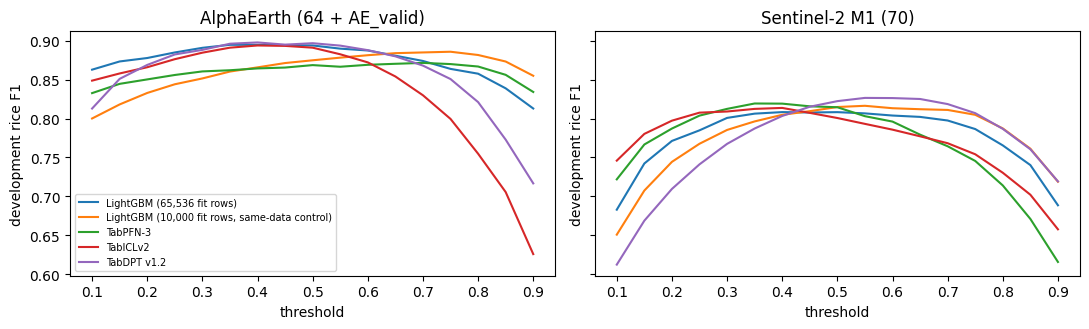

In [ ]:
# @title 4.1 Development grid, feature effect, matched classifier comparison and threshold curves
records = {**BASELINE, **FOUNDATION['records']}
grid = pd.DataFrame([{'system': rt.grid_name(v['name'], v.get('dev_pixels_rule', '')), 'feature_set': v['feature_set'],
                      'dev F1': v['dev_f1_selected']}
                     for v in records.values()]).pivot(index='system', columns='feature_set', values='dev F1')
display(grid.round(4))
learned = grid.drop(index=rt.BASELINE_SYSTEMS['A'], errors='ignore')
if {'alphaearth', 's2m1'} <= set(learned.columns):
    display(pd.DataFrame({'feature effect (AlphaEarth - M1)': learned['alphaearth'] - learned['s2m1']}).round(4))
    display(pd.Series({fs: learned[fs].max() - learned[fs].min() for fs in learned.columns},
                      name='spread among these system recipes (best - worst learned)').to_frame().round(4))
b10k = {v['feature_set']: v['dev_f1_selected'] for v in BASELINE.values() if v['system'] == 'B10k'}
matched = [{'system': v['name'], 'feature_set': v['feature_set'], 'dev F1 minus B10k (same fit rows and pixels)':
            v['dev_f1_selected'] - b10k[v['feature_set']]}
           for v in FOUNDATION['records'].values() if not v['indices'] and v['feature_set'] in b10k]
if matched:
    display(pd.DataFrame(matched).pivot(index='system', columns='feature_set',
                                        values='dev F1 minus B10k (same fit rows and pixels)').round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, fs in zip(axes, ('alphaearth', 's2m1')):
    for key, rec in records.items():
        if rec['feature_set'] != fs or rec['kind'] == 'trivial':
            continue
        folder = 'baseline' if rec['kind'] == 'lightgbm' else f"foundation/{rec['system']}/{fs}"
        name = f"{rec['system']}_{fs}_dev_proba.npy" if rec['kind'] == 'lightgbm' else 'dev_proba.npy'
        prob = np.load(LEDGER.root / folder / name).astype(float)
        _, dev_y = rt.load_split(LEDGER.root / 'tables', fs, 'dev')
        if rec['kind'] == 'foundation' and rec['indices']:
            dev_y = dev_y[np.load(rec['indices']['dev'])]
        sweep = rt.select_threshold([prob], [dev_y])['sweep']
        ax.plot([r['threshold'] for r in sweep], [r['f1'] for r in sweep], label=rec['name'])
    ax.set_title(rt.FEATURE_SET_LABELS[fs]); ax.set_xlabel('threshold'); ax.set_ylabel('development rice F1')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**What to notice:** compare the size of the feature effect with the matched classifier differences (foundation model minus B10k). B, with 6.5 times more fit rows, is a larger-data recipe, not a like-for-like classifier. Then compare both with your prediction from Section 2.

**Checkpoint.** Is the gap between feature sets larger or smaller than the matched differences between classifiers? Does any model change rank between the two feature sets?

<details><summary>Check your reasoning</summary>On these chips the feature-set gap is usually several times larger than the matched classifier differences: every learned system gains a lot from AlphaEarth, and on a given feature set they land close together. That supports a narrow claim: against these reference labels, AlphaEarth tables beat M1 tables whichever classifier reads them. It does not show why. The two feature sets differ in sensors, temporal aggregation and pretraining, and AlphaEarth includes Sentinel-1, which the label product mainly relies on, while M1 does not. The gap could reflect additional sensor information, representation learning, errors correlated with the reference, or other differences; this experiment cannot separate their contributions. Treat "the pixel description matters more than the model" as a hypothesis that independent labels would have to test. Small differences and rank changes between models do not establish a robust ordering: one development split cannot show how much they would move. These are still development numbers.</details>

# 5. Activity: change one thing — the context size [Evaluation practice]

**Question.** Is TabPFN-3's gap between M1 and AlphaEarth a data-volume problem (too few context rows) or a feature problem?

1. **Predict.** If TabPFN-3 sees 1,000, then 3,000, then 10,000 M1 fit rows, how much will development F1 change? Will 10,000 M1 rows reach the AlphaEarth result?
2. **Change one thing.** Only the number of context rows changes. The smaller contexts are nested inside the larger ones and keep the same rice share; everything else is fixed.
3. **Run** the next cell (about 1–2 minutes per size on a T4). You may change `ACTIVITY_CONTEXT_ROWS` (at most 10,000) or `ACTIVITY_FEATURE_SET` and re-run it before Section 6.
4. **Observe and explain** below.

The activity is development-only and changes nothing canonical: every model keeps the 10,000-row context in the frozen comparison. Its result is recorded in `selection.json` for interpretation.

$ /content/dimer_rice_pixel_tables/environments/tabpfn-3847ccb73baf/bin/python /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/support/fm_runner.py --config /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/runs/sample/activity/C1/sweep-s2m1.config.json


    predicted 8192/30000 rows in 3.7 s


    predicted 16384/30000 rows in 6.6 s


    predicted 24576/30000 rows in 9.4 s


    predicted 30000/30000 rows in 11.6 s


...

    predicted 24576/30000 rows in 27.0 s


    predicted 30000/30000 rows in 34.6 s


RESULT {"family": "tabpfn", "mode": "sweep", "device": "cuda", "torch": "2.11.0+cu130", "python": "3.12.12", "settings": {"n_estimators": 4}, "feature_sets": {"s2m1": {"feature_set": "s2m1", "sizes": [{"context_rows": 1000, "context_rice": 351, "load_s": 0.79, "fit_s": 2.46, "predict_dev_s": 11.57, "peak_gpu_gib": 0.936}, {"context_rows": 3000, "context_rice": 1054, "load_s": 0.56, "fit_s": 0.82, "predict_dev_s": 14.63, "peak_gpu_gib": 0.944}, {"context_rows": 10000, "context_rice": 3513, "load_s": 0.57, "fit_s": 0.75, "predict_dev_s": 34.6, "peak_gpu_gib": 0.964}]}}, "gpu": "Tesla T4"}


,context_rows,context_rice,fit_s,predict_dev_s,dev_f1_at_0p5,dev_selected_threshold,dev_f1_selected
0,1000,351,2.46,11.57,0.8047,0.65,0.8201
1,3000,1054,0.82,14.63,0.8262,0.60,0.8347
2,10000,3513,0.75,34.60,0.8145,0.35,0.8194


For comparison, TabPFN-3 on AlphaEarth with 10,000 rows: development F1 0.8716


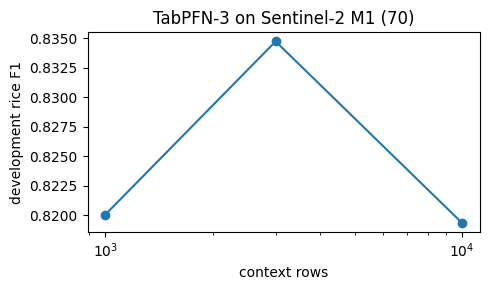

In [ ]:
# @title 5.1 TabPFN-3 context-size sweep on development
RUN_ACTIVITY = True  # @param {type:"boolean"}
ACTIVITY_FEATURE_SET = "s2m1"  # @param ["s2m1", "alphaearth"]
ACTIVITY_CONTEXT_ROWS = "1000, 3000, 10000"  # @param {type:"string"}
try:
    sizes = [int(part) for part in ACTIVITY_CONTEXT_ROWS.replace(',', ' ').split()]
except ValueError as exc:
    raise ValueError('ACTIVITY_CONTEXT_ROWS must be whole numbers separated by commas, e.g. "1000, 3000, 10000"') from exc
ACTIVITY = rt.activity_stage(LEDGER, run_fm, enabled=RUN_ACTIVITY, system='C1', feature_set=ACTIVITY_FEATURE_SET,
                             sizes=sizes, available=sorted({r['system'] for r in FOUNDATION['records'].values()}))
if ACTIVITY['ran']:
    table = pd.DataFrame(ACTIVITY['rows'])[['context_rows', 'context_rice', 'fit_s', 'predict_dev_s', 'dev_f1_at_0p5',
                                            'dev_selected_threshold', 'dev_f1_selected']]
    display(table.round(4))
    reference = FOUNDATION['records'].get('C1/alphaearth')
    if reference:
        print(f"For comparison, TabPFN-3 on AlphaEarth with 10,000 rows: development F1 {reference['dev_f1_selected']:.4f}")
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(table['context_rows'], table['dev_f1_selected'], marker='o')
    ax.set_xscale('log'); ax.set_xlabel('context rows'); ax.set_ylabel('development rice F1')
    ax.set_title(f'TabPFN-3 on {rt.FEATURE_SET_LABELS[ACTIVITY_FEATURE_SET]}'); plt.tight_layout(); plt.show()
else:
    print('Activity not run:', ACTIVITY['reason'])

**Observe and explain.** How much did F1 change from 1,000 to 10,000 rows, compared with the gap to the AlphaEarth row? What did the larger context cost in seconds?

<details><summary>Check your reasoning</summary>F1 may move by a point or two either way as rows are added, while prediction time grows (the [recorded Colab runs of revision 373aaf5](https://github.com/kurtvalcorza/mitra-classifier-pipeline/tree/main/docs/execution-evidence/2026-10-12/rice_pixel_tables_workshop) gave 0.8201, 0.8347 and 0.8194 at 1,000, 3,000 and 10,000 M1 rows: recorded evidence, not this run). For TabPFN-3 under this recipe, increasing the nested context from 1,000 to 10,000 rows did not close the observed gap. This does not establish that the labelled data are sufficient or that the features are the limiting factor: more pixels from the same fit chips add little independent information, and more sites, other sampling, larger contexts or another classifier could behave differently. Development pixels come from a few regions, so a difference of a point or two between sizes does not establish a robust ordering. The 10,000-row setting should reproduce the canonical TabPFN-3 condition from Section 3.</details>

# 6. Freeze every choice [Evaluation practice]

Validation is for measuring, not choosing. The next cell writes `selection.json` — every condition's threshold, LightGBM's tree count, each model's identity (checkpoint revision, adapter commit, environment lock hash, settings) and the SHA-256 of every saved artifact file, the data manifest's hash, the activity's result and, if Mitra is on, its declared validation sample — then records its hash in `frozen.json`. The scoring cell refuses to run if anything changed. After scoring starts, no development cell can run again in this session: to change a choice, start a fresh runtime.

**What "once" protects.** The freeze and the score-once lock protect *this run's* recorded choices. They do not turn these chips into an unseen holdout: the validation chips are teaching data that the course lessons and earlier runs of this notebook have already scored, and a fresh runtime resets the lock. If you change a choice after seeing validation results, everything you score afterwards is exploratory evaluation, even in a fresh runtime. Retrying an input that was refused before anything was scored (for example a BYOD upload that failed its checks) is different: nothing was evaluated.

In [ ]:
# @title 6.1 Freeze
declared = {'mitra_validation_pixels': MITRA_VALIDATION_PIXELS} if 'C3' in SELECTED_SYSTEMS else {}
SELECTION = rt.freeze_stage(LEDGER, **declared)
print('selection.json SHA-256:', LEDGER.receipt('freeze')['selection_sha256'])
display(pd.DataFrame([{'condition': k, 'threshold': v['threshold'], 'dev F1': v['dev_f1_selected']}
                      for k, v in SELECTION['conditions'].items()]).set_index('condition').round(4))

selection.json SHA-256: 6f143fde4e9e426eeeeff1e31bb1922ee56340025f2550a7b5fa60b310c24823


,threshold,dev F1
condition,,
A/alphaearth,0.50,0.0000
A/s2m1,0.50,0.0000
B/alphaearth,0.35,0.8948
B/s2m1,0.40,0.8083
B10k/alphaearth,0.75,0.8859
B10k/s2m1,0.55,0.8164
C1/alphaearth,0.70,0.8716
C1/s2m1,0.35,0.8194
C2/alphaearth,0.40,0.8940


# 7. Score validation once [Evaluation practice]

The next cell checks the freeze, then scores every frozen condition on **all 113,821 labelled validation pixels** (Mitra: its declared sample). Each foundation model is **reloaded from its saved files in a fresh process**, after checking every file's SHA-256 against the frozen inventory; before scoring, it re-predicts its first development chunk and must reproduce the saved probabilities within 1e-4. LightGBM is reloaded from its saved model file. Expect about 2–3 minutes per foundation model.

Each condition is reported at 0.5 and at its development-chosen threshold, pooled over all scored pixels.

In [ ]:
# @title 7.1 Score the frozen conditions on validation (once)
SCORED = rt.score_stage(LEDGER, run_fm)
METRICS = pd.read_csv(LEDGER.root / 'scores' / 'metrics.csv')
if SCORED['parity']:
    display(pd.DataFrame(SCORED['parity']).T[['rows', 'max_abs_difference', 'within_tolerance']])

$ /content/dimer_rice_pixel_tables/environments/tabpfn-3847ccb73baf/bin/python /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/support/fm_runner.py --config /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/runs/sample/foundation/C1/score-alphaearth-s2m1.config.json


    predicted 8192/8192 rows in 8.9 s


    predicted 8192/113821 rows in 8.4 s


    predicted 16384/113821 rows in 16.9 s


    predicted 24576/113821 rows in 25.5 s


...

    predicted 98304/113821 rows in 109.4 s


    predicted 106496/113821 rows in 118.5 s


    predicted 113821/113821 rows in 127.2 s


RESULT {"family": "tabdpt", "mode": "score", "device": "cuda", "torch": "2.7.1+cu126", "python": "3.12.12", "settings": {"n_ensembles": 4, "context_size": 4096, "batch_size": 4096}, "feature_sets": {"alphaearth": {"feature_set": "alphaearth", "reload_s": 3.07, "reload_parity": {"rows": 8192, "max_abs_difference": 0.0, "tolerance": 0.0001, "within_tolerance": true, "decisions_identical_at_frozen_threshold": true}, "eval_rows": 113821, "predict_eval_s": 127.11, "peak_gpu_gib": 0.478}, "s2m1": {"feature_set": "s2m1", "reload_s": 1.61, "reload_parity": {"rows": 8192, "max_abs_difference": 0.0, "tolerance": 0.0001, "within_tolerance": true, "decisions_identical_at_frozen_threshold": true}, "eval_rows": 113821, "predict_eval_s": 127.23, "peak_gpu_gib": 0.486}}, "gpu": "Tesla T4"}


,rows,max_abs_difference,within_tolerance
C1/alphaearth,8192,0.0,True
C1/s2m1,8192,0.0,True
C2/alphaearth,8192,0.0,True
C2/s2m1,8192,0.0,True
C4/alphaearth,8192,0.0,True
C4/s2m1,8192,0.0,True


## 7.2 Read the results [Evaluation practice]

The grid below is validation rice F1 at each condition's frozen threshold. Then come the feature effect, the matched classifier comparison (each foundation model minus B10k on the same pixels), the spread among these system recipes and, if Mitra is on, a grid of every condition on Mitra's sample, the full metric table, the validation class balance (shown only now), the share of each validation chip that is not scored (edge band and nodata), and per-chip tables of F1, false positives and predicted-rice share for **diagnosis only**. F1 here is pooled agreement with the reference map on reference-labelled pixels after the edge-band and nodata exclusion: the confusion counts of all scored pixels are added up, so each chip weighs in proportion to its scored pixels (and its rice), not equally. pixels within a chip are strongly correlated and the chips cluster in two regions, so per-chip differences and small pooled differences are not significance tests [11].

feature_set,alphaearth,s2m1
system,,
All non-rice,0.0000,0.0000
"LightGBM (10,000 fit rows, same-data control)",0.9049,0.7300
"LightGBM (65,536 fit rows)",0.9277,0.7549
TabDPT v1.2,0.9329,0.7617
TabICLv2,0.9280,0.7680
TabPFN-3,0.8958,0.7584


,feature effect (AlphaEarth - M1)
system,
"LightGBM (10,000 fit rows, same-data control)",0.1749
"LightGBM (65,536 fit rows)",0.1728
TabDPT v1.2,0.1713
TabICLv2,0.1600
TabPFN-3,0.1374


,spread among these system recipes (best - worst learned)
alphaearth,0.0371
s2m1,0.0380


,feature_set,F1 minus B10k (same fit rows and pixels)
condition,,
C1/alphaearth,alphaearth,-0.0091
C1/s2m1,s2m1,0.0285
C2/alphaearth,alphaearth,0.0231
C2/s2m1,s2m1,0.0380
C4/alphaearth,alphaearth,0.0280
C4/s2m1,s2m1,0.0317


,condition,split,pixels,threshold_rule,threshold,f1,iou,precision,recall,undefined
0,A/alphaearth,validation,all 113821 labelled validation pixels,0.5,0.50,0.0000,0.0000,NaN,0.0000,precision: no pixel predicted rice
1,A/alphaearth,validation,all 113821 labelled validation pixels,development-selected,0.50,0.0000,0.0000,NaN,0.0000,precision: no pixel predicted rice
2,A/s2m1,validation,all 113821 labelled validation pixels,0.5,0.50,0.0000,0.0000,NaN,0.0000,precision: no pixel predicted rice
3,A/s2m1,validation,all 113821 labelled validation pixels,development-selected,0.50,0.0000,0.0000,NaN,0.0000,precision: no pixel predicted rice
4,B/alphaearth,validation,all 113821 labelled validation pixels,0.5,0.50,0.9244,0.8595,0.9472,0.9028,NaN
5,B/alphaearth,validation,all 113821 labelled validation pixels,development-selected,0.35,0.9277,0.8651,0.9291,0.9262,NaN
6,B/s2m1,validation,all 113821 labelled validation pixels,0.5,0.50,0.7582,0.6106,0.6798,0.8570,NaN
7,B/s2m1,validation,all 113821 labelled validation pixels,development-selected,0.40,0.7549,0.6063,0.6533,0.8938,NaN
8,B10k/alphaearth,validation,all 113821 labelled validation pixels,0.5,0.50,0.9204,0.8526,0.9332,0.9080,NaN
9,B10k/alphaearth,validation,all 113821 labelled validation pixels,development-selected,0.75,0.9049,0.8263,0.9587,0.8569,NaN


...

,region,scored pixels,"not scored (edge band, nodata)"
chip,,,
ph_240_427_2021,PH-07,12742,0.222
ph_242_425_2019,PH-07,16384,0.000
ph_243_420_2021,PH-07,14583,0.110
ph_245_424_2019,PH-07,14554,0.112
ph_251_427_2019,PH-07,12238,0.253
ph_273_485_2019,PH-08,13362,0.184
ph_278_478_2021,PH-08,13574,0.172
ph_293_513_2020,PH-08,16384,0.000


False positives per chip (pixels called rice where the reference says non-rice):


condition,A/alphaearth,A/s2m1,B/alphaearth,B/s2m1,B10k/alphaearth,B10k/s2m1,C1/alphaearth,C1/s2m1,C2/alphaearth,C2/s2m1,C4/alphaearth,C4/s2m1
chip,,,,,,,,,,,,
ph_240_427_2021,0,0,162,1738,83,1476,0,1183,20,1103,196,1353
ph_242_425_2019,0,0,0,1,0,6,0,4,0,3,0,2
ph_243_420_2021,0,0,40,436,37,345,16,282,24,250,44,311
ph_245_424_2019,0,0,100,856,37,671,27,946,75,857,158,1007
ph_251_427_2019,0,0,464,1990,179,1766,206,2215,231,1917,408,2444
ph_273_485_2019,0,0,67,483,61,436,31,557,59,561,123,547
ph_278_478_2021,0,0,78,609,79,641,12,740,34,684,50,768
ph_293_513_2020,0,0,0,0,0,2,0,1,0,1,0,0


Share of scored pixels predicted rice:


condition,A/alphaearth,A/s2m1,B/alphaearth,B/s2m1,B10k/alphaearth,B10k/s2m1,C1/alphaearth,C1/s2m1,C2/alphaearth,C2/s2m1,C4/alphaearth,C4/s2m1
chip,,,,,,,,,,,,
ph_240_427_2021,0.0,0.0,0.172,0.286,0.160,0.235,0.126,0.235,0.149,0.227,0.178,0.258
ph_242_425_2019,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
ph_243_420_2021,0.0,0.0,0.063,0.092,0.049,0.077,0.053,0.066,0.059,0.063,0.067,0.078
ph_245_424_2019,0.0,0.0,0.049,0.095,0.039,0.078,0.037,0.102,0.047,0.095,0.055,0.107
ph_251_427_2019,0.0,0.0,0.181,0.305,0.130,0.278,0.136,0.332,0.146,0.302,0.181,0.352
ph_273_485_2019,0.0,0.0,0.233,0.253,0.232,0.239,0.227,0.269,0.235,0.267,0.241,0.268
ph_278_478_2021,0.0,0.0,0.271,0.306,0.259,0.293,0.249,0.319,0.266,0.317,0.266,0.327
ph_293_513_2020,0.0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


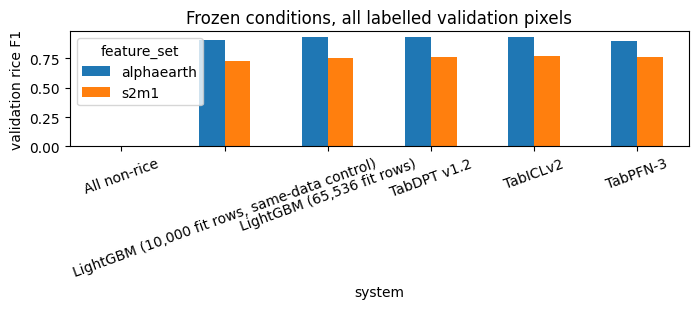

In [ ]:
# @title 7.2 Validation grid, effects, full table and per-chip diagnosis
main = METRICS[(METRICS['split'] == 'validation') & (METRICS['threshold_rule'] == 'development-selected')]
main = main.assign(system=[rt.grid_name(s, p) for s, p in zip(main['system'], main['pixels'])])
GRID = main.pivot(index='system', columns='feature_set', values='f1')
display(GRID.round(4))
learned = GRID.drop(index=rt.BASELINE_SYSTEMS['A'], errors='ignore')
if {'alphaearth', 's2m1'} <= set(learned.columns):
    display(pd.DataFrame({'feature effect (AlphaEarth - M1)': learned['alphaearth'] - learned['s2m1']}).round(4))
    display(pd.Series({fs: learned[fs].max() - learned[fs].min() for fs in learned.columns},
                      name='spread among these system recipes (best - worst learned)').to_frame().round(4))
full = main[~main['pixels'].str.startswith('declared')].set_index('condition')['f1']
matched = [{'condition': c, 'feature_set': c.split('/')[1], 'F1 minus B10k (same fit rows and pixels)': full[c] - full[f"B10k/{c.split('/')[1]}"]}
           for c in full.index if c.split('/')[0] in rt.FOUNDATION_SYSTEMS and f"B10k/{c.split('/')[1]}" in full.index]
if matched:
    display(pd.DataFrame(matched).set_index('condition').round(4))
MITRA_MATCHED = METRICS[(METRICS['split'] == 'validation (Mitra sample)') & (METRICS['threshold_rule'] == 'development-selected')]
if len(MITRA_MATCHED):
    on_sample = pd.concat([MITRA_MATCHED, main[main['pixels'].str.startswith('declared')]])
    print("Every condition on Mitra's declared validation sample (matched pixels):")
    display(on_sample.assign(system=on_sample['condition'].str.split('/').str[0])
            .pivot(index='system', columns='feature_set', values='f1').round(4))
display(METRICS[['condition', 'split', 'pixels', 'threshold_rule', 'threshold', 'f1', 'iou', 'precision', 'recall',
                 'undefined']].round(4))
first = main.iloc[0]
print(f"Validation class balance (now that scoring is done): {int(first.tp + first.fn)} rice of "
      f"{int(first.tp + first.fp + first.fn + first.tn)} labelled pixels")
CHIP_TABLE = pd.read_csv(LEDGER.root / 'scores' / 'per_chip_metrics.csv')
sampled = set(main.loc[main['pixels'].str.startswith('declared'), 'condition'])
CHIP_TABLE['condition'] = [f'{c} (sample)' if c in sampled else c for c in CHIP_TABLE['condition']]
display(CHIP_TABLE.pivot(index='chip', columns='condition', values='f1').round(3))
validation_chips = CHIPS[CHIPS['role'] == 'validation'].set_index('chip')
display(pd.DataFrame({'region': validation_chips['region'], 'scored pixels': validation_chips['labelled_pixels'],
                      'not scored (edge band, nodata)': (1 - validation_chips['labelled_pixels'] / rt.CHIP ** 2).round(3)}))
CHIP_TABLE['predicted rice share'] = (CHIP_TABLE['tp'] + CHIP_TABLE['fp']) / CHIP_TABLE['scored_pixels']
print('False positives per chip (pixels called rice where the reference says non-rice):')
display(CHIP_TABLE.pivot(index='chip', columns='condition', values='fp'))
print('Share of scored pixels predicted rice:')
display(CHIP_TABLE.pivot(index='chip', columns='condition', values='predicted rice share').round(3))
ax = GRID.plot.bar(figsize=(7, 3.2), rot=20)
ax.set_ylabel('validation rice F1')
ax.set_title('Frozen conditions, all labelled validation pixels' + (' (Mitra: its declared sample)' if sampled else ''))
plt.tight_layout(); plt.show()

**What to notice:** a blank in the per-chip table means undefined, not zero. Recall is undefined on a chip with no reference rice; F1 is undefined only when a chip has neither reference rice nor predicted rice. On a rice-free chip any false positive makes F1 0, so use the false-positive and predicted-rice tables to tell a few stray pixels from a map that calls much of the chip rice. Compare validation with development: a condition whose validation F1 drops far below its development F1 transferred less well to the validation regions. Possible reasons to investigate include a different rice share, crop calendar or cloud cover, reference-map quality there, or a threshold that does not transfer; this run does not tell you which. A's precision is undefined because it never predicts rice.

**Checkpoint.** (1) Does the validation grid tell the same story as the development grid? (2) Name one per-chip pattern that pooled F1 hides. (3) What would you need before claiming one foundation model is better than LightGBM for Philippine rice? (4) The labels were derived mainly from Sentinel-1 SAR [9], which AlphaEarth includes and M1 does not [7]. How much of the validation feature effect could be agreement with the label source rather than a better description of rice?

<details><summary>Check your reasoning</summary>(1) Usually yes: the feature effect stays much larger than the matched classifier differences and the spread among recipes. (2) For example, a chip where every system over-predicts rice (possibly label error or a crop that looks like rice), or the two rice-free chips where only false positives can occur. (3) More validation chips from more regions and years, scored by whole region, with spatially aware uncertainty [11]; a difference of a point or two of F1 on 8 chips from two regions does not establish a ranking. (4) This run cannot tell. AlphaEarth embeddings are computed partly from Sentinel-1 SAR and the labels were built mainly from it; the gap could reflect additional sensor information, representation learning (pretraining), errors correlated between AlphaEarth and the SAR-based reference, or other differences, and their contributions are not identified here. A Sentinel-1 feature set without AlphaEarth's pretraining would be a diagnostic control for sensor availability, not an accuracy check; only reference observations independent of the label product (for example field surveys) would check accuracy. Report the result as "AlphaEarth tables beat M1 tables against SAR-derived reference labels", not as proof that AlphaEarth describes rice better.</details>

# 8. Reload check and export [Engineering]

**Infrastructure — run the cell; reading its implementation is optional.** One frozen foundation-model condition (TabPFN-3 on AlphaEarth by default) is reloaded once more in a fresh process and re-predicts the first 8,192 validation pixels; the probabilities must match the scored ones within 1e-4. Loading a model is not the same as reproducing it: this check compares outputs, not only that the files open.

`results.zip` then collects `run_summary.json`, `data_manifest.json` (INDEX digest, chip digests, roles), `features.json` (recipes and fills), `selection.json` and `frozen.json`, the development and validation metric tables, `per_chip_metrics.csv`, `activity.csv`, `verification.json`, per-pixel validation predictions (`validation_predictions.csv.gz`: chip, pixel, label and each condition's rice probability), the LightGBM model files, the stage receipts, attribution and a conclusion template, with `checksums.json`. The foundation-model artifacts stay in this runtime (their file inventories are in `selection.json`): they embed the fit rows as context, and the bundle carries no model weights and no imagery. The TabICLv2 artifact is a pickle, which runs code when loaded: only load pickles you created yourself.

In [ ]:
# @title 8.1 Reload one condition in a fresh process, then export results.zip
CONCLUSION_TEMPLATE = '# Conclusion (fill in from your run)\n\n- Task: rice / non-rice per 20 m pixel on 8 validation chips (2 regions), scored once in this run after a frozen protocol. Metric: pooled agreement with the reference map on reference-labelled pixels after edge/nodata exclusion (... of validation pixels not scored; chips weighted by their scored pixels).\n- Feature effect: AlphaEarth minus M1 validation F1 for each learned system: ...\n- Classifier comparison: each foundation model minus B10k (same 10,000 fit rows, same pixels) on each feature set: ... ; spread among these system recipes: ...\n- Baseline: LightGBM (65,536 rows) F1 ... ; all-non-rice F1 0.\n- Activity: TabPFN-3 context 1,000 -> 10,000 rows changed development F1 by ... at a cost of ... s.\n- Largest per-chip failure and its likely cause: ...\n- Limits: 8 chips, 2 regions, spatially correlated pixels; labels from a published map derived mainly from Sentinel-1 SAR, a sensor AlphaEarth includes and M1 lacks, so the feature effect is measured against that reference and its causes are not separated; possible AlphaEarth pretraining overlap; tutorial evidence, not a model ranking.\n'
PROBE = rt.probe_reload(LEDGER, run_fm)
display(pd.Series(PROBE, name='validation reload check').to_frame())
receipts = {p.stem: json.loads(p.read_text()) for p in sorted(LEDGER.receipts.glob('*.json'))}
RUN_SUMMARY = {
    'notebook': 'tutorials/DIMER_Philippines_Rice_Pixel_Tables_Workshop.ipynb', 'workshop_revision': WORKSHOP_REVISION,
    'repository': 'kurtvalcorza/mitra-classifier-pipeline', 'notebook_spec': '2.4', 'profile': 'E2E', 'mode': 'WORKSHOP',
    'carried_sha256': CARRIED_HASHES, 'adapter_sha256': CARRIED_SOURCE_SHA256, 'environment_lock_sha256': ENVIRONMENT_LOCK_SHA256,
    'host': HOST, 'model_identities': MODEL_IDENTITIES, 'systems': ['A', 'B', 'B10k', *sorted({r['system'] for r in FOUNDATION['records'].values()})],
    'failed_systems': sorted({*FOUNDATION['errors'], *ENVIRONMENT_FAILED_SYSTEMS}),
    'environment_errors': ENVIRONMENT_ERRORS,
    'selection_sha256': receipts['freeze']['selection_sha256'], 'stage_receipts': receipts, 'reload_probe': PROBE,
    'wall_seconds': round(time.perf_counter() - SESSION_STARTED, 1),
    'evidence_level': 'tutorial evidence on 8 validation chips from 2 regions; not a benchmark or model ranking',
}
EXPORT = rt.export_stage(LEDGER, RUN_SUMMARY, CONCLUSION_TEMPLATE)
print(f"results.zip: {EXPORT['members']} files, checksums verified, SHA-256 {EXPORT['sha256']}")
display(FileLink(str(EXPORT['path'])))

$ /content/dimer_rice_pixel_tables/environments/tabpfn-3847ccb73baf/bin/python /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/support/fm_runner.py --config /content/dimer_rice_pixel_tables/sessions/8fc3c4168799/runs/sample/foundation/C1/probe-alphaearth.config.json


    predicted 8192/8192 rows in 8.8 s


RESULT {"family": "tabpfn", "mode": "probe", "device": "cuda", "torch": "2.11.0+cu130", "python": "3.12.12", "settings": {"n_estimators": 4}, "feature_sets": {"alphaearth": {"feature_set": "alphaearth", "rows": 8192, "max_abs_difference": 0.0, "tolerance": 0.0001, "within_tolerance": true, "decisions_identical_at_frozen_threshold": true, "seconds": 8.79}}, "gpu": "Tesla T4"}


,validation reload check
ran,True
condition,C1/alphaearth
decisions_identical_at_frozen_threshold,True
feature_set,alphaearth
max_abs_difference,0.0
rows,8192
seconds,8.79
tolerance,0.0001
within_tolerance,True


results.zip: 31 files, checksums verified, SHA-256 faef0c62394a25789faceacb26fd5cc15e394c902cd0954d8419d6b1ab7cf585


/content/dimer_rice_pixel_tables/sessions/8fc3c4168799/runs/sample/results.zip

# 9. Conclude with evidence [Evaluation practice]

Write your conclusion in five sentences, using only numbers this run printed (the template is also in `results.zip`):

1. **Task and evidence:** what was predicted, on how many validation chips and regions, on which pixels (reference-labelled, edge band excluded), scored how many times in this run.
2. **Principal result:** the feature effect and the matched classifier differences (foundation model minus B10k) on validation, with the numbers; report the spread among recipes separately.
3. **Baseline:** how the foundation models compare with LightGBM on the same feature set, and with B10k on the same rows.
4. **Failure mode or uncertainty:** the largest per-chip failure and a plausible cause (model, label, cloud gaps, or region).
5. **Limits:** what 8 clustered chips, published-map labels derived mainly from Sentinel-1 SAR (a sensor AlphaEarth includes and M1 lacks) and possible AlphaEarth pretraining overlap prevent you from claiming. Word the feature effect as a comparison of whole representations against this reference, not as a cause.

**Transfer.** The same protocol applies to any per-pixel mapping task with chip-level labels: change the label (for example, mangrove or sugarcane), keep the region-level roles and the freeze, and compare the feature effect with the matched classifier differences again.

## What did not work

These design choices were tried in development runs on fresh Colab T4 runtimes (2026-10-11; development evidence, not results of this run) and rejected:

| Tried | Observed | Decision |
|---|---|---|
| Mitra through AutoGluon 1.5.0 with the v2 notebook's `max_memory_usage_ratio = 1.10` | AutoGluon refused Mitra before loading it: its pre-check estimated about 45 GB for 10,000 × 65 rows against about 10 GB free; the real peak was under 3.2 GB of RAM | Mitra runs only on request, in its own process, with the ratio raised to 8 |
| Mitra scoring every development and validation pixel | About 50 rows per second on a T4 at both 4,096 and 10,000 context rows: about 2.6 hours for full scoring | Opt-in, on a declared seeded sample of 10,000 pixels |
| AutoGluon's own `predict()` threshold for Mitra | AutoGluon tuned it to about 0.06–0.33 on its tuning rows, a different rule from every other system | `predict_proba` with the notebook's development-chosen threshold |
| Choosing thresholds on all 119,885 development pixels | Roughly doubled foundation-model prediction time for a threshold that moves little | A seeded 30,000-pixel subset that keeps the development rice share |

# 10. Optional: bring your own chips [Engineering]

This section re-runs the **whole protocol** on your chips — validate, split by site, stage tables, fit every selected system, choose thresholds on your development chips, freeze, score your test chips once and export `byod_results.zip`. It is off by default and is not part of Run all.

**Schema (checked before any model runs).** One HDF5 file per chip-year (`<site>_<year>.h5`), with:

| Dataset | Shape | Type and values |
|---|---|---|
| `S2` | 24 × 6 × 128 × 128 | float surface reflectance (0–1 scale, up to 2.0); bins and band order as in the data context |
| `S2_valid` | 24 × 128 × 128 | 0 or 1 |
| `label` | 128 × 128 | 0 non-rice, 1 rice, 255 ignore |
| `AlphaEarth` + `AE_valid` (optional, together) | 64 × 128 × 128 and 128 × 128 | float embedding; 0 or 1 |

A site is the HDF5 attribute `group` or `group_id`, else the file name without its `_YYYY` year. **Group repeated and overlapping locations under one site:** roles are assigned by site, so every chip of the same place (in any year), and every chip that overlaps or touches another, must carry the same `group` value. The notebook cannot check this from names, and different names for overlapping places would leak between fit, development and test. **Minimum:** 6 labelled chips from at least 3 sites, with rice in fit, development and test sites and non-rice in fit. If any labelled chip lacks AlphaEarth, only the M1 column runs. Chips whose label is all 255 are reported as prediction-only and not used. **Limits:** at most 200 chips and 4 GiB; zip archives with absolute paths, `..`, backslashes or symbolic links are refused. A refusal names the file and the rule it broke. **What the checks establish:** they accept an *array schema* (shapes, types, value ranges, masks, labels). They do not verify *geospatial alignment*, that each chip's Sentinel-2, AlphaEarth and label arrays cover the same 20 m grid, pixel order and year. Prepare chips with the recipe in the data context (same-year layers, one grid for every array) and keep the CRS, affine and year as HDF5 attributes; the notebook does not check them.

**Your data stays in this runtime;** nothing is uploaded elsewhere, and only files you download leave it. **Do not upload confidential, restricted, personal or regulated data** unless you are authorised to process it in this runtime. The fitted foundation-model artifacts contain your fit rows as context.

Set `USE_BYOD = True`, then either give `BYOD_PATH` (folders, `.zip` or `.h5` paths, comma-separated) or leave it blank to open the Colab upload dialog. The foundation models are the ones selected in Section 3.1.

In [ ]:
# @title 10.1 Bring your own chips (re-adapts, freezes and scores your test chips once)
USE_BYOD = False  # @param {type:"boolean"}
BYOD_PATH = ""  # @param {type:"string"}
BYOD_STATUS = 'disabled (USE_BYOD = False)'
if USE_BYOD:
    BYOD_STATUS = 'failed (see the error above)'  # replaced below when the experiment is refused or completes
    BYOD_ROOT = RUN_ROOT / 'byod'
    if BYOD_ROOT.exists():  # a new attempt never inherits an earlier attempt's chips, freeze or scores
        shutil.rmtree(BYOD_ROOT)
    sources = [Path(p.strip()).expanduser() for p in BYOD_PATH.split(',') if p.strip()]
    refusal = None  # a refused input prints one message and stops here; integrity and parity failures still raise
    if not sources:
        try:
            from google.colab import files  # only on Colab, only after the sample path has completed
        except ImportError:
            refusal = ('BYOD_PATH: it is blank, and the upload dialog exists only on Google Colab. On Kaggle or another '
                       'runtime, set BYOD_PATH to your chips (folders, .zip or .h5 paths, e.g. under /kaggle/input/)')
        else:
            upload_dir = SESSION_ROOT / 'byod_upload'
            if upload_dir.exists():  # a retry never mixes in files from an earlier upload
                shutil.rmtree(upload_dir)
            upload_dir.mkdir(parents=True)
            for name, payload in files.upload().items():
                (upload_dir / Path(name).name).write_bytes(payload)
            sources = [upload_dir]
    if refusal is None:
        try:
            missing_sources = [str(s) for s in sources if not s.exists()]
            if missing_sources:
                raise FileNotFoundError(f'BYOD_PATH: entries not found: {missing_sources}')
            paths = rt.collect_byod(sources, BYOD_ROOT / 'input')
            if not paths:
                raise rt.ChipError('no .h5 chips found; see the schema above')
            byod_chips, problems = {}, []
            for path in paths:
                try:
                    byod_chips[path.stem] = rt.read_chip_h5(path, require_label=False)
                except rt.ChipError as exc:
                    problems.append(str(exc))
            if problems:
                refusal = '\n'.join(problems)
            else:
                plan = rt.byod_plan(byod_chips)
                print(f"{len(paths)} chips valid; adapting on {len(plan['labelled'])} labelled chips; feature sets: {plan['feature_sets']}")
                BYOD = rt.Ledger(BYOD_ROOT)
                byod_prepared = rt.prepare_byod(BYOD, byod_chips, plan, {p.stem: rt.sha256_file(p) for p in paths})
        except (rt.ChipError, FileNotFoundError) as exc:
            refusal = str(exc)
    if refusal is not None:
        print('Refused: ' + refusal.replace('\n', '\nRefused: '))
        print('Nothing was adapted or scored. Fix the named file (or BYOD_PATH) and run this cell again.')
        BYOD_STATUS = 'refused (input not accepted; nothing scored)'
    else:
        del byod_chips; gc.collect()
        display(pd.DataFrame(byod_prepared['chips']))
        rt.baseline_stage(BYOD)
        rt.foundation_stage(BYOD, SELECTED_SYSTEMS, run_fm, MODEL_IDENTITIES, mitra_dev_pixels=MITRA_DEV_PIXELS,
                            require_all=REQUIRE_ALL_SELECTED_MODELS)
        rt.activity_stage(BYOD, run_fm, enabled=False, system='C1', feature_set='s2m1', sizes=[], available=[])
        rt.freeze_stage(BYOD, **({'mitra_validation_pixels': MITRA_VALIDATION_PIXELS} if 'C3' in SELECTED_SYSTEMS else {}))
        rt.score_stage(BYOD, run_fm, split_label='test')
        byod_metrics = pd.read_csv(BYOD_ROOT / 'scores' / 'metrics.csv')
        byod_main = byod_metrics[(byod_metrics['split'] == 'test') & (byod_metrics['threshold_rule'] == 'development-selected')]
        byod_main = byod_main.assign(system=[rt.grid_name(s, p) for s, p in zip(byod_main['system'], byod_main['pixels'])])
        display(byod_main.pivot(index='system', columns='feature_set', values='f1').round(4))
        byod_export = rt.export_stage(BYOD, {'byod': True, 'plan': {k: plan[k] for k in ('split', 'feature_sets', 'prediction_only')},
                                             'model_identities': MODEL_IDENTITIES, 'host': HOST}, CONCLUSION_TEMPLATE)
        byod_zip = BYOD_ROOT / 'byod_results.zip'
        shutil.copy2(byod_export['path'], byod_zip)
        print(f"byod_results.zip: {byod_export['members']} files, verified; it stays in this runtime until you download it")
        display(FileLink(str(byod_zip)))
        BYOD_STATUS = 'completed (scored once; byod_results.zip written)'
else:
    print('BYOD not run (USE_BYOD = False).')

BYOD not run (USE_BYOD = False).


In [ ]:
# @title Run-all completion summary
completion = {'profile': 'E2E', 'mode': 'WORKSHOP', 'stages finished': sorted(p.stem for p in LEDGER.receipts.glob('*.json')),
              'conditions scored': len(SELECTION['conditions']), 'reload probe': PROBE.get('within_tolerance', 'not run'),
              'results.zip': str(EXPORT['path']), 'BYOD experiment': globals().get('BYOD_STATUS', 'cell not run'),
              'wall minutes': round((time.perf_counter() - SESSION_STARTED) / 60, 1)}
display(pd.Series(completion, name='value').to_frame())
expected = {'prepare', 'baseline', 'foundation', 'activity', 'freeze', 'score', 'export'}
if not expected <= set(completion['stages finished']):
    raise RuntimeError(f"Run all did not finish every stage: missing {sorted(expected - set(completion['stages finished']))}")
score_receipt = LEDGER.receipt('score')
if score_receipt.get('parity_failures'):
    raise RuntimeError(f"scoring recorded reload parity failures {score_receipt['parity_failures']}; this run is not complete")
reload_line = 'artifact reload checked' if PROBE.get('ran') else 'reload probe not run (no foundation model selected)'
print('Run all complete for the sample experiment: data verified, baselines and foundation models developed, choices frozen, validation scored once, '
      f'{reload_line}, results exported.')
print(f"BYOD experiment: {completion['BYOD experiment']}")

,value
profile,E2E
mode,WORKSHOP
stages finished,"[activity, baseline, export, foundation, freez..."
conditions scored,12
reload probe,True
results.zip,/content/dimer_rice_pixel_tables/sessions/8fc3...
BYOD experiment,disabled (USE_BYOD = False)
wall minutes,30.7


Run all complete for the sample experiment: data verified, baselines and foundation models developed, choices frozen, validation scored once, artifact reload checked, results exported.
BYOD experiment: disabled (USE_BYOD = False)


# Troubleshooting

| What you see | Likely cause | What to do |
|---|---|---|
| "needs a Linux x86_64 runtime" | Windows, macOS or ARM kernel | Use Google Colab, Kaggle or a Linux x86_64 Jupyter server |
| "No GPU detected" or `device` = `cpu` | CPU runtime | Runtime → Change runtime type → T4 GPU, then Run all |
| `INDEX.jsonl SHA-256 ... != pinned` or a chip SHA-256 differs | The download changed or is corrupt | Re-run once; if it persists, stop and report it. Do not remove the check |
| Kaggle download fails | Network or Kaggle outage; no account is needed | Retry once later |
| uv, wheel or checkpoint hash mismatch | A pinned download changed or was truncated | Re-run once; a persistent mismatch must be reported, not bypassed |
| Out of disk | Each environment is 5–7.5 GB | Start a fresh runtime with at least 30 GB free; keep Mitra off |
| CUDA out of memory | Another process holds GPU memory, or a non-T4 GPU with less memory | Restart the runtime and Run all; never record a skipped model as a success |
| Mitra: "Estimated to require ... GB" | AutoGluon's memory pre-check | Keep `max_memory_usage_ratio = 8` (set by the notebook) and run Mitra on a fresh runtime |
| "needs the ... stage(s) to finish first" | A cell was run out of order | Runtime → Run all from the top |
| "already scored ... exactly once" | A development or scoring cell was re-run after scoring started | Start a fresh runtime (Runtime → Disconnect and delete runtime) to change any choice |
| "changed after the freeze" or "differs from the inventory" | `selection.json` or a saved artifact was edited | Start a fresh runtime; scores from an edited freeze are not valid |
| "reload parity failed" | A reloaded model did not reproduce its probabilities | Keep `verification.json`, `probe.json` and the logs, and report it |
| A model process exits with a code | See the log path in the message | Read the last lines of the log; most causes are memory or download errors above |
| BYOD refused | The message names the file and the rule | Fix that file (shape, value range, labels, AlphaEarth pairing, sites) and re-run the BYOD cell |

# Data, models, attribution and licences

**Data:** `kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching`, version 1 [10], CC BY 4.0, verified by `INDEX.jsonl` SHA-256 `e92bbb9f20d1f7efb225d568e2a44a6ae3d59faab9079590e2dfad780458344d` and every chip's SHA-256. Component attribution:

- **Rice labels:** Chen et al., 20 m paddy rice maps for Monsoon Asia 2018–2021 [9], CC BY 4.0 — reprojected, binarised and given an ignored edge band.
- **Optical inputs:** contains modified Copernicus Sentinel data 2019–2021 [8], under the Copernicus Sentinel data terms.
- **AlphaEarth Foundations Satellite Embedding** (Google and Google DeepMind) [7], CC BY 4.0.
- **Regional boundaries:** geoBoundaries PHL ADM1, CC BY 3.0 IGO.
- **Dataset compilation:** Kurt Valcorza, CC BY 4.0. Component terms continue to apply.

**Models** (each verified against its carried manifest before use):

| System | Checkpoint and revision | Licence | Adapter |
|---|---|---|---|
| TabPFN-3 | `Prior-Labs/tabpfn_3` @ `24a16a89d245878b846555110985634aa2e656d7` | **TabPFN-3 licence v1.0 — non-commercial use only** | `kurtvalcorza/tabpfn-classifier-pipeline` @ `769fb7b4` |
| TabICLv2 | `jingang/TabICL` @ `4dcd344ece2c00be9e831fdd35bed57b5ad83e19` | BSD-3-Clause | `kurtvalcorza/tabicl-classifier-pipeline` @ `7400516a` |
| TabDPT v1.2 | `Layer6/TabDPT` @ `4462ffbd1d8dea25d4862d30beed4b70cd596ae5` | Apache-2.0 | `kurtvalcorza/tabdpt-classifier-pipeline` @ `1e35dc47` |
| Mitra (opt-in) | `autogluon/mitra-classifier` @ `c425e9fa0910a6be1c494321792e7ba2a1367b1a` | Apache-2.0 | `kurtvalcorza/mitra-classifier-pipeline` @ `469d9125` |
| LightGBM | the runtime's `lightgbm` package | MIT | — |

The TabPFN-3 conditions this notebook fits, and their outputs, are for teaching and research only.

**AI Assistance Disclosure:** Generative AI assisted this notebook's code and technical writing under maintainer direction. The maintainer remains responsible for reviewing the implementation, validating results and making release decisions. AI assistance is not independent verification, provider endorsement or release approval.

## References

[1] N. Hollmann, S. Müller, L. Purucker, A. Krishnakumar, M. Körfer, S. B. Hoo, R. T. Schirrmeister, and F. Hutter, "Accurate predictions on small data with a tabular foundation model," *Nature*, vol. 637, pp. 319–326, 2025, doi: 10.1038/s41586-024-08328-6. [Online]. Available: https://doi.org/10.1038/s41586-024-08328-6

[2] Prior Labs, "TabPFN-3 (tabpfn_3) model card," Hugging Face, revision 24a16a89d245878b846555110985634aa2e656d7. [Online]. Available: https://huggingface.co/Prior-Labs/tabpfn_3/tree/24a16a89d245878b846555110985634aa2e656d7

[3] J. Qu, D. Holzmüller, G. Varoquaux, and M. Le Morvan, "TabICL: A tabular foundation model for in-context learning on large data," arXiv:2502.05564, 2025, doi: 10.48550/arXiv.2502.05564. Model card at the pinned revision: https://huggingface.co/jingang/TabICL/tree/4dcd344ece2c00be9e831fdd35bed57b5ad83e19. [Online]. Available: https://doi.org/10.48550/arXiv.2502.05564

[4] J. Ma, V. Thomas, R. Hosseinzadeh, A. Labach, H. Kamkari, J. C. Cresswell, K. Golestan, G. Yu, A. L. Caterini, and M. Volkovs, "TabDPT: Scaling tabular foundation models on real data," arXiv:2410.18164, 2024, doi: 10.48550/arXiv.2410.18164. [Online]. Available: https://doi.org/10.48550/arXiv.2410.18164

[5] AutoGluon, "Mitra classifier model card," Hugging Face, revision c425e9fa0910a6be1c494321792e7ba2a1367b1a. [Online]. Available: https://huggingface.co/autogluon/mitra-classifier/tree/c425e9fa0910a6be1c494321792e7ba2a1367b1a

[6] G. Ke, Q. Meng, T. Finley, T. Wang, W. Chen, W. Ma, Q. Ye, and T.-Y. Liu, "LightGBM: A highly efficient gradient boosting decision tree," in *Proc. Adv. Neural Inf. Process. Syst. (NeurIPS)*, 2017, pp. 3146–3154. [Online]. Available: https://papers.nips.cc/paper/6907-lightgbm-a-highly-efficient-gradient-boosting-decision-tree

[7] C. F. Brown et al., "AlphaEarth Foundations: An embedding field model for accurate and efficient global mapping from sparse label data," arXiv:2507.22291, 2025, doi: 10.48550/arXiv.2507.22291. [Online]. Available: https://doi.org/10.48550/arXiv.2507.22291

[8] M. Drusch et al., "Sentinel-2: ESA's optical high-resolution mission for GMES operational services," *Remote Sens. Environ.*, vol. 120, pp. 25–36, 2012, doi: 10.1016/j.rse.2011.11.026. [Online]. Available: https://doi.org/10.1016/j.rse.2011.11.026

[9] Y. Chen, S. Liang, W. Li, H. Ma, H. Fang, and J. Xu, "20 m resolution maps of paddy rice cropping intensity and planting dates in Monsoon Asia from 2018 to 2021," Zenodo, 2025, doi: 10.5281/zenodo.15124936. [Online]. Available: https://doi.org/10.5281/zenodo.15124936

[10] K. Valcorza, "rice-philippines-s2-alphaearth-v1-teaching," Kaggle dataset, version 1, CC BY 4.0. [Online]. Available: https://www.kaggle.com/datasets/kurtvalcorza/rice-philippines-s2-alphaearth-v1-teaching/versions/1

[11] D. R. Roberts et al., "Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure," *Ecography*, vol. 40, no. 8, pp. 913–929, 2017, doi: 10.1111/ecog.02881. [Online]. Available: https://doi.org/10.1111/ecog.02881

[12] T. Saito and M. Rehmsmeier, "The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets," *PLOS ONE*, vol. 10, no. 3, e0118432, 2015, doi: 10.1371/journal.pone.0118432. [Online]. Available: https://doi.org/10.1371/journal.pone.0118432

**Related notebooks and sources:** the Prithvi rice capstone (`kurtvalcorza/prithvi-eo-feature-extraction-pipeline`, `tutorials/DIMER_Philippines_Rice_Mapping_Capstone.ipynb`) scores the same chips with a satellite foundation model; the FreshRetailNet v2 notebook in this repository supplies the carried adapters and locks; the specification is `docs/RICE_TABULAR_WORKSHOP_SPEC.md`.